# ALLO-FM and GvHD-Bench
### A clinical foundation model for graft-versus-host disease: plausibility argument, data requirements, and a benchmark

*A position-and-methods paper, written as an executable notebook.* Every number in a grey output cell is computed here. Literature facts carry **✓** (checked against a source during this project) or **†** (from domain knowledge; verify against the primary document before submission). Every simulation is marked **[SIM]** and shows what follows *if* its stated assumptions hold; simulations are not evidence about patients. Figures are written to `figures/` as vector PDF and 600-dpi PNG; the specification is written to `spec/`.

---

## Abstract

**Background.** Graft-versus-host disease (GvHD) is the principal cause of non-relapse morbidity and mortality after allogeneic haematopoietic cell transplantation (allo-HCT). Every step of transplant care rests on a prediction — which donor, which conditioning, which prophylaxis, when to intervene pre-emptively, which second-line agent, when to taper immunosuppression — and each is currently made with a different small model, or with none.

**What this paper is.** Not a trained model. It is (i) a **plausibility argument** with five falsifiable premises, (ii) an explicit statement of **what such a model can and cannot be expected to predict**, (iii) a **data specification** precise enough that two centres would produce the same variable, (iv) **GvHD-Bench v1.0**, a 40-task benchmark with frozen splits, leakage-safe metrics, required baselines and submission rules — *and a validation of the benchmark itself* — and (v) **quantitative requirements** for the data: how many patients, how many transcriptomes at diagnosis, how many draws and how often, how many centres, how many patients to validate and to audit subgroups, and what it costs.

**Capability claims (§3).** Discrimination has a ceiling set by how much of the causal chain is observable at the decision point. Pre-transplant prediction is close to its ceiling already (achievable ≈ 0.62–0.70), so a foundation model should not be sold on it. The real headroom is **early post-transplant** (day +7 to +14), where we claim 0.74–0.80 against ≈ 0.70–0.75 for today's biomarker-plus-clinical models. For **transcriptomic profiles at diagnosis** the answer splits: strong for confirming and differentiating the diagnosis in tissue (0.78–0.88), plausible but unproven for stratifying the course once GvHD has begun, and **not** supported for pre-onset prognosis — the pilot found no reproducible pre-onset blood signal.

**Architecture and training (§5–§7).** The backbone is the **clinical timeline**; transcriptomes, repertoire, microbiome and pathology enter through **adapters that are optional at inference**. A Tier A/B corpus of 10⁵ patients is 7.6 × 10⁸ event tokens, which makes the compute-optimal model **38 M parameters**: one pretraining run is about **3 A100-hours**, and the whole enumerated programme (seeds, scaling study, ablations, adapters, 2,880 fine-tunes) about **95 A100-hours (≈ $190; 8–1,350 hours across a 16-fold range of token budget)** — 3.4 orders of magnitude below a 7B language model. Compute is not the constraint. Data is.

**GvHD-Bench and its own operating characteristics (§8).** 40 tasks in 7 families, each with a landmark *issue day* (draw day plus assay turnaround), competing events, the clinical baseline it must beat, a computed minimum sample size and a *powered / under-powered* verdict (15 / 11, with 14 tasks that carry their own criteria). We then test the benchmark like a model. A percentile bootstrap over centres **under-covers** (88 % at 8 centres, 93 % at 20; the centre-level *t*-interval holds 94–95 %). A gate that requires a point gain of +0.03 **passes a gain of exactly +0.03 only half the time**; the adopted gate (lower bound ≥ +0.01, ≥ 20 centres) passes it 85 % of the time and a gain of +0.01 about 2 %. The harness recovers planted effects of known size, returns chance on permuted outcomes, flags an informative-ordering shortcut, and catches a planted leak that inflates AUROC by 0.2. Calibration, not discrimination, drifts: a planted risk decline leaves AUROC at 0.76–0.81 while observed/expected falls to 0.69.

**What data is needed (§9).** Showing +0.03 AUROC over a strong correlated baseline needs **≈ 840 patients** (2,100 if the models disagree more); developing a calibrated 768-parameter head needs **47,700**. **Transcriptome at diagnosis:** a whole-transcriptome head needs **4 × 10⁵ to 10⁶ labelled profiles** to come within 0.02 of its ceiling, a 64-dimensional adapter embedding that keeps 90 % of the signal needs **≈ 700–1,700** — the label-efficiency claim of a foundation model, quantified — and adding +0.02 to a day-7 MAP-plus-clinical baseline needs **≈ 3,500 profiles from 8 centres and can never realise more than +0.03**; at diagnosis and onset the same machinery needs ≈ 180 (tissue differential diagnosis) to ≈ 780 (steroid refractoriness) profiles. **Longitudinal:** at single-draw reliability 0.5, six draws per window recover the oracle AUROC to within 0.02; for a 10-day prodrome, draws must be 2–3.5 days apart; the minimum protocol gives only 26–69 % of cases two pre-onset specimens, so a **nested weekly cohort of ≈ 1,300 patients** is needed for 300 evaluable cases. **Centres:** 17–20 centres at a between-centre SD of 0.02 and about 40 at 0.04. **Validation and equity:** a Level-3 validation needs ≈ 1,100 patients (170 events) at AUROC 0.75 and prevalence 0.15; each subgroup needs ≈ 1,000 patients to detect a 0.10 sensitivity gap; imperfect labels (κ = 0.78) nearly double every requirement. **The bill:** a minimum-viable package is ≈ 2,600 transcriptomes at diagnosis, ≈ 4,700 patients with biomarkers and ≈ 12,000 with a full EHR timeline across 20–36 centres, **≈ $18 M and ≈ 3 years of consortium accrual**; a credible multi-claim package ≈ $51 M; a definitive Level-3 package ≈ $92 M (all unit costs †; each ×0.5/×2).

**Conclusion.** A GvHD foundation model is plausible if its backbone is the clinical timeline and biology enters through adapters, and if its value is judged against registry-grade baselines under leave-centre-out and temporal validation with a gate whose operating characteristics are known. Public data cannot settle the question; §9 says precisely what can, and what it costs.

### Contributions
1. **A plausibility argument in five premises** (§2), each with its evidence, its falsifier, and an executed simulation showing *when* pretraining helps and when it cannot.
2. **A capability statement** (§3): a computed discrimination ceiling per decision point, a task-by-task claim table, and a direct answer on transcriptomics at diagnosis, with the sample size each open question needs.
3. **A data specification for allo-HCT** (§4): 129 elements in 25 domains with units, timing relative to day 0, coding standards, availability tiers and leakage flags; a protocolised sampling schedule; and executable outcome-label functions with unit tests.
4. **An architecture and objective stack** (§5–§6): event tokenisation with knowledge-time masking, a donor–recipient pair encoder, optional modality adapters, and seven objective families with matched controls.
5. **Training requirements** (§7): token budgets per tier, compute-optimal model size, GPU-hours, cost and storage — computed from the specification.
6. **GvHD-Bench v1.0** (§8): 40 tasks, exported as a standalone specification with frozen artefacts and hashes — and, new in this version, **the benchmark validated as a measuring instrument** (§8.12): interval coverage, false-pass and power of the gate, recovery of planted effects, a permuted-outcome control, an informative-presence shortcut test, drift and recalibration, and translations to trial size and alert burden (§8.13).
7. **A data-requirement calculus** (§9): precision, paired power and development size; accrual by route; **labelled transcriptomes at diagnosis** (closed-form learning curve, validated against simulation); **longitudinal sampling design**; **centres and between-centre variance**; **validation, subgroup and label-noise requirements**; and a **data bill of materials** in three packages with binding constraints, specimens, storage, cost and time.
8. **A staged path with gates** (§11), grounded in the pilot results this repository already contains (§10).

### Paper map
| § | Section | Type |
|---|---|---|
| 1 | Introduction: the decision timeline of allo-HCT | narrative + Fig 1 |
| 2 | Plausibility argument: five premises | evidence + executed [SIM] + Fig 2 |
| 3 | **What can be predicted** — ceilings, claims, transcriptomics at diagnosis | executed + Fig 3 |
| 4 | **Data specification** — domains, elements, schedule, sources, labels, leakage | specification + executed label tests |
| 5 | Architecture and tokenisation | design + Fig 4, Fig 5 |
| 6 | Training objectives | formal definitions |
| 7 | **Training requirements** — tokens, parameters, compute, cost | executed + Fig 6 |
| 8 | **GvHD-Bench v1.0**, incl. **8.12 the benchmark's own operating characteristics** and **8.13 clinical translation** | benchmark spec + executed metric validation + executed harness + self-validation + Fig 7–10 |
| 9 | **How much data is needed**: precision and power, accrual, **transcriptomes at diagnosis, longitudinal design, centres, validation, subgroups, label noise, the data bill** | executed calculators, each validated + Fig 11–16 |
| 10 | Pilot evidence (the public transcriptomic benchmark) | results carried forward + Fig 17 |
| 11 | Engineering path, harness, milestones, governance | plan |
| 12 | Limitations · 13 Conclusion · References · Appendices | — |

In [1]:
# ----------------------------------------------------------------------------- setup (CPU only; numpy / pandas / scipy / scikit-learn / matplotlib)
import os, json, math, time, warnings, itertools, collections
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, rankdata
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from IPython.display import display, Markdown
warnings.simplefilter('ignore')
SEED = 20261026
np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 9})
QUICK = os.environ.get('ALLOFM_QUICK', '0') == '1'      # QUICK=1 cuts simulation replicates ~4x (numbers get noisier)
SPEC_DIR = 'spec'; os.makedirs(SPEC_DIR, exist_ok=True)
COL = dict(raw='#4C72B0', pre='#55A868', rand='#8C8C8C', oracle='#C44E52', clin='#937860', bio='#DD8452', leak='#8172B2')

def md_table(df, index=False, max_w=None):
    """Render a DataFrame as a GitHub-markdown table (keeps the notebook free of extra dependencies)."""
    d = df.reset_index() if index else df
    cols = [str(c) for c in d.columns]
    def cell(v):
        s = '' if (isinstance(v, float) and np.isnan(v)) else str(v)
        s = s.replace('|', '\\|').replace('\n', ' ')
        return s if not max_w or len(s) <= max_w else s[:max_w - 1] + '…'
    out = ['| ' + ' | '.join(cols) + ' |', '|' + '|'.join(['---'] * len(cols)) + '|']
    out += ['| ' + ' | '.join(cell(v) for v in row) + ' |' for row in d.itertuples(index=False)]
    return Markdown('\n'.join(out))

def auroc(y, s):
    y = np.asarray(y); s = np.asarray(s)
    return float(roc_auc_score(y, s)) if len(set(y)) == 2 else float('nan')
print('QUICK =', QUICK, '| spec files ->', os.path.abspath(SPEC_DIR))

QUICK = False | spec files -> /home/user/benchmark-paper/spec


In [2]:
# ----------------------------------------------------------------------------- statistical toolkit (defined once; validated against simulation in section 9.1)
import functools
def hm_se(A, n1, n0):
    """Hanley-McNeil (1982) standard error of one AUROC."""
    Q1, Q2 = A / (2 - A), 2 * A * A / (1 + A)
    return math.sqrt((A * (1 - A) + (n1 - 1) * (Q1 - A * A) + (n0 - 1) * (Q2 - A * A)) / (n1 * n0))

def n_for_ci(A, prev, half_width=.07):
    """Patients needed so that the 95% CI half-width of ONE AUROC is <= half_width."""
    for n in range(20, 400001, 10):
        n1 = max(int(round(n * prev)), 2)
        if 1.96 * hm_se(A, n1, n - n1) <= half_width: return n
    return None

_ZC = np.random.default_rng(11).standard_normal((2, 600_000))          # fixed common draws: the calculators are deterministic
@functools.lru_cache(maxsize=None)
def _pv_components(A1, A2, rho):
    """Asymptotic DeLong structural variances of the AUROC DIFFERENCE for two equal-variance binormal scores whose
    within-class correlation is rho: variance of the placement-value difference among positives (s10) and negatives (s01)."""
    d1, d2 = math.sqrt(2) * norm.ppf(A1), math.sqrt(2) * norm.ppf(A2)
    z1 = _ZC[0]; z2 = rho * _ZC[0] + math.sqrt(1 - rho * rho) * _ZC[1]
    v10 = norm.cdf(d2 + z2) - norm.cdf(d1 + z1)                       # positive i: P(a negative scores below it)
    v01 = norm.cdf(z1 - d1) - norm.cdf(z2 - d2)                       # negative j: P(a positive scores above it), model 2 minus model 1
    return float(np.var(v10)), float(np.var(v01))
def pv_components(A1, A2, rho): return _pv_components(round(float(A1), 4), round(float(A2), 4), round(float(rho), 4))

def se_delta(n, prev, A1, A2, rho=.85):
    """SE of AUROC(model 2) - AUROC(model 1) on the SAME n patients (paired)."""
    s10, s01 = pv_components(A1, A2, rho); return math.sqrt(s10 / (n * prev) + s01 / (n * (1 - prev)))
def power_delta(n, prev, A1, A2, rho=.85, alpha=.05):
    d = A2 - A1; z = norm.ppf(1 - alpha / 2); se = se_delta(n, prev, A1, A2, rho)
    return float(norm.cdf(d / se - z) + norm.cdf(-d / se - z))
def n_for_delta(A1, delta, prev, rho=.85, power=.8, alpha=.05):
    """Patients for `power` to detect an AUROC gain `delta` over a baseline AUROC A1 (paired DeLong, closed form)."""
    s10, s01 = pv_components(A1, A1 + delta, rho)
    return int(math.ceil((norm.ppf(1 - alpha / 2) + norm.ppf(power)) ** 2 * (s10 / prev + s01 / (1 - prev)) / delta ** 2))

In [3]:
# ----------------------------------------------------------------------------- publication figure system (one place; every figure in this paper uses it)
FIGDIR = 'figures'; os.makedirs(FIGDIR, exist_ok=True)
import matplotlib as mpl
from matplotlib.text import Text as _MplText
from matplotlib.path import Path as _MplPath
from matplotlib.transforms import Bbox as _Bbox
from matplotlib.patches import Rectangle as _Rect
from matplotlib.collections import PathCollection as _PathColl
# Colours: a validated categorical palette (all-pairs colour-vision-deficiency separation checked), a one-hue
# sequential ramp for ordered/nested model families, and a reserved status colour used only for "this is wrong".
PAL = dict(blue='#2a78d6', orange='#eb6834', aqua='#1baf7a', violet='#6250d6',
           seq=('#9ec5f4', '#5598e7', '#2a78d6', '#184f95'),       # light -> dark: more information added
           bad='#d03b3b',                                          # status: critical (always carries a label too)
           ink='#0b0b0b', ink2='#52514e', grid='#d8d7d2', grey='#8c8c8c', grey2='#bdbcb7', surface='#ffffff')
SINGLE, MID, FULL = 3.5, 5.2, 7.2                                  # figure widths in inches (single / 1.5 / double column)
FONT_STACK = [os.environ['ALLOFM_FONT']] if os.environ.get('ALLOFM_FONT') else ['Liberation Sans', 'Arial', 'Helvetica', 'DejaVu Sans']
mpl.rcParams.update({
    'figure.facecolor': PAL['surface'], 'axes.facecolor': PAL['surface'], 'savefig.facecolor': PAL['surface'],
    'font.family': 'sans-serif', 'font.sans-serif': FONT_STACK,
    'font.size': 7.0, 'axes.labelsize': 7.4, 'axes.titlesize': 7.4, 'xtick.labelsize': 6.6, 'ytick.labelsize': 6.6,
    'legend.fontsize': 6.5, 'legend.frameon': False, 'legend.handlelength': 1.6, 'legend.borderpad': .2,
    'axes.labelcolor': PAL['ink'], 'text.color': PAL['ink'], 'xtick.color': PAL['ink2'], 'ytick.color': PAL['ink2'],
    'axes.edgecolor': PAL['ink2'], 'axes.linewidth': .6, 'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.direction': 'out', 'ytick.direction': 'out', 'xtick.major.width': .6, 'ytick.major.width': .6,
    'xtick.major.size': 2.6, 'ytick.major.size': 2.6, 'lines.linewidth': 1.5, 'lines.markersize': 3.4,
    'grid.color': PAL['grid'], 'grid.linewidth': .5, 'axes.grid': False, 'figure.dpi': 140, 'savefig.dpi': 600,
    'savefig.bbox': 'tight', 'savefig.pad_inches': .02, 'pdf.fonttype': 42, 'ps.fonttype': 42})

# ------------------------------------------------------------------ layout gate: nothing ships if text collides
MIN_FONT_PT = 6.0
STRICT_FIGS = os.environ.get('ALLOFM_STRICT_FIGS', '0') == '1'    # build sets this to 1; reviewers' runs only warn

def _drawn_texts(fig):
    """Draw once and record every Text artist that was actually drawn (hidden / off-view ticks excluded).
    Hooks Text.draw itself: the renderer only receives a handle to single-line text, so hooking the
    renderer would silently skip every multi-line label."""
    fig.canvas.draw(); rend = fig.canvas.get_renderer(); seen, orig = {}, _MplText.draw
    def rec(self, renderer):
        if self.get_visible() and str(self.get_text()).strip(): seen[id(self)] = self
        return orig(self, renderer)
    _MplText.draw = rec
    try: fig.draw(rend)
    finally: _MplText.draw = orig
    return rend, list(seen.values())

def _poly(t, rend):
    """Text outline in display pixels as a (possibly rotated) rectangle; the text-only extent, never the arrow."""
    bb = _MplText.get_window_extent(t, rend); rot = float(t.get_rotation() or 0)
    if rot % 90 == 0 or bb.width == 0: 
        return np.array([[bb.x0, bb.y0], [bb.x1, bb.y0], [bb.x1, bb.y1], [bb.x0, bb.y1]]), bb
    t.set_rotation(0); b0 = _MplText.get_window_extent(t, rend); t.set_rotation(rot)
    cx, cy, a = (bb.x0 + bb.x1) / 2, (bb.y0 + bb.y1) / 2, np.deg2rad(rot)
    R = np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])
    pts = np.array([[-b0.width / 2, -b0.height / 2], [b0.width / 2, -b0.height / 2],
                    [b0.width / 2, b0.height / 2], [-b0.width / 2, b0.height / 2]])
    return pts @ R.T + np.array([cx, cy]), bb

def _sat(P, Q, tol):
    """Separating-axis test for two convex polygons; True only if they overlap by more than `tol` pixels."""
    for poly in (P, Q):
        for i in range(len(poly)):
            e = poly[(i + 1) % len(poly)] - poly[i]; n = np.array([-e[1], e[0]]); nn = np.linalg.norm(n)
            if nn == 0: continue
            n = n / nn; p, q = P @ n, Q @ n
            if p.max() <= q.min() + tol or q.max() <= p.min() + tol: return False
    return True

def layout_report(fig, tol=1.0):
    """Every way in which text can be wrong: text on text, text on a marker / line / bar, text that is too small."""
    rend, texts = _drawn_texts(fig); geo = [(t, *_poly(t, rend)) for t in texts]; bad = []
    label = lambda t: repr(t.get_text().replace('\n', ' ')[:34])
    for i in range(len(geo)):                                              # 1. text on text
        for j in range(i + 1, len(geo)):
            if _sat(geo[i][1], geo[j][1], tol): bad.append(('text/text', label(geo[i][0]), label(geo[j][0])))
    pts, segs, rects = [], [], []                                          # 2. text on data ink (clipped to what is visible)
    for ax in fig.axes:
        if not ax.axison: continue
        vis = ax.bbox
        for ln in ax.lines:
            if not ln.get_visible(): continue
            xy = ln.get_xydata()
            if len(xy) == 0: continue
            d = ln.get_transform().transform(xy)
            if ln.get_marker() not in (None, 'None', '', ' '):
                r = (ln.get_markersize() or 0) * fig.dpi / 144 + 1
                pts += [(p, r, 'marker') for p in d if vis.x0 - r <= p[0] <= vis.x1 + r and vis.y0 - r <= p[1] <= vis.y1 + r]
            if ln.get_linestyle() not in ('None', '', ' ', None) and len(d) >= 2:
                path = _MplPath(d)
                if ln.get_clip_on(): path = path.clip_to_bbox(vis)
                if len(path.vertices) >= 2: segs.append((path, 'line'))
        for coll in ax.collections:
            if isinstance(coll, _PathColl) and coll.get_visible() and len(coll.get_offsets()):
                d = coll.get_offset_transform().transform(coll.get_offsets()); sz = coll.get_sizes()
                r = (np.sqrt(sz.max()) if len(sz) else 6) * fig.dpi / 144 + 1
                pts += [(p, r, 'marker') for p in d if vis.x0 - r <= p[0] <= vis.x1 + r and vis.y0 - r <= p[1] <= vis.y1 + r]
        for p in ax.patches:
            if isinstance(p, _Rect) and p.get_visible():
                b = p.get_window_extent()
                if p.get_clip_on(): b = _Bbox.intersection(b, vis)
                if b is not None and b.width > 1.5 and b.height > 1.5: rects.append((b, 'bar'))
    for t, poly, bb in geo:
        if getattr(t, '_ok_overlap', False): continue
        for p, r, kind in pts:
            if bb.x0 - r < p[0] < bb.x1 + r and bb.y0 - r < p[1] < bb.y1 + r: bad.append((f'text/{kind}', label(t), '')); break
        tb = _Bbox([[bb.x0 + 1, bb.y0 + 1], [bb.x1 - 1, bb.y1 - 1]])
        for path, kind in segs:
            if path.intersects_bbox(tb, filled=False): bad.append((f'text/{kind}', label(t), '')); break
        for b, kind in rects:
            if min(bb.x1, b.x1) - max(bb.x0, b.x0) > 1.5 and min(bb.y1, b.y1) - max(bb.y0, b.y0) > 1.5:
                bad.append((f'text/{kind}', label(t), '')); break
    small = sorted({(round(t.get_fontsize(), 1), label(t)) for t, _, _ in geo if t.get_fontsize() < MIN_FONT_PT - 1e-6})
    return dict(n_text=len(geo), collisions=bad, too_small=small, min_pt=min(t.get_fontsize() for t, _, _ in geo))

FIGS = {}
def panel(ax, letter, dx=None, dy=None):
    """Bold panel letter above the top-left corner of the axes (dx, dy kept for old call sites; ignored)."""
    ax.annotate(letter, (0, 1), xycoords='axes fraction', xytext=(0, 3), textcoords='offset points',
                ha='left', va='bottom', fontsize=9, fontweight='bold', color=PAL['ink'], annotation_clip=False)

def ygrid(ax, axis='y'):
    ax.set_axisbelow(True); ax.grid(axis=axis, color=PAL['grid'], lw=.5)

def finish(fig, num, slug, caption):
    """Gate, then save one figure as vector PDF + 600-dpi PNG, register it, and show it."""
    rep = layout_report(fig)
    status = 'PASS' if not rep['collisions'] and not rep['too_small'] else 'FAIL'
    print(f"[layout {status}] Fig {num}: {rep['n_text']} text items, {len(rep['collisions'])} collisions, "
          f"{len(rep['too_small'])} below {MIN_FONT_PT:g} pt (smallest {rep['min_pt']:.1f} pt)")
    for k, a, b in rep['collisions']: print(f'    {k}: {a} {"vs " + b if b else ""}')
    for pt, s in rep['too_small']: print(f'    too small ({pt} pt): {s}')
    if status == 'FAIL' and STRICT_FIGS: raise RuntimeError(f'Fig {num} failed the layout gate')
    base = os.path.join(FIGDIR, f'Fig{num:02d}_{slug}')
    for ext in ('pdf', 'png'): fig.savefig(f'{base}.{ext}')
    FIGS[f'Fig {num}'] = dict(slug=slug, caption=caption, files=[f'{base}.pdf', f'{base}.png'], layout=status)
    plt.show(); print(f'[saved] {base}.pdf  +  {base}.png')

def dlabel(ax, x, y, text, color, dx=4, dy=0, ha='left', va='center', size=6.5, weight='bold'):
    """Direct series label (used instead of, or alongside, a legend: identity is never colour-alone)."""
    ax.annotate(text, (x, y), textcoords='offset points', xytext=(dx, dy), ha=ha, va=va,
                fontsize=size, color=color, fontweight=weight, annotation_clip=False)
print(f'figure system ready -> {os.path.abspath(FIGDIR)}  | font stack {FONT_STACK[0]} | strict={STRICT_FIGS}')

figure system ready -> /home/user/benchmark-paper/figures  | font stack Liberation Sans | strict=True


---
# 1 · Introduction: allo-HCT as a sequence of predictions

Allo-HCT is one of the most protocolised processes in medicine. A shared clock (day 0 = graft infusion) anchors every event. Conditioning occupies days −10 to −1. Prophylaxis runs on a fixed schedule (for example PtCy on days +3/+4, then tacrolimus from day +5). Neutrophil engraftment falls around days +14 to +28. Acute GvHD typically appears between days +14 and +100, though late-onset aGvHD is recognised after day +100. Chronic GvHD typically begins from month 3 onward. Outcomes are graded with consensus instruments: MAGIC for aGvHD, NIH 2014 for cGvHD, and the 2018 EBMT–NIH–CIBMTR definitions for steroid refractoriness. National registries (CIBMTR, EBMT, JSHCT) have collected the same core variables on structured forms for decades.

Grade II–IV aGvHD affects roughly 30–50 % of recipients and grade III–IV roughly 10–15 %, depending on donor type and prophylaxis. Steroid-refractory aGvHD carries high mortality. Chronic GvHD affects roughly 30–50 % of long-term survivors and is the leading cause of late morbidity (†, ranges across eras and donor types).

The figure below is drawn in code and shows **where the decisions are**. Each decision is a prediction task in GvHD-Bench (§8), and each task can use only the data that exist *before* its decision point.

[layout PASS] Fig 1: 45 text items, 0 collisions, 0 below 6 pt (smallest 6.4 pt)


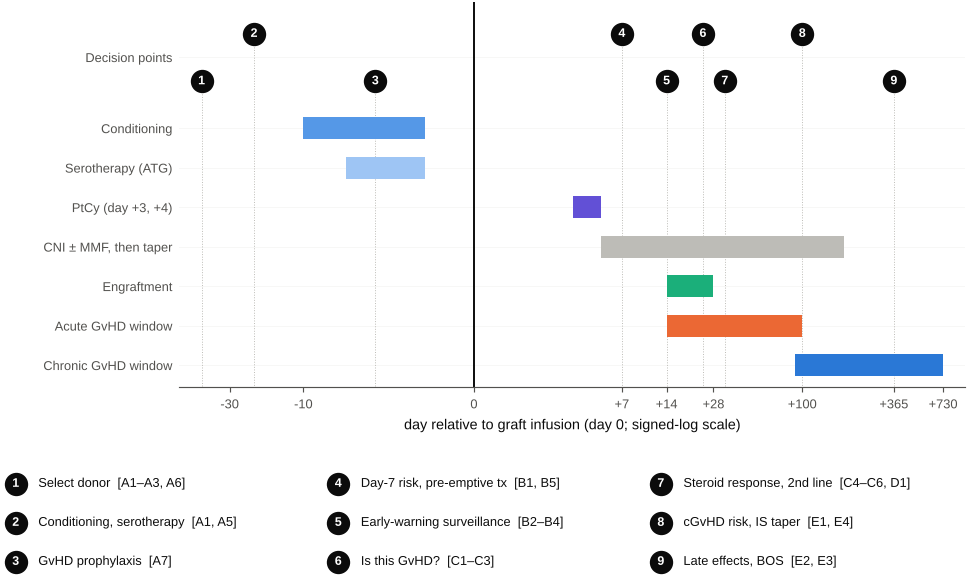

[saved] figures/Fig01_decision_timeline.pdf  +  figures/Fig01_decision_timeline.png


In [4]:
# ----------------------------------------------------------------------------- Figure 1: the allo-HCT timeline, its risk windows and its decision points
PHASES = [  # (start day, end day, row label, colour)
    (-10, -1,  'Conditioning',           PAL['seq'][1]),
    (-5,  -1,  'Serotherapy (ATG)',      PAL['seq'][0]),
    (3,    5,  'PtCy (day +3, +4)',      PAL['violet']),
    (5,  180,  'CNI ± MMF, then taper',  PAL['grey2']),
    (14,  28,  'Engraftment',            PAL['aqua']),
    (14, 100,  'Acute GvHD window',      PAL['orange']),
    (90, 730,  'Chronic GvHD window',    PAL['blue'])]
DECISIONS = [  # (day, decision, task ids)
    (-45, 'Select donor',               'A1–A3, A6'), (-21, 'Conditioning, serotherapy', 'A1, A5'),
    (-3,  'GvHD prophylaxis',           'A7'),        (7,   'Day-7 risk, pre-emptive tx', 'B1, B5'),
    (14,  'Early-warning surveillance', 'B2–B4'),     (24,  'Is this GvHD?',              'C1–C3'),
    (33,  'Steroid response, 2nd line', 'C4–C6, D1'), (100, 'cGvHD risk, IS taper',      'E1, E4'),
    (365, 'Late effects, BOS',          'E2, E3')]
def sx(d): return np.sign(d) * np.log1p(abs(d))           # signed-log day axis: dense early, compressed late

fig = plt.figure(figsize=(FULL, 4.4))
ax = fig.add_axes([.195, .335, .78, .625]); key = fig.add_axes([.02, .015, .96, .20]); key.axis('off')
for i, (a, b, lab, c) in enumerate(PHASES):
    ax.barh(i, sx(b) - sx(a), left=sx(a), height=.56, color=c, lw=0, zorder=3)
ax.axvline(0, color=PAL['ink'], lw=1.0, zorder=2)
def badge(axx, x, y, n):
    """Numbered marker; the number is meant to sit on the marker, so it is exempt from the overlap gate."""
    axx.plot(x, y, 'o', ms=11, color=PAL['ink'], zorder=4, clip_on=False)
    t = axx.text(x, y, str(n), color='white', fontsize=6.4, fontweight='bold', ha='center', va='center', zorder=5)
    t._ok_overlap = True
LANES = (-1.2, -2.4)                                       # alternate lanes so neighbouring badges never touch
for k, (d, lab, tasks) in enumerate(DECISIONS):
    y = LANES[k % 2]
    ax.plot([sx(d)] * 2, [y, len(PHASES) - .45], color=PAL['grey2'], lw=.5, ls=':', zorder=1)
    badge(ax, sx(d), y, k + 1)
ax.set_yticks([-1.8] + list(range(len(PHASES)))); ax.set_yticklabels(['Decision points'] + [p[2] for p in PHASES])
ax.set_ylim(len(PHASES) - .45, -3.2); ax.set_xlim(sx(-62), sx(1000))
ticks = [-30, -10, 0, 7, 14, 28, 100, 365, 730]
ax.set_xticks([sx(t) for t in ticks]); ax.set_xticklabels([f'{t:+d}' if t else '0' for t in ticks])
ax.tick_params(axis='y', length=0); ax.spines['left'].set_visible(False)
ax.set_axisbelow(True); ax.grid(axis='y', color=PAL['grid'], lw=.4)
ax.set_xlabel('day relative to graft infusion (day 0; signed-log scale)')
key.set_xlim(0, 3); key.set_ylim(0, 3)
for k, (d, lab, tasks) in enumerate(DECISIONS):                # the key: three columns of three
    col, row = k // 3, k % 3; y = 2.45 - row * .95; x = col + .04
    badge(key, x, y, k + 1)
    key.text(x + .07, y, f'{lab}  [{tasks}]', fontsize=6.6, va='center', ha='left')
finish(fig, 1, 'decision_timeline',
       'The allo-HCT timeline. Bars: the protocolised exposures and the risk windows they open. Numbered markers: '
       'the clinical decisions, each of which is a family of GvHD-Bench tasks (task ids in brackets; section 8). '
       'The time axis is signed-log, so the first 100 days, where nearly every decision sits, are legible beside '
       'two years of follow-up. A model standing at any decision may use only data whose results were known then.')

**Why a *clinical* foundation model, and why not the one we tried first.** Foundation models trained on timestamped structured health records have moved the field forward. CLMBR (next-code pretraining, †), MOTOR (time-to-event pretraining on 55 M records and 9 B events; up to 95 % better label efficiency on 19 tasks, ✓), Foresight (†) and Delphi-2M (generative disease trajectories, Nature 2025, †) all treat a patient as a *sequence of events in time*, and they learn a representation that transfers to many downstream risk tasks with few labels. Allo-HCT fits that template better than most areas of medicine, because its timeline is short, dense, protocolised and anchored.

Our earlier attempt took the other route: a *transcriptomic* foundation model, with expression as the backbone and GvHD as the label. Its benchmark is in this repository (`GvHD_FM_benchmark_blueprint.ipynb`, summarised in §10). It produced a clear negative on public data. Frozen Geneformer did not beat normalised genes, a pathway prior did not replicate, and blood T-cell signals did not transfer between studies, although tissue-biopsy signals did. This paper keeps those lessons and changes the architecture. **The clinical timeline is the backbone. Transcriptomes, TCRs, microbiome and pathology become adapters** that add information when it is available and that can be ablated to show whether they help.

**What this paper is.** It is a specification: plausibility, data, objectives and benchmark, with executed sample-size calculus, executed metric code, executed label functions, the pilot ledger, and simulations marked **[SIM]**. **What it is not:** a trained model, or any claim that ALLO-FM improves outcomes.

---
# 2 · The plausibility argument

A foundation model for GvHD is worth building only if **all five** premises below hold. Each premise has the evidence for it, the observation that would refute it, and where in this paper it is tested.

| # | Premise | Evidence for it | What would falsify it | Tested in |
|---|---|---|---|---|
| **P1** | **Predictive signal exists before and early after transplant** | Established risk factors. HLA mismatch (each allele mismatch raises aGvHD risk), mismatched HLA-DPB1 T-cell-epitope groups (non-permissive) and HLA-B leader mismatch†. Female donor → male recipient (H-Y minor antigens)†. PBSC vs BM (more cGvHD)†. Older donor age†. Myeloablative / TBI conditioning†. Prophylaxis: BMT CTN 1703 randomised 431 patients; 1-year GRFS 52.7 % (PtCy/Tac/MMF) vs 34.9 % (Tac/MTX) ✓. Plasma ST2 and REG3α at day 7 (MAGIC algorithm, 1,287 patients ✓) predict NRM. Lower faecal microbiota diversity at engraftment → higher mortality (1,362 patients, 8,767 stool samples, 4 centres ✓) | Clinical + biomarker models at chance in leave-centre-out validation | §8 Family A–B baselines; [SIM] harness |
| **P2** | **The signal is spread across modalities and time**, so no single measurement is enough | Each published predictor reaches moderate discrimination on its own (registry-only ML models for aGvHD typically AUROC ≈ 0.6–0.65†; MAP biomarkers mainly stratify NRM and severe GvHD rather than any GvHD†). The biology involves several steps: conditioning injury → DAMPs/PAMPs → antigen presentation → donor T-cell priming and homing → epithelial target damage → dysbiosis feedback. Each step is measured by a different modality | One modality (e.g. day-7 MAP) captures all the information: adding clinical timeline and biology yields ΔAUROC ≈ 0 | modality-knockout ablation (§8.6) |
| **P3** | **The structure is shared across centres and tasks**, so pretraining can spread its cost over them | EHR foundation models gain the most at low label counts (MOTOR ✓, EHRSHOT ✓). Our pilot: tissue-biopsy GvHD signal transfers across labs and organs (LOSO AUROC ≈ 0.80), while blood T-cell signal does not (≈ 0.59) | Leave-centre-out gains disappear; pretrained ≈ random-weight twin | [SIM] S1 below; §10 pilot |
| **P4** | **Enough data exist** for pretraining (unlabelled or weakly labelled) and for evaluation (labelled) | CIBMTR: data on >470,000 recipients from >500 centres (2017 figure ✓). EBMT registry of similar order†. MSK hospitalome: >10,000 stool samples, >1,000 patients, public ✓. BMT CTN trials with banked samples. Public scRNA atlases of 10⁶–10⁷ immune cells (pilot census) | Labelled n for a given task falls below the Riley minimum (§9) even with consortium data | §4.5 sources; §9 |
| **P5** | **A gain can be detected** with honest statistics | Paired-test power and development-n are computable (§9). Gates are fixed in advance (§8.7) | Required n for ΔAUROC = 0.03 exceeds every accessible cohort | §9 |

**Where the earlier attempt broke.** The transcriptome-first design failed **P3** (blood signal not shared between studies) and **P4** (public labelled n of 17–101 per study, mostly microarrays the model could not read). A clinical-timeline backbone moves the labelled-data problem from GEO (~10² samples per study) to registries (~10⁵ patients), and it treats omics as optional adapters. **That reframing is the main design decision of this paper.**

### 2.1 [SIM] S1: when does pretraining help? Shared structure versus label count
Here we make P3 quantitative. Ten source centres and one new target centre each observe a 600-dimensional feature vector (a stand-in for a timeline or omics profile). It is generated from six latent biological factors through a centre-specific loading matrix, $W_c=\sqrt{\rho}\,W_0+\sqrt{1-\rho}\,U_c$, plus centre-specific nuisance structure that no other centre shares. Here **ρ is the fraction of feature structure shared across centres**. The outcome depends only on the latent factors, in the same way at every centre. We compare four arms:
* **raw**: a ridge classifier on the 600 features, with the penalty chosen by inner 3-fold CV on the training labels (the "normalised genes" baseline);
* **pretrained**: a 16-d representation learned *without labels* on pooled source-centre data (PCA, the simplest self-supervised encoder), with the same ridge head on top;
* **random-weight twin**: a random 16-d projection, matching the control used in the pilot;
* **oracle**: the true latent factors (an upper bound).

The labelled target patients are drawn from a pool of 400, and all arms are scored on the 800 remaining target-centre patients, against the number of labelled target patients *k*.

S1 finished in 88s


k                  25     50     100    200    400
rho arm                                           
0.0 oracle       0.789  0.831  0.848  0.861  0.865
    pretrained   0.591  0.666  0.714  0.750  0.772
    random twin  0.617  0.667  0.710  0.762  0.782
    raw          0.667  0.757  0.792  0.841  0.851
0.5 oracle       0.789  0.831  0.848  0.861  0.865
    pretrained   0.698  0.747  0.787  0.814  0.829
    random twin  0.610  0.657  0.693  0.731  0.756
    raw          0.661  0.762  0.790  0.841  0.852
0.8 oracle       0.789  0.831  0.848  0.861  0.865
    pretrained   0.723  0.783  0.807  0.830  0.844
    random twin  0.595  0.637  0.680  0.716  0.744
    raw          0.654  0.761  0.791  0.841  0.851
1.0 oracle       0.789  0.831  0.848  0.861  0.865
    pretrained   0.712  0.778  0.807  0.831  0.845
    random twin  0.577  0.626  0.677  0.710  0.737
    raw          0.648  0.757  0.788  0.839  0.849

[layout PASS] Fig 2: 57 text items, 0 collisions, 0 below 6 pt (smallest 6.5 pt)


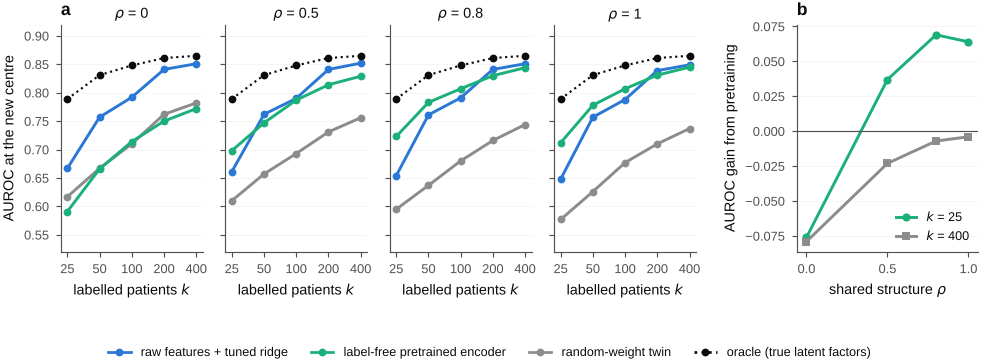

[saved] figures/Fig02_pretraining_vs_shared_structure.pdf  +  figures/Fig02_pretraining_vs_shared_structure.png


In [5]:
# ----------------------------------------------------------------------------- [SIM] S1: value of label-free pretraining as a function of cross-centre shared structure (rho) and label count k
def s1_world(rho, n_src_total=4000, n_centres=10, p=600, k_lat=6, sig=.45, seed=0):
    """Ten source centres and one new target centre. Six latent biological factors drive the outcome identically
    everywhere; each centre maps them to features through W_c = sqrt(rho)*W0 + sqrt(1-rho)*U_c, so `rho` is the
    fraction of feature structure shared across centres. Each centre also has its own nuisance structure, and
    p (600) >> the number of labels we will allow, which is the regime a foundation model is meant to help in."""
    r = np.random.default_rng(seed)
    W0 = r.standard_normal((k_lat, p)); beta = r.standard_normal(k_lat); beta *= 2.0 / np.linalg.norm(beta)
    def centre(n, rr):
        U = rr.standard_normal((k_lat, p)); W = math.sqrt(rho) * W0 + math.sqrt(1 - rho) * U
        z = rr.standard_normal((n, k_lat))
        nuisance = rr.standard_normal((n, 8)) @ rr.standard_normal((8, p)) * .9     # centre-specific batch structure
        x = z @ W * sig + nuisance + rr.standard_normal((n, p))
        y = (rr.random(n) < 1 / (1 + np.exp(-(z @ beta - .3)))).astype(int)
        return x, y, z
    src = [centre(n_src_total // n_centres, np.random.default_rng(seed * 100 + c)) for c in range(n_centres)]
    return np.vstack([s[0] for s in src]), centre(1200, np.random.default_rng(seed * 100 + 99))

ALPHA_GRID = (30., 300., 3000.)
def head(X, y):
    """Linear ridge head; the penalty is chosen by inner 3-fold CV on the TRAINING labels only (never the test set).
    A closed-form ridge keeps the simulation fast enough to re-run; the conclusions are unchanged with
    ridge-logistic (checked), because at these sample sizes the penalty, not the link, is what matters."""
    mk = lambda a: make_pipeline(StandardScaler(), RidgeClassifier(alpha=a))
    best, best_a = -1.0, ALPHA_GRID[1]
    if min(np.bincount(y, minlength=2)) >= 3:
        for a in ALPHA_GRID:
            oof = np.zeros(len(y))
            for tr, te in StratifiedKFold(3, shuffle=True, random_state=0).split(X, y):
                oof[te] = mk(a).fit(X[tr], y[tr]).decision_function(X[te])
            sc = roc_auc_score(y, oof)
            if sc > best: best, best_a = sc, a
    return mk(best_a).fit(X, y)

def s1_run(rho, ks, seed):
    Xs, (xt, yt, zt) = s1_world(rho, seed=seed)
    enc = PCA(16, random_state=seed).fit(Xs)                                   # label-free "pretraining" on source centres only
    Rp = np.random.default_rng(seed + 7).standard_normal((xt.shape[1], 16))
    test = slice(400, None); out = []
    r = np.random.default_rng(seed + 1)
    for k in ks:
        for d in range(2 if QUICK else 4):
            idx = r.choice(400, k, replace=False)                      # labelled target patients come from the first 400 only
            if len(set(yt[idx])) < 2: continue
            for arm, F in (('raw', xt), ('pretrained', enc.transform(xt)), ('random twin', xt @ Rp), ('oracle', zt)):
                m = head(F[idx], yt[idx]); out.append(dict(rho=rho, k=k, seed=seed, arm=arm, auroc=auroc(yt[test], m.decision_function(F[test]))))
    return out

t0 = time.time()
KS = [25, 50, 100, 200, 400]; RHOS = [0.0, 0.5, 0.8, 1.0]; SEEDS = range(2 if QUICK else 4)
S1 = pd.DataFrame([row for rho in RHOS for s in SEEDS for row in s1_run(rho, KS, s)])
s1 = S1.groupby(['rho', 'arm', 'k']).auroc.mean().unstack('k').round(3)
print(f'S1 finished in {time.time() - t0:.0f}s'); display(s1)
ARMS = [('raw', PAL['blue'], '-', 'raw features + tuned ridge'),
        ('pretrained', PAL['aqua'], '-', 'label-free pretrained encoder'),
        ('random twin', PAL['grey'], '-', 'random-weight twin'),
        ('oracle', PAL['ink'], ':', 'oracle (true latent factors)')]
fig = plt.figure(figsize=(FULL, 2.8))
gl = fig.add_gridspec(1, 4, left=.075, right=.705, bottom=.285, top=.865, wspace=.16)
gr = fig.add_gridspec(1, 1, left=.805, right=.985, bottom=.285, top=.865)
axs = [fig.add_subplot(gl[0, i]) for i in range(4)]
for i, (rho, ax) in enumerate(zip(RHOS, axs)):
    ygrid(ax)
    for arm, c, ls, _ in ARMS:
        ax.plot(KS, s1.loc[(rho, arm)].values, marker='o', ms=3.0, color=c, ls=ls,
                lw=1.5 if arm != 'oracle' else 1.1, zorder=3 if arm == 'pretrained' else 2)
    ax.set_xscale('log'); ax.set_xticks(KS); ax.set_xticklabels(KS); ax.minorticks_off(); ax.set_ylim(.52, .92)
    ax.set_title(f'$\\rho$ = {rho:g}', pad=3); ax.set_xlabel('labelled patients $k$')
    if i: ax.set_yticklabels([])
    else: ax.set_ylabel('AUROC at the new centre')
panel(axs[0], 'a')
ax = fig.add_subplot(gr[0, 0]); ygrid(ax)
for k, c, m in ((25, PAL['aqua'], 'o'), (400, PAL['grey'], 's')):
    ax.plot(RHOS, [s1.loc[(r, 'pretrained'), k] - s1.loc[(r, 'raw'), k] for r in RHOS], marker=m, ms=3.2,
            color=c, lw=1.5, label=f'$k$ = {k}')
ax.axhline(0, color=PAL['ink2'], lw=.6); ax.set_xticks([0, .5, 1]); ax.set_xlim(-.06, 1.06)
ax.set_xlabel('shared structure $\\rho$'); ax.set_ylabel('AUROC gain from pretraining')
ax.legend(loc='lower right'); panel(ax, 'b')
fig.legend([plt.Line2D([], [], color=c, ls=ls, marker='o', ms=3, lw=1.4) for _, c, ls, _ in ARMS],
           [lab for _, _, _, lab in ARMS], ncol=4, loc='lower center', bbox_to_anchor=(.5, -.01),
           handlelength=1.8, columnspacing=1.8)
finish(fig, 2, 'pretraining_vs_shared_structure',
       '[SIM] Label-free pretraining pays in proportion to the structure shared across centres. (a) AUROC at a new '
       'centre against the number of labelled patients there, at four levels of shared structure rho. (b) The same '
       'result as the gain over the tuned raw-feature baseline: positive at few labels and high rho, absent at '
       'rho = 0, and shrinking everywhere as labels accumulate. Simulated data; effect sizes follow from the stated model.')

In [6]:
g = lambda rho, arm, k: s1.loc[(rho, arm), k]
gain_small = {rho: g(rho, 'pretrained', 25) - g(rho, 'raw', 25) for rho in RHOS}
gain_big = {rho: g(rho, 'pretrained', 400) - g(rho, 'raw', 400) for rho in RHOS}
display(Markdown(f"""**Result [SIM].** With fully shared structure (ρ = 1) the pretrained encoder is ahead of the raw-feature baseline by **{gain_small[1.0]:+.3f} AUROC at k = 25** and by {gain_big[1.0]:+.3f} at k = 400, so the advantage shrinks as labels accumulate. This is the label-efficiency pattern reported for EHR foundation models. At ρ = 0.8 the gain is {gain_small[0.8]:+.3f} at k = 25. At ρ = 0.5 it is {gain_small[0.5]:+.3f}. **At ρ = 0 (nothing shared across centres) pretraining is {gain_small[0.0]:+.3f}, no better than the random-weight twin.** That is the pattern the pilot found for blood T cells (§10).

**What this licenses.** Pretraining can only exploit structure that is shared. A GvHD foundation model is therefore plausible only for modalities and centres where ρ is high. ρ can be *measured before any model is built*: decode centre from features, or compare principal subspaces between sites (§8.6, *shared-structure audit*). Structured clinical variables recorded on common registry forms are high-ρ by design. Blood transcriptomes from heterogeneous public studies were low-ρ in our pilot. This is the quantitative reason for making the clinical timeline the backbone."""))

**Result [SIM].** With fully shared structure (ρ = 1) the pretrained encoder is ahead of the raw-feature baseline by **+0.064 AUROC at k = 25** and by -0.004 at k = 400, so the advantage shrinks as labels accumulate. This is the label-efficiency pattern reported for EHR foundation models. At ρ = 0.8 the gain is +0.069 at k = 25. At ρ = 0.5 it is +0.037. **At ρ = 0 (nothing shared across centres) pretraining is -0.076, no better than the random-weight twin.** That is the pattern the pilot found for blood T cells (§10).

**What this licenses.** Pretraining can only exploit structure that is shared. A GvHD foundation model is therefore plausible only for modalities and centres where ρ is high. ρ can be *measured before any model is built*: decode centre from features, or compare principal subspaces between sites (§8.6, *shared-structure audit*). Structured clinical variables recorded on common registry forms are high-ρ by design. Blood transcriptomes from heterogeneous public studies were low-ρ in our pilot. This is the quantitative reason for making the clinical timeline the backbone.

---
# 3 · What a GvHD foundation model can and cannot be expected to predict

This section states the paper's **capability claims** before any model exists, so that they are falsifiable. It does three things: it derives the ceiling on discrimination that any model faces at a given decision point, it places each task against that ceiling, and it answers the specific question of what a **transcriptomic profile taken at diagnosis** can support.

## 3.1 The ceiling is set by how much of the outcome is already determined

Acute GvHD is not a fixed property of a donor–recipient pair. It is the result of a chain of events that unfolds *after* day 0: how much mucosal injury the conditioning caused, whether the gut microbiome collapsed, what the calcineurin-inhibitor exposure actually was, which alloreactive clones expanded, whether an infection intervened. A model standing at day −7 cannot see any of that, because none of it has happened yet.

Formally, let a patient's latent liability be $\eta = s_L + u_L$, where $s_L$ is the part determined *and observable* by landmark $L$ and $u_L$ is everything still to come, with $\mathrm{Var}(\eta)=1$ and the outcome $y=\mathbb 1\{\eta > z_{1-\pi}\}$ for prevalence $\pi$. Write $f_L = \mathrm{Var}(s_L)$: the **fraction of outcome-determining variance available at the landmark**. Then the best achievable AUROC at that landmark is the AUROC of the Bayes-optimal predictor $s_L$, which depends only on $f_L$ (and very weakly on $\pi$). The cell below computes that function, inverts it, and plots it.

This is a modelling identity, not an empirical claim: what is assumed is $f_L$, and those assumptions are labelled. The value of the exercise is that it converts "how good could this get?" into "how much of the causal chain can we observe by then?" — which is a **data question**, and therefore actionable.

[layout PASS] Fig 3: 45 text items, 0 collisions, 0 below 6 pt (smallest 6.4 pt)


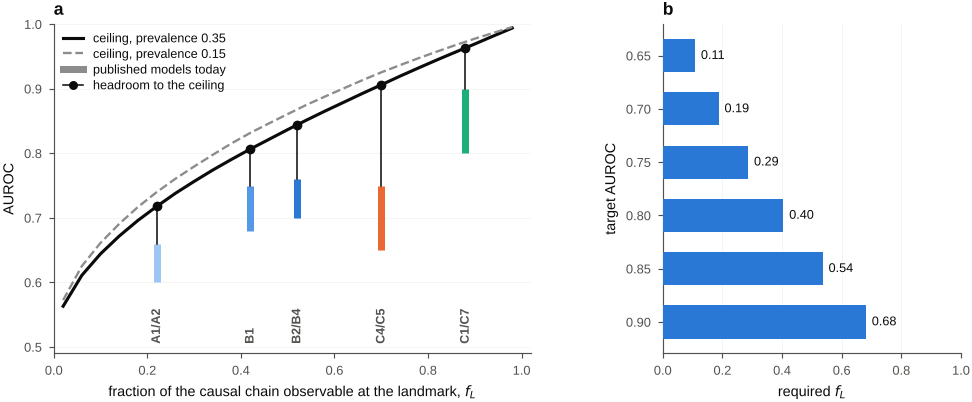

[saved] figures/Fig03_predictability_ceiling.pdf  +  figures/Fig03_predictability_ceiling.png


| target AUROC | fraction of causal chain that must be observable (prevalence 0.35) |
|---|---|
| 0.65 | 0.108 |
| 0.7 | 0.187 |
| 0.75 | 0.286 |
| 0.8 | 0.404 |
| 0.85 | 0.536 |
| 0.9 | 0.681 |

In [7]:
# ----------------------------------------------------------------------------- the discrimination ceiling as a function of information available at the landmark
def ceiling_auroc(f, prev=.35, n=400_000, seed=0):
    """Best achievable AUROC for a binary outcome when only a fraction f of its latent variance is
    determined-and-observable at prediction time (the rest happens afterwards). Bayes-optimal predictor = s."""
    f = float(np.clip(f, 1e-6, 1 - 1e-9)); r = np.random.default_rng(seed)
    s = r.normal(0, math.sqrt(f), n); u = r.normal(0, math.sqrt(1 - f), n)
    y = ((s + u) > norm.ppf(1 - prev)).astype(int)
    return auroc(y, s)

def f_for_auroc(target, prev=.35):
    """Invert the ceiling: what fraction of the causal chain must be observable to reach a target AUROC?"""
    lo, hi = 1e-4, 1 - 1e-4
    for _ in range(40):
        mid = (lo + hi) / 2
        if ceiling_auroc(mid, prev) < target: lo = mid
        else: hi = mid
    return (lo + hi) / 2

FS = np.linspace(.02, .98, 25)
ceil_curve = {pv: np.array([ceiling_auroc(f, pv) for f in FS]) for pv in (.15, .35)}
inv = pd.DataFrame([dict(**{'target AUROC': t, 'fraction of causal chain that must be observable (prevalence 0.35)':
                            round(f_for_auroc(t), 3)}) for t in (.65, .70, .75, .80, .85, .90)])

# Landmarks: assumed share of the causal chain observable at each (ASSUMPTIONS, stated as such), and what
# published models actually achieve there (see the reference list; ranges are approximate).
LAND = [  # id, landmark, assumed f, published-performance range, source note
    ('A1/A2', 'day −7\n(pre-conditioning)',   .22, (.60, .66), 'registry + HLA models'),
    ('B1',    'day +7\n(biomarkers, labs)',   .42, (.68, .75), 'MAGIC MAP + clinical'),
    ('B2/B4', 'day +14\n(+ reconstitution)',  .52, (.70, .76), 'biomarker + clinical'),
    ('C4/C5', 'GvHD onset\n(staging, biopsy)', .70, (.65, .75), 'grade + biomarkers at onset'),
    ('C1/C7', 'onset, diagnosis\n(tissue in hand)', .88, (.80, .90), 'tissue transcriptome / histology')]
fig = plt.figure(figsize=(FULL, 3.2))
gs = fig.add_gridspec(1, 2, width_ratios=[1.6, 1], left=.075, right=.975, bottom=.165, top=.90, wspace=.34)
ax = fig.add_subplot(gs[0, 0]); ygrid(ax)
ax.plot(FS, ceil_curve[.35], color=PAL['ink'], lw=1.6, label='ceiling, prevalence 0.35')
ax.plot(FS, ceil_curve[.15], color=PAL['grey'], lw=1.2, ls='--', label='ceiling, prevalence 0.15')
LC = (PAL['seq'][0], PAL['seq'][1], PAL['seq'][2], PAL['orange'], PAL['aqua'])
for (tid, lab, f, (plo, phi), _), c in zip(LAND, LC):
    cl = ceiling_auroc(f, .35)
    ax.plot([f, f], [plo, phi], color=c, lw=3.6, solid_capstyle='butt', zorder=3)          # what is published today
    ax.plot([f, f], [phi, cl], color=PAL['ink'], lw=.8, zorder=3)                           # the headroom
    ax.plot(f, cl, 'o', color=PAL['ink'], ms=4.0, zorder=4)
    ax.text(f, .505, tid, fontsize=6.4, ha='center', va='bottom', color=PAL['ink2'], fontweight='bold', rotation=90)
ax.set_xlabel('fraction of the causal chain observable at the landmark, $f_L$'); ax.set_ylabel('AUROC')
ax.set_ylim(.49, 1.0); ax.set_xlim(0, 1.02)
hs, ls_ = ax.get_legend_handles_labels()
hs += [plt.Line2D([], [], color=PAL['grey'], lw=3.6), plt.Line2D([], [], color=PAL['ink'], lw=.8, marker='o', ms=3.6)]
ls_ += ['published models today', 'headroom to the ceiling']
ax.legend(hs, ls_, loc='upper left', labelspacing=.3); panel(ax, 'a')
ax = fig.add_subplot(gs[0, 1]); ygrid(ax, 'x')
ax.barh(np.arange(len(inv)), inv.iloc[:, 1], color=PAL['seq'][2], height=.62, zorder=3)
for i, f in enumerate(inv.iloc[:, 1]): ax.text(f + .02, i, f'{f:.2f}', va='center', fontsize=6.5)
ax.set_yticks(np.arange(len(inv))); ax.set_yticklabels([f'{t:.2f}' for t in inv.iloc[:, 0]])
ax.set_ylabel('target AUROC'); ax.set_xlabel('required $f_L$'); ax.set_xlim(0, 1.0); ax.invert_yaxis(); panel(ax, 'b')
finish(fig, 3, 'predictability_ceiling',
       'What is predictable, and when. (a) The best achievable AUROC rises with the fraction of the outcome-determining '
       'causal chain that is observable at prediction time. Coloured bars: the AUROC range of published models at each '
       'landmark; thin line and dot: headroom to the ceiling at the assumed fraction [SIM assumption]. Landmarks: '
       'A1/A2 day -7; B1 day +7; B2/B4 day +14; C4/C5 GvHD onset; C1/C7 diagnosis with tissue in hand. (b) The inverse: the '
       'share of the causal chain a model must observe to reach a given AUROC.')
display(md_table(inv))

In [8]:
c22, c42, c70, c88 = (ceiling_auroc(f, .35) for f in (.22, .42, .70, .88))
display(Markdown(f"""**Result.** With prevalence 0.35, a model that can observe a fraction $f_L$ of the causal chain cannot exceed AUROC **{c22:.2f}** at $f_L$ = 0.22 (our assumption for pre-transplant), **{c42:.2f}** at 0.42 (day +7, with biomarkers), **{c70:.2f}** at 0.70 (at GvHD onset) and **{c88:.2f}** at 0.88 (tissue in hand). Inverting it: AUROC 0.75 needs **{f_for_auroc(.75):.2f}** of the chain observable, 0.80 needs **{f_for_auroc(.80):.2f}**, and 0.90 needs **{f_for_auroc(.90):.2f}**.

**Three consequences for this paper's claims.**
1. **Pre-transplant prediction has a low ceiling, and published models are already close to it.** Registry + HLA models reach roughly 0.60–0.66 against an assumed ceiling near {c22:.2f}. The remaining headroom is of the order of 0.05 AUROC — which is *exactly* the regime where §9 shows you need thousands of patients to demonstrate an improvement. A foundation model should therefore not be sold on pre-transplant discrimination.
2. **The largest headroom is early post-transplant** (day +7 to +14), where multimodal information is accumulating fast but current models use only two proteins and a handful of clinical variables. This is where ALLO-FM's primary task sits (B1), and it is the only place where a gain of 0.05–0.10 AUROC is both physically possible and clinically consequential.
3. **At onset, the ceiling is high and the binding constraint is the measurement, not the model.** Once tissue is in hand the question is nearly determined; this is why the pilot's tissue result (§10) replicated across laboratories while its blood result did not.

*What would falsify the framing:* a pre-transplant model that reproducibly exceeds AUROC ≈ 0.72 out-of-centre would show that $f_{-7}$ is much larger than assumed here — that pair-level biology determines more of the outcome than the post-transplant chain does. That is a measurable claim, and GvHD-Bench task A1 is where it would be tested."""))

**Result.** With prevalence 0.35, a model that can observe a fraction $f_L$ of the causal chain cannot exceed AUROC **0.72** at $f_L$ = 0.22 (our assumption for pre-transplant), **0.81** at 0.42 (day +7, with biomarkers), **0.91** at 0.70 (at GvHD onset) and **0.96** at 0.88 (tissue in hand). Inverting it: AUROC 0.75 needs **0.29** of the chain observable, 0.80 needs **0.40**, and 0.90 needs **0.68**.

**Three consequences for this paper's claims.**
1. **Pre-transplant prediction has a low ceiling, and published models are already close to it.** Registry + HLA models reach roughly 0.60–0.66 against an assumed ceiling near 0.72. The remaining headroom is of the order of 0.05 AUROC — which is *exactly* the regime where §9 shows you need thousands of patients to demonstrate an improvement. A foundation model should therefore not be sold on pre-transplant discrimination.
2. **The largest headroom is early post-transplant** (day +7 to +14), where multimodal information is accumulating fast but current models use only two proteins and a handful of clinical variables. This is where ALLO-FM's primary task sits (B1), and it is the only place where a gain of 0.05–0.10 AUROC is both physically possible and clinically consequential.
3. **At onset, the ceiling is high and the binding constraint is the measurement, not the model.** Once tissue is in hand the question is nearly determined; this is why the pilot's tissue result (§10) replicated across laboratories while its blood result did not.

*What would falsify the framing:* a pre-transplant model that reproducibly exceeds AUROC ≈ 0.72 out-of-centre would show that $f_-7$ is much larger than assumed here — that pair-level biology determines more of the outcome than the post-transplant chain does. That is a measurable claim, and GvHD-Bench task A1 is where it would be tested.

## 3.2 Capability claims, task by task

The table below is the paper's commitment. For each task family it states what we claim is achievable, the evidence the claim rests on, and what would have to be true for it to fail. **"Achievable"** means the out-of-centre IPCW time-dependent AUROC we expect a well-built multimodal model to reach with the data volumes in §9 — not a target to be reached by trying harder on the same data.

| Task | Claim | Achievable (out-of-centre) | Evidence basis | Status of the claim |
|---|---|---|---|---|
| **A1/A2** grade II–IV / III–IV aGvHD from pre-transplant data | Modest, near-ceiling discrimination; the real value is **calibrated counterfactual comparison between donors and prophylaxis platforms**, not ranking patients | **0.62–0.70** | registry + HLA models ≈ 0.60–0.66 †; adding immunogenetics (DPB1 TCE, B-leader, mHA load) is the plausible increment | *modest claim, high confidence* |
| **A6/A7** donor choice and prophylaxis choice | A calibrated model of the *difference* between options is attainable and is where decision value lies; it must be validated inside randomised arms | not an AUROC claim: **calibration of predicted arm difference** | BMT CTN 1703 gives a randomised anchor (n = 431) ✓ | *decision-useful, needs trial data* |
| **B1/B2** grade II–IV / III–IV aGvHD from day +7 to +14 | **The flagship claim.** A multimodal model beats MAP + clinical covariates by a margin that matters | **0.74–0.80** (vs ≈ 0.70–0.75 today) | MAGIC day-7 MAP validated at n = 1,287 ✓; headroom to the day-7 ceiling ≈ 0.08–0.12 | *falsifiable primary endpoint* |
| **B3** 7-day rolling onset alarm | Useful at fixed alert budgets; reported as alerts per 100 patient-days at fixed sensitivity, never as a bare AUROC | **0.72–0.80** per alarm-day | daily staging inputs plus labs are highly informative short-horizon †; no published equivalent | *plausible, unproven* |
| **B5/C6** non-relapse mortality | Already the strongest validated biomarker use; a model should match and then add | **0.72–0.80** | Ann Arbor and MAGIC algorithms were derived for exactly this ✓ | *high confidence, incremental* |
| **C1/C2** differential diagnosis of post-HCT diarrhoea / rash | Genuinely useful and under-served: separating GvHD from infection, drug effect and engraftment syndrome | **0.78–0.88** | the discriminating information (timing, microbiology, histology, tissue expression) is in hand at that moment | *high confidence, high value* |
| **C7** histological severity from the biopsy | A pathology-adapter task with a clear label; pathology foundation models transfer well across stains and sites | **κ 0.6–0.8** vs central read | pathology FM literature †; our pilot's tissue transcriptome analogue reached LOSO 0.80 | *high confidence* |
| **C4/C5** steroid refractoriness / day-28 response | Moderate, and worth it: this is the decision that currently has no model at all | **0.68–0.76** | onset grade + organ pattern + MAP is the baseline; our pilot at n = 45 was uninformative (0.56 [0.37, 0.77]) | *plausible; ~1,000 treated patients to measure it, ~3,400 to develop a model (§8.4)* |
| **D1/D2** second-line agent response and choice | Not claimable from observational data; specify now, validate inside trials | no claim | confounded by indication; REACH-style randomised data needed | *explicitly deferred* |
| **E1** NIH moderate/severe cGvHD by 1 year from day +100 | Moderate; chronic GvHD has a long, partly unobserved causal chain of its own | **0.65–0.72** | prior aGvHD + graft source + donor sex clinical models; day-100 biomarker panels † | *modest claim* |
| **E2** bronchiolitis obliterans | Detection of decline is tractable; prediction of onset is harder | **0.70–0.78** for FEV₁ decline | serial PFT/CT trajectories are strong predictors of their own continuation † | *plausible* |
| **F1** donor-reactive clone identification | A real but small sequence signal; no model class has beaten k-mers | **0.60–0.66** within abundance strata | our pilot: k-mers 0.645, transformer 0.646, ESM2 0.642 on an alloreactivity proxy | *low ceiling, mechanistic value only* |

**What we do not claim, anywhere in this paper.** That a foundation model improves patient outcomes (that needs a trial, §11); that pre-onset blood transcriptomes predict GvHD (the pilot found no signal); that a model can replace histological diagnosis; that any number in §3 has been measured rather than projected.

## 3.3 The specific question: what can a transcriptomic profile **at diagnosis** support?

This deserves its own answer, because it is the modality most often proposed for GvHD and the one our pilot tested hardest. "At diagnosis" means a sample taken when GvHD is first suspected or confirmed — a GI or skin biopsy, or blood drawn at the same visit. The honest answer splits three ways.

**(1) It is well suited to confirming and refuting the diagnosis in tissue.** This is the strongest evidence we have. In the pilot, a plain normalized-gene model transferred across laboratories and across organs (colon → skin) at leave-one-study-out AUROC ≈ 0.80, and a **zero-parameter** score — the mean expression of the Hallmark interferon-γ and allograft-rejection gene sets, written down before any cohort was examined — reached 0.80–0.88 in colon and skin. Nothing was fitted. That is the signature of a signal large relative to between-laboratory variation, which is precisely the condition (high ρ, §2.1) under which a shared model is worth building. The clinically valuable form of this is not "is it GvHD" in isolation but the **differential against its mimics** (CMV colitis, C. difficile, drug effect, conditioning toxicity) — task C1/C2 — because that is the question a clinician actually faces at the bedside, and a transcriptome contains information that histology alone does not.

**(2) It is plausibly useful, but unproven, for stratifying the course once GvHD has started.** Steroid refractoriness (C4) is the decision with the least support today. Our pilot's attempt on the only public labelled set — 45 skin biopsies, 10 non-responders — returned AUROC 0.56 with a 95 % interval of [0.37, 0.77]: an interval that spans "useless" to "clinically useful" and therefore establishes nothing. The cell below computes what it would take to settle it.

**(3) It does not support pre-onset prognosis, and the pilot is the reason.** A profile taken at diagnosis is, by construction, taken after the outcome has begun; using it to "predict" GvHD is a tautology. And when the pilot looked at blood *before* onset in the only large public longitudinal cohort (plasma cfRNA, 92 patients), pre-GvHD samples gave AUROC 0.32 [0.14, 0.48] — below chance — with no reproducible signal at any timepoint, and a forecasting objective that barely beat predicting the population mean. Sorted blood T cells were separable *within* their own study (≈ 0.80) but did not transfer to any other study. Under the §3.1 framing this is unsurprising: at the time blood is drawn, most of the causal chain has not happened.

**Therefore the role of transcriptomics in ALLO-FM is as a high-value, low-coverage adapter**: it enters the model where it is informative (tissue at onset; task C1, C2, C7, and as an input to C4/C5), it is never required at inference, and its contribution is measured by modality knockout (§8.6) rather than assumed.

In [9]:
# ----------------------------------------------------------------------------- what would settle the open transcriptomic questions? (n needed, and what the pilot had)
TX = [  # question, the sample type, what the pilot had, pilot result, assumed prevalence, target AUROC
 ('Confirm GvHD vs no GvHD in tissue', 'GI / skin biopsy', '104 samples, 3 studies', 'LOSO 0.80; zero-parameter score 0.80-0.88', .50, .85),
 ('Differential: GvHD vs infection vs drug', 'GI biopsy + microbiology', 'none (no public adjudicated set)', 'not testable', .45, .85),
 ('Histological severity (grade >= 3)', 'biopsy WSI + RNA', 'none public', 'not testable', .30, .80),
 ('Steroid refractoriness at day 28', 'onset biopsy or blood', '45 samples, 10 non-responders', '0.56 [0.37, 0.77] - uninformative', .25, .72),
 ('NRM at 6 months from onset', 'onset blood', 'none with dates', 'not testable', .30, .75),
 ('Pre-onset prognosis from blood', 'plasma cfRNA / sorted T cells', '92 patients longitudinal', '0.32 [0.14, 0.48] - no signal', .35, .72),
]
tx = pd.DataFrame(TX, columns=['question', 'sample at diagnosis', 'what public data gave the pilot', 'pilot result',
                               'prevalence', 'target AUROC'])
tx['n for ±0.07 CI'] = [n_for_ci(a, p) for a, p in zip(tx['target AUROC'], tx['prevalence'])]
tx['n for ±0.03 CI'] = [n_for_ci(a, p, .03) for a, p in zip(tx['target AUROC'], tx['prevalence'])]
tx['n to show the gain over a 0.65 baseline (paired, 80% power)'] = [n_for_delta(.65, a - .65, p_) for a, p_ in zip(tx['target AUROC'], tx['prevalence'])]
display(md_table(tx))
display(Markdown(f"""**Result.** To *measure* a tissue-diagnosis AUROC of 0.85 to within ±0.07 needs **{n_for_ci(.85, .5)} biopsies**; to within ±0.03, **{n_for_ci(.85, .5, .03):,}**. The pilot had 104. To settle steroid refractoriness at a target of 0.72 to within ±0.07 needs **{n_for_ci(.72, .25)} treated patients** — against the 45 samples and 10 events that were publicly available, which is why that question is open rather than answered. (The last column is the paired-DeLong sample size to show that a model reaching the target AUROC beats a weak 0.65 baseline; against the stronger baselines of §8.5 the gain is smaller and the n correspondingly larger, which §9 computes task by task. §9.4 asks the different question of how many labelled profiles a classifier needs in order to *learn* the signal at all.)

**The actionable reading.** The tissue-diagnosis claim is within reach of a single multi-centre biopsy collection in the low hundreds — the cheapest decisive experiment in this entire programme. The response-prediction claim needs about an order of magnitude more, and only a consortium can supply it."""))

| question | sample at diagnosis | what public data gave the pilot | pilot result | prevalence | target AUROC | n for ±0.07 CI | n for ±0.03 CI | n to show the gain over a 0.65 baseline (paired, 80% power) |
|---|---|---|---|---|---|---|---|---|
| Confirm GvHD vs no GvHD in tissue | GI / skin biopsy | 104 samples, 3 studies | LOSO 0.80; zero-parameter score 0.80-0.88 | 0.5 | 0.85 | 120 | 650 | 23 |
| Differential: GvHD vs infection vs drug | GI biopsy + microbiology | none (no public adjudicated set) | not testable | 0.45 | 0.85 | 130 | 690 | 24 |
| Histological severity (grade >= 3) | biopsy WSI + RNA | none public | not testable | 0.3 | 0.8 | 220 | 1180 | 43 |
| Steroid refractoriness at day 28 | onset biopsy or blood | 45 samples, 10 non-responders | 0.56 [0.37, 0.77] - uninformative | 0.25 | 0.72 | 320 | 1700 | 204 |
| NRM at 6 months from onset | onset blood | none with dates | not testable | 0.3 | 0.75 | 260 | 1380 | 90 |
| Pre-onset prognosis from blood | plasma cfRNA / sorted T cells | 92 patients longitudinal | 0.32 [0.14, 0.48] - no signal | 0.35 | 0.72 | 250 | 1320 | 168 |

**Result.** To *measure* a tissue-diagnosis AUROC of 0.85 to within ±0.07 needs **120 biopsies**; to within ±0.03, **650**. The pilot had 104. To settle steroid refractoriness at a target of 0.72 to within ±0.07 needs **320 treated patients** — against the 45 samples and 10 events that were publicly available, which is why that question is open rather than answered. (The last column is the paired-DeLong sample size to show that a model reaching the target AUROC beats a weak 0.65 baseline; against the stronger baselines of §8.5 the gain is smaller and the n correspondingly larger, which §9 computes task by task. §9.4 asks the different question of how many labelled profiles a classifier needs in order to *learn* the signal at all.)

**The actionable reading.** The tissue-diagnosis claim is within reach of a single multi-centre biopsy collection in the low hundreds — the cheapest decisive experiment in this entire programme. The response-prediction claim needs about an order of magnitude more, and only a consortium can supply it.

---
# 4 · Data specification

This section is the core of the paper. A foundation model is defined by its data far more than by its architecture. Everything below is machine-readable and is exported to `spec/` at the end of the notebook.

## 4.1 Design rules for every datum

1. **One event schema.** Every measurement is stored as one event:
   `(patient_id, pair_id, centre_id, source, t_rel_day, t_valid, t_known, code_system, code, value, unit, specimen_id, assay_batch, provenance)`.
   *Static* facts (HLA typing, donor sex) are events with `t_rel_day` at the time they were determined.
2. **Day-0 anchor.** `t_rel_day` = days from the first graft infusion (fractional days are allowed). For second transplants a new `pair_id` and day 0 are created, and the earlier transplant becomes history.
3. **Two times per event.** `t_valid` is when the biological state existed (biopsy taken, blood drawn). `t_known` is when the result became available to the care team (pathology signed out, assay run). **A model at landmark L may use an event only if `t_known ≤ L`.** This one rule removes most temporal leakage in HCT data. The classic example: a biopsy performed on day +20 whose GvHD-positive report is signed on day +23 may not be used by a day +21 prediction.
4. **Standards first.** LOINC for laboratory tests, RxNorm/ATC for drugs (doses in mg, mg/kg or mg/m² with the weight/BSA used), ICD-10/ICD-O-3 and WHO-HAEM5 / ICC 2022 for disease, SNOMED CT for findings, HLA alleles as WHO-nomenclature GL strings at ≥2-field resolution, HGVS for variants, and CIBMTR form / EBMT MED-A field identifiers kept as provenance. The storage target is the **OMOP CDM** (with the Oncology extension) plus an HCT-specific extension table for the elements OMOP lacks (GvHD organ stages, chimerism, graft cell doses).
5. **Label-proxy flags.** Some inputs are *consequences* of the outcome being predicted (systemic steroids, a GI biopsy order, budesonide, ruxolitinib, extracorporeal photopheresis). Each element carries a `leakage` flag. The benchmark removes flagged elements for any task whose outcome they could reveal (§4.7).
6. **Tiers of availability.** **A** = registry core (collected for essentially all patients on CIBMTR/EBMT forms). **B** = EHR longitudinal (available in any centre's EHR). **C** = biospecimen assays on a protocolised schedule (MAGIC/BMT CTN-like). **D** = deep research phenotyping (single-cell, repertoire, spatial). The model must work with Tier A alone and *improve* as tiers are added; this is tested in G4.

## 4.2 The data dictionary
Twenty-five domains. *Priority*: **R** = required for ALLO-FM v1; **Rec** = recommended; **Opt** = optional or research. *Leakage*: `proxy` = can reveal the outcome; `lag` = has a material t_known − t_valid delay; `post` = only meaningful after the outcome occurs, so it is a label or a post-onset input.

In [10]:
# ----------------------------------------------------------------------------- THE DATA DICTIONARY (machine-readable; exported to spec/data_dictionary.csv)
# columns: domain, element, specification (encoding / units / categories), timing relative to day 0, standard / coding, tier, priority, leakage, used by (task families)
DD = [
# ---------------- D01 Recipient demographics & anthropometrics
('D01 Recipient baseline', 'Age at HCT', 'years (decimal); paediatric flag <18', 'day 0', 'OMOP person + HCT date', 'A', 'R', '', 'all'),
('D01 Recipient baseline', 'Sex (biological) and gender identity', 'female / male (+ intersex/unknown); gender identity separate', 'baseline', 'OMOP gender concept', 'A', 'R', '', 'all; female→male pairing'),
('D01 Recipient baseline', 'Race, ethnicity, genetic ancestry', 'self-report (OMB categories) + genetic ancestry PCs if genotyped', 'baseline', 'OMOP race/ethnicity; PCs from D20', 'A', 'R', '', 'fairness audit (G3); donor availability'),
('D01 Recipient baseline', 'Weight, height, BSA, BMI', 'kg, cm, m² (Mosteller); actual and adjusted weight used for dosing', 'day −10 and daily inpatient', 'LOINC 29463-7, 8302-2', 'A', 'R', '', 'dose normalisation; fluid overload'),
('D01 Recipient baseline', 'Performance status', 'Karnofsky (adults, 10–100) / Lansky (<16 y)', 'pre-HCT work-up', 'LOINC 89243-0 (Karnofsky)', 'A', 'R', '', 'A, NRM'),
('D01 Recipient baseline', 'Socioeconomic and access proxies', 'area deprivation index, insurance type, distance to centre', 'baseline', 'derived (geocode)', 'B', 'Opt', '', 'fairness; NRM'),
# ---------------- D02 Disease & disease status
('D02 Disease', 'Primary diagnosis', 'AML, ALL (B/T), MDS, MDS/MPN, MPN, CML, CLL, NHL subtypes, HL, MM, AA/SAA, PNH, haemoglobinopathy, PID, IEM …', 'pre-HCT', 'WHO-HAEM5 / ICC 2022; ICD-O-3; CIBMTR 2402', 'A', 'R', '', 'all; relapse competing risk'),
('D02 Disease', 'Disease status at HCT', 'CR1/CR2/≥CR3, PIF, relapse, untreated; MDS blast %; lymphoma CR/PR/chemoresistant', 'day −30 to 0', 'CIBMTR 2400', 'A', 'R', '', 'relapse/NRM; GvL trade-off'),
('D02 Disease', 'Refined Disease Risk Index (DRI)', 'low / intermediate / high / very high', 'derived at HCT', 'Armand 2014 refined DRI †', 'A', 'R', '', 'baseline score for A-family'),
('D02 Disease', 'Cytogenetics & molecular risk', 'karyotype (ISCN); ELN 2022 risk; FLT3-ITD/TKD, NPM1, TP53, ASXL1, RUNX1 … (HGVS, VAF)', 'diagnosis and pre-HCT', 'ISCN; HGVS; ELN 2022', 'A', 'R', '', 'relapse; maintenance therapy'),
('D02 Disease', 'Measurable residual disease pre-HCT', 'flow (% of CD45+, LOD) / NGS-MRD (VAF) / qPCR (NPM1, BCR::ABL1 IS %)', 'day −30 to 0', 'LOINC; ELN-MRD', 'A', 'Rec', '', 'relapse; conditioning choice'),
('D02 Disease', 'Prior therapy lines', 'regimens, number of lines, prior auto-HCT/allo-HCT, prior CAR-T, prior checkpoint inhibitor (raises GvHD risk)', 'history', 'RxNorm; CIBMTR 2400', 'A', 'R', '', 'A; GvHD after PD-1 blockade'),
('D02 Disease', 'Time from diagnosis to HCT', 'days', 'derived', '—', 'A', 'R', '', 'A'),
('D02 Disease', 'Post-HCT maintenance', 'sorafenib/gilteritinib, azacitidine, TKI, lenalidomide; start day, dose', 'day +30 onward', 'RxNorm', 'B', 'Rec', '', 'relapse; GvHD (immunomodulatory maintenance)'),
# ---------------- D03 Comorbidity
('D03 Comorbidity', 'HCT-CI (Sorror) components', '17 comorbidities with weights (arrhythmia, cardiac, IBD, diabetes, CVD, psychiatric, hepatic mild/mod-severe, obesity, infection, rheumatologic, peptic ulcer, renal, pulmonary mod/severe, prior solid tumour, valve)', 'pre-HCT work-up', 'Sorror 2005 †; CIBMTR 2400', 'A', 'R', '', 'NRM; A'),
('D03 Comorbidity', 'Pulmonary function pre-HCT', 'FEV1, FVC (% predicted, GLI-2012), DLCO corrected for Hb (% predicted)', 'day −30', 'LOINC 20150-9 etc.', 'A', 'R', '', 'NRM; BOS baseline (E2)'),
('D03 Comorbidity', 'Cardiac function', 'LVEF % (echo / MUGA)', 'day −30', 'LOINC 10230-1', 'A', 'R', '', 'NRM; cyclophosphamide toxicity'),
('D03 Comorbidity', 'Iron overload', 'ferritin µg/L; liver iron concentration (MRI R2*) if done', 'day −30', 'LOINC 2276-4', 'B', 'Rec', '', 'NRM, SOS/VOD, infection'),
('D03 Comorbidity', 'Frailty / geriatric assessment', 'gait speed, grip strength, IADL, CGA domains (≥60 y)', 'pre-HCT', 'LOINC panels', 'D', 'Opt', '', 'NRM in older recipients'),
# ---------------- D04 Infection serology
('D04 Serology & infection', 'CMV serostatus (D/R)', 'R+/R− × D+/D− (IgG)', 'pre-HCT', 'LOINC 22244-8', 'A', 'R', '', 'CMV tasks; GvHD (CMV↔GvHD interplay)'),
('D04 Serology & infection', 'EBV, HSV, VZV, HBV (HBsAg, anti-HBc), HCV, HIV, toxoplasma serology', 'pos/neg; HBV DNA if anti-HBc+', 'pre-HCT', 'LOINC', 'A', 'R', '', 'infection auxiliary tasks'),
('D04 Serology & infection', 'Pre-HCT colonisation', 'VRE, CRE, ESBL rectal swabs; MRSA', 'admission', 'SNOMED organism + LOINC culture', 'B', 'Rec', '', 'microbiome; antibiotic exposure; NRM'),
('D04 Serology & infection', 'Active / recent infection at HCT', 'invasive fungal disease (EORTC/MSG category), bacteraemia within 30 d', 'day −30 to 0', 'EORTC/MSG; ICD-10', 'A', 'R', '', 'NRM'),
# ---------------- D05 Donor
('D05 Donor', 'Donor type', 'MSD, syngeneic, MUD 8/8, MMUD 7/8, haploidentical related, mismatched related, UCB (single/double)', 'donor selection', 'CIBMTR 2400; EBMT MED-A', 'A', 'R', '', 'all A-family; donor ranking (A6)'),
('D05 Donor', 'Donor age, sex, relationship', 'years; sex; sibling/parent/child/other', 'donor selection', '—', 'A', 'R', '', 'aGvHD/cGvHD (older donor, female→male)'),
('D05 Donor', 'Donor parity / prior pregnancies; transfusions', 'number of pregnancies (allo-immunisation, H-Y)', 'donor work-up', 'NMDP donor form', 'A', 'Rec', '', 'cGvHD; female donor effect'),
('D05 Donor', 'Donor CMV/EBV serostatus, ABO/Rh', 'IgG pos/neg; ABO major/minor/bidirectional mismatch with recipient', 'donor work-up', 'LOINC', 'A', 'R', '', 'CMV; PRCA/haemolysis'),
('D05 Donor', 'Donor-specific anti-HLA antibodies in recipient (DSA)', 'single-antigen bead MFI per specificity; C1q; desensitisation given', 'donor selection (haplo/MMUD/UCB)', 'LOINC; HLA nomenclature', 'A', 'R', '', 'graft failure; donor ranking'),
('D05 Donor', 'Donor G-CSF mobilisation / BM harvest details', 'G-CSF dose, apheresis sessions, plerixafor', 'collection', '—', 'B', 'Opt', '', 'graft composition'),
('D05 Donor', 'Donor clonal haematopoiesis (CHIP)', 'DNMT3A/TET2/ASXL1 … variants with VAF ≥ 2 % (error-corrected NGS of donor sample)', 'banked donor sample', 'HGVS', 'C', 'Rec', '', 'cGvHD and relapse associations (Frick 2019 †; Gibson 2022 †)'),
# ---------------- D06 Histocompatibility
('D06 HLA & immunogenetics', 'HLA typing, recipient and donor', 'HLA-A, -B, -C, -DRB1, -DRB3/4/5, -DQA1, -DQB1, -DPA1, -DPB1; ≥2-field (high-resolution) by NGS; GL string', 'donor selection', 'WHO HLA nomenclature; GL string; HML', 'A', 'R', '', 'all; pair encoder input'),
('D06 HLA & immunogenetics', 'Allele vs antigen mismatch, direction', 'per locus: match / allele / antigen mismatch; GvH-vector vs HvG-vector (homozygosity)', 'derived', 'derived from typing', 'A', 'R', '', 'aGvHD (GvH vector) vs graft failure (HvG)'),
('D06 HLA & immunogenetics', 'HLA-DPB1 T-cell-epitope (TCE) group', 'permissive / non-permissive (GvH / HvG)', 'derived', 'TCE3/TCE4 algorithm †', 'A', 'R', '', 'aGvHD, relapse (Fleischhauer 2012 †)'),
('D06 HLA & immunogenetics', 'HLA-B leader (−21 M/T) and HLA-C expression (rs9264942 / 3′UTR)', 'MM/MT/TT; leader matched vs mismatched; HLA-C expression level', 'derived', 'Petersdorf 2015 †, 2020 †', 'A', 'Rec', '', 'aGvHD, especially in haplo/MMUD'),
('D06 HLA & immunogenetics', 'HLA evolutionary divergence (HED) and mismatched-epitope load', 'Grantham-distance HED per locus; PIRCHE-II / HLAMatchmaker eplet counts', 'derived', 'published algorithms †', 'A', 'Opt', '', 'GvL vs GvHD; pair encoder features'),
('D06 HLA & immunogenetics', 'Minor histocompatibility antigens', 'H-Y (female→male); HA-1, HA-2, ACC-1 … disparities from germline genotypes; predicted mHA load (genome-wide)', 'derived (D20)', 'dbMinor / published lists †', 'C', 'Rec', '', 'aGvHD in HLA-matched; GvL'),
('D06 HLA & immunogenetics', 'KIR genotype and KIR-ligand mismatch', 'donor KIR A/B haplotype, B-content score, centromeric/telomeric; KIR-ligand mismatch (missing self)', 'donor work-up', 'IPD-KIR; KIR B-content †', 'C', 'Rec', '', 'relapse (AML), NK alloreactivity'),
('D06 HLA & immunogenetics', 'Non-HLA germline immune variants', 'NOD2/CARD15, IL10, TNF, IL23R, CTLA4 … (candidate); or polygenic score', 'derived (D20)', 'HGVS / rsID', 'D', 'Opt', '', 'exploratory'),
# ---------------- D07 Graft
('D07 Graft', 'Stem cell source', 'PBSC / BM / UCB (single, double); fresh vs cryopreserved', 'day 0', 'CIBMTR 2006 †', 'A', 'R', '', 'cGvHD (PBSC), engraftment'),
('D07 Graft', 'Cell doses infused', 'TNC ×10⁸/kg; CD34⁺ ×10⁶/kg; CD3⁺ ×10⁸/kg (×10⁷/kg UCB); viability %', 'day 0', 'ISCT/ISHAGE CD34 enumeration', 'A', 'R', '', 'engraftment; aGvHD/cGvHD (CD3 dose)'),
('D07 Graft', 'Graft T-cell composition (flow on graft aliquot)', 'CD4, CD8, CD4:CD8, naive (CD45RA⁺CCR7⁺), Tscm (CD45RA⁺CCR7⁺CD95⁺), Tcm, Tem, TEMRA, Treg (CD4⁺CD25^hi CD127^lo FOXP3⁺), γδ, iNKT (Vα24-Jα18), MAIT (Vα7.2⁺CD161^hi), NK (CD56^bright/dim), B, pDC, monocytes; absolute ×10⁶/kg', 'day 0', 'EuroFlow-style panels †; FCS files + gating', 'C', 'Rec', '', 'aGvHD (Treg:Tcon, naive dose), graft encoder'),
('D07 Graft', 'Ex vivo graft manipulation', 'none; CD34 selection; αβ-TCR/CD19 depletion; CD45RA (naive) depletion; Treg/Tcon add-back (e.g. Orca-T); residual αβ T cells/kg', 'day 0', 'free text → controlled list', 'A', 'R', '', 'aGvHD (strong effect modifier)'),
('D07 Graft', 'Graft handling', 'collection-to-infusion hours; cryopreservation; ABO processing (RBC/plasma depletion); DMSO volume', 'day 0', '—', 'B', 'Opt', '', 'engraftment; infusion reactions'),
# ---------------- D08 Conditioning
('D08 Conditioning', 'Regimen (agent-level, not just name)', 'per agent: drug, total dose (busulfan mg/kg and target exposure; cyclophosphamide mg/kg; fludarabine mg/m²; melphalan mg/m²; treosulfan g/m²; thiotepa mg/kg; carmustine/etoposide/cytarabine for BEAM; clofarabine) and the day of each dose', 'day −10 to −1', 'RxNorm + dose + day; CIBMTR 2400', 'A', 'R', '', 'all; conditioning-injury pathway'),
('D08 Conditioning', 'Total body irradiation / TMLI', 'dose (Gy), fractions, dose rate (cGy/min), lung/kidney shielding; TMLI target doses', 'day −7 to −1', 'CIBMTR 2400', 'A', 'R', '', 'aGvHD (GI injury), IPS, NRM'),
('D08 Conditioning', 'Busulfan pharmacokinetics', 'measured cumulative AUC (mg·h/L or µM·min) and target; test-dose PK; dose adjustments', 'day −6 to −2', 'LOINC (busulfan level)', 'B', 'Rec', '', 'SOS/VOD, NRM, relapse (exposure-response †)'),
('D08 Conditioning', 'Intensity classification', 'MAC / RIC / NMA (CIBMTR operational definitions) and EBMT Transplant Conditioning Intensity (TCI) score', 'derived', 'Bacigalupo 2009 †; Spyridonidis 2020 †', 'A', 'R', '', 'A-family baseline'),
('D08 Conditioning', 'Conditioning toxicity', 'mucositis (WHO grade 0–4 daily), SOS/VOD (EBMT 2023 criteria †), engraftment syndrome, CRS after haplo (ASTCT grade)', 'day −7 to +30', 'CTCAE v5; EBMT SOS', 'B', 'R', '', 'GI barrier injury → aGvHD; differential diagnosis (C1)'),
# ---------------- D09 Serotherapy
('D09 Serotherapy', 'Anti-thymocyte globulin', 'product (rabbit thymoglobulin vs ATG-Grafalon/Fresenius — not interchangeable), total mg/kg, days given', 'day −5 to −1', 'RxNorm', 'A', 'R', '', 'aGvHD/cGvHD, immune reconstitution'),
('D09 Serotherapy', 'ATG exposure covariates', 'absolute lymphocyte count before first dose (×10⁹/L); active-ATG levels if measured; modelled post-HCT exposure', 'day −5; day 0 to +30', 'LOINC; Admiraal 2015 PK model †', 'C', 'Rec', '', 'reconstitution, GvHD (exposure-response)'),
('D09 Serotherapy', 'Alemtuzumab', 'total mg, schedule, in vivo vs "in the bag"', 'day −8 to −1', 'RxNorm', 'A', 'R', '', 'aGvHD, viral reactivation'),
# ---------------- D10 Prophylaxis
('D10 GvHD prophylaxis', 'Prophylaxis platform', 'PtCy/Tac/MMF; Tac/MTX; CsA/MTX; Tac/sirolimus; CsA/MMF; ATG-based; abatacept add-on; vedolizumab; ruxolitinib (trial); ex vivo TCD (no pharmacological)', 'day −3 to +180', 'controlled list; CIBMTR 2400', 'A', 'R', '', 'all; treatment-effect tasks (A7)'),
('D10 GvHD prophylaxis', 'Post-transplant cyclophosphamide', 'dose (50 or 25 mg/kg/day), days (+3/+4 standard; alternative schedules), mesna', 'day +3 to +5', 'RxNorm + day', 'A', 'R', '', 'A7; infection; cardiac toxicity'),
('D10 GvHD prophylaxis', 'Methotrexate', 'dose per day (15 mg/m² d+1; 10 mg/m² d+3, +6, +11 or "mini" 5 mg/m²), doses omitted, leucovorin rescue', 'day +1 to +11', 'RxNorm + day', 'A', 'R', '', 'mucositis; engraftment; A7'),
('D10 GvHD prophylaxis', 'Calcineurin inhibitor exposure', 'tacrolimus / cyclosporine daily dose (route) and **every trough level** (ng/mL), target range, time in therapeutic range; CYP3A5 genotype (D20)', 'day −3 to taper end (daily → weekly)', 'LOINC 35152-8 (tacrolimus) †; RxNorm', 'B', 'R', '', 'aGvHD (low exposure), TMA/renal toxicity; PK auxiliary objective'),
('D10 GvHD prophylaxis', 'MMF / sirolimus exposure', 'MMF mg/day (and MPA AUC if measured); sirolimus troughs (ng/mL)', 'day +5 to +35 (MMF); to taper (siro)', 'RxNorm; LOINC', 'B', 'R', '', 'A7; TMA (siro + CNI)'),
('D10 GvHD prophylaxis', 'Immunosuppression taper schedule', 'planned vs actual taper start/end days; reason for early taper (relapse, MRD) or for continuing', 'day +60 to +365', 'derived', 'B', 'R', 'proxy', 'cGvHD (E1); GvL; *taper reason can leak relapse*'),
# ---------------- D11 Supportive care
('D11 Supportive care & antimicrobials', 'Antibacterial exposure', 'agent, start/stop day; flag anaerobe-active broad-spectrum (piperacillin-tazobactam, carbapenems), associated with dysbiosis and GvHD-related mortality †', 'day −10 to +100', 'RxNorm/ATC J01', 'B', 'R', '', 'microbiome pathway; aGvHD'),
('D11 Supportive care & antimicrobials', 'Antiviral / antifungal prophylaxis', 'letermovir (CMV), acyclovir, posaconazole/voriconazole (CNI interaction), TMP-SMX', 'day 0 to +100+', 'RxNorm', 'B', 'R', '', 'CMV task; CNI level variability'),
('D11 Supportive care & antimicrobials', 'Nutrition', 'parenteral nutrition days, enteral feeds, oral intake kcal/day, albumin', 'daily inpatient', 'LOINC; flowsheet', 'B', 'Rec', '', 'GI GvHD; NRM'),
('D11 Supportive care & antimicrobials', 'Growth factors and transfusions', 'G-CSF start day; RBC / platelet units per day', 'daily', 'RxNorm; ISBT 128', 'B', 'Rec', '', 'engraftment definitions'),
('D11 Supportive care & antimicrobials', 'Other GI-active drugs', 'PPIs, laxatives, opioids, magnesium supplements (diarrhoea confounders)', 'daily', 'RxNorm', 'B', 'Rec', '', 'C1 differential diagnosis'),
# ---------------- D12 Labs
('D12 Laboratory timeline', 'Complete blood count with differential', 'WBC, ANC, **ALC**, monocytes, **eosinophils**, Hb, platelets (×10⁹/L)', 'daily inpatient; ≥ weekly to d+100; monthly to 1 y', 'LOINC 751-8 (ANC), 731-0 (ALC), 711-2 (eos) …', 'B', 'R', '', 'engraftment; ALC recovery; eosinophilia in cGvHD'),
('D12 Laboratory timeline', 'Liver panel', 'total and conjugated bilirubin (mg/dL — **MAGIC liver staging input**), ALT, AST, ALP, GGT', 'daily inpatient; ≥ weekly to d+100', 'LOINC 1975-2, 1968-7 …', 'B', 'R', '', 'liver aGvHD staging; SOS/VOD; drug toxicity'),
('D12 Laboratory timeline', 'Renal and electrolytes', 'creatinine (eGFR CKD-EPI 2021), urea, K, Mg (CNI), phosphate', 'daily inpatient', 'LOINC 2160-0 …', 'B', 'R', '', 'CNI toxicity; TMA'),
('D12 Laboratory timeline', 'Inflammation / tissue injury', 'CRP, ferritin, LDH, albumin, triglycerides, IL-6 (if available), procalcitonin', '≥ twice weekly to d+30', 'LOINC', 'B', 'R', '', 'early warning (B3); EASIX (LDH×creatinine/platelets) baseline †'),
('D12 Laboratory timeline', 'TMA markers', 'haptoglobin, schistocytes, LDH, urine protein:creatinine, sC5b-9', 'when triggered', 'LOINC', 'B', 'Rec', 'proxy', 'TA-TMA (GvHD-associated); triggered testing is a proxy'),
('D12 Laboratory timeline', 'Immunoglobulins', 'IgG, IgA, IgM (g/L); IVIG given', 'monthly to 1 y', 'LOINC', 'B', 'Rec', '', 'B-cell reconstitution; cGvHD'),
# ---------------- D13 Staging inputs
('D13 GvHD staging inputs', 'Skin rash body-surface area', '% BSA of maculopapular rash (rule of nines / Lund-Browder), erythroderma, bullae and desquamation % BSA', 'daily inpatient; each outpatient visit', 'MAGIC 2016 ✓ (staging rules); flowsheet', 'B', 'R', 'post', 'skin stage → grade (label construction)'),
('D13 GvHD staging inputs', 'Stool output', 'mL/day (adults); mL/kg/day (paediatric); episodes/day when not measured; bloody stool; abdominal pain / ileus', 'daily inpatient', 'MAGIC 2016 ✓; flowsheet I/O', 'B', 'R', 'post', 'lower-GI stage; C1'),
('D13 GvHD staging inputs', 'Upper GI symptoms', 'persistent nausea, vomiting or anorexia (yes/no, days)', 'daily', 'MAGIC 2016', 'B', 'R', 'post', 'upper-GI stage'),
('D13 GvHD staging inputs', 'Vitals', 'temperature (fever curves), heart rate, BP, SpO₂, daily weight (fluid balance)', 'q4–8h inpatient → daily summary', 'LOINC 8310-5 …', 'B', 'R', '', 'early warning; CRS / engraftment syndrome'),
('D13 GvHD staging inputs', 'Stool infectious work-up', 'C. difficile toxin/PCR, GI multiplex PCR (norovirus, adenovirus …), CMV in tissue', 'when diarrhoea', 'LOINC; SNOMED organism', 'B', 'R', 'proxy', 'C1 (negative work-up enriches for GvHD)'),
('D13 GvHD staging inputs', 'Endoscopy findings', 'site, mucosal appearance (oedema, erythema, ulceration, denudation), biopsy sites', 'at work-up', 'SNOMED; structured report', 'B', 'Rec', 'post', 'C1, C7'),
# ---------------- D14 Engraftment & immune reconstitution
('D14 Engraftment & T-cell reconstitution', 'Neutrophil and platelet engraftment', 'ANC ≥ 0.5×10⁹/L on 3 consecutive days (day of first); platelets ≥ 20×10⁹/L unsupported for 7 days', 'derived', 'CIBMTR definitions', 'A', 'R', '', 'landmark eligibility; graft failure'),
('D14 Engraftment & T-cell reconstitution', 'Lineage-specific donor chimerism', '% donor in CD3⁺ (T) and CD33⁺/CD15⁺ (myeloid) fractions; whole blood; marrow; method (STR, qPCR-indel, NGS) and LOD', 'day +30, +60, +100, +180, +365', 'LOINC; method code', 'A', 'R', '', 'graft failure; relapse; mixed T chimerism ↔ less GvHD'),
('D14 Engraftment & T-cell reconstitution', 'T-cell subset counts (flow)', 'cells/µL: CD3, CD4, CD8, CD4 naive (CD45RA⁺CCR7⁺ / CD31⁺ recent thymic emigrants), Tcm, Tem, TEMRA, Tscm; Treg (CD4⁺CD25^hi CD127^lo, FOXP3⁺) and Treg:Tcon ratio', 'day +14, +30, +60, +100, +180, +365', 'FCS 3.1 + gating ML; harmonised panel', 'C', 'R', '', 'B-family, E-family; reconstitution objective'),
('D14 Engraftment & T-cell reconstitution', 'Activated and homing T cells', 'CD38⁺HLA-DR⁺ CD8; Ki-67⁺; gut-homing α4β7⁺ (± CCR9⁺); skin-homing CLA⁺ CCR4⁺ CCR10⁺; Th1 (CXCR3⁺), Th17 (CCR6⁺ CD161⁺), Th22; circulating Tfh (CXCR5⁺ PD-1⁺)', 'day +7, +14, +21, +28; at onset', 'harmonised flow / CyTOF panel', 'C', 'Rec', '', 'B1–B3 early warning; organ involvement (gut vs skin)'),
('D14 Engraftment & T-cell reconstitution', 'Innate-like and NK/B compartments', 'MAIT, iNKT, Vδ2 γδ T; NK CD56^bright/dim, NKG2A, KIR; B cells: transitional, CD21^lo, plasmablasts; BAFF:B-cell ratio', 'day +30 to +365', 'flow; LOINC (BAFF)', 'C', 'Rec', '', 'cGvHD (B-cell axis), relapse (NK)'),
('D14 Engraftment & T-cell reconstitution', 'Virus-specific T cells', 'CMV/EBV/ADV-specific CD8 (multimer or IFN-γ ELISpot/QuantiFERON-CMV)', 'day +30 to +180', 'LOINC', 'C', 'Opt', '', 'CMV task; alloreactive vs virus-reactive clone annotation'),
# ---------------- D15 Protein biomarkers
('D15 Circulating protein biomarkers', 'MAGIC panel', 'ST2 (sIL1RL1), REG3α (ng/mL) — **MAGIC algorithm probability (MAP)**; TNFR1, IL-2Rα, elafin, HGF, IL-8 (Ann Arbor / earlier panels)', 'day 0, +7, +14, +28; at onset; day +7 after treatment start', 'ELISA, single lab (assay drift!); MAGIC SOP', 'C', 'R', '', 'B1 (MAP baseline), C4/C6; NRM'),
('D15 Circulating protein biomarkers', 'Endothelial / cGvHD markers', 'Ang-2, sTNFR, CXCL9, CXCL10, MMP3, DKK3, OPN, CD163, BAFF, soluble CD13, ST2 at day +100', 'day +100; at cGvHD onset', 'ELISA / Luminex', 'C', 'Rec', '', 'E1 (cGvHD), BIOPREVENT-type baseline †'),
('D15 Circulating protein biomarkers', 'High-plex proteomics', 'Olink Explore (≈3,000) or SomaScan (≈7,000) NPX/RFU; plate and batch IDs', 'day 0, +7, +28, +100', 'UniProt IDs; vendor panels', 'D', 'Opt', 'lag', 'adapter pretraining (masked protein modelling)'),
('D15 Circulating protein biomarkers', 'Pre-analytics', 'tube (EDTA / serum), time to freeze (h), freeze–thaw count, haemolysis index', 'each sample', 'ISBER / BRISQ', 'C', 'R', '', 'confounder-only model (mandatory comparator)'),
# ---------------- D16 Repertoire
('D16 Immune repertoire', 'TCRβ (± TCRα) bulk repertoire', 'productive CDR3 amino-acid + nucleotide, TRBV/TRBJ, template count; ≥ 10⁵ templates per sample; sequencing depth', 'donor graft or pre-donation blood; recipient day +30, +60, +100, at onset; affected tissue', 'AIRR-C standard (MiAIRR) ✓†', 'D', 'Rec', '', 'TCR adapter (O-M2); clonal expansion tasks'),
('D16 Immune repertoire', 'Paired single-cell TCR + transcriptome', '10x 5′ GEX + VDJ (+ CITE-seq ADT); clonotype → cell state', 'day +30, at onset; tissue at biopsy', 'AIRR; CELLxGENE schema', 'D', 'Opt', '', 'O-C2 TCR↔state alignment'),
('D16 Immune repertoire', 'Donor-reactive clone reference', 'pre-transplant MLR: donor T cells × irradiated recipient cells; CFSE-low or CD137⁺ sort; TCR-seq of reactive fraction (sets the alloreactive "dictionary")', 'pre-HCT (donor + recipient samples)', 'AIRR', 'D', 'Opt', '', 'label for clone-level tasks; mechanism'),
('D16 Immune repertoire', 'Repertoire summary metrics', 'clonality (1 − Pielou), Shannon, Simpson, Gini, top-100 clone fraction, richness (Chao1), CMV/EBV-annotated fraction (VDJdb)', 'derived', 'AIRR / VDJdb', 'D', 'Rec', '', 'baseline features for repertoire tasks'),
('D16 Immune repertoire', 'BCR / IGH repertoire', 'IGH CDR3, isotype, SHM rate', 'day +100, at cGvHD onset', 'AIRR', 'D', 'Opt', '', 'cGvHD (B-cell pathology)'),
# ---------------- D17 Transcriptomics
('D17 Transcriptomics', 'Sorted T-cell bulk RNA-seq', 'FACS CD4 Tconv / CD8 / Treg (± MAIT, γδ); raw counts (not FPKM); RIN, sort purity, cell number', 'day +14, +28, at onset', 'GENCODE gene IDs; raw FASTQ in controlled repository', 'D', 'Rec', '', 'T-cell state adapter; pilot tasks (§10)'),
('D17 Transcriptomics', 'PBMC scRNA-seq / CITE-seq', 'UMI counts, ADT counts, cell-hashing; ≥ 5,000 cells per sample; doublet / ambient metrics', 'day +30, at onset; donor graft aliquot', 'CELLxGENE schema', 'D', 'Opt', '', 'cell-level adapter (single-cell FM, fine-tuned)'),
('D17 Transcriptomics', 'Tissue biopsy RNA-seq', 'colon/rectosigmoid, upper GI, skin, liver; fresh-frozen or FFPE (DV200); raw counts', 'at biopsy (t_known = run date)', 'GENCODE', 'C', 'Rec', 'lag', 'C7 tissue diagnosis (pilot: transfers, LOSO ≈ 0.80)'),
('D17 Transcriptomics', 'Spatial transcriptomics', 'Visium HD / Xenium / CosMx on biopsy FFPE: spot or cell × gene; registered to the H&E slide', 'at biopsy', 'vendor + OME-TIFF', 'D', 'Opt', 'lag', 'crypt / epidermal niche mechanisms'),
('D17 Transcriptomics', 'Whole-blood / plasma cfRNA', 'PAXgene whole-blood RNA-seq; plasma cfRNA (log CPM); library-size and batch recorded', 'day 0, +7, +14, +28, monthly', 'GENCODE', 'C', 'Opt', '', 'B-family (pilot: no pre-onset signal at n = 92)'),
('D17 Transcriptomics', 'Assay metadata', 'platform (array vs RNA-seq), library kit, read length, depth, batch, run date', 'each sample', 'MINSEQE', 'C', 'R', '', 'confounder-only comparator; leave-platform-out'),
# ---------------- D18 Microbiome & metabolome
('D18 Microbiome & metabolome', 'Stool microbiome', '16S rRNA V4 (ASVs) and/or shotgun metagenomics (species, strains, ARGs); relative and (qPCR-scaled) absolute abundance', 'day −7 to 0; weekly to +35; at GI onset; +100', 'NCBI taxonomy; MIxS', 'C', 'Rec', '', 'microbiome adapter; aGvHD/NRM (Peled 2020 ✓)'),
('D18 Microbiome & metabolome', 'Derived ecology', 'inverse Simpson diversity at engraftment; domination (single taxon ≥ 30 %); Enterococcus / Enterobacterales domination; butyrate-producer (Lachnospiraceae, Blautia) abundance', 'derived', '—', 'C', 'Rec', '', 'B-family; interpretable baseline'),
('D18 Microbiome & metabolome', 'Microbial metabolites', 'faecal SCFAs (butyrate, propionate, acetate; µmol/g), secondary bile acids, indole-3-carboxaldehyde; urinary 3-indoxyl sulfate', 'day −7, +7, +14, +21', 'LC-MS; HMDB IDs', 'D', 'Opt', 'lag', 'mechanism; metabolite adapter'),
('D18 Microbiome & metabolome', 'Oral / skin microbiome', 'oral rinse 16S; skin swabs', 'weekly to +28', 'MIxS', 'D', 'Opt', '', 'mucositis; oral cGvHD'),
# ---------------- D19 Pathology & imaging
('D19 Pathology & imaging', 'GI / skin / liver biopsy histology', 'whole-slide images (H&E, 40×, SVS/OME-TIFF); structured report: crypt apoptosis count per 10 crypts, crypt loss, Lerner/Sale grade, CMV IHC, eosinophils', 'biopsy (t_valid) → sign-out (t_known)', 'DICOM WSI; SNOMED', 'C', 'Rec', 'lag', 'C1, C7; pathology adapter (UNI / Virchow / CONCH-class FMs †)'),
('D19 Pathology & imaging', 'Immunohistochemistry / multiplex IF', 'CD3, CD8, FOXP3, Ki-67, Paneth-cell lysozyme, REG3α', 'biopsy', 'OME-TIFF', 'D', 'Opt', 'lag', 'tissue mechanism'),
('D19 Pathology & imaging', 'Chest CT and PFT trajectory', 'inspiratory/expiratory CT (air trapping; parametric response mapping, PRM^fSAD %); FEV1, FVC, FEV1/FVC, RV, DLCO serially (home spirometry if available)', 'day −30, +100, +180, +365, then 6-monthly', 'DICOM; LOINC', 'B', 'Rec', '', 'E2 bronchiolitis obliterans (BOS) early detection'),
('D19 Pathology & imaging', 'Clinical photographs', 'standardised skin photographs (rash, sclerosis), oral mucosa', 'at visits', 'DICOM VL photography', 'D', 'Opt', 'post', 'skin cGvHD scoring (adapter)'),
('D19 Pathology & imaging', 'Ophthalmic and oral tests', 'Schirmer test (mm/5 min), OSDI; oral mucosal score', 'day +100, then 6-monthly', 'LOINC', 'B', 'Rec', 'post', 'NIH eye / mouth score (label construction)'),
# ---------------- D20 Genomics
('D20 Germline & somatic genomics', 'Recipient and donor germline genotype', 'SNP array (imputed) or WGS ≥ 30×; used for mHA disparity, HLA imputation QC, ancestry, PGx', 'banked pre-HCT samples (NMDP repository)', 'VCF (GRCh38)', 'D', 'Rec', '', 'D06 mHA load; pair encoder'),
('D20 Germline & somatic genomics', 'Pharmacogenomics', 'CYP3A5 *1/*3 (tacrolimus), CYP2C19 (voriconazole), TPMT/NUDT15, GSTA1 (busulfan)', 'pre-HCT', 'PharmVar star alleles', 'C', 'Rec', '', 'PK auxiliary objective; CNI exposure'),
('D20 Germline & somatic genomics', 'Post-HCT disease genomics', 'NGS-MRD at day +30/+100; HLA loss of heterozygosity at relapse', 'day +30, +100; at relapse', 'HGVS', 'C', 'Rec', 'post', 'relapse competing risk; HLA-loss relapse'),
# ---------------- D21 Text
('D21 Clinical text', 'Notes', 'admission H&P, daily progress notes, transplant-physician GvHD assessments, discharge summaries, consult notes (GI, dermatology)', 'continuous', 'note type (LOINC document ontology)', 'B', 'Rec', 'proxy', 'text adapter (clinical LLM); weak labels; *notes mention suspected GvHD before the formal diagnosis*'),
('D21 Clinical text', 'Pathology and radiology reports', 'free text + structured synoptic fields', 'at sign-out', 'LOINC document ontology', 'B', 'Rec', 'lag', 'label extraction (onset date, biopsy confirmation)'),
# ---------------- D22 PROs
('D22 Patient-reported & function', 'cGvHD symptom burden', 'Lee cGvHD Symptom Scale (30 items, 7 subscales); PROMIS-29; FACT-BMT', 'day +100, then 3-monthly', 'LOINC PRO panels', 'B', 'Rec', 'post', 'cGvHD response (E3) secondary endpoint'),
('D22 Patient-reported & function', 'Wearables', 'step count, resting heart rate, sleep (consumer devices)', 'continuous (opt-in)', 'Open mHealth', 'D', 'Opt', '', 'early warning (exploratory)'),
# ---------------- D23 Outcome labels
('D23 Outcome labels', 'aGvHD organ stages (daily) and overall grade', 'skin 0–4, liver 0–4, upper GI 0–1, lower GI 0–4 → MAGIC grade 0–IV (function in §4.6); onset date = first day of grade ≥ I (and ≥ II)', 'daily d0–d+180 (late aGvHD beyond)', 'MAGIC 2016 ✓', 'A', 'R', 'post', 'labels for A, B, C families'),
('D23 Outcome labels', 'Biopsy confirmation & adjudication', 'biopsy-proven / clinically diagnosed / biopsy-negative; central adjudication flag', 'onset ± 7 d', 'MAGIC; trial CRF', 'B', 'R', 'post', 'C1/C2 diagnostic labels'),
('D23 Outcome labels', 'Treatment response (aGvHD)', 'CR / VGPR / PR / mixed / NR / progression at day +7, +14, +28, +56 from start of systemic steroids', 'from steroid start', 'MAGIC / CIBMTR response criteria', 'A', 'R', 'post', 'C4, C5, D1'),
('D23 Outcome labels', 'Steroid-refractory / -dependent / -intolerant', '2018 EBMT–NIH–CIBMTR definitions (function in §4.6)', 'from steroid start', 'Schoemans 2018 †', 'A', 'R', 'post', 'C4 label; D-family eligibility'),
('D23 Outcome labels', 'cGvHD (NIH 2014)', 'diagnostic/distinctive signs per organ; organ scores 0–3 (skin, mouth, eyes, GI, liver, lungs, joints/fascia, genital); global mild / moderate / severe; onset date; overlap syndrome flag', 'from day +60 onward, each visit', 'Jagasia 2015 (NIH 2014) †', 'A', 'R', 'post', 'E-family labels'),
('D23 Outcome labels', 'cGvHD response (NIH 2014)', 'CR / PR / unchanged / progression (organ-specific + global) at 3, 6, 12 months of therapy', 'from therapy start', 'Lee 2015 NIH response †', 'A', 'R', 'post', 'E3'),
('D23 Outcome labels', 'Relapse / progression', 'date; morphological / molecular / extramedullary; HLA-loss flag', 'continuous', 'CIBMTR 2100/2200 †', 'A', 'R', 'post', 'competing event in every GvHD task'),
('D23 Outcome labels', 'Death and cause of death', 'date; primary cause (GvHD, infection, relapse, organ failure, SOS, TMA …) by CIBMTR hierarchy', 'continuous', 'CIBMTR cause-of-death algorithm', 'A', 'R', 'post', 'NRM, OS, GRFS'),
('D23 Outcome labels', 'Composite endpoints', 'GRFS (grade III–IV aGvHD, cGvHD requiring systemic therapy, relapse, death; Holtan 2015 †); CRFS; NRM; OS; immunosuppression-free survival', 'derived', 'function in §4.6', 'A', 'R', 'post', 'A4, E4'),
('D23 Outcome labels', 'Last follow-up / censoring', 'date of last contact; reason (administrative, lost, transferred)', 'continuous', '—', 'A', 'R', '', 'IPCW censoring model (§8.4)'),
# ---------------- D24 GvHD treatment
('D24 GvHD treatment exposures', 'Systemic corticosteroids', 'agent, mg/kg/day **prednisone-equivalent**, start day, taper; topical / non-absorbable (budesonide, beclomethasone)', 'from first use', 'RxNorm; conversion table', 'B', 'R', 'proxy', '**label proxy for aGvHD onset**: banned as input before onset tasks; defines C-family landmark'),
('D24 GvHD treatment exposures', 'Second-line and later agents', 'ruxolitinib (dose), ECP (sessions), vedolizumab, α1-antitrypsin, etanercept, infliximab, MSC, FMT; cGvHD: belumosudil, ruxolitinib, axatilimab, ibrutinib, sirolimus, imatinib, rituximab', 'from start', 'RxNorm', 'B', 'R', 'proxy', 'D-family exposure; E3; banned before outcome'),
('D24 GvHD treatment exposures', 'Clinical-trial enrolment', 'trial ID (NCT), arm (blinded where applicable)', 'enrolment day', 'ClinicalTrials.gov NCT', 'A', 'R', '', 'randomised anchor for treatment-effect validation (A7)'),
# ---------------- D25 Provenance
('D25 Provenance & operations', 'Centre, country, registry', 'centre ID (pseudonymised), country, CIBMTR/EBMT/JSHCT, centre volume (allo-HCT/year), JACIE/FACT accreditation', 'static', '—', 'A', 'R', '', 'leave-centre-out splits; centre-adversarial objective'),
('D25 Provenance & operations', 'Transplant era', 'calendar year of HCT; era flags: PtCy beyond haplo (≈2019+ †), letermovir (≈2017+), ruxolitinib for SR-aGvHD (2019 FDA)', 'static', '—', 'A', 'R', '', 'temporal split (G1)'),
('D25 Provenance & operations', 'Assay batch & laboratory', 'batch ID, run date, operator, reagent lot, instrument; central vs local lab', 'each sample', '—', 'C', 'R', '', 'batch-only comparator; harmonisation objective'),
('D25 Provenance & operations', 'Missingness indicators', 'per element: observed / not-done / not-applicable / unknown, plus the reason where recorded', 'continuous', '—', 'A', 'R', '', 'missingness is informative; masked-value objective must not be fooled by it'),
('D25 Provenance & operations', 'Consent and data-use terms', 'consent scope (research use, re-identification, international transfer), DUA ID, embargo', 'static', 'GA4GH DUO codes', 'A', 'R', '', 'governance (§11.3)'),
]
DD_COLS = ['domain', 'element', 'specification (encoding / units / categories)', 'timing relative to day 0',
           'standard / coding', 'tier', 'priority', 'leakage', 'used by']
dd = pd.DataFrame(DD, columns=DD_COLS)
dd.to_csv(os.path.join(SPEC_DIR, 'data_dictionary.csv'), index=False)
summary = (dd.assign(n=1).groupby('domain')
             .agg(elements=('n', 'sum'), required=('priority', lambda s: int((s == 'R').sum())),
                  tiers=('tier', lambda s: '/'.join(sorted(set(s)))),
                  leakage_flags=('leakage', lambda s: int((s != '').sum()))))
print(f'{len(dd)} elements in {dd.domain.nunique()} domains | '
      f"required for v1: {(dd.priority == 'R').sum()} | leakage-flagged: {(dd.leakage != '').sum()}")
print(f"tier counts: {dict(dd.tier.value_counts().sort_index())}")
display(summary)

129 elements in 25 domains | required for v1: 74 | leakage-flagged: 30
tier counts: {'A': np.int64(55), 'B': np.int64(36), 'C': np.int64(21), 'D': np.int64(17)}


,elements,required,tiers,leakage_flags
domain,,,,
D01 Recipient baseline,6,5,A/B,0
D02 Disease,8,6,A/B,0
D03 Comorbidity,5,3,A/B/D,0
D04 Serology & infection,4,3,A/B,0
D05 Donor,7,4,A/B/C,0
D06 HLA & immunogenetics,8,3,A/C/D,0
D07 Graft,5,3,A/B/C,0
D08 Conditioning,5,4,A/B,0
D09 Serotherapy,3,2,A/C,0


The full dictionary is rendered below, grouped by domain. It is also written to `spec/data_dictionary.csv` so it can be used as a CRF checklist or as the schema for an extraction pipeline.

In [11]:
# ----------------------------------------------------------------------------- render the dictionary, domain by domain
for dom in dd.domain.unique():
    display(Markdown(f'#### {dom}'))
    display(md_table(dd[dd.domain == dom].drop(columns=['domain']), max_w=240))

#### D01 Recipient baseline

| element | specification (encoding / units / categories) | timing relative to day 0 | standard / coding | tier | priority | leakage | used by |
|---|---|---|---|---|---|---|---|
| Age at HCT | years (decimal); paediatric flag <18 | day 0 | OMOP person + HCT date | A | R |  | all |
| Sex (biological) and gender identity | female / male (+ intersex/unknown); gender identity separate | baseline | OMOP gender concept | A | R |  | all; female→male pairing |
| Race, ethnicity, genetic ancestry | self-report (OMB categories) + genetic ancestry PCs if genotyped | baseline | OMOP race/ethnicity; PCs from D20 | A | R |  | fairness audit (G3); donor availability |
| Weight, height, BSA, BMI | kg, cm, m² (Mosteller); actual and adjusted weight used for dosing | day −10 and daily inpatient | LOINC 29463-7, 8302-2 | A | R |  | dose normalisation; fluid overload |
| Performance status | Karnofsky (adults, 10–100) / Lansky (<16 y) | pre-HCT work-up | LOINC 89243-0 (Karnofsky) | A | R |  | A, NRM |
| Socioeconomic and access proxies | area deprivation index, insurance type, distance to centre | baseline | derived (geocode) | B | Opt |  | fairness; NRM |

#### D02 Disease

| element | specification (encoding / units / categories) | timing relative to day 0 | standard / coding | tier | priority | leakage | used by |
|---|---|---|---|---|---|---|---|
| Primary diagnosis | AML, ALL (B/T), MDS, MDS/MPN, MPN, CML, CLL, NHL subtypes, HL, MM, AA/SAA, PNH, haemoglobinopathy, PID, IEM … | pre-HCT | WHO-HAEM5 / ICC 2022; ICD-O-3; CIBMTR 2402 | A | R |  | all; relapse competing risk |
| Disease status at HCT | CR1/CR2/≥CR3, PIF, relapse, untreated; MDS blast %; lymphoma CR/PR/chemoresistant | day −30 to 0 | CIBMTR 2400 | A | R |  | relapse/NRM; GvL trade-off |
| Refined Disease Risk Index (DRI) | low / intermediate / high / very high | derived at HCT | Armand 2014 refined DRI † | A | R |  | baseline score for A-family |
| Cytogenetics & molecular risk | karyotype (ISCN); ELN 2022 risk; FLT3-ITD/TKD, NPM1, TP53, ASXL1, RUNX1 … (HGVS, VAF) | diagnosis and pre-HCT | ISCN; HGVS; ELN 2022 | A | R |  | relapse; maintenance therapy |
| Measurable residual disease pre-HCT | flow (% of CD45+, LOD) / NGS-MRD (VAF) / qPCR (NPM1, BCR::ABL1 IS %) | day −30 to 0 | LOINC; ELN-MRD | A | Rec |  | relapse; conditioning choice |
| Prior therapy lines | regimens, number of lines, prior auto-HCT/allo-HCT, prior CAR-T, prior checkpoint inhibitor (raises GvHD risk) | history | RxNorm; CIBMTR 2400 | A | R |  | A; GvHD after PD-1 blockade |
| Time from diagnosis to HCT | days | derived | — | A | R |  | A |
| Post-HCT maintenance | sorafenib/gilteritinib, azacitidine, TKI, lenalidomide; start day, dose | day +30 onward | RxNorm | B | Rec |  | relapse; GvHD (immunomodulatory maintenance) |

#### D03 Comorbidity

...

| element | specification (encoding / units / categories) | timing relative to day 0 | standard / coding | tier | priority | leakage | used by |
|---|---|---|---|---|---|---|---|
| aGvHD organ stages (daily) and overall grade | skin 0–4, liver 0–4, upper GI 0–1, lower GI 0–4 → MAGIC grade 0–IV (function in §4.6); onset date = first day of grade ≥ I (and ≥ II) | daily d0–d+180 (late aGvHD beyond) | MAGIC 2016 ✓ | A | R | post | labels for A, B, C families |
| Biopsy confirmation & adjudication | biopsy-proven / clinically diagnosed / biopsy-negative; central adjudication flag | onset ± 7 d | MAGIC; trial CRF | B | R | post | C1/C2 diagnostic labels |
| Treatment response (aGvHD) | CR / VGPR / PR / mixed / NR / progression at day +7, +14, +28, +56 from start of systemic steroids | from steroid start | MAGIC / CIBMTR response criteria | A | R | post | C4, C5, D1 |
| Steroid-refractory / -dependent / -intolerant | 2018 EBMT–NIH–CIBMTR definitions (function in §4.6) | from steroid start | Schoemans 2018 † | A | R | post | C4 label; D-family eligibility |
| cGvHD (NIH 2014) | diagnostic/distinctive signs per organ; organ scores 0–3 (skin, mouth, eyes, GI, liver, lungs, joints/fascia, genital); global mild / moderate / severe; onset date; overlap syndrome flag | from day +60 onward, each visit | Jagasia 2015 (NIH 2014) † | A | R | post | E-family labels |
| cGvHD response (NIH 2014) | CR / PR / unchanged / progression (organ-specific + global) at 3, 6, 12 months of therapy | from therapy start | Lee 2015 NIH response † | A | R | post | E3 |
| Relapse / progression | date; morphological / molecular / extramedullary; HLA-loss flag | continuous | CIBMTR 2100/2200 † | A | R | post | competing event in every GvHD task |
| Death and cause of death | date; primary cause (GvHD, infection, relapse, organ failure, SOS, TMA …) by CIBMTR hierarchy | continuous | CIBMTR cause-of-death algorithm | A | R | post | NRM, OS, GRFS |
| Composite endpoints | GRFS (grade III–IV aGvHD, cGvHD requiring systemic therapy, relapse, death; Holtan 2015 †); CRFS; NRM; OS; immunosuppression-free survival | derived | function in §4.6 | A | R | post | A4, E4 |
| Last follow-up / censoring | date of last contact; reason (administrative, lost, transferred) | continuous | — | A | R |  | IPCW censoring model (§8.4) |

#### D24 GvHD treatment exposures

| element | specification (encoding / units / categories) | timing relative to day 0 | standard / coding | tier | priority | leakage | used by |
|---|---|---|---|---|---|---|---|
| Systemic corticosteroids | agent, mg/kg/day **prednisone-equivalent**, start day, taper; topical / non-absorbable (budesonide, beclomethasone) | from first use | RxNorm; conversion table | B | R | proxy | **label proxy for aGvHD onset**: banned as input before onset tasks; defines C-family landmark |
| Second-line and later agents | ruxolitinib (dose), ECP (sessions), vedolizumab, α1-antitrypsin, etanercept, infliximab, MSC, FMT; cGvHD: belumosudil, ruxolitinib, axatilimab, ibrutinib, sirolimus, imatinib, rituximab | from start | RxNorm | B | R | proxy | D-family exposure; E3; banned before outcome |
| Clinical-trial enrolment | trial ID (NCT), arm (blinded where applicable) | enrolment day | ClinicalTrials.gov NCT | A | R |  | randomised anchor for treatment-effect validation (A7) |

#### D25 Provenance & operations

| element | specification (encoding / units / categories) | timing relative to day 0 | standard / coding | tier | priority | leakage | used by |
|---|---|---|---|---|---|---|---|
| Centre, country, registry | centre ID (pseudonymised), country, CIBMTR/EBMT/JSHCT, centre volume (allo-HCT/year), JACIE/FACT accreditation | static | — | A | R |  | leave-centre-out splits; centre-adversarial objective |
| Transplant era | calendar year of HCT; era flags: PtCy beyond haplo (≈2019+ †), letermovir (≈2017+), ruxolitinib for SR-aGvHD (2019 FDA) | static | — | A | R |  | temporal split (G1) |
| Assay batch & laboratory | batch ID, run date, operator, reagent lot, instrument; central vs local lab | each sample | — | C | R |  | batch-only comparator; harmonisation objective |
| Missingness indicators | per element: observed / not-done / not-applicable / unknown, plus the reason where recorded | continuous | — | A | R |  | missingness is informative; masked-value objective must not be fooled by it |
| Consent and data-use terms | consent scope (research use, re-identification, international transfer), DUA ID, embargo | static | GA4GH DUO codes | A | R |  | governance (§11.3) |

## 4.3 Why these elements and not others — the mechanistic skeleton

The dictionary is not a shopping list. It follows the accepted three-step model of acute GvHD, plus the feedback loops that modern data can actually measure. Each step names the domains that observe it.

| Step | Biology | Domains that measure it |
|---|---|---|
| **0 · Predisposition** | Genetic disparity between donor and recipient: HLA (major), minor antigens, HLA-DP epitopes, B-leader, KIR; plus host factors (age, comorbidity) and GvHD-permissive history (prior checkpoint inhibitor) | D01, D03, D06, D20 |
| **1 · Tissue injury & innate activation** | Conditioning and TBI damage gut epithelium and liver; DAMPs (ATP, uric acid, HMGB1) and PAMPs from a leaky, dysbiotic gut activate antigen-presenting cells; Paneth-cell and goblet-cell loss | D08 (agents, exposures, mucositis), D11 (antibiotics, nutrition), D18 (microbiome, SCFAs), D12 (CRP, albumin), D19 (histology) |
| **2 · Donor T-cell activation & expansion** | Host and donor APCs prime donor T cells; the infused graft's naive-T, Treg and innate-like content and the prophylaxis platform decide whether alloreactive clones expand; PtCy preferentially spares Tregs and depletes proliferating alloreactive cells | D07 (graft composition, manipulation), D09/D10 (serotherapy, PtCy, CNI exposure), D14 (reconstitution, Treg:Tcon), D16 (repertoire clonality), D17 (T-cell transcriptome) |
| **3 · Effector migration & target damage** | Activated T cells acquire homing receptors (α4β7/CCR9 → gut, CLA/CCR4 → skin), traffic to targets, and kill epithelium via cytotoxicity and IFN-γ; crypt apoptosis and Reg3α/ST2 release follow | D14 (homing subsets), D15 (ST2, REG3α, CXCL9), D13 (stool volume, rash BSA), D19 (crypt apoptosis), D17 (tissue transcriptome) |
| **4 · Feedback and chronicity** | Thymic damage impairs tolerance; B-cell dysregulation (BAFF excess), TGF-β-driven fibrosis and Tfh/Th17 skewing drive chronic GvHD; the microbiome never fully recovers | D14 (thymic output, B subsets), D15 (BAFF, CXCL9, endothelial markers), D22 (symptom burden), D19 (PFT/CT) |

**Design consequence.** Steps 0–2 are observable **before onset**, which is what makes prognosis conceivable. Steps 3–4 are largely observable **at or after onset**, which is why those measurements are inputs for diagnosis and response tasks and are *banned* as inputs for pre-onset prognosis (§4.7). The model must be told which step a feature belongs to, because that determines in which tasks it is legal.

## 4.4 Protocolised sampling schedule

Prospective collection matters more than retrospective harmonisation, because a pre-onset landmark can only exist if specimens were taken on a fixed schedule rather than when someone fell ill. Taking samples only "when clinically indicated" creates a sampling-time confound that no analysis can undo. The schedule below is the minimum for ALLO-FM v1; it is deliberately close to MAGIC and BMT CTN biorepository practice so that existing banks qualify.

In [12]:
# ----------------------------------------------------------------------------- the prospective sampling schedule (exported to spec/sampling_schedule.csv)
SCHED_DAYS = ['d-30/pre', 'd0 graft', 'd+7', 'd+14', 'd+21', 'd+28', 'd+60', 'd+100', 'd+180', 'd+365', 'at onset', 'onset+7d', 'at 2nd line']
SCHEDULE = [
 ('Plasma / serum (EDTA + serum, 2×1 mL aliquots)', 'D15', ['X','X','X','X','X','X','X','X','X','X','X','X','X']),
 ('Whole blood PAXgene RNA (2.5 mL)',               'D17', ['X','X','X','X','','X','','X','','','X','X','']),
 ('PBMC viable cryopreserve (≥10×10⁶)',             'D14/D16/D17', ['X','X','','X','','X','X','X','X','X','X','','X']),
 ('Flow immune phenotyping (fresh, harmonised panel)', 'D14', ['X','X','X','X','X','X','X','X','X','X','X','','X']),
 ('Graft aliquot (cells + cryopreserve)',           'D07', ['','X','','','','','','','','','','',''] ),
 ('Stool (−80 °C, no preservative or OMNIgene)',    'D18', ['X','X','X','X','X','X','X','X','','','X','X','']),
 ('Lineage-specific chimerism (CD3 / myeloid)',     'D14', ['','','','','','X','X','X','X','X','','','']),
 ('Sorted T-cell subsets → RNA (CD4 Tconv/CD8/Treg)', 'D17', ['','','','X','','X','','X','','','X','','']),
 ('TCRβ repertoire (bulk)',                         'D16', ['X','X','','','','X','X','X','','X','X','','X']),
 ('Tissue biopsy (GI / skin / liver) + WSI + RNA',  'D17/D19', ['','','','','','','','','','','X','','X']),
 ('Germline DNA (recipient + donor)',               'D20', ['X','','','','','','','','','','','','']),
]
sched = pd.DataFrame([dict(specimen=s, domains=d, **dict(zip(SCHED_DAYS, m))) for s, d, m in SCHEDULE])
sched.to_csv(os.path.join(SPEC_DIR, 'sampling_schedule.csv'), index=False)
n_draws = {c: int((sched[c] == 'X').sum()) for c in SCHED_DAYS}
print('specimen draws per visit:', n_draws)
print(f'total specimen-visit cells = {sum(n_draws.values())}; '
      f"scheduled (non-event-driven) = {sum(v for k, v in n_draws.items() if not k.startswith(('at', 'onset')))}")
display(md_table(sched))

specimen draws per visit: {'d-30/pre': 7, 'd0 graft': 7, 'd+7': 4, 'd+14': 6, 'd+21': 3, 'd+28': 8, 'd+60': 6, 'd+100': 8, 'd+180': 4, 'd+365': 5, 'at onset': 8, 'onset+7d': 3, 'at 2nd line': 5}
total specimen-visit cells = 74; scheduled (non-event-driven) = 58


| specimen | domains | d-30/pre | d0 graft | d+7 | d+14 | d+21 | d+28 | d+60 | d+100 | d+180 | d+365 | at onset | onset+7d | at 2nd line |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Plasma / serum (EDTA + serum, 2×1 mL aliquots) | D15 | X | X | X | X | X | X | X | X | X | X | X | X | X |
| Whole blood PAXgene RNA (2.5 mL) | D17 | X | X | X | X |  | X |  | X |  |  | X | X |  |
| PBMC viable cryopreserve (≥10×10⁶) | D14/D16/D17 | X | X |  | X |  | X | X | X | X | X | X |  | X |
| Flow immune phenotyping (fresh, harmonised panel) | D14 | X | X | X | X | X | X | X | X | X | X | X |  | X |
| Graft aliquot (cells + cryopreserve) | D07 |  | X |  |  |  |  |  |  |  |  |  |  |  |
| Stool (−80 °C, no preservative or OMNIgene) | D18 | X | X | X | X | X | X | X | X |  |  | X | X |  |
| Lineage-specific chimerism (CD3 / myeloid) | D14 |  |  |  |  |  | X | X | X | X | X |  |  |  |
| Sorted T-cell subsets → RNA (CD4 Tconv/CD8/Treg) | D17 |  |  |  | X |  | X |  | X |  |  | X |  |  |
| TCRβ repertoire (bulk) | D16 | X | X |  |  |  | X | X | X |  | X | X |  | X |
| Tissue biopsy (GI / skin / liver) + WSI + RNA | D17/D19 |  |  |  |  |  |  |  |  |  |  | X |  | X |
| Germline DNA (recipient + donor) | D20 | X |  |  |  |  |  |  |  |  |  |  |  |  |

**Non-negotiables of the schedule.** (i) The scheduled visits (`d+7` … `d+365`) must be drawn **whether or not the patient is unwell**, otherwise "sample exists" becomes a predictor of GvHD. (ii) Pre-analytic variables (time to freeze, tube type, freeze–thaw count) are recorded for every aliquot and enter the mandatory confounder-only comparator. (iii) Biomarker assays are run in one laboratory, in batches that are **randomised with respect to outcome and centre**, with bridging samples across batches; batch ID is always available to the audit. (iv) Event-driven samples (at onset, onset+7 days, at second line) are kept for diagnosis and response tasks and may not be used as pre-onset inputs.

## 4.5 Where the data actually are

| Source | What it holds | Scale | Access | Role for ALLO-FM |
|---|---|---|---|---|
| **CIBMTR Research Database** | Registry core on structured forms (TED and comprehensive-report-form subsets): demographics, disease, donor/HLA, graft, conditioning, prophylaxis, aGvHD/cGvHD grades, relapse, death | >470,000 recipients, >500 centres (2017 figure) ✓; 18,000+ collected/derived variables, 148 published-study datasets downloadable ✓ | Controlled; study proposal and DUA; some final datasets are public | **Tier A pretraining corpus and the main evaluation cohort** |
| **EBMT Registry** | Comparable core (MED-A/MED-B), European centres; promotion/validation pipeline | order 10⁵–10⁶ registrations † | Controlled; via study proposal and Working Party (e.g. Transplant Complications WP) | External-registry validation (tests the shared-structure premise P3 across continents) |
| **BMT CTN trials** (e.g. 1703 ✓, 1301, 1203, 0402) | Randomised arms with protocol-fixed prophylaxis, central adjudication, and banked specimens | 1703: 431 patients ✓; others 10²–10³ | BioLINCC / dbGaP controlled | **Treatment-effect validation anchor** (A7); sample-backed Tier C |
| **MAGIC consortium** | Protocolised day-7/day-14 serum biomarkers (ST2, REG3α …) with harmonised aGvHD staging across >20 centres | day-7 algorithm derived and validated in 1,287 patients ✓ | Collaboration | Tier C biomarker adapter; MAP is the baseline to beat in B1 |
| **NMDP/CIBMTR Repository** | Paired pre-HCT recipient and donor biospecimens linked to registry outcomes | order 10⁵ pairs † | Controlled, assay-result return required ✓ | Germline, mHA, KIR, HLA-expression work (D06, D20) |
| **MSK HCT "hospitalome"** | Longitudinal stool microbiota + daily drug exposures + clinical metadata | >10,000 stool samples, >1,000 patients ✓ | **Public** (figshare / Scientific Data 2021) ✓ | Microbiome adapter pretraining; the one large *public* allo-HCT longitudinal resource |
| **Single-centre EHR (OMOP)** | Full Tier B timeline: every lab, drug, vital, note | 10³–10⁴ transplants per large centre | Local IRB | Dense-timeline pretraining; the only place Tier B exists today at scale |
| **GEO / ArrayExpress / CELLxGENE** | Public transcriptomes; immune-cell atlases | GvHD series: 78 human series, 2,954 samples, median series very small (pilot census); atlases 10⁶–10⁷ cells | Public | Omics-adapter pretraining; **not** sufficient for clinical labels (§10) |
| **dbGaP / EGA** | Controlled-access sequencing (including BMT CTN companion studies) | varies | Controlled | Tier C/D |

**The honest summary of supply.** Tier A exists at 10⁵–10⁶ scale but only in registries, behind proposals and DUAs. Tier B exists at 10³–10⁴ per centre and is not pooled anywhere. Tier C exists for 10³–10⁴ patients inside consortium biobanks. Tier D exists for 10¹–10² patients per study. **Therefore ALLO-FM v1 must be a Tier A/B model, with Tier C/D adapters that are optional at inference.** Any design that requires single-cell data for every patient is not trainable in this decade.

## 4.6 Outcome labels as code

A benchmark is only reproducible if its labels are functions, not prose. Below are executable implementations of the three label definitions every GvHD task depends on, with unit tests. The staging-to-grade mapping follows the MAGIC 2016 consensus (✓ for the existence of the criteria; the thresholds below are the standard Glucksberg/MAGIC formulation and should be checked line-by-line against the consensus table before publication †). Deliberately, nothing here looks at a model: these are definitions.

In [13]:
# ----------------------------------------------------------------------------- aGvHD organ staging -> overall grade (MAGIC/Glucksberg formulation)
def stage_skin(bsa_rash_pct, bullae_or_desquamation_pct=0.0):
    """Skin stage 0-4 from % body-surface-area of maculopapular rash; stage 4 = generalised erythroderma with bullae/desquamation."""
    if bullae_or_desquamation_pct and bullae_or_desquamation_pct > 0: return 4
    b = float(bsa_rash_pct)
    return 0 if b < 1 else 1 if b <= 25 else 2 if b <= 50 else 3

def stage_liver(bilirubin_mg_dl):
    """Liver stage 0-4 from total bilirubin (mg/dL). Alternative causes (SOS, drug, sepsis, haemolysis) must be adjudicated separately."""
    b = float(bilirubin_mg_dl)
    return 0 if b < 2 else 1 if b < 3.1 else 2 if b < 6.1 else 3 if b < 15.1 else 4

def stage_upper_gi(persistent_nausea_vomiting_anorexia):
    """Upper-GI stage 0-1 (MAGIC collapses upper GI to present/absent)."""
    return 1 if bool(persistent_nausea_vomiting_anorexia) else 0

def stage_lower_gi(stool_ml_day=None, stool_ml_kg_day=None, severe_pain_or_ileus=False, grossly_bloody=False):
    """Lower-GI stage 0-4 from daily stool volume (adult mL/day, or paediatric mL/kg/day); stage 4 = severe pain/ileus or grossly bloody stool."""
    if severe_pain_or_ileus or grossly_bloody: return 4
    if stool_ml_kg_day is not None:                      # paediatric thresholds
        v = float(stool_ml_kg_day)
        return 0 if v < 10 else 1 if v < 20 else 2 if v < 30 else 3
    v = float(stool_ml_day or 0)                         # adult thresholds
    return 0 if v < 500 else 1 if v < 1000 else 2 if v < 1500 else 3

def magic_grade(skin=0, liver=0, ugi=0, lgi=0):
    """Overall MAGIC/Glucksberg grade 0-IV from organ stages. Returns 0..4 (4 == grade IV).
    IV: skin 4, liver 4 or lower-GI 4.  III: liver 2-3 or lower-GI 2-3.
    II: skin 3, liver 1, upper GI, or lower-GI 1.  I: skin 1-2 only."""
    s, l, u, g = int(skin), int(liver), int(ugi), int(lgi)
    if s == 4 or l == 4 or g == 4: return 4
    if l in (2, 3) or g in (2, 3): return 3
    if s == 3 or l == 1 or u == 1 or g == 1: return 2
    if s in (1, 2): return 1
    return 0

# ---- unit tests against hand-worked vignettes
T = [dict(case='no GvHD', st=dict(skin=0, liver=0, ugi=0, lgi=0), want=0),
     dict(case='rash 20% BSA only', st=dict(skin=stage_skin(20)), want=1),
     dict(case='rash 60% BSA only', st=dict(skin=stage_skin(60)), want=2),
     dict(case='persistent nausea only', st=dict(ugi=stage_upper_gi(True)), want=2),
     dict(case='stool 800 mL/d', st=dict(lgi=stage_lower_gi(stool_ml_day=800)), want=2),
     dict(case='stool 1400 mL/d (lower-GI stage 2)', st=dict(lgi=stage_lower_gi(stool_ml_day=1400)), want=3),
     dict(case='stool 1800 mL/d (lower-GI stage 3)', st=dict(lgi=stage_lower_gi(stool_ml_day=1800)), want=3),
     dict(case='bilirubin 2.5 mg/dL (liver stage 1) only', st=dict(liver=stage_liver(2.5)), want=2),
     dict(case='bilirubin 7 mg/dL', st=dict(liver=stage_liver(7)), want=3),
     dict(case='bilirubin 20 mg/dL', st=dict(liver=stage_liver(20)), want=4),
     dict(case='bloody stool + ileus', st=dict(lgi=stage_lower_gi(stool_ml_day=600, grossly_bloody=True)), want=4),
     dict(case='paediatric 25 mL/kg/d (stage 2)', st=dict(lgi=stage_lower_gi(stool_ml_kg_day=25)), want=3),
     dict(case='paediatric 15 mL/kg/d (stage 1)', st=dict(lgi=stage_lower_gi(stool_ml_kg_day=15)), want=2),
     dict(case='rash 30% + stool 600 mL/d', st=dict(skin=stage_skin(30), lgi=stage_lower_gi(stool_ml_day=600)), want=2)]
rows = []
for t in T:
    got = magic_grade(**t['st']); rows.append(dict(vignette=t['case'], stages=str(t['st']), grade=got, expected=t['want'], ok=got == t['want']))
tt = pd.DataFrame(rows)
assert tt.ok.all(), tt[~tt.ok]
print(f'MAGIC grading: {len(tt)}/{len(tt)} vignettes pass'); display(md_table(tt.drop(columns=['ok'])))

MAGIC grading: 14/14 vignettes pass


| vignette | stages | grade | expected |
|---|---|---|---|
| no GvHD | {'skin': 0, 'liver': 0, 'ugi': 0, 'lgi': 0} | 0 | 0 |
| rash 20% BSA only | {'skin': 1} | 1 | 1 |
| rash 60% BSA only | {'skin': 3} | 2 | 2 |
| persistent nausea only | {'ugi': 1} | 2 | 2 |
| stool 800 mL/d | {'lgi': 1} | 2 | 2 |
| stool 1400 mL/d (lower-GI stage 2) | {'lgi': 2} | 3 | 3 |
| stool 1800 mL/d (lower-GI stage 3) | {'lgi': 3} | 3 | 3 |
| bilirubin 2.5 mg/dL (liver stage 1) only | {'liver': 1} | 2 | 2 |
| bilirubin 7 mg/dL | {'liver': 3} | 3 | 3 |
| bilirubin 20 mg/dL | {'liver': 4} | 4 | 4 |
| bloody stool + ileus | {'lgi': 4} | 4 | 4 |
| paediatric 25 mL/kg/d (stage 2) | {'lgi': 2} | 3 | 3 |
| paediatric 15 mL/kg/d (stage 1) | {'lgi': 1} | 2 | 2 |
| rash 30% + stool 600 mL/d | {'skin': 2, 'lgi': 1} | 2 | 2 |

In [14]:
# ----------------------------------------------------------------------------- steroid-refractory / -dependent / -intolerant aGvHD (2018 EBMT-NIH-CIBMTR formulation)
def sr_agvhd(day_of_steroid, grade_series, pred_eq_mg_kg_series, taper_attempted=False,
             progression_day=None, toxicity_requiring_stop=False):
    """Classify the steroid-response phenotype from the day-by-day course after systemic steroids start.
    grade_series / pred_eq_mg_kg_series: dict {day_from_steroid_start: value}. Returns one of
    'refractory' | 'dependent' | 'intolerant' | 'responsive'."""
    g0 = grade_series.get(0)
    if toxicity_requiring_stop: return 'intolerant'
    if progression_day is not None and progression_day <= 3: return 'refractory'        # progression after >=3 days of >=2 mg/kg
    g3, g7 = grade_series.get(3, g0), grade_series.get(7, g0)
    dose_ok = max([v for d, v in pred_eq_mg_kg_series.items() if d <= 7] or [0]) >= 2.0
    if dose_ok and g3 is not None and g3 > g0: return 'refractory'                      # worse by day 3
    if dose_ok and g7 is not None and g7 >= g0 and g0 >= 1: return 'refractory'         # no improvement by day 7
    if taper_attempted:
        late = [v for d, v in pred_eq_mg_kg_series.items() if d >= 28]
        if late and min(late) >= 0.25 and (grade_series.get(28, 0) or 0) >= 1: return 'dependent'
    return 'responsive'

def grfs_event(day_grade34_agvhd=None, day_cgvhd_systemic=None, day_relapse=None, day_death=None,
               day_last_followup=None):
    """GvHD-free, relapse-free survival (Holtan-style): first of grade III-IV aGvHD, cGvHD needing systemic therapy,
    relapse, or death; else censored at last follow-up. Returns (time_days, event 0/1, cause)."""
    cand = [(d, c) for d, c in ((day_grade34_agvhd, 'aGvHD III-IV'), (day_cgvhd_systemic, 'cGvHD systemic'),
                                (day_relapse, 'relapse'), (day_death, 'death')) if d is not None]
    if not cand: return float(day_last_followup), 0, 'censored'
    t, c = min(cand); return float(t), 1, c

cases = [
 dict(case='grade II -> grade III by d3 on 2 mg/kg', f=lambda: sr_agvhd(0, {0: 2, 3: 3}, {0: 2.0, 3: 2.0}), want='refractory'),
 dict(case='grade III unchanged at d7 on 2 mg/kg',   f=lambda: sr_agvhd(0, {0: 3, 3: 3, 7: 3}, {0: 2.0, 7: 2.0}), want='refractory'),
 dict(case='grade II -> I by d7',                    f=lambda: sr_agvhd(0, {0: 2, 3: 2, 7: 1}, {0: 2.0, 7: 2.0}), want='responsive'),
 dict(case='flare on taper, still 0.3 mg/kg at d28', f=lambda: sr_agvhd(0, {0: 2, 7: 1, 28: 1}, {0: 2.0, 28: 0.3}, taper_attempted=True), want='dependent'),
 dict(case='steroid psychosis -> stop',              f=lambda: sr_agvhd(0, {0: 2}, {0: 2.0}, toxicity_requiring_stop=True), want='intolerant'),
 dict(case='GRFS: relapse d200 before death d400',   f=lambda: grfs_event(day_relapse=200, day_death=400)[2], want='relapse'),
 dict(case='GRFS: alive, no events, f/u d500',       f=lambda: grfs_event(day_last_followup=500)[1], want=0),
 dict(case='GRFS: cGvHD on systemic tx d150',        f=lambda: grfs_event(day_cgvhd_systemic=150, day_last_followup=600)[2], want='cGvHD systemic'),
]
lt = pd.DataFrame([dict(case=c['case'], got=c['f'](), expected=c['want'], ok=c['f']() == c['want']) for c in cases])
assert lt.ok.all(), lt[~lt.ok]
print(f'steroid-response and GRFS label functions: {len(lt)}/{len(lt)} vignettes pass'); display(md_table(lt.drop(columns=['ok'])))

steroid-response and GRFS label functions: 8/8 vignettes pass


| case | got | expected |
|---|---|---|
| grade II -> grade III by d3 on 2 mg/kg | refractory | refractory |
| grade III unchanged at d7 on 2 mg/kg | refractory | refractory |
| grade II -> I by d7 | responsive | responsive |
| flare on taper, still 0.3 mg/kg at d28 | dependent | dependent |
| steroid psychosis -> stop | intolerant | intolerant |
| GRFS: relapse d200 before death d400 | relapse | relapse |
| GRFS: alive, no events, f/u d500 | 0 | 0 |
| GRFS: cGvHD on systemic tx d150 | cGvHD systemic | cGvHD systemic |

**What the label code makes explicit.** Three things that prose definitions usually hide. (1) aGvHD grade is a **daily** quantity, so "grade II–IV aGvHD by day 100" needs a daily series, not a single field; a registry that stores only the maximum grade cannot support a landmark task at day +14. (2) Steroid refractoriness is defined **relative to the steroid start day and the dose actually given**, so the exposure timeline (D24) is part of the label, not an input. (3) Composite endpoints such as GRFS are **first-event** definitions, and the cause matters for competing-risk analysis. Each of these is a place where two centres can silently disagree, which is exactly why the benchmark ships the functions.

## 4.7 Leakage: the four ways an HCT model cheats, and the rule that stops each

| Leak | How it happens | Rule in the specification |
|---|---|---|
| **Treatment-as-feature** | Systemic steroids, budesonide, ruxolitinib or an ECP order are the strongest "predictors" of GvHD, because they are its treatment | Elements flagged `proxy` in D24 (and the steroid-driven parts of D10 taper) are **removed from the input window** of any task whose outcome they could reveal. The removal is implemented in the harness, and the audit re-checks it (§8.5) |
| **Result-availability** | A biopsy taken on day +20 is signed out on day +23, but a naive pipeline attaches it to day +20 | Every event carries `t_known`; the input filter uses `t_known ≤ L`, never `t_valid ≤ L` |
| **Sampling-time** | Research samples are drawn *because* a patient is unwell, so "a sample exists at day +21" predicts GvHD | Scheduled visits are protocolised and drawn regardless of state (§4.4); event-driven samples are labelled and excluded from pre-onset tasks; missingness indicators are inputs so the model cannot be tricked by them silently |
| **Grouping** | The same patient appears as several samples; a donor serves two recipients; a centre's batch aligns with its outcome rate | The unit is the **patient** (and the donor–recipient **pair**); splits are grouped by patient, then by centre; bootstrap resamples patients; donor-sharing is checked |

The harness in §8.8 runs this audit on a cohort that contains a **planted leakage feature**, and reports whether the audit catches it.

---
# 5 · ALLO-FM: architecture

## 5.1 The shape of the model


**Backbone = the timeline, not the omics.** This is the single most important design choice, and it is the one that differs from our first attempt (§10). The sequence model consumes what every transplant patient has (labs, drugs, vitals, stages, registry facts) and treats the deep assays as *extra tokens that may be absent*. A patient with Tier A data only still gets a prediction; a patient with Tier C/D data gets a prediction informed by more tokens. Modality dropout during training (§6.3) is what makes this work rather than collapsing onto whichever modality is most often present.

## 5.2 Tokenisation, in detail

* **Code embedding.** Each element in the dictionary maps to a vocabulary entry (LOINC / RxNorm / SNOMED / the HCT extension). Vocabulary size is of order 10⁴.
* **Value encoding.** Numeric values are encoded two ways at once: a *decile bin within the element's own training distribution* (robust to unit drift between centres), and a standardised scalar passed through a small MLP. Categorical values use their own embedding. A "not done" value is its own token, so informative missingness is representable (D25).
* **Time encoding.** `φ(Δt)` is a random-Fourier / sinusoidal encoding of **time since day 0** and **time since the previous event**, on a signed-log scale so that day +7 and day +8 are far apart while day +400 and day +410 are close. Absolute calendar time is given only as the era flag (D25), never as a raw date, so the model cannot memorise cohorts.
* **Drug exposure.** A drug is not one token: it is a *rate function*. Each administration contributes a token, and the encoder also receives a derived "exposure so far" channel (cumulative mg/kg, trough level, time in therapeutic range). This matters because the GvHD-relevant quantity for a calcineurin inhibitor is exposure, not prescription.
* **Clamp.** Every head receives a landmark L and a mask that zeroes every token with `t_known > L`. The mask is applied inside the attention, and the harness tests it (§8.8).

## 5.3 The pair encoder

Alloreactivity is a property of a **donor–recipient pair**, so the pair gets its own encoder rather than a list of flat features.

* HLA alleles (recipient and donor, 2–4 field) are embedded; the pair representation is built from the *pairing*, with separate channels for GvH-direction and HvG-direction mismatch, plus derived immunogenetics (DPB1 TCE permissiveness, HLA-B leader, HED, eplet/PIRCHE load, KIR B-content, KIR-ligand missing-self).
* With germline genotypes (D20), predicted minor-antigen disparity load enters as a vector.
* The pair encoder is pretrained by a *matching* objective (O-P1, §6.2): given a recipient and a set of candidate donors, score how similar the pairing is, so that the representation groups pairs by disparity structure rather than by centre. This is also the component that makes the donor-ranking task (A6) possible.

## 5.4 What the heads are

The model is not a GvHD classifier. It is a **multi-state model** on the transplant timeline: from the alive-and-GvHD-free state a patient can move to aGvHD (and within it to grade III–IV, steroid-refractory, resolved), to cGvHD, to relapse, or to death. Heads emit discrete-time cause-specific hazards on a grid (daily to day +100, then weekly to day +365), from which every task's quantity is a function: cumulative incidence with competing risks, time-dependent AUROC, calibration, and expected days alive and GvHD-free. One multi-state head rather than many binary heads is also what makes the tasks mutually consistent — a model cannot claim a 40 % chance of grade III–IV aGvHD by day 100 and a 90 % chance of being GvHD-free at day 100.

[layout PASS] Fig 4: 52 text items, 0 collisions, 0 below 6 pt (smallest 6.3 pt)


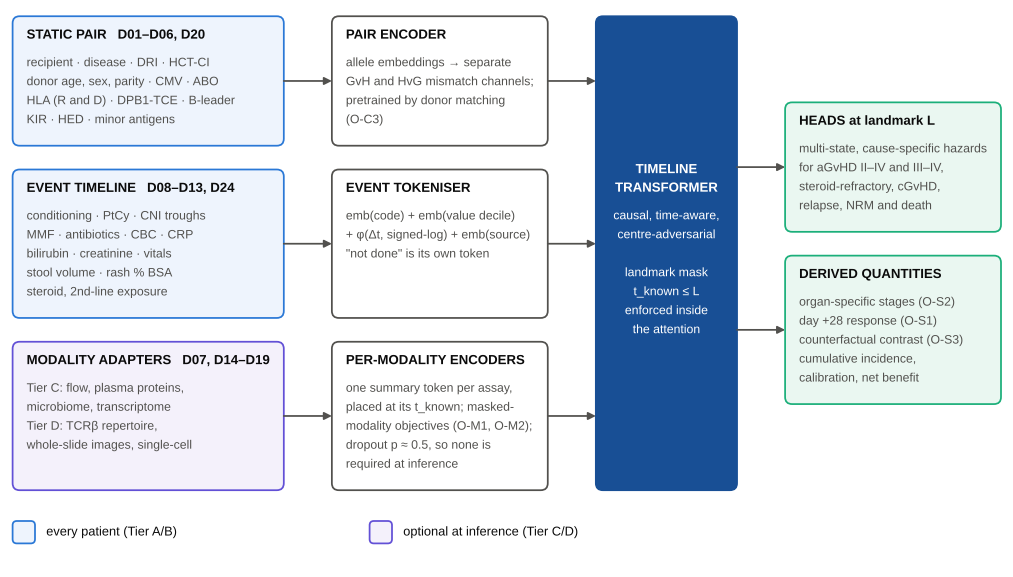

[saved] figures/Fig04_architecture.pdf  +  figures/Fig04_architecture.png


In [15]:
# ----------------------------------------------------------------------------- Figure 4: the ALLO-FM architecture (every box is sized from its own text, so nothing can overflow)
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
FW = FULL
fig = plt.figure(figsize=(FW, 4.0)); ax = fig.add_axes([0, 0, 1, 1]); ax.axis('off')
_rend = fig.canvas.get_renderer()
def _wid(txt, size, weight='normal'):
    t = ax.text(0, 0, txt, fontsize=size, fontweight=weight)
    w = _MplText.get_window_extent(t, _rend).width / fig.dpi; t.remove(); return w
TFS, BFS, PADX, PADY, GAPT = 6.8, 6.3, .10, .09, .07
TPITCH, BPITCH = TFS * 1.40 / 72, BFS * 1.55 / 72            # fixed line pitch: even rhythm whatever the glyphs in a line
ASC_T, ASC_B = TFS * .74 / 72, BFS * .74 / 72
def make_box(title, body, fc, ec, tc=None, bc=None, center=False):
    tl, bl = title.split('\n'), body.split('\n')
    wt = max(_wid(l, TFS, 'bold') for l in tl); wb = max(_wid(l, BFS) for l in bl if l.strip())
    block = len(tl) * TPITCH + GAPT + len(bl) * BPITCH
    return dict(tl=tl, bl=bl, fc=fc, ec=ec, tc=tc or PAL['ink'], bc=bc or PAL['ink2'], center=center,
                w=max(wt, wb) + 2 * PADX, h=block + 2 * PADY, block=block)
BLU, VIO, WHT = '#eef4fd', '#f4f1fb', '#ffffff'
col1 = [make_box('STATIC PAIR   D01–D06, D20',
                 'recipient · disease · DRI · HCT-CI\ndonor age, sex, parity · CMV · ABO\nHLA (R and D) · DPB1-TCE · B-leader\nKIR · HED · minor antigens', BLU, PAL['seq'][2]),
        make_box('EVENT TIMELINE   D08–D13, D24',
                 'conditioning · PtCy · CNI troughs\nMMF · antibiotics · CBC · CRP\nbilirubin · creatinine · vitals\nstool volume · rash % BSA\nsteroid, 2nd-line exposure', BLU, PAL['seq'][2]),
        make_box('MODALITY ADAPTERS   D07, D14–D19',
                 'Tier C: flow, plasma proteins,\nmicrobiome, transcriptome\nTier D: TCRβ repertoire,\nwhole-slide images, single-cell', VIO, PAL['violet'])]
col2 = [make_box('PAIR ENCODER',
                 'allele embeddings → separate\nGvH and HvG mismatch channels;\npretrained by donor matching\n(O-C3)', WHT, PAL['ink2']),
        make_box('EVENT TOKENISER',
                 'emb(code) + emb(value decile)\n+ φ(Δt, signed-log) + emb(source)\n"not done" is its own token', WHT, PAL['ink2']),
        make_box('PER-MODALITY ENCODERS',
                 'one summary token per assay,\nplaced at its t_known; masked-\nmodality objectives (O-M1, O-M2);\ndropout p ≈ 0.5, so none is\nrequired at inference', WHT, PAL['ink2'])]
for r_ in range(3):                                          # rows share a height so the arrows are level
    h = max(col1[r_]['h'], col2[r_]['h']); col1[r_]['h'] = col2[r_]['h'] = h
w1, w2 = max(b['w'] for b in col1), max(b['w'] for b in col2)
for b in col1: b['w'] = w1
for b in col2: b['w'] = w2
VG = .17; H = sum(b['h'] for b in col1) + 2 * VG
bb_ = make_box('TIMELINE\nTRANSFORMER', 'causal, time-aware,\ncentre-adversarial\n\nlandmark mask\nt_known ≤ L\nenforced inside\nthe attention',
               PAL['seq'][3], PAL['seq'][3], tc='white', bc='white', center=True)
bb_['w'] = bb_['w'] + .05; bb_['h'] = H
col4 = [make_box('HEADS at landmark L', 'multi-state, cause-specific hazards\nfor aGvHD II–IV and III–IV,\nsteroid-refractory, cGvHD,\nrelapse, NRM and death', '#eaf7f1', PAL['aqua']),
        make_box('DERIVED QUANTITIES', 'organ-specific stages (O-S2)\nday +28 response (O-S1)\ncounterfactual contrast (O-S3)\ncumulative incidence,\ncalibration, net benefit', '#eaf7f1', PAL['aqua'])]
w4 = max(b['w'] for b in col4)
for b in col4: b['w'] = w4
M, GAP_MIN = .07, .26
FW = max(FULL, 2 * M + w1 + w2 + bb_['w'] + w4 + 3 * GAP_MIN)      # a wider fallback font widens the figure instead of overflowing it
gap = (FW - 2 * M - w1 - w2 - bb_['w'] - w4) / 3
LEG_H = .50; FH = H + LEG_H + .20
fig.set_size_inches(FW, FH); ax.set_xlim(0, FW); ax.set_ylim(0, FH)
x1 = M; x2 = x1 + w1 + gap; x3 = x2 + w2 + gap; x4 = x3 + bb_['w'] + gap; ytop = FH - .10
def draw(b, x, y):                                           # y = top edge
    ax.add_patch(FancyBboxPatch((x, y - b['h']), b['w'], b['h'], boxstyle='round,pad=0,rounding_size=.05',
                                fc=b['fc'], ec=b['ec'], lw=.9))
    y0 = y - (b['h'] - b['block']) / 2 if b['center'] else y - PADY               # centred boxes centre their text block vertically
    xt, ha = (x + b['w'] / 2, 'center') if b['center'] else (x + PADX, 'left')
    for i, l in enumerate(b['tl']):
        ax.text(xt, y0 - ASC_T - i * TPITCH, l, fontsize=TFS, fontweight='bold', va='baseline', ha=ha, color=b['tc'])
    yb = y0 - len(b['tl']) * TPITCH - GAPT
    for k, l in enumerate(b['bl']):
        if l.strip(): ax.text(xt, yb - ASC_B - k * BPITCH, l, fontsize=BFS, va='baseline', ha=ha, color=b['bc'])
def arrow(xa, ya, xb, yb):
    ax.add_patch(FancyArrowPatch((xa, ya), (xb, yb), arrowstyle='-|>', mutation_scale=8, color=PAL['ink2'], lw=.9, shrinkA=0, shrinkB=0))
y = ytop; mids = []
for b1, b2 in zip(col1, col2):
    draw(b1, x1, y); draw(b2, x2, y); mids.append(y - b1['h'] / 2)
    arrow(x1 + w1, mids[-1], x2, mids[-1]); arrow(x2 + w2, mids[-1], x3, mids[-1]); y -= b1['h'] + VG
draw(bb_, x3, ytop)
h4 = sum(b['h'] for b in col4) + VG; y = ytop - (H - h4) / 2
for b in col4:
    draw(b, x4, y); arrow(x3 + bb_['w'], y - b['h'] / 2, x4, y - b['h'] / 2); y -= b['h'] + VG
for xk, fc, ec, lab in ((M, BLU, PAL['seq'][2], 'every patient (Tier A/B)'), (M + 2.55, VIO, PAL['violet'], 'optional at inference (Tier C/D)')):
    ax.add_patch(FancyBboxPatch((xk, .22), .16, .16, boxstyle='round,pad=0,rounding_size=.03', fc=fc, ec=ec, lw=.9))
    ax.text(xk + .24, .30, lab, fontsize=6.6, va='center', ha='left')
finish(fig, 4, 'architecture',
       'ALLO-FM. The backbone is the day-0-anchored clinical event timeline, which every transplant patient has. Biology '
       'enters through modality adapters that each contribute one summary token at the time its result became known; they '
       'are trained with modality dropout and are therefore optional at inference. Every head reads only tokens whose '
       'results were available at its landmark L; the mask is enforced inside the attention and tested in section 8.11.')

[layout PASS] Fig 5: 60 text items, 0 collisions, 0 below 6 pt (smallest 6.4 pt)


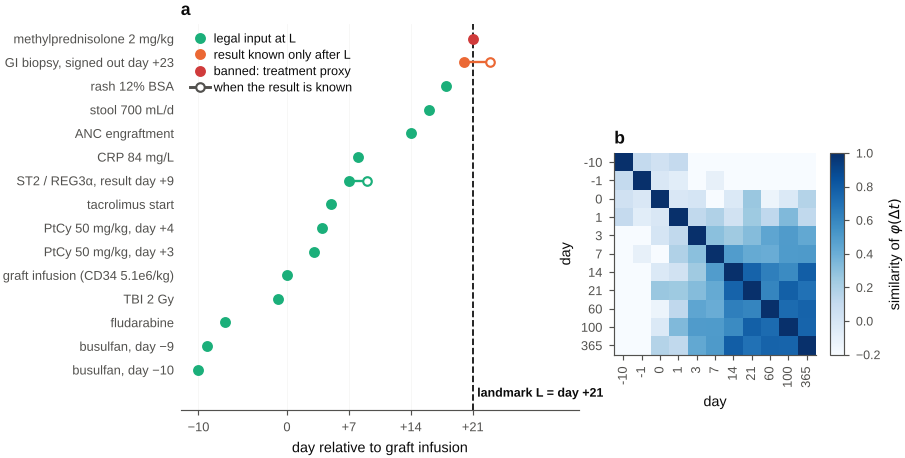

[saved] figures/Fig05_knowledge_time_and_time_encoding.pdf  +  figures/Fig05_knowledge_time_and_time_encoding.png


| event | kind | t_valid | t_known | usable for a day+21 prediction |
|---|---|---|---|---|
| busulfan, day −10 | drug | -10 | -10 | yes |
| busulfan, day −9 | drug | -9 | -9 | yes |
| fludarabine | drug | -7 | -7 | yes |
| TBI 2 Gy | proc | -1 | -1 | yes |
| graft infusion (CD34 5.1e6/kg) | proc | 0 | 0 | yes |
| PtCy 50 mg/kg, day +3 | drug | 3 | 3 | yes |
| PtCy 50 mg/kg, day +4 | drug | 4 | 4 | yes |
| tacrolimus start | drug | 5 | 5 | yes |
| ST2 / REG3α, result day +9 | assay | 7 | 9 | yes |
| CRP 84 mg/L | lab | 8 | 8 | yes |
| ANC engraftment | derived | 14 | 14 | yes |
| stool 700 mL/d | stage | 16 | 16 | yes |
| rash 12% BSA | stage | 18 | 18 | yes |
| GI biopsy, signed out day +23 | assay | 20 | 23 | NO (t_known > L) |
| methylprednisolone 2 mg/kg | drug* | 21 | 21 | NO (treatment proxy) |

In [16]:
# ----------------------------------------------------------------------------- Figure 3: time encoding and the landmark mask, made concrete on one synthetic patient
def phi(dt, k=6):
    """signed-log time features: sin/cos at several scales + the raw signed-log value (what the backbone receives)."""
    s = np.sign(dt) * np.log1p(np.abs(dt))
    return np.concatenate([[s]] + [[np.sin(s * 2 ** j), np.cos(s * 2 ** j)] for j in range(k)])

EV = [(-10, 'busulfan, day −10', 'drug'), (-9, 'busulfan, day −9', 'drug'), (-7, 'fludarabine', 'drug'), (-1, 'TBI 2 Gy', 'proc'),
      (0, 'graft infusion (CD34 5.1e6/kg)', 'proc'), (3, 'PtCy 50 mg/kg, day +3', 'drug'), (4, 'PtCy 50 mg/kg, day +4', 'drug'),
      (5, 'tacrolimus start', 'drug'), (7, 'ST2 / REG3α, result day +9', 'assay'), (8, 'CRP 84 mg/L', 'lab'),
      (14, 'ANC engraftment', 'derived'), (16, 'stool 700 mL/d', 'stage'), (18, 'rash 12% BSA', 'stage'),
      (20, 'GI biopsy, signed out day +23', 'assay'), (21, 'methylprednisolone 2 mg/kg', 'drug*')]
L = 21.0
rows = []
for t, lab, kind in EV:
    tk = t + (2 if 'ST2' in lab else 3 if 'biopsy' in lab else 0)
    rows.append(dict(event=lab, kind=kind, t_valid=t, t_known=tk, visible_at_L=(tk <= L), banned_proxy=kind.endswith('*')))
ev = pd.DataFrame(rows)
ev['usable for a day+21 prediction'] = np.where(ev.banned_proxy, 'NO (treatment proxy)', np.where(ev.visible_at_L, 'yes', 'NO (t_known > L)'))
fig = plt.figure(figsize=(FULL, 3.6))
axa = fig.add_axes([.285, .165, .395, .765]); axb = fig.add_axes([.715, .275, .20, .40])
ax = axa; ax.set_axisbelow(True); ax.grid(axis='x', color=PAL['grid'], lw=.4)
for i, r in ev.iterrows():
    ok = r['usable for a day+21 prediction'] == 'yes'
    c = PAL['aqua'] if ok else (PAL['bad'] if r.banned_proxy else PAL['orange'])
    if r.t_known != r.t_valid:                                       # the lag between "it happened" and "we knew"
        ax.plot([r.t_valid, r.t_known], [i, i], color=c, lw=1.2, zorder=3)
        ax.plot(r.t_known, i, 'o', ms=4.4, mfc='white', mec=c, mew=1.1, zorder=4)
    ax.plot(r.t_valid, i, 'o', color=c, ms=4.6, zorder=5)
ax.set_yticks(range(len(ev))); ax.set_yticklabels(ev.event); ax.tick_params(axis='y', length=0)
ax.axvline(L, color=PAL['ink'], ls='--', lw=.9, zorder=2)
ax.text(L + .5, -1.0, 'landmark L = day +21', fontsize=6.4, ha='left', va='center', fontweight='bold')
ax.set_xticks([-10, 0, 7, 14, 21]); ax.set_xticklabels(['−10', '0', '+7', '+14', '+21'])
ax.set_xlim(-12, 33); ax.set_ylim(-1.7, len(ev) - .4); ax.set_xlabel('day relative to graft infusion'); ax.spines['left'].set_visible(False)
ax.legend([plt.Line2D([], [], color=c, marker='o', ls='none', ms=4.6) for c in (PAL['aqua'], PAL['orange'], PAL['bad'])] +
          [plt.Line2D([], [], color=PAL['ink2'], marker='o', ls='-', ms=4.4, mfc='white', mew=1.1)],
          ['legal input at L', 'result known only after L', 'banned: treatment proxy', 'when the result is known'],
          loc='upper left', labelspacing=.35, handletextpad=.3)
panel(ax, 'a')
TT = np.array([-10, -1, 0, 1, 3, 7, 14, 21, 60, 100, 365])
P = np.array([phi(t) for t in TT]); nrm = np.linalg.norm(P, axis=1); sim = P @ P.T / (nrm[:, None] * nrm[None, :])
im = axb.imshow(sim, cmap='Blues', vmin=-.2, vmax=1)
axb.set_xticks(range(len(TT))); axb.set_xticklabels(TT, rotation=90); axb.set_yticks(range(len(TT))); axb.set_yticklabels(TT)
axb.set_xlabel('day'); axb.set_ylabel('day'); axb.grid(False); panel(axb, 'b')
cax = axb.inset_axes([1.07, 0, .07, 1]); cb = fig.colorbar(im, cax=cax); cb.set_label('similarity of $\\varphi(\\Delta t)$'); cb.ax.tick_params(labelsize=6.4)
finish(fig, 5, 'knowledge_time_and_time_encoding',
       'Knowledge time and time encoding. (a) One patient timeline. Filled marker: when an event happened; open marker: when its '
       'result became known. An event is a legal input at landmark L only if its result was known by then, which is not the same '
       'as having happened by then: the day-20 biopsy signs out on day +23 and is inadmissible, and the day-21 steroid order is '
       'banned outright as a proxy for the outcome. (b) The signed-log time encoding of the model keeps early days distinguishable '
       '(day +7 and +14 are different decisions) and compresses late follow-up.')
display(md_table(ev[['event', 'kind', 't_valid', 't_known', 'usable for a day+21 prediction']]))

In [17]:
n_usable = int((ev['usable for a day+21 prediction'] == 'yes').sum())
display(Markdown(f"""**Result.** Of {len(ev)} events on this patient's timeline, **{n_usable} are legal inputs** for a day +21 prediction. The day-7 biomarker draw is legal (result known day +9), the day-20 biopsy is **not** (signed out day +23, after the landmark), and the day-21 steroid order is banned outright because it is a treatment proxy for the outcome being predicted. A pipeline that filtered on `t_valid ≤ L` alone would have used the biopsy and inflated its own performance. The right panel shows why the signed-log time encoding is the right choice for this disease: day +7 and day +14 must be distinguishable (different biology, different decisions), whereas day +300 and day +365 need not be."""))

**Result.** Of 15 events on this patient's timeline, **13 are legal inputs** for a day +21 prediction. The day-7 biomarker draw is legal (result known day +9), the day-20 biopsy is **not** (signed out day +23, after the landmark), and the day-21 steroid order is banned outright because it is a treatment proxy for the outcome being predicted. A pipeline that filtered on `t_valid ≤ L` alone would have used the biopsy and inflated its own performance. The right panel shows why the signed-log time encoding is the right choice for this disease: day +7 and day +14 must be distinguishable (different biology, different decisions), whereas day +300 and day +365 need not be.

---
# 6 · Training objectives

Three stages: **(1) self-supervised pretraining** on timelines and modalities, **(2) alignment** across modalities and centres, **(3) supervised adaptation** to the multi-state clinical outcome. An objective earns a place only if it passes three filters, taken from the published audits of single-cell foundation models and confirmed by our own pilot: (i) it is computable from data that exist at Tier A/B scale; (ii) its loss is not trivially minimised by a linear model or by a shortcut such as missingness; (iii) it comes with a **matched control** that shows what it adds beyond a dumb twin.

## 6.1 Notation
A patient's record is an event sequence $E=\{e_i\}$ with $e_i=(c_i, v_i, u_i, t_i, \tau_i)$ — code, value, unit, `t_valid`, `t_known` — plus static pair features $s$. Let $E_{\le L}=\{e_i:\tau_i\le L\}$ be the legal history at landmark $L$, and $z_L=f_\theta(E_{\le L}, s)$ the representation. Modality $m$ contributes a summary token $g^{(m)}_\phi(x^{(m)})$.

## 6.2 Objective catalogue

| # | Objective | Loss | Needs | Intrinsic metric vs its control | What it should buy | Failure mode |
|---|---|---|---|---|---|---|
| **O-T1** | **Next-event prediction** (the CLMBR-style backbone objective) | $-\sum_i\log p_\theta(c_{i+1}\mid E_{\le\tau_i})$ | Tier A/B timelines | top-k code accuracy vs a **frequency prior** and a **1-step Markov** model | generic timeline representation | collapses to predicting the daily CBC; fix by down-weighting high-frequency codes |
| **O-T2** | **Time-to-next-event / piecewise-exponential pretraining** (MOTOR-style) | $\sum_{k}\big[\delta_k\log\lambda_\theta^{(k)}(t)-\int\lambda_\theta^{(k)}\big]$ over thousands of code-specific "tasks" | Tier A/B timelines with dates | time-dependent C vs **Kaplan–Meier-only** and **Cox on 20 registry covariates** | the objective closest to the clinical question; best label efficiency | censoring is informative (transfer of care) → include a censoring model |
| **O-T3** | **Masked value modelling** on the timeline | $\mathbb E\sum_{i\in M}\ell(v_i, \hat v_i)$ (Huber for numeric, CE for categorical) | Tier A/B | held-out MSE vs **last-value-carried-forward** and **patient-mean**; must beat LVCF | imputation and a smoother representation | LVCF is very strong for labs; a model that cannot beat it has learned nothing |
| **O-T4** | **Exposure–response (PK/PD) auxiliary** | predict next tacrolimus trough / busulfan AUC from dose, weight, interacting drugs, CYP3A5 | D10, D20 | $R^2$ vs a **population PK model** | makes the model represent drug exposure, not just orders | overfits centre-specific protocols |
| **O-M1** | **Per-modality masked modelling** (flow panel, Olink, 16S, expression) | modality-specific masked reconstruction | Tier C/D | reconstruction vs **PCA-ridge** and **mean predictor** | adapters that are useful before any label | the pilot's warning: a well-fit objective need not transfer |
| **O-M2** | **Repertoire objective** | masked CDR3 / clone-abundance modelling; optional InfoNCE between a clone's sequence and its cell state | D16 | held-out clone retrieval vs **V/J+length** and **k-mer** baselines | donor-reactive clone representation | pilot result: no model class beat k-mers on an alloreactivity proxy |
| **O-C1** | **Cross-modality alignment** | InfoNCE between the timeline representation at $\tau$ and modality tokens measured at $\tau$ | paired samples | retrieval accuracy vs **random pairing**; alignment/uniformity | lets a Tier A patient inherit structure learned from Tier C/D patients | aligns to batch rather than biology if positives are mis-specified |
| **O-C2** | **Centre-adversarial invariance** | $\mathcal L_{\text{task}}-\lambda\,\mathcal L_{\text{centre}}$ (gradient reversal), or an explicit CORAL/MMD penalty | centre IDs | **centre decodability** from $z$ (lower is better) with biology preserved | the premise P3 lever: makes representations transferable | removes real case-mix differences along with batch; needs the two-axis score (§8.4) |
| **O-C3** | **Pair-matching** (donor–recipient) | InfoNCE over (recipient, true donor) vs sampled candidate donors | D06, D20 | matching accuracy vs **mismatch-count-only** | the representation donor ranking (A6) needs | learns registry conventions instead of immunogenetics |
| **O-S1** | **Multi-state supervised head** | cause-specific discrete-time NLL over {aGvHD II-IV, III-IV, SR, cGvHD, relapse, NRM, death}, with competing risks | labelled registry | time-dependent AUROC and calibration vs **clinical baselines** (§8.3) | the deployable model | the label definitions must be the §4.6 functions |
| **O-S2** | **Organ-specific and severity heads** | multi-label hazards for skin / upper GI / lower GI / liver (and cGvHD organ scores) | daily staging (D13, D23) | macro-AUROC vs **overall-grade-only** model | clinically actionable detail (which organ) | staging noise between centres |
| **O-S3** | **Counterfactual / treatment-arm head** | T-learner or DR-learner for prophylaxis platform; validated on randomised arms (BMT CTN 1703) | D10, D24, trial IDs | policy value and calibration-in-the-large **within the randomised subset** | the clinically useful question ("which prophylaxis for this pair?") | confounded in registry data; only randomised anchors can validate it |

## 6.3 Training recipe (and the ablations that must accompany it)

1. **Stage 1 — timeline pretraining.** O-T1 + O-T2 + O-T3 (+O-T4 where levels exist) on all available timelines, including patients with no GvHD and (for O-T1/O-T3) non-transplant haematology admissions if available for extra sequence data. Hold out whole centres and whole eras.
2. **Stage 2 — adapters and alignment.** Train each modality adapter with O-M1/O-M2 on whatever subset has that modality; then O-C1 to align adapters to the timeline, with **modality dropout** (each modality independently dropped with p ≈ 0.5) so the model never requires any of them. O-C2 is applied with λ tuned against the two-axis score, not against downstream AUROC (otherwise it is tuned on the test question).
3. **Stage 3 — adaptation.** O-S1 (+O-S2, +O-S3 where randomised data exist), with the backbone frozen *and* fine-tuned, both reported. Fine-tuning with few labels is seed-sensitive, so every fine-tuned number is reported over ≥ 5 seeds with its spread.
4. **Mandatory ablations, reported in the same table as the headline result:** random-weight twin of the whole backbone; no-pretraining (stage 3 only); each stage-1 objective removed in turn; each modality knocked out; pretraining-corpus scaling (10 %, 30 %, 100 %); and the shared-structure audit from §2.1.

**The lesson from the pilot, stated as a rule.** A pretrained representation must beat (a) its own random-weight twin, (b) the best simple baseline on the same inputs, and (c) the clinical baseline for the task. In the pilot, one Geneformer configuration cleared (a) and nothing cleared (b). **Clearing (a) alone is not a result.**

---
# 7 · Training requirements: how much data, how big a model, how much compute

This section turns "pretrain a foundation model on allo-HCT" into numbers. Everything below is computed in the notebook from the data specification of §4 plus a small set of stated engineering assumptions. The headline result is counter-intuitive and consequential: **the compute is trivial; the data access is everything.**

## 7.1 How many tokens does one patient produce?

A patient is a sequence of events (§5.2). The token budget follows from the sampling frequencies written into the dictionary: a daily CBC for 100 days is ~700 numeric tokens by itself, whereas the whole registry core is a few hundred. We count per tier, over a 365-day window, with the frequencies below.

In [18]:
# ----------------------------------------------------------------------------- token budget per patient, by data tier (computed from the sampling frequencies of §4)
# (stream, tier, tokens per observation, observations per patient over 365 days, note)
STREAMS = [
 ('Registry core (demographics, disease, donor, HLA, graft, conditioning, prophylaxis platform)', 'A', 1, 260, 'one token per coded field, incl. derived immunogenetics'),
 ('Outcome / follow-up records (grades, response, relapse, death, visits)',                      'A', 1, 120, 'daily aGvHD staging while admitted, then per visit'),
 ('Drug administrations (all agents, every dose)',                                               'B', 2, 900, 'code + dose token; ~2.5 drug events/day mean'),
 ('Drug level measurements (CNI troughs, busulfan PK, MMF)',                                     'B', 2, 90,  'daily early, then weekly'),
 ('Laboratory results (CBC diff, chemistry, liver, inflammation)',                               'B', 2, 1800, '~18 analytes x 100 inpatient days, then weekly'),
 ('Vital signs and fluid balance (daily summaries)',                                             'B', 2, 450, '6 channels x ~75 summarised days'),
 ('Microbiology and virology results',                                                           'B', 2, 120, 'cultures, CMV/EBV PCR, stool PCR'),
 ('Clinical notes (summary tokens from a text adapter, not raw text)',                           'B', 8, 60,  'one pooled embedding per note type per week'),
 ('Flow cytometry panels (graft + reconstitution)',                                              'C', 1, 8,   'one summary token per panel per timepoint'),
 ('Plasma protein biomarkers (MAGIC panel and extensions)',                                      'C', 1, 13,  'one token per draw'),
 ('Stool microbiome profiles',                                                                   'C', 1, 12,  'one token per sample'),
 ('Transcriptomes (tissue and/or blood)',                                                        'C', 1, 6,   'one token per library'),
 ('TCR repertoire samples',                                                                      'D', 1, 6,   'one token per repertoire'),
 ('Whole-slide images (biopsy)',                                                                  'D', 1, 3,   'one token per slide from a pathology adapter'),
]
st = pd.DataFrame(STREAMS, columns=['stream', 'tier', 'tokens/obs', 'obs/patient', 'note'])
st['tokens/patient'] = st['tokens/obs'] * st['obs/patient']
TIER_ORDER = ['A', 'B', 'C', 'D']
cum, tok_by_tier = 0, {}
for t in TIER_ORDER:
    cum += int(st.loc[st.tier == t, 'tokens/patient'].sum()); tok_by_tier[t] = cum
budget = pd.DataFrame([dict(**{'tiers included': ' + '.join(TIER_ORDER[:i + 1]),
                               'what it means': ['registry only', 'registry + full EHR timeline',
                                                 '+ protocolised biospecimen assays', '+ deep research phenotyping'][i],
                               'tokens per patient': f'{tok_by_tier[t]:,}'})
                       for i, t in enumerate(TIER_ORDER)])
print(st.groupby('tier')['tokens/patient'].sum().to_string())
display(md_table(st[['stream', 'tier', 'tokens/obs', 'obs/patient', 'tokens/patient', 'note']], max_w=95))
display(md_table(budget))

tier
A     380
B    7200
C      39
D       9


| stream | tier | tokens/obs | obs/patient | tokens/patient | note |
|---|---|---|---|---|---|
| Registry core (demographics, disease, donor, HLA, graft, conditioning, prophylaxis platform) | A | 1 | 260 | 260 | one token per coded field, incl. derived immunogenetics |
| Outcome / follow-up records (grades, response, relapse, death, visits) | A | 1 | 120 | 120 | daily aGvHD staging while admitted, then per visit |
| Drug administrations (all agents, every dose) | B | 2 | 900 | 1800 | code + dose token; ~2.5 drug events/day mean |
| Drug level measurements (CNI troughs, busulfan PK, MMF) | B | 2 | 90 | 180 | daily early, then weekly |
| Laboratory results (CBC diff, chemistry, liver, inflammation) | B | 2 | 1800 | 3600 | ~18 analytes x 100 inpatient days, then weekly |
| Vital signs and fluid balance (daily summaries) | B | 2 | 450 | 900 | 6 channels x ~75 summarised days |
| Microbiology and virology results | B | 2 | 120 | 240 | cultures, CMV/EBV PCR, stool PCR |
| Clinical notes (summary tokens from a text adapter, not raw text) | B | 8 | 60 | 480 | one pooled embedding per note type per week |
| Flow cytometry panels (graft + reconstitution) | C | 1 | 8 | 8 | one summary token per panel per timepoint |
| Plasma protein biomarkers (MAGIC panel and extensions) | C | 1 | 13 | 13 | one token per draw |
| Stool microbiome profiles | C | 1 | 12 | 12 | one token per sample |
| Transcriptomes (tissue and/or blood) | C | 1 | 6 | 6 | one token per library |
| TCR repertoire samples | D | 1 | 6 | 6 | one token per repertoire |
| Whole-slide images (biopsy) | D | 1 | 3 | 3 | one token per slide from a pathology adapter |

| tiers included | what it means | tokens per patient |
|---|---|---|
| A | registry only | 380 |
| A + B | registry + full EHR timeline | 7,580 |
| A + B + C | + protocolised biospecimen assays | 7,619 |
| A + B + C + D | + deep research phenotyping | 7,628 |

## 7.2 Corpus size, compute-optimal model size, and the bill

Given tokens per patient, the corpus is patients × tokens. The compute model is deliberately explicit, because "it is cheap" is a claim that has to survive its own assumptions:

* **Model size.** The compute-optimal ratio from transformer scaling work is near **20 unique tokens per parameter** †; we use it to set $N=D/20$, and also report a 10× smaller, over-trained model (200 tokens per parameter), which is what one deploys.
* **Training FLOPs per token** $=6N+12\,L\,d\,T$ (forward and backward; the second term is attention over a context of $T=2{,}048$ tokens, with width $d=64L$) †. Attention is not negligible at these model sizes, so a bare $6ND$ would understate the cost by about half.
* **Passes over the data.** A registry corpus is small, so we train **4 epochs**; repeating data up to about four times is close to lossless in the language-model literature †.
* **Throughput.** An A100-80GB peaks at $312$ TFLOP/s in bf16 †. Small models do not saturate it: we plan at **30 % utilisation** and report a pessimistic 15 % and an optimistic 45 %.
* **Price.** **\$2.00 per A100-hour** on-demand †.

In [19]:
# ----------------------------------------------------------------------------- corpus -> model size -> FLOPs (6N + attention) -> GPU-hours -> dollars, with a utilisation range
A100_PEAK, USD_PER_H, CTX, EPOCHS = 312e12, 2.00, 2048, 4          # bf16 peak FLOP/s; $/A100-hour; context length; passes over the corpus
MFU = dict(pessimistic=.15, planned=.30, optimistic=.45)            # fraction of peak that a small model sustains
def shape_for(N):
    """Depth and width at aspect ratio 64 (d = 64 L, N = 12 L d^2 = 49,152 L^3)."""
    L = max(2, round((N / 49152) ** (1 / 3))); return L, 64 * L
def train_flops(N, D, epochs=EPOCHS, ctx=CTX):
    L, d = shape_for(N); return (6 * N + 12 * L * d * ctx) * D * epochs
def a100_hours(flops, mfu=MFU['planned']): return flops / (A100_PEAK * mfu) / 3600
def fmt_n(v):
    for s, u in ((1e9, 'B'), (1e6, 'M'), (1e3, 'k')):
        if v >= s: return f'{v / s:.3g}{u}'
    return f'{v:.3g}'
def fmt_usd(v):
    if v < .5: return '<$1'
    if v < 1e4: return f'${v:,.0f}'
    if v < 1e6: return f'${v / 1e3:,.0f}k'
    return f'${v / 1e6:.1f}M' if v < 1e7 else f'${v / 1e6:,.0f}M'
def fmt_h(v): return '<0.01 h' if v < .01 else (f'{v:.2g} h' if v < 10 else f'{v:,.0f} h')

PATIENT_COUNTS = [(1_000, 'one centre, 5 years'), (10_000, 'one large centre, 25 y / small consortium'),
                  (100_000, 'multi-registry extract (realistic CIBMTR/EBMT ask)'), (470_000, 'CIBMTR full (2017 figure)')]
rows = []
for n_pat, label in PATIENT_COUNTS:
    for tiers, tpp in (('A', tok_by_tier['A']), ('A+B', tok_by_tier['B']), ('A+B+C', tok_by_tier['C'])):
        D = n_pat * tpp
        for ratio, rname in ((20, 'compute-optimal (20 tok/param)'), (200, 'over-trained (200 tok/param)')):
            N = D / ratio; fl = train_flops(N, D); L, d = shape_for(N)
            rows.append(dict(patients=n_pat, cohort=label, tiers=tiers, tokens=D, regime=rname, params=N, L=L, d=d, flops=fl,
                             hours=a100_hours(fl), hours_pess=a100_hours(fl, MFU['pessimistic']), hours_opt=a100_hours(fl, MFU['optimistic'])))
cmp = pd.DataFrame(rows); cmp['usd'] = cmp.hours * USD_PER_H
show = cmp[cmp.regime.str.startswith('compute-optimal')]
display(md_table(pd.DataFrame({'patients': [f'{v:,}' for v in show.patients], 'cohort': show.cohort.values, 'tiers': show.tiers.values,
    'corpus tokens': [fmt_n(v) for v in show.tokens], 'parameters': [fmt_n(v) for v in show.params], 'shape (L x d)': [f'{l} x {d}' for l, d in zip(show.L, show.d)],
    'training FLOPs': [f'{v:.1e}' for v in show.flops],
    'A100-hours (15% / 30% / 45% MFU)': [f'{fmt_h(a)} / {fmt_h(b)} / {fmt_h(c)}' for a, b, c in zip(show.hours_pess, show.hours, show.hours_opt)],
    'cost at 30%': [fmt_usd(v) for v in show.usd]})))

# ---------- the realistic target configuration, then the whole programme enumerated run by run
TARGET = dict(patients=100_000, tiers='A+B', tokens_per_patient=tok_by_tier['B'])
D_t = TARGET['patients'] * TARGET['tokens_per_patient']; N_opt, N_small = D_t / 20, D_t / 200
C_main = train_flops(N_opt, D_t); gpu_opt = a100_hours(C_main); gpu_small = a100_hours(train_flops(N_small, D_t))
def programme(D):
    """The whole programme, run by run, for a corpus of D unique tokens: (component, number of runs, FLOPs per run)."""
    N0 = D / 20; C0 = train_flops(N0, D)
    return [('main pretraining run, 3 seeds', 3, C0),
            ('scaling study: 5 model sizes (N/8 ... 2N) x 4 data fractions (1/8 ... 1)', 20,
             sum(train_flops(N0 * m, D * f) for m in (1 / 8, 1 / 4, 1 / 2, 1, 2) for f in (1 / 8, 1 / 4, 1 / 2, 1)) / 20),
            ('ablation suite (§8.8): 16 variants x 3 seeds at half scale', 48, train_flops(N0 / 2, D / 2)),
            ('modality adapters: 5 adapters x 3 seeds', 15, .05 * C0),
            ('downstream fine-tuning: 40 tasks x 24 leave-centre-out folds x 3 seeds', 2880, .002 * C0)]
PROG = programme(D_t)
prog = pd.DataFrame(PROG, columns=['component', 'runs', 'FLOPs per run'])
prog['total FLOPs'] = prog.runs * prog['FLOPs per run']; prog['A100-hours'] = prog['total FLOPs'].map(a100_hours)
prog['share'] = prog['total FLOPs'] / prog['total FLOPs'].sum()
PROG_FLOPS = float(prog['total FLOPs'].sum()); PROG_H = float(prog['A100-hours'].sum())
PROG_H_RANGE = (a100_hours(PROG_FLOPS, MFU['optimistic']), a100_hours(PROG_FLOPS, MFU['pessimistic']))
LLM_FLOPS = 6 * 7e9 * 2e12                                                    # a 7B-parameter language model on 2T tokens †
OOM_VS_LLM = math.log10(LLM_FLOPS / PROG_FLOPS)
print(f"ALLO-FM v1 target: {TARGET['patients']:,} patients x {TARGET['tokens_per_patient']:,} tokens = {D_t / 1e9:.2f}B tokens")
print(f"  compute-optimal : {N_opt / 1e6:.0f}M params ({shape_for(N_opt)[0]} layers x width {shape_for(N_opt)[1]}), {C_main:.1e} FLOPs, {fmt_h(gpu_opt)} on one A100 at 30% MFU = {fmt_usd(gpu_opt * USD_PER_H)}")
print(f"  smaller, over-trained: {N_small / 1e6:.1f}M params, {fmt_h(gpu_small)}")
display(md_table(pd.DataFrame({'component': prog.component, 'runs': prog.runs.map(lambda v: f'{v:,}'),
    'A100-hours': prog['A100-hours'].map(fmt_h), 'share': prog.share.map(lambda v: f'{100 * v:.0f} %')})))
print(f"whole programme: {PROG_FLOPS:.1e} FLOPs = {fmt_h(PROG_H)} at 30% MFU (range {fmt_h(PROG_H_RANGE[0])} - {fmt_h(PROG_H_RANGE[1])}) = {fmt_usd(PROG_H * USD_PER_H)}; "
      f"{OOM_VS_LLM:.1f} orders of magnitude below a 7B language model ({LLM_FLOPS:.1e} FLOPs)")
# sensitivity: the token budget per patient is the softest input (tokenisation choices change it by a factor of a few)
sens = pd.DataFrame([dict(**{'tokens per patient': f'x{m:g}  ({TARGET["tokens_per_patient"] * m:,.0f})'},
                          **{'corpus tokens': fmt_n(D_t * m), 'compute-optimal parameters': fmt_n(D_t * m / 20),
                             'one run, A100-hours': fmt_h(a100_hours(train_flops(D_t * m / 20, D_t * m))),
                             'programme, A100-hours': fmt_h(a100_hours(sum(r_ * f_ for _, r_, f_ in programme(D_t * m))))}) for m in (.25, .5, 1, 2, 4)])
display(md_table(sens))

| patients | cohort | tiers | corpus tokens | parameters | shape (L x d) | training FLOPs | A100-hours (15% / 30% / 45% MFU) | cost at 30% |
|---|---|---|---|---|---|---|---|---|
| 1,000 | one centre, 5 years | A | 380k | 19k | 2 x 128 | 9.7e+12 | <0.01 h / <0.01 h / <0.01 h | <$1 |
| 1,000 | one centre, 5 years | A+B | 7.58M | 379k | 2 x 128 | 2.6e+14 | <0.01 h / <0.01 h / <0.01 h | <$1 |
| 1,000 | one centre, 5 years | A+B+C | 7.62M | 381k | 2 x 128 | 2.6e+14 | <0.01 h / <0.01 h / <0.01 h | <$1 |
| 10,000 | one large centre, 25 y / small consortium | A | 3.8M | 190k | 2 x 128 | 1.1e+14 | <0.01 h / <0.01 h / <0.01 h | <$1 |
| 10,000 | one large centre, 25 y / small consortium | A+B | 75.8M | 3.79M | 4 x 256 | 1.5e+16 | 0.086 h / 0.043 h / 0.029 h | <$1 |
| 10,000 | one large centre, 25 y / small consortium | A+B+C | 76.2M | 3.81M | 4 x 256 | 1.5e+16 | 0.087 h / 0.043 h / 0.029 h | <$1 |
| 100,000 | multi-registry extract (realistic CIBMTR/EBMT ask) | A | 38M | 1.9M | 3 x 192 | 3.9e+15 | 0.023 h / 0.012 h / <0.01 h | <$1 |
| 100,000 | multi-registry extract (realistic CIBMTR/EBMT ask) | A+B | 758M | 37.9M | 9 x 576 | 1.1e+18 | 6.4 h / 3.2 h / 2.1 h | $6 |
| 100,000 | multi-registry extract (realistic CIBMTR/EBMT ask) | A+B+C | 762M | 38.1M | 9 x 576 | 1.1e+18 | 6.4 h / 3.2 h / 2.1 h | $6 |
| 470,000 | CIBMTR full (2017 figure) | A | 179M | 8.93M | 6 x 384 | 7.9e+16 | 0.47 h / 0.23 h / 0.16 h | <$1 |
| 470,000 | CIBMTR full (2017 figure) | A+B | 3.56B | 178M | 15 x 960 | 2.0e+19 | 120 h / 60 h / 40 h | $120 |
| 470,000 | CIBMTR full (2017 figure) | A+B+C | 3.58B | 179M | 15 x 960 | 2.0e+19 | 121 h / 61 h / 40 h | $121 |

ALLO-FM v1 target: 100,000 patients x 7,580 tokens = 0.76B tokens
  compute-optimal : 38M params (9 layers x width 576), 1.1e+18 FLOPs, 3.2 h on one A100 at 30% MFU = $6
  smaller, over-trained: 3.8M params, 0.43 h


| component | runs | A100-hours | share |
|---|---|---|---|
| main pretraining run, 3 seeds | 3 | 9.6 h | 10 % |
| scaling study: 5 model sizes (N/8 ... 2N) x 4 data fractions (1/8 ... 1) | 20 | 24 h | 25 % |
| ablation suite (§8.8): 16 variants x 3 seeds at half scale | 48 | 41 h | 43 % |
| modality adapters: 5 adapters x 3 seeds | 15 | 2.4 h | 3 % |
| downstream fine-tuning: 40 tasks x 24 leave-centre-out folds x 3 seeds | 2,880 | 18 h | 19 % |

whole programme: 3.2e+19 FLOPs = 95 h at 30% MFU (range 64 h - 191 h) = $191; 3.4 orders of magnitude below a 7B language model (8.4e+22 FLOPs)


| tokens per patient | corpus tokens | compute-optimal parameters | one run, A100-hours | programme, A100-hours |
|---|---|---|---|---|
| x0.25  (1,895) | 190M | 9.47M | 0.26 h | 7.9 h |
| x0.5  (3,790) | 379M | 18.9M | 0.86 h | 27 h |
| x1  (7,580) | 758M | 37.9M | 3.2 h | 95 h |
| x2  (15,160) | 1.52B | 75.8M | 12 h | 358 h |
| x4  (30,320) | 3.03B | 152M | 45 h | 1,346 h |

[layout PASS] Fig 6: 47 text items, 0 collisions, 0 below 6 pt (smallest 6.4 pt)


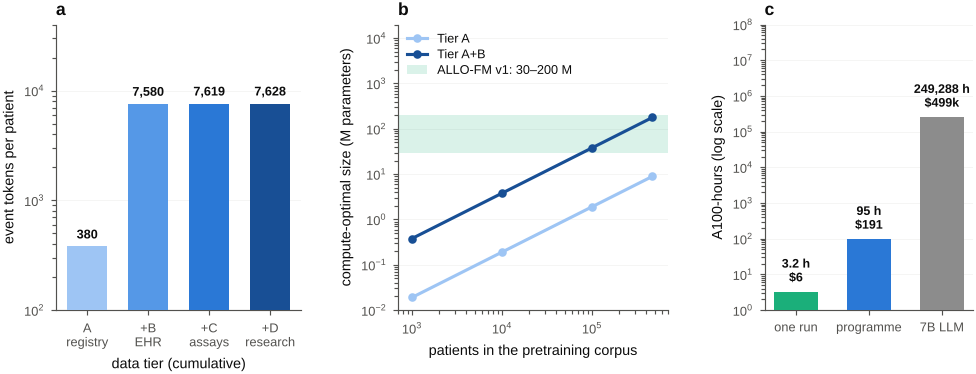

[saved] figures/Fig06_training_requirements.pdf  +  figures/Fig06_training_requirements.png


In [20]:
# ----------------------------------------------------------------------------- Figure 6: the training-requirement landscape
fig = plt.figure(figsize=(FULL, 3.0))
gs = fig.add_gridspec(1, 3, width_ratios=[1.0, 1.1, .85], left=.075, right=.985, bottom=.20, top=.88, wspace=.40)
ax = fig.add_subplot(gs[0, 0]); ygrid(ax)                                       # (a) tokens per patient, cumulative by tier
vals = [tok_by_tier[t] for t in TIER_ORDER]
ax.bar(range(4), vals, color=PAL['seq'], width=.66, zorder=3)
for i, v in enumerate(vals): ax.text(i, v * 1.12, f'{v:,}', ha='center', va='bottom', fontsize=6.5, fontweight='bold')
ax.set_yscale('log'); ax.set_ylim(100, 4e4); ax.set_xticks(range(4))
ax.set_xticklabels(['A\nregistry', '+B\nEHR', '+C\nassays', '+D\nresearch'])
ax.set_ylabel('event tokens per patient'); ax.set_xlabel('data tier (cumulative)'); panel(ax, 'a')
ax = fig.add_subplot(gs[0, 1]); ygrid(ax)                                       # (b) compute-optimal size
for tiers, c in (('A', PAL['seq'][0]), ('A+B', PAL['seq'][3])):
    q = cmp[(cmp.tiers == tiers) & (cmp.regime.str.startswith('compute'))].sort_values('patients')
    ax.plot(q.patients, q.params / 1e6, marker='o', ms=3.4, color=c, lw=1.6, label=f'Tier {tiers}', zorder=3)
band = ax.axhspan(30, 200, color=PAL['aqua'], alpha=.16, lw=0, label='ALLO-FM v1: 30–200 M')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_ylim(1e-2, 2e4); ax.set_xlim(7e2, 7e5)
ax.set_xlabel('patients in the pretraining corpus'); ax.set_ylabel('compute-optimal size (M parameters)')
ax.legend(loc='upper left', labelspacing=.3); panel(ax, 'b')
ax = fig.add_subplot(gs[0, 2]); ygrid(ax)                                       # (c) the bill
REF = [('one run', gpu_opt, PAL['aqua']), ('programme', PROG_H, PAL['seq'][2]), ('7B LLM', a100_hours(LLM_FLOPS), PAL['grey'])]
ax.bar(range(3), [r[1] for r in REF], color=[r[2] for r in REF], width=.6, zorder=3)
for i, (lab, v, c) in enumerate(REF):
    ax.text(i, v * 1.6, f'{fmt_h(v)}\n{fmt_usd(v * USD_PER_H)}', ha='center', va='bottom', fontsize=6.4, fontweight='bold')
ax.set_yscale('log'); ax.set_ylim(1, 1e8); ax.set_xticks(range(3)); ax.set_xticklabels([r[0] for r in REF])
ax.set_ylabel('A100-hours (log scale)'); panel(ax, 'c')
finish(fig, 6, 'training_requirements',
       'Training requirements, computed from the data specification. (a) Event tokens per patient, cumulative across data '
       'tiers: the EHR timeline (Tier B) supplies nearly all of them, and the deep assays add almost none while costing the '
       'most to obtain. (b) Compute-optimal model size at 20 tokens per parameter: a realistic corpus implies tens to '
       'low hundreds of millions of parameters, not billions (Tier A+B+C lies on the A+B line). (c) Pretraining cost at '
       '$2 per A100-hour, 30% utilisation and 4 epochs: one run (100,000 patients, Tier A+B), the whole enumerated programme (§7.2 table), and a general 7B language model. '
       'Compute is not the binding constraint; assay and collection cost is (§9.8).')

In [21]:
stor = pd.DataFrame([
 ('A  registry core',        '~50 kB',     '~5 GB',                 'structured coded fields only'),
 ('B  EHR timeline',         '~2–10 MB',   '~0.2–1 TB',             'labs, drugs, vitals, note embeddings'),
 ('C  biospecimen assays',   '~0.1–1 GB',  '~10–100 TB',            'bulk RNA-seq, flow FCS, 16S, proteomics; realistically on 10⁴ patients → 1–10 TB'),
 ('D  deep phenotyping',     '~5–50 GB',   'not feasible at 10⁵',   'scRNA + VDJ, whole-slide images, spatial; realistically 10²–10³ patients'),
], columns=['tier', 'storage per patient', 'for 100,000 patients', 'note'])
display(md_table(stor))
display(Markdown(f"""**Reading §7.** For the realistic target — **{TARGET['patients']:,} patients with Tier A+B data, ≈ {D_t/1e9:.2f} billion event tokens** — the compute-optimal model is **{N_opt/1e6:.0f} M parameters** ({shape_for(N_opt)[0]} layers, width {shape_for(N_opt)[1]}), trainable in **{fmt_h(gpu_opt)} on one A100** ({C_main:.1e} FLOPs, attention included, 4 epochs, 30 % utilisation; {fmt_h(a100_hours(C_main, MFU['optimistic']))}–{fmt_h(a100_hours(C_main, MFU['pessimistic']))} across the utilisation range). A smaller **{N_small/1e6:.1f} M-parameter** model trained for ten times as many token passes costs {fmt_h(gpu_small)} and is far cheaper to serve. Enumerating the *whole* programme — three seeds, a 20-run scaling study, a 48-run ablation suite, five adapters and 2,880 downstream fine-tunes — gives **{PROG_FLOPS:.1e} FLOPs ≈ {fmt_h(PROG_H)} on one A100 ≈ {fmt_usd(PROG_H * USD_PER_H)}**, which is **{OOM_VS_LLM:.1f} orders of magnitude** below a 7B-parameter language model. The sensitivity table shows that even a 4× error in the token budget, in either direction, leaves the programme at the scale of GPU-hours to GPU-days on a single device, not a cluster.

**Three conclusions that should shape how this project is proposed.**
1. **Do not ask for a GPU cluster; ask for data access.** The binding constraints are the registry study proposal, the data-use agreement and the biobank collaboration — not compute. The compute for the whole programme is a few GPU-days; the assays and specimen collection of §9.8 cost three to four orders of magnitude more. A plan whose critical path is hardware procurement has misidentified its own bottleneck. The real engineering cost is the harness (§11.0), not the training run.
2. **The right model is small.** At ~10⁹ tokens, anything above a few hundred million parameters is past compute-optimal and will be data-limited; the published single-cell scaling study found performance plateauing well before current corpus sizes ✓, and MOTOR — the closest clinical analogue — is a 143 M-parameter model ✓. Anyone proposing a multi-billion-parameter GvHD model should be asked which tokens it is going to read.
3. **Tier C/D data buys information, not tokens.** Panel (a) makes this unusually clear: the deep assays contribute a handful of tokens per patient (7,580 → 7,628) while costing the most to acquire. Their value must therefore be demonstrated per-patient by modality knockout (§8.8) and tier ablation (task G4), never assumed from volume."""))

| tier | storage per patient | for 100,000 patients | note |
|---|---|---|---|
| A  registry core | ~50 kB | ~5 GB | structured coded fields only |
| B  EHR timeline | ~2–10 MB | ~0.2–1 TB | labs, drugs, vitals, note embeddings |
| C  biospecimen assays | ~0.1–1 GB | ~10–100 TB | bulk RNA-seq, flow FCS, 16S, proteomics; realistically on 10⁴ patients → 1–10 TB |
| D  deep phenotyping | ~5–50 GB | not feasible at 10⁵ | scRNA + VDJ, whole-slide images, spatial; realistically 10²–10³ patients |

**Reading §7.** For the realistic target — **100,000 patients with Tier A+B data, ≈ 0.76 billion event tokens** — the compute-optimal model is **38 M parameters** (9 layers, width 576), trainable in **3.2 h on one A100** (1.1e+18 FLOPs, attention included, 4 epochs, 30 % utilisation; 2.1 h–6.4 h across the utilisation range). A smaller **3.8 M-parameter** model trained for ten times as many token passes costs 0.43 h and is far cheaper to serve. Enumerating the *whole* programme — three seeds, a 20-run scaling study, a 48-run ablation suite, five adapters and 2,880 downstream fine-tunes — gives **3.2e+19 FLOPs ≈ 95 h on one A100 ≈ $191**, which is **3.4 orders of magnitude** below a 7B-parameter language model. The sensitivity table shows that even a 4× error in the token budget, in either direction, leaves the programme at the scale of GPU-hours to GPU-days on a single device, not a cluster.

**Three conclusions that should shape how this project is proposed.**
1. **Do not ask for a GPU cluster; ask for data access.** The binding constraints are the registry study proposal, the data-use agreement and the biobank collaboration — not compute. The compute for the whole programme is a few GPU-days; the assays and specimen collection of §9.8 cost three to four orders of magnitude more. A plan whose critical path is hardware procurement has misidentified its own bottleneck. The real engineering cost is the harness (§11.0), not the training run.
2. **The right model is small.** At ~10⁹ tokens, anything above a few hundred million parameters is past compute-optimal and will be data-limited; the published single-cell scaling study found performance plateauing well before current corpus sizes ✓, and MOTOR — the closest clinical analogue — is a 143 M-parameter model ✓. Anyone proposing a multi-billion-parameter GvHD model should be asked which tokens it is going to read.
3. **Tier C/D data buys information, not tokens.** Panel (a) makes this unusually clear: the deep assays contribute a handful of tokens per patient (7,580 → 7,628) while costing the most to acquire. Their value must therefore be demonstrated per-patient by modality knockout (§8.8) and tier ablation (task G4), never assumed from volume.

---
# 8 · GvHD-Bench v1.0

> **This section is the benchmark.** It is written to be used without the rest of the paper, and it is exported in full to `spec/GVHD_BENCH_v1.0.md` together with machine-readable task and cohort definitions. A benchmark earns trust by being *specific about the things people get wrong*: who is in the cohort, what the label function is, which inputs are admissible at which time, how the splits are drawn, what must be beaten, how many submissions are allowed, and what counts as a win. Each of those is pinned below.

## 8.0 Scope, version and governance

| | |
|---|---|
| **Version** | v1.0 (this notebook). Semantic versioning: a **patch** fixes a bug in a label function or metric; a **minor** adds tasks or baselines; a **major** changes a split, a cohort definition or a gate. Results are only comparable within a major version, and every reported number carries the version and the artefact hashes. |
| **Primary question** | Does a pretrained multimodal model improve *out-of-centre* risk prediction in allo-HCT over the models clinicians already use? |
| **Unit of analysis** | the patient; a donor–recipient pair where both contribute data. Never the sample, never the specimen. |
| **Clock** | all times in days relative to the first graft infusion (day 0), fractional days allowed. |
| **Label authority** | the executable functions in §4.6. Where they disagree with a consensus document, the consensus document wins and the functions are patched (a patch release). |
| **Admissibility** | an event may be read at landmark *L* only if `t_known ≤ L` (§4.1, §4.7). This is enforced by the harness, not left to the modeller. |
| **Frozen artefacts** | split assignment files, seeds, the gate, and the hash of each are released with the benchmark; a result computed against unreleased splits is not a GvHD-Bench result. |
| **Governance** | tasks are added by pull request with a task card (§8.2) and a power calculation; a task whose accessible n falls below its computed minimum is published as **under-powered** rather than quietly scored. |

## 8.1 Cohort definition (the part that is usually left vague)

**Included.** First allogeneic HCT for any indication; any donor type, graft source and conditioning intensity; age ≥ 0; transplant year within the stated era window; a recorded day 0 and at least one follow-up contact after day +7.

**Excluded.** Autologous and syngeneic transplants; second and subsequent transplants (they open a new `pair_id` and are analysed separately); patients who withdrew consent for research use; records whose day 0 or outcome date is missing or internally inconsistent (these are counted and reported, never silently dropped).

**Landmark eligibility, applied per task.** A patient enters a task at landmark *L* only if they are alive, in follow-up and **have not already had the outcome event** at *L*. Patients who died, relapsed or were censored before *L* are excluded from that task and counted in its attrition table. For response tasks the clock starts at treatment initiation, not at day 0.

**Landmarks are issue days, not draw days.** A prediction is *issued* on the landmark day and may use a specimen only once its result exists: a day-7 plasma draw with a 48-hour assay turnaround supports a prediction issued on **day +9**, a sequenced sample a week or more later (§4.7, Figure 5). Task cards therefore state the issue day, and the audit tests `t_known ≤ L` against it.

**Competing events.** Death and relapse are competing events for every GvHD endpoint, never censoring. Cumulative incidence uses Aalen–Johansen; discrimination uses inverse-probability-of-censoring weighting (§8.4).

**Mandatory attrition reporting.** Every task reports: patients in cohort → meeting landmark eligibility → with the required input tier → with a non-missing outcome, with the count lost at each step. A benchmark that cannot show its attrition cannot be audited.

## 8.2 Design principles

1. **Tasks are decisions.** Every task sits at a real decision point on the Figure-1 timeline, with exactly the inputs a clinician would have had at that moment.
2. **Every task names the model it must beat** — not chance, but what is used today: refined DRI, HCT-CI, EASIX, the MAGIC algorithm probability, onset grade and organ pattern, NIH organ scores, or a tuned gradient-boosted tree on registry variables.
3. **Competing risks are first-class.** Death and relapse are events, not censoring.
4. **Splits are hard by default**: leave-centre-out, and temporal for any deployment claim. Random splits are reported only as an upper bound and labelled as such.
5. **Minimum n is computed, not assumed** (§8.3), and each task carries a *powered / under-powered* verdict that travels with its result.
6. **A negative result is a result.** The benchmark is designed so that "the foundation model did not beat the baseline" is a reportable, publishable outcome with a clear interpretation.

## 8.3 The task registry
Families: **A** pre-transplant planning · **B** early post-transplant prognosis · **C** diagnosis and acute course · **D** treatment response · **E** chronic GvHD and late effects · **F** mechanism and representation · **G** robustness and governance.

In [22]:
# ----------------------------------------------------------------------------- Riley et al. sample-size criteria (needed by the registry; validated below)
def r2cs_from_auc(A, prev, n_mc=400_000, seed=0):
    """Model-implied Cox-Snell R^2 for a calibrated model with given AUROC and prevalence (equal-variance binormal)."""
    rng = np.random.default_rng(seed); d = math.sqrt(2) * norm.ppf(A)
    y = rng.random(n_mc) < prev; x = np.where(y, rng.normal(d, 1, n_mc), rng.normal(0, 1, n_mc))
    lp = math.log(prev / (1 - prev)) + d * x - d * d / 2; p = 1 / (1 + np.exp(-lp))
    ll1 = np.mean(np.where(y, np.log(p), np.log(1 - p))); ll0 = prev * math.log(prev) + (1 - prev) * math.log(1 - prev)
    return 1 - math.exp(-2 * (ll1 - ll0))

def riley_n(P, A, prev, S=.9, delta=.05, margin=.05):
    """Minimum n to DEVELOP a model with P candidate parameters (Riley 2020): shrinkage, optimism, prevalence precision."""
    r2 = r2cs_from_auc(A, prev); max_r2 = 1 - math.exp(2 * (prev * math.log(prev) + (1 - prev) * math.log(1 - prev)))
    n1 = P / ((S - 1) * math.log(1 - r2 / S))
    S2 = r2 / (r2 + delta * max_r2); n2 = P / ((S2 - 1) * math.log(1 - r2 / S2))
    n3 = (1.96 / margin) ** 2 * prev * (1 - prev)
    n = max(n1, n2, n3)
    return dict(n=int(math.ceil(n)), events=int(math.ceil(n * prev)), EPP=round(n * prev / P, 1),
                binding=['shrinkage', 'optimism', 'prevalence'][int(np.argmax([n1, n2, n3]))])
assert abs(24 / ((0.9 - 1) * math.log(1 - 0.288 / 0.9)) - 623) < 1.5     # arithmetic check of criterion 1 on a published worked example
print('Riley criterion-1 arithmetic check passed; R2_CS(AUROC .75, prev .4) =', round(r2cs_from_auc(.75, .4), 3))

Riley criterion-1 arithmetic check passed; R2_CS(AUROC .75, prev .4) = 0.179


In [23]:
# ----------------------------------------------------------------------------- GVHD-BENCH TASK REGISTRY (exported to spec/task_registry.csv)
# id, family, task, landmark, horizon, inputs allowed (tiers), outcome (label fn), competing events, primary metric, clinical baseline to beat, prev, target AUROC
TASKS = [
('A1','A pre-HCT','Grade II–IV aGvHD by day +100 from pre-transplant data only','day −7 (before conditioning)','day +100','A (+C germline/KIR)','MAGIC grade ≥ II (§4.6)','death, relapse','IPCW td-AUROC @100 + calibration','donor-type + DRI + HCT-CI + prophylaxis logistic (registry standard)',.38,.68),
('A2','A pre-HCT','Grade III–IV aGvHD by day +100','day −7','day +100','A (+C)','MAGIC grade ≥ III','death, relapse','IPCW td-AUROC, AUPRC','same registry model',.13,.70),
('A3','A pre-HCT','cGvHD requiring systemic therapy by 2 years','day −7','2 years','A (+C)','NIH 2014 moderate/severe or systemic tx','death, relapse','IPCW td-AUROC @730','graft source + donor age/sex + ATG model',.33,.65),
('A4','A pre-HCT','GRFS at 1 year','day −7','1 year','A','GRFS first event (§4.6)','—(composite)','C-index, IBS, calibration','DRI + HCT-CI + donor type',.52,.68),
('A5','A pre-HCT','Non-relapse mortality at 1 year','day −7','1 year','A','death without relapse','relapse','IPCW td-AUROC, Aalen–Johansen calibration','HCT-CI + age + DRI',.18,.70),
('A6','A pre-HCT','Donor ranking: order candidate donors by predicted GRFS','donor search','1 year','A + D06 immunogenetics','counterfactual GRFS per donor','—','pairwise concordance among realised choices; policy value','current algorithm (match grade → age → CMV → sex)',None,None),
('A7','A pre-HCT','Prophylaxis-platform benefit (PtCy/Tac/MMF vs Tac/MTX) for this pair','day −3','1 year','A','GRFS; grade III–IV aGvHD','death, relapse','calibration of predicted arm difference within RANDOMISED arms (BMT CTN 1703)','no-effect-modification (constant ATE) model',None,None),
('B1','B early','Grade II–IV aGvHD by day +100 from the day +7 state','day +9 (day-7 draw, resulted)','day +100','A,B (+C biomarkers)','MAGIC grade ≥ II','death, relapse','IPCW td-AUROC; net benefit at 10–40 %','**MAP (ST2+REG3α day-7 algorithm)** + clinical',.35,.72),
('B2','B early','Severe (grade III–IV) aGvHD by day +100 from day +14','day +16 (day-14 draw, resulted)','day +100','A,B,C','MAGIC grade ≥ III','death, relapse','IPCW td-AUROC, AUPRC','MAP + clinical',.13,.75),
('B3','B early','7-day-ahead rolling onset alarm (continuous early warning)','every day, +7 to +60','7 days','A,B (+C,D)','first day of grade ≥ II within 7 d','death, relapse, discharge','AUROC per alarm-day; alerts per 100 patient-days at 50 % sensitivity','clinician-trigger proxy (CRP + stool volume thresholds)',.04,.75),
('B4','B early','Lower-GI aGvHD specifically by day +100 from day +14','day +16 (day-14 draw, resulted)','day +100','A,B,C,D','lower-GI stage ≥ 1','death, relapse','IPCW td-AUROC','REG3α + clinical',.22,.72),
('B5','B early','NRM at 1 year from day +7','day +9 (day-7 draw, resulted)','1 year','A,B,C','death without relapse','relapse','IPCW td-AUROC, calibration','MAP (its validated use) + HCT-CI',.18,.75),
('B6','B early','Relapse by 1 year from day +30 (GvL trade-off partner)','day +30','1 year','A,B (+C chimerism/MRD)','relapse/progression','death','IPCW td-AUROC','DRI + day-30 MRD + chimerism',.24,.72),
('C1','C diagnosis & acute course','Differential diagnosis of early post-HCT diarrhoea: GvHD vs infection vs drug/other','day of symptom onset','7 days (adjudicated)','A,B (+C,D; biopsy-independent)','adjudicated cause (biopsy + microbiology + course)','—(multiclass)','macro-AUROC; GvHD-vs-rest AUPRC','clinical gestalt proxy: stool PCR + timing + CRP',.45,.80),
('C2','C diagnosis & acute course','Is this rash GvHD, drug eruption, or engraftment syndrome?','day of rash','7 days','A,B (+D photo/WSI)','adjudicated cause','—','macro-AUROC','timing + eosinophils + drug-start model',.5,.75),
('C3','C diagnosis & acute course','Will this patient need a GI biopsy (triage) / can biopsy be avoided?','day of symptom onset','14 days','A,B','biopsy-confirmed GvHD among those biopsied; decision-analytic','—','net benefit vs biopsy-all / biopsy-none','biopsy-all',.45,.78),
('C4','C diagnosis & acute course','Steroid-refractory aGvHD by day +28 of therapy','day systemic steroids start','28 days','A,B,C (+D onset biopsy/transcriptome)','SR phenotype (§4.6)','death','AUROC + calibration','MAGIC grade at onset + MAP + organ pattern',.30,.72),
('C5','C diagnosis & acute course','Day +28 overall response (CR/PR vs NR) to first-line steroids','steroid start','28 days','A,B,C,D','MAGIC response criteria','death','AUROC','grade + organ stage at onset',.35,.70),
('C6','C diagnosis & acute course','NRM at 6 months from aGvHD onset','onset day','6 months','A,B,C','death without relapse','relapse','IPCW td-AUROC','Ann Arbor score (TNFR1/ST2/REG3α) / MAP at onset',.30,.75),
('C7','C diagnosis & acute course','Histological severity / crypt-apoptosis grade from the biopsy itself','biopsy sign-out','—','D19 WSI (+D17)','pathologist Lerner/Sale grade (central read)','—','quadratic-weighted κ; AUROC for grade ≥ 3','ResNet/pathology-FM linear probe on WSI tiles',.3,.80),
('C8','C diagnosis & acute course','Organ-involvement multi-label at onset (skin/upper GI/lower GI/liver)','onset day','—','A,B,C,D','MAGIC organ stages','—','macro-AUROC, per-organ calibration','overall grade only',None,None),
('D1','D response','Second-line response at day +28 (ruxolitinib era)','second-line start','28 days','A,B,C,D','overall response (MAGIC)','death','AUROC + calibration','grade + prior response + organ pattern',.40,.70),
('D2','D response','Which second-line agent? (policy, validated on REACH-style randomised data where available)','second-line start','28 days','A,B,C,D','response under received agent','death','policy value; calibration of predicted contrast within randomised data','single-agent default policy',None,None),
('D3','D response','Steroid taper safety: flare within 28 days of a taper step','each taper decision','28 days','A,B,C','grade increase or treatment intensification','death, relapse','AUROC; net benefit','fixed-schedule taper',.20,.70),
('D4','D response','Infection within 30 days under intensified immunosuppression','treatment start','30 days','A,B','blood-culture-positive bacteraemia / IFD / CMV disease','death','AUROC','ALC + neutropenia + prior infection',.30,.72),
('E1','E chronic','NIH moderate/severe cGvHD by 1 year, from day +100','day +100','1 year','A,B (+C day-100 biomarkers, D14 subsets)','NIH 2014 global ≥ moderate','death, relapse','IPCW td-AUROC','prior aGvHD + graft source + ATG + donor sex (clinical model) ± biomarker panel',.30,.68),
('E2','E chronic','Bronchiolitis-obliterans syndrome / FEV1 decline ≥ 10 % by 2 years','day +100','2 years','A,B,D19 (PFT/CT)','NIH BOS criteria','death, relapse','IPCW td-AUROC','baseline + day-100 FEV1 slope',.08,.72),
('E3','E chronic','6-month response to cGvHD therapy (NIH response criteria)','therapy start','6 months','A,B,C,D,D22','NIH 2014 CR/PR vs not','death','AUROC','organ scores at start + clinician global',.35,.68),
('E4','E chronic','Immunosuppression-free survival at 3 years','day +365','3 years','A,B','alive, relapse-free, off systemic IS','death, relapse','IPCW td-AUROC','cGvHD severity + taper status',.40,.68),
('E5','E chronic','Safe immunosuppression taper: relapse vs flare trade-off','each taper decision after +180','6 months','A,B (+MRD/chimerism)','relapse and flare (joint)','death','bivariate net benefit; decision curves','clinician practice (fixed taper)',None,None),
('F1','F mechanism','Donor-reactive clone identification (clone-level)','pre-HCT / onset','—','D16 (+D17)','MLR-defined reactive clones','—','AUROC within abundance deciles','V/J+CDR3-length and k-mer models (the pilot ceiling)',.17,.65),
('F2','F mechanism','Zero-shot representation quality: biology kept, centre/batch discarded','any','—','all','compartment / cell-type / organ identity vs centre ID','—','two-axis score (scIB-style): biology kNN accuracy vs centre decodability','HVG / PCA / random-weight twin',None,None),
('F3','F mechanism','Counterfactual direction under JAK inhibition in primary T cells','perturbation experiment','—','D17 (+external screens)','post-perturbation profile','—','direction accuracy, rank correlation','additive/linear baseline',None,None),
('G1','G robustness','Temporal validation: train ≤ era k, test era k+1 (letermovir, PtCy expansion, ruxolitinib approvals)','as parent task','as parent','as parent','as parent','—','AUROC and calibration drift vs the random-split number','same model, random split',None,None),
('G2','G robustness','Leave-centre-out and leave-registry-out transfer (CIBMTR → EBMT)','as parent','as parent','as parent','as parent','—','per-centre AUROC spread; calibration slope per centre','pooled random split',None,None),
('G3','G robustness','Subgroup equity: paediatric vs adult, donor type, race/ethnicity, centre volume','as parent','as parent','as parent','as parent','—','worst-subgroup AUROC and calibration; equal-opportunity gap','overall model',None,None),
('G4','G robustness','Tier ablation: A only → A+B → A+B+C → A+B+C+D','as parent','as parent','progressively','as parent','—','ΔAUROC per added tier, with cost per patient','Tier A model',None,None),
('G5','G robustness','Missingness robustness: performance when a modality or a lab stream is absent at inference','as parent','as parent','as parent','as parent','—','AUROC under simulated and natural missingness','complete-case model',None,None),
('G6','G robustness','Target-trial emulation: reproduce a published randomised effect (BMT CTN 1703: PTCy/Tac/MMF vs Tac/MTX, GRFS HR 0.64, 95% CI 0.49–0.83 ✓) from registry data','trial eligibility + randomisation-equivalent day','1 year','A (trial-eligibility variables) + model-based adjustment','GRFS (§4.6)','death, relapse (composite)','|log HR(emulated) − log HR(trial)| and coverage of the trial interval by the emulation interval','unadjusted registry comparison; propensity-weighted tuned-tree adjustment',None,None),
('G7','G robustness','Negative-control suite: every submission is also run on permuted outcomes (within centre) and on a negative-control exposure (e.g. donor birth month)','as parent','as parent','as parent','permuted / null outcome','—','false-pass rate across the whole suite; must not exceed the nominal level','—',None,None),
]
COLS = ['id','family','task','landmark','horizon','inputs allowed (tiers)','outcome (label fn)','competing events',
        'primary metric','clinical baseline to beat','assumed prevalence','target AUROC']
reg = pd.DataFrame(TASKS, columns=COLS)
ok_n = [bool(pd.notna(a) and pd.notna(p)) for a, p in zip(reg['target AUROC'], reg['assumed prevalence'])]
reg['min n (50-param head)'] = [riley_n(50, a, p)['n'] if o else '' for o, a, p in zip(ok_n, reg['target AUROC'], reg['assumed prevalence'])]
reg['min n (768-param head)'] = [riley_n(768, a, p)['n'] if o else '' for o, a, p in zip(ok_n, reg['target AUROC'], reg['assumed prevalence'])]
reg.to_csv(os.path.join(SPEC_DIR, 'task_registry.csv'), index=False)
print(f'{len(reg)} tasks in {reg.family.nunique()} families; '
      f"{int((reg['target AUROC'].notna()).sum())} have a numeric target and a computed minimum n")
display(md_table(reg.groupby('family').agg(tasks=('id', 'count'), ids=('id', lambda s: ', '.join(s))), index=True))

40 tasks in 7 families; 26 have a numeric target and a computed minimum n


| family | tasks | ids |
|---|---|---|
| A pre-HCT | 7 | A1, A2, A3, A4, A5, A6, A7 |
| B early | 6 | B1, B2, B3, B4, B5, B6 |
| C diagnosis & acute course | 8 | C1, C2, C3, C4, C5, C6, C7, C8 |
| D response | 4 | D1, D2, D3, D4 |
| E chronic | 5 | E1, E2, E3, E4, E5 |
| F mechanism | 3 | F1, F2, F3 |
| G robustness | 7 | G1, G2, G3, G4, G5, G6, G7 |

In [24]:
# ----------------------------------------------------------------------------- render the registry family by family
for fam in reg.family.unique():
    display(Markdown(f'#### Family {fam}'))
    display(md_table(reg[reg.family == fam].drop(columns=['family']).fillna(''), max_w=170))

#### Family A pre-HCT

| id | task | landmark | horizon | inputs allowed (tiers) | outcome (label fn) | competing events | primary metric | clinical baseline to beat | assumed prevalence | target AUROC | min n (50-param head) | min n (768-param head) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| A1 | Grade II–IV aGvHD by day +100 from pre-transplant data only | day −7 (before conditioning) | day +100 | A (+C germline/KIR) | MAGIC grade ≥ II (§4.6) | death, relapse | IPCW td-AUROC @100 + calibration | donor-type + DRI + HCT-CI + prophylaxis logistic (registry standard) | 0.38 | 0.68 | 4554 | 69945 |
| A2 | Grade III–IV aGvHD by day +100 | day −7 | day +100 | A (+C) | MAGIC grade ≥ III | death, relapse | IPCW td-AUROC, AUPRC | same registry model | 0.13 | 0.7 | 7733 | 118777 |
| A3 | cGvHD requiring systemic therapy by 2 years | day −7 | 2 years | A (+C) | NIH 2014 moderate/severe or systemic tx | death, relapse | IPCW td-AUROC @730 | graft source + donor age/sex + ATG model | 0.33 | 0.65 | 6997 | 107471 |
| A4 | GRFS at 1 year | day −7 | 1 year | A | GRFS first event (§4.6) | —(composite) | C-index, IBS, calibration | DRI + HCT-CI + donor type | 0.52 | 0.68 | 4315 | 66277 |
| A5 | Non-relapse mortality at 1 year | day −7 | 1 year | A | death without relapse | relapse | IPCW td-AUROC, Aalen–Johansen calibration | HCT-CI + age + DRI | 0.18 | 0.7 | 5921 | 90939 |
| A6 | Donor ranking: order candidate donors by predicted GRFS | donor search | 1 year | A + D06 immunogenetics | counterfactual GRFS per donor | — | pairwise concordance among realised choices; policy value | current algorithm (match grade → age → CMV → sex) |  |  |  |  |
| A7 | Prophylaxis-platform benefit (PtCy/Tac/MMF vs Tac/MTX) for this pair | day −3 | 1 year | A | GRFS; grade III–IV aGvHD | death, relapse | calibration of predicted arm difference within RANDOMISED arms (BMT CTN 1703) | no-effect-modification (constant ATE) model |  |  |  |  |

#### Family B early

| id | task | landmark | horizon | inputs allowed (tiers) | outcome (label fn) | competing events | primary metric | clinical baseline to beat | assumed prevalence | target AUROC | min n (50-param head) | min n (768-param head) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| B1 | Grade II–IV aGvHD by day +100 from the day +7 state | day +9 (day-7 draw, resulted) | day +100 | A,B (+C biomarkers) | MAGIC grade ≥ II | death, relapse | IPCW td-AUROC; net benefit at 10–40 % | **MAP (ST2+REG3α day-7 algorithm)** + clinical | 0.35 | 0.72 | 3103 | 47662 |
| B2 | Severe (grade III–IV) aGvHD by day +100 from day +14 | day +16 (day-14 draw, resulted) | day +100 | A,B,C | MAGIC grade ≥ III | death, relapse | IPCW td-AUROC, AUPRC | MAP + clinical | 0.13 | 0.75 | 4705 | 72266 |
| B3 | 7-day-ahead rolling onset alarm (continuous early warning) | every day, +7 to +60 | 7 days | A,B (+C,D) | first day of grade ≥ II within 7 d | death, relapse, discharge | AUROC per alarm-day; alerts per 100 patient-days at 50 % sensitivity | clinician-trigger proxy (CRP + stool volume thresholds) | 0.04 | 0.75 | 12076 | 185480 |
| B4 | Lower-GI aGvHD specifically by day +100 from day +14 | day +16 (day-14 draw, resulted) | day +100 | A,B,C,D | lower-GI stage ≥ 1 | death, relapse | IPCW td-AUROC | REG3α + clinical | 0.22 | 0.72 | 4102 | 62999 |
| B5 | NRM at 1 year from day +7 | day +9 (day-7 draw, resulted) | 1 year | A,B,C | death without relapse | relapse | IPCW td-AUROC, calibration | MAP (its validated use) + HCT-CI | 0.18 | 0.75 | 3632 | 55775 |
| B6 | Relapse by 1 year from day +30 (GvL trade-off partner) | day +30 | 1 year | A,B (+C chimerism/MRD) | relapse/progression | death | IPCW td-AUROC | DRI + day-30 MRD + chimerism | 0.24 | 0.72 | 3883 | 59637 |

#### Family C diagnosis & acute course

...

| id | task | landmark | horizon | inputs allowed (tiers) | outcome (label fn) | competing events | primary metric | clinical baseline to beat | assumed prevalence | target AUROC | min n (50-param head) | min n (768-param head) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| E1 | NIH moderate/severe cGvHD by 1 year, from day +100 | day +100 | 1 year | A,B (+C day-100 biomarkers, D14 subsets) | NIH 2014 global ≥ moderate | death, relapse | IPCW td-AUROC | prior aGvHD + graft source + ATG + donor sex (clinical model) ± biomarker panel | 0.3 | 0.68 | 5105 | 78399 |
| E2 | Bronchiolitis-obliterans syndrome / FEV1 decline ≥ 10 % by 2 years | day +100 | 2 years | A,B,D19 (PFT/CT) | NIH BOS criteria | death, relapse | IPCW td-AUROC | baseline + day-100 FEV1 slope | 0.08 | 0.72 | 9491 | 145778 |
| E3 | 6-month response to cGvHD therapy (NIH response criteria) | therapy start | 6 months | A,B,C,D,D22 | NIH 2014 CR/PR vs not | death | AUROC | organ scores at start + clinician global | 0.35 | 0.68 | 4706 | 72274 |
| E4 | Immunosuppression-free survival at 3 years | day +365 | 3 years | A,B | alive, relapse-free, off systemic IS | death, relapse | IPCW td-AUROC | cGvHD severity + taper status | 0.4 | 0.68 | 4464 | 68564 |
| E5 | Safe immunosuppression taper: relapse vs flare trade-off | each taper decision after +180 | 6 months | A,B (+MRD/chimerism) | relapse and flare (joint) | death | bivariate net benefit; decision curves | clinician practice (fixed taper) |  |  |  |  |

#### Family F mechanism

| id | task | landmark | horizon | inputs allowed (tiers) | outcome (label fn) | competing events | primary metric | clinical baseline to beat | assumed prevalence | target AUROC | min n (50-param head) | min n (768-param head) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| F1 | Donor-reactive clone identification (clone-level) | pre-HCT / onset | — | D16 (+D17) | MLR-defined reactive clones | — | AUROC within abundance deciles | V/J+CDR3-length and k-mer models (the pilot ceiling) | 0.17 | 0.65 | 11675 | 179318 |
| F2 | Zero-shot representation quality: biology kept, centre/batch discarded | any | — | all | compartment / cell-type / organ identity vs centre ID | — | two-axis score (scIB-style): biology kNN accuracy vs centre decodability | HVG / PCA / random-weight twin |  |  |  |  |
| F3 | Counterfactual direction under JAK inhibition in primary T cells | perturbation experiment | — | D17 (+external screens) | post-perturbation profile | — | direction accuracy, rank correlation | additive/linear baseline |  |  |  |  |

#### Family G robustness

| id | task | landmark | horizon | inputs allowed (tiers) | outcome (label fn) | competing events | primary metric | clinical baseline to beat | assumed prevalence | target AUROC | min n (50-param head) | min n (768-param head) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| G1 | Temporal validation: train ≤ era k, test era k+1 (letermovir, PtCy expansion, ruxolitinib approvals) | as parent task | as parent | as parent | as parent | — | AUROC and calibration drift vs the random-split number | same model, random split |  |  |  |  |
| G2 | Leave-centre-out and leave-registry-out transfer (CIBMTR → EBMT) | as parent | as parent | as parent | as parent | — | per-centre AUROC spread; calibration slope per centre | pooled random split |  |  |  |  |
| G3 | Subgroup equity: paediatric vs adult, donor type, race/ethnicity, centre volume | as parent | as parent | as parent | as parent | — | worst-subgroup AUROC and calibration; equal-opportunity gap | overall model |  |  |  |  |
| G4 | Tier ablation: A only → A+B → A+B+C → A+B+C+D | as parent | as parent | progressively | as parent | — | ΔAUROC per added tier, with cost per patient | Tier A model |  |  |  |  |
| G5 | Missingness robustness: performance when a modality or a lab stream is absent at inference | as parent | as parent | as parent | as parent | — | AUROC under simulated and natural missingness | complete-case model |  |  |  |  |
| G6 | Target-trial emulation: reproduce a published randomised effect (BMT CTN 1703: PTCy/Tac/MMF vs Tac/MTX, GRFS HR 0.64, 95% CI 0.49–0.83 ✓) from registry data | trial eligibility + randomisation-equivalent day | 1 year | A (trial-eligibility variables) + model-based adjustment | GRFS (§4.6) | death, relapse (composite) | \|log HR(emulated) − log HR(trial)\| and coverage of the trial interval by the emulation interval | unadjusted registry comparison; propensity-weighted tuned-tree adjustment |  |  |  |  |
| G7 | Negative-control suite: every submission is also run on permuted outcomes (within centre) and on a negative-control exposure (e.g. donor birth month) | as parent | as parent | as parent | permuted / null outcome | — | false-pass rate across the whole suite; must not exceed the nominal level | — |  |  |  |  |

## 8.4 Task cards: readiness, accessible n, and the powered / under-powered verdict

The registry above says what each task *is*. A benchmark also has to say, for each task, **whether it can be run at all today, with which data, on how many patients, and whether that number is enough.** The cell below attaches those fields and computes the verdict. `readiness` is the honest status:

* **R1 — runnable now** on a registry extract (Tier A/B) with no new collection.
* **R2 — runnable on an existing biobank** (Tier C: MAGIC / BMT CTN specimens) with a collaboration.
* **R3 — needs prospective collection** on the 4.4 schedule.
* **R4 — research-grade only**: a nested sub-cohort, reported as mechanism, never as a deployment claim.

`n accessible` is a deliberately conservative estimate of the patients a serious 2026-era effort could assemble for that specific task, given its landmark eligibility and the data tier it needs. The verdict compares it against two requirements: the Riley minimum to *develop* a 50-parameter head, and the n needed to *demonstrate* a +0.03 AUROC improvement over the task's clinical baseline on a paired test. A task passes only if the accessible n clears both.

In [25]:
# ----------------------------------------------------------------------------- task cards: readiness, accessible n, powered verdict (exported with the registry)
# task id -> (readiness, tier needed, conservative accessible n, split protocol, achievable AUROC range from section 3.2)
CARDS = {
 'A1': ('R1', 'A', 120000, 'leave-centre-out + temporal', (.62, .70)), 'A2': ('R1', 'A', 120000, 'leave-centre-out + temporal', (.64, .72)),
 'A3': ('R1', 'A', 90000, 'leave-centre-out + temporal', (.62, .68)),  'A4': ('R1', 'A', 120000, 'leave-centre-out + temporal', (.64, .70)),
 'A5': ('R1', 'A', 120000, 'leave-centre-out + temporal', (.68, .76)), 'A6': ('R1', 'A+C', 40000, 'leave-centre-out; counterfactual', (None, None)),
 'A7': ('R2', 'A', 431, 'randomised arms (BMT CTN 1703)', (None, None)),
 'B1': ('R2', 'A+B+C', 4000, 'leave-centre-out + temporal', (.74, .80)), 'B2': ('R2', 'A+B+C', 4000, 'leave-centre-out + temporal', (.74, .82)),
 'B3': ('R1', 'A+B', 15000, 'leave-centre-out; per-day alarms', (.72, .80)), 'B4': ('R2', 'A+B+C', 3000, 'leave-centre-out', (.70, .78)),
 'B5': ('R2', 'A+B+C', 4000, 'leave-centre-out + temporal', (.72, .80)), 'B6': ('R1', 'A+B', 25000, 'leave-centre-out', (.68, .76)),
 'C1': ('R3', 'A+B(+C)', 800, 'leave-centre-out; adjudicated', (.78, .88)), 'C2': ('R3', 'A+B', 600, 'leave-centre-out; adjudicated', (.72, .82)),
 'C3': ('R1', 'A+B', 6000, 'leave-centre-out; decision-analytic', (.72, .80)),
 'C4': ('R2', 'A+B+C', 2500, 'leave-centre-out', (.68, .76)), 'C5': ('R2', 'A+B+C', 2500, 'leave-centre-out', (.66, .74)),
 'C6': ('R2', 'A+B+C', 2500, 'leave-centre-out + temporal', (.72, .80)), 'C7': ('R3', 'D', 500, 'leave-centre-out; central read', (None, None)),
 'C8': ('R1', 'A+B', 8000, 'leave-centre-out', (None, None)),
 'D1': ('R2', 'A+B', 1200, 'leave-centre-out', (.66, .74)), 'D2': ('R2', 'A+B', 400, 'randomised arms only', (None, None)),
 'D3': ('R1', 'A+B', 9000, 'leave-centre-out', (.64, .72)), 'D4': ('R1', 'A+B', 20000, 'leave-centre-out', (.68, .76)),
 'E1': ('R1', 'A+B', 40000, 'leave-centre-out + temporal', (.65, .72)), 'E2': ('R1', 'A+B', 12000, 'leave-centre-out', (.70, .78)),
 'E3': ('R2', 'A+B', 3000, 'leave-centre-out', (.64, .72)), 'E4': ('R1', 'A+B', 30000, 'leave-centre-out + temporal', (.64, .72)),
 'E5': ('R1', 'A+B', 20000, 'leave-centre-out; bivariate', (None, None)),
 'F1': ('R4', 'D', 80, 'leave-recipient-out', (.60, .66)), 'F2': ('R4', 'C+D', 1000, 'no head trained', (None, None)),
 'F3': ('R4', 'D', 40, 'held-out perturbations', (None, None)),
 'G1': ('R1', 'as parent', 120000, 'temporal', (None, None)), 'G2': ('R1', 'as parent', 120000, 'leave-registry-out', (None, None)),
 'G3': ('R1', 'as parent', 120000, 'subgroup within parent split', (None, None)), 'G4': ('R2', 'A->D', 2500, 'nested tiers, same patients', (None, None)),
 'G6': ('R1', 'A', 8000, 'registry vs trial effect (BMT CTN 1703)', (None, None)), 'G7': ('R1', 'as parent', 120000, 'permutation + negative exposure', (None, None)),
 'G5': ('R1', 'as parent', 120000, 'simulated + natural missingness', (None, None)),
}
card_rows = []
for _, r in reg.iterrows():
    rd, tier, n_acc, split, ach = CARDS[r.id]
    a, pv_ = r['target AUROC'], r['assumed prevalence']
    has = bool(pd.notna(a) and pd.notna(pv_))
    n_dev = riley_n(50, a, pv_)['n'] if has else None
    n_del = n_for_delta(a - .03, .03, pv_) if has else None
    need = max([x for x in (n_dev, n_del) if x]) if has else None
    verdict = '-' if need is None else ('POWERED' if n_acc >= need else 'UNDER-POWERED')
    card_rows.append({'id': r.id, 'family': r.family.split()[0], 'readiness': rd, 'tier needed': tier,
                      'split protocol': split, 'n accessible (est.)': n_acc,
                      'n to develop (50-param)': n_dev, 'n to show +0.03': n_del,
                      'achievable AUROC': '' if ach[0] is None else f'{ach[0]:.2f}-{ach[1]:.2f}',
                      'verdict': verdict})
cards_df = pd.DataFrame(card_rows)
reg_full = reg.merge(cards_df.drop(columns=['family']), on='id', how='left')
reg_full.to_csv(os.path.join(SPEC_DIR, 'task_registry.csv'), index=False)
cards_df.to_csv(os.path.join(SPEC_DIR, 'task_cards.csv'), index=False)
vc = cards_df.verdict.value_counts().to_dict()
print(f"{len(cards_df)} task cards | POWERED: {vc.get('POWERED', 0)} | UNDER-POWERED: {vc.get('UNDER-POWERED', 0)} | "
      f"not a single-AUROC task: {vc.get('-', 0)}")
print('readiness:', cards_df.readiness.value_counts().sort_index().to_dict())
display(md_table(cards_df))

40 task cards | POWERED: 15 | UNDER-POWERED: 11 | not a single-AUROC task: 14
readiness: {'R1': 22, 'R2': 12, 'R3': 3, 'R4': 3}


| id | family | readiness | tier needed | split protocol | n accessible (est.) | n to develop (50-param) | n to show +0.03 | achievable AUROC | verdict |
|---|---|---|---|---|---|---|---|---|---|
| A1 | A | R1 | A | leave-centre-out + temporal | 120000 | 4554.0 | 887.0 | 0.62-0.70 | POWERED |
| A2 | A | R1 | A | leave-centre-out + temporal | 120000 | 7733.0 | 1785.0 | 0.64-0.72 | POWERED |
| A3 | A | R1 | A | leave-centre-out + temporal | 90000 | 6997.0 | 985.0 | 0.62-0.68 | POWERED |
| A4 | A | R1 | A | leave-centre-out + temporal | 120000 | 4315.0 | 837.0 | 0.64-0.70 | POWERED |
| A5 | A | R1 | A | leave-centre-out + temporal | 120000 | 5921.0 | 1368.0 | 0.68-0.76 | POWERED |
| A6 | A | R1 | A+C | leave-centre-out; counterfactual | 40000 |  |  |  | - |
| A7 | A | R2 | A | randomised arms (BMT CTN 1703) | 431 |  |  |  | - |
| B1 | B | R2 | A+B+C | leave-centre-out + temporal | 4000 | 3103.0 | 854.0 | 0.74-0.80 | POWERED |
| B2 | B | R2 | A+B+C | leave-centre-out + temporal | 4000 | 4705.0 | 1603.0 | 0.74-0.82 | UNDER-POWERED |
| B3 | B | R1 | A+B | leave-centre-out; per-day alarms | 15000 | 12076.0 | 4722.0 | 0.72-0.80 | POWERED |
| B4 | B | R2 | A+B+C | leave-centre-out | 3000 | 4102.0 | 1132.0 | 0.70-0.78 | UNDER-POWERED |
| B5 | B | R2 | A+B+C | leave-centre-out + temporal | 4000 | 3632.0 | 1229.0 | 0.72-0.80 | POWERED |
| B6 | B | R1 | A+B | leave-centre-out | 25000 | 3883.0 | 1065.0 | 0.68-0.76 | POWERED |
| C1 | C | R3 | A+B(+C) | leave-centre-out; adjudicated | 800 | 1475.0 | 631.0 | 0.78-0.88 | UNDER-POWERED |
| C2 | C | R3 | A+B | leave-centre-out; adjudicated | 600 | 2176.0 | 726.0 | 0.72-0.82 | UNDER-POWERED |
| C3 | C | R1 | A+B | leave-centre-out; decision-analytic | 6000 | 1717.0 | 674.0 | 0.72-0.80 | POWERED |
| C4 | C | R2 | A+B+C | leave-centre-out | 2500 | 3358.0 | 925.0 | 0.68-0.76 | UNDER-POWERED |
| C5 | C | R2 | A+B+C | leave-centre-out | 2500 | 3786.0 | 888.0 | 0.66-0.74 | UNDER-POWERED |
| C6 | C | R2 | A+B+C | leave-centre-out + temporal | 2500 | 2558.0 | 864.0 | 0.72-0.80 | UNDER-POWERED |
| C7 | C | R3 | D | leave-centre-out; central read | 500 | 1715.0 | 744.0 |  | UNDER-POWERED |
| C8 | C | R1 | A+B | leave-centre-out | 8000 |  |  |  | - |
| D1 | D | R2 | A+B | leave-centre-out | 1200 | 3594.0 | 842.0 | 0.66-0.74 | UNDER-POWERED |
| D2 | D | R2 | A+B | randomised arms only | 400 |  |  |  | - |
| D3 | D | R1 | A+B | leave-centre-out | 9000 | 5450.0 | 1262.0 | 0.64-0.72 | POWERED |
| D4 | D | R1 | A+B | leave-centre-out | 20000 | 3358.0 | 925.0 | 0.68-0.76 | POWERED |
| E1 | E | R1 | A+B | leave-centre-out + temporal | 40000 | 5105.0 | 995.0 | 0.65-0.72 | POWERED |
| E2 | E | R1 | A+B | leave-centre-out | 12000 | 9491.0 | 2639.0 | 0.70-0.78 | POWERED |
| E3 | E | R2 | A+B | leave-centre-out | 3000 | 4706.0 | 918.0 | 0.64-0.72 | UNDER-POWERED |
| E4 | E | R1 | A+B | leave-centre-out + temporal | 30000 | 4464.0 | 870.0 | 0.64-0.72 | POWERED |
| E5 | E | R1 | A+B | leave-centre-out; bivariate | 20000 |  |  |  | - |
| F1 | F | R4 | D | leave-recipient-out | 80 | 11675.0 | 1543.0 | 0.60-0.66 | UNDER-POWERED |
| F2 | F | R4 | C+D | no head trained | 1000 |  |  |  | - |
| F3 | F | R4 | D | held-out perturbations | 40 |  |  |  | - |
| G1 | G | R1 | as parent | temporal | 120000 |  |  |  | - |
| G2 | G | R1 | as parent | leave-registry-out | 120000 |  |  |  | - |
| G3 | G | R1 | as parent | subgroup within parent split | 120000 |  |  |  | - |
| G4 | G | R2 | A->D | nested tiers, same patients | 2500 |  |  |  | - |
| G5 | G | R1 | as parent | simulated + natural missingness | 120000 |  |  |  | - |
| G6 | G | R1 | A | registry vs trial effect (BMT CTN 1703) | 8000 |  |  |  | - |
| G7 | G | R1 | as parent | permutation + negative exposure | 120000 |  |  |  | - |

In [26]:
pw_now = cards_df[(cards_df.readiness == 'R1') & (cards_df.verdict == 'POWERED')].id.tolist()
up = cards_df[cards_df.verdict == 'UNDER-POWERED']
display(Markdown(f"""**Result.** Of {len(cards_df)} tasks, **{(cards_df.verdict == 'POWERED').sum()} are powered** at the accessible sample sizes and **{len(up)} are not**; {(cards_df.verdict == '-').sum()} are not single-AUROC tasks (donor ranking, counterfactual prophylaxis contrasts, multi-label organ involvement, representation quality, robustness audits) and carry their own criteria instead.

**{len(pw_now)} tasks are both runnable today on a registry extract and adequately powered**: {', '.join(pw_now)}. These are the benchmark's spine: they need a data-use agreement, not a new collection.

**The under-powered tasks are named, not hidden**: {', '.join(up.id)}. For each, the accessible n and the n required to demonstrate a +0.03 improvement are printed above, so a reader can see exactly how far short the field currently is. Listing these as ordinary leaderboard rows would manufacture precision that does not exist; GvHD-Bench publishes them with the verdict attached, and a positive result on an under-powered task is reported as a hypothesis, never as evidence."""))

**Result.** Of 40 tasks, **15 are powered** at the accessible sample sizes and **11 are not**; 14 are not single-AUROC tasks (donor ranking, counterfactual prophylaxis contrasts, multi-label organ involvement, representation quality, robustness audits) and carry their own criteria instead.

**13 tasks are both runnable today on a registry extract and adequately powered**: A1, A2, A3, A4, A5, B3, B6, C3, D3, D4, E1, E2, E4. These are the benchmark's spine: they need a data-use agreement, not a new collection.

**The under-powered tasks are named, not hidden**: B2, B4, C1, C2, C4, C5, C6, C7, D1, E3, F1. For each, the accessible n and the n required to demonstrate a +0.03 improvement are printed above, so a reader can see exactly how far short the field currently is. Listing these as ordinary leaderboard rows would manufacture precision that does not exist; GvHD-Bench publishes them with the verdict attached, and a positive result on an under-powered task is reported as a hypothesis, never as evidence.

## 8.5 Baselines that every model must beat

| Baseline class | Concretely | Why it is mandatory |
|---|---|---|
| **Clinical standard of care** | DRI, HCT-CI, EASIX, refined donor-selection rules, MAGIC MAP, Ann Arbor score, NIH organ scores | A model that does not beat what clinicians already use has no path to deployment |
| **Tuned simple model** | penalised logistic / Cox or gradient-boosted trees on the 20–40 registry variables, with the same splits | The published audits of foundation models repeatedly found simple models competitive; trees on tabular registry data are strong |
| **Confounder-only** | centre, era, assay batch, library size, pre-analytics, sampling day | If this matches the model, the signal is technical |
| **Treatment-proxy-only** | the banned features, run deliberately as a *leakage canary* | Quantifies how much a leaking pipeline would have "gained" |
| **Presence-only** | indicators of *whether and when* each lab, drug or assay was recorded, with no values | In health records the act of ordering a test carries clinical suspicion; a model that approaches the full model on presence alone has learned practice, not biology (§8.12) |
| **Permuted-outcome and negative-exposure controls** (task G7) | the same pipeline run on outcomes shuffled within centre, and on a negative-control exposure | Measures the false-pass rate of the whole pipeline, not just of one metric (§8.12) |
| **Random-weight twin** | identical architecture, untrained weights, same adapters | Isolates what pretraining contributed |
| **No-pretraining** | stage 3 only, same labels | Isolates what pretraining contributed, the other way |

## 8.6 Metrics, implemented and validated here

Discrimination under competing risks is **IPCW cumulative/dynamic time-dependent AUROC**: at horizon $h$, cases are patients with the event of interest by $h$, controls are patients event-free at $h$, and each is weighted by the inverse of its estimated censoring probability. Competing events are *not* censoring — a patient who dies of relapse before $h$ is not a control for GvHD. Calibration is assessed against **Aalen–Johansen** cumulative incidence inside risk deciles, which is the competing-risk analogue of a calibration plot. Clinical utility is **net benefit** over a range of threshold probabilities.

The cell below implements these three and validates them on simulated data where the truth is known.

In [27]:
# ----------------------------------------------------------------------------- competing-risk metrics: IPCW td-AUROC, Aalen-Johansen, net benefit (+ validation)
def km_censoring(time, event_any):
    """Kaplan-Meier estimate of the CENSORING survival function G(t) = P(C > t); event_any = 1 if any event (not censored)."""
    t = np.asarray(time, float); c = (np.asarray(event_any) == 0).astype(int)
    order = np.argsort(t); t, c = t[order], c[order]
    uniq = np.unique(t); G = np.ones(len(uniq)); surv = 1.0
    at_risk = len(t)
    for i, u in enumerate(uniq):
        d = int(((t == u) & (c == 1)).sum()); n = int((t >= u).sum())
        if n > 0 and d > 0: surv *= (1 - d / n)
        G[i] = surv
    return uniq, G

def G_at(uniq, G, q):
    """Left-continuous lookup of the censoring survival at times q."""
    idx = np.searchsorted(uniq, q, side='right') - 1
    out = np.where(idx >= 0, G[np.clip(idx, 0, len(G) - 1)], 1.0)
    return np.clip(out, 1e-3, 1.0)

def ipcw_td_auroc(time, cause, score, horizon, cause_of_interest=1):
    """Cumulative/dynamic time-dependent AUROC at `horizon` with IPCW; competing events are NOT controls.
    cause: 0 = censored, 1 = event of interest, 2.. = competing events."""
    time = np.asarray(time, float); cause = np.asarray(cause, int); score = np.asarray(score, float)
    uniq, G = km_censoring(time, (cause > 0).astype(int))
    case = (time <= horizon) & (cause == cause_of_interest)
    ctrl = time > horizon                                              # event-free at the horizon
    wc = 1.0 / G_at(uniq, G, np.minimum(time, horizon))                # weight cases at their event time
    wk = 1.0 / G_at(uniq, G, np.full(time.shape, horizon))             # weight controls at the horizon
    si, sj = score[case], score[ctrl]; wi, wj = wc[case], wk[ctrl]
    if len(si) < 2 or len(sj) < 2: return float('nan')
    W = wi[:, None] * wj[None, :]
    num = ((si[:, None] > sj[None, :]) * W).sum() + .5 * ((si[:, None] == sj[None, :]) * W).sum()
    return float(num / W.sum())

def aalen_johansen(time, cause, horizon, cause_of_interest=1):
    """Aalen-Johansen cumulative incidence of `cause_of_interest` at `horizon` (competing risks)."""
    time = np.asarray(time, float); cause = np.asarray(cause, int)
    order = np.argsort(time); time, cause = time[order], cause[order]
    surv, cif = 1.0, 0.0
    for u in np.unique(time):
        n = int((time >= u).sum())
        if n == 0: continue
        d_all = int(((time == u) & (cause > 0)).sum()); d_k = int(((time == u) & (cause == cause_of_interest)).sum())
        if u <= horizon: cif += surv * d_k / n
        surv *= (1 - d_all / n)
        if u > horizon: break
    return float(cif)

def net_benefit(y, p, thresholds):
    """Decision-curve net benefit for a binary outcome at each threshold, plus treat-all and treat-none."""
    y = np.asarray(y); p = np.asarray(p); n = len(y); rows = []
    for t in thresholds:
        tp = int(((p >= t) & (y == 1)).sum()); fp = int(((p >= t) & (y == 0)).sum())
        rows.append(dict(threshold=t, model=tp / n - fp / n * t / (1 - t),
                         treat_all=y.mean() - (1 - y.mean()) * t / (1 - t), treat_none=0.0))
    return pd.DataFrame(rows)

# ---------- validation 1: with no censoring, IPCW td-AUROC must equal the plain AUROC on the same case/control sets
r = np.random.default_rng(0); n = 1500
x = r.normal(size=n); t_ev = np.exp(1.2 - .8 * x + .3 * r.normal(size=n)) * 30
t_comp = np.exp(1.4 + .2 * r.normal(size=n)) * 40
cause = np.where(t_ev < t_comp, 1, 2); tt_obs = np.minimum(t_ev, t_comp)
H = float(np.quantile(tt_obs, .5))
a_ipcw = ipcw_td_auroc(tt_obs, cause, x, H)
case = (tt_obs <= H) & (cause == 1); ctrl = tt_obs > H
a_plain = auroc(np.r_[np.ones(case.sum()), np.zeros(ctrl.sum())], np.r_[x[case], x[ctrl]])
# ---------- validation 2: add independent censoring; IPCW must recover the uncensored value better than naive deletion
C = np.exp(1.5 + .5 * r.normal(size=n)) * 35
cause_c = np.where(C < tt_obs, 0, cause); time_c = np.minimum(tt_obs, C)
a_ipcw_c = ipcw_td_auroc(time_c, cause_c, x, H)
case_c = (time_c <= H) & (cause_c == 1); ctrl_c = time_c > H
a_naive_c = auroc(np.r_[np.ones(case_c.sum()), np.zeros(ctrl_c.sum())], np.r_[x[case_c], x[ctrl_c]])
# ---------- validation 3: Aalen-Johansen vs the empirical (uncensored) incidence
aj = aalen_johansen(time_c, cause_c, H); emp = float(((tt_obs <= H) & (cause == 1)).mean())
# ---------- validation 4: net benefit of a perfect model >= treat-all; of a random model <= treat-all
yb = (r.random(4000) < .3).astype(int); nb = net_benefit(yb, yb * .99 + .005, [.1, .2, .3, .4])
nb_rand = net_benefit(yb, r.random(4000), [.1, .2, .3, .4])
val = pd.DataFrame([
 dict(check='IPCW td-AUROC == plain AUROC when nothing is censored', value=f'{a_ipcw:.4f} vs {a_plain:.4f}', pass_=abs(a_ipcw - a_plain) < 2e-3),
 dict(check='IPCW recovers the uncensored AUROC under censoring (vs naive)', value=f'IPCW {a_ipcw_c:.3f}, naive {a_naive_c:.3f}, target {a_ipcw:.3f}',
      pass_=abs(a_ipcw_c - a_ipcw) <= abs(a_naive_c - a_ipcw) + 1e-9),
 dict(check='Aalen-Johansen CIF ≈ empirical incidence (competing risks)', value=f'{aj:.3f} vs {emp:.3f}', pass_=abs(aj - emp) < .03),
 dict(check='net benefit: perfect model ≥ treat-all at every threshold', value=f"min margin {np.min(nb.model - nb.treat_all):+.3f}", pass_=bool((nb.model >= nb.treat_all - 1e-9).all())),
 dict(check='net benefit: random model never beats the better default strategy',
      value=f"max excess over max(treat-all, treat-none) {np.max(nb_rand.model - np.maximum(nb_rand.treat_all, 0)):+.3f}",
      pass_=bool((nb_rand.model <= np.maximum(nb_rand.treat_all, 0) + .02).all())),
])
assert val.pass_.all(), val[~val.pass_]
print('metric implementations validated'); display(md_table(val.rename(columns={'pass_': 'pass'})))

metric implementations validated


| check | value | pass |
|---|---|---|
| IPCW td-AUROC == plain AUROC when nothing is censored | 0.9603 vs 0.9603 | True |
| IPCW recovers the uncensored AUROC under censoring (vs naive) | IPCW 0.960, naive 0.962, target 0.960 | True |
| Aalen-Johansen CIF ≈ empirical incidence (competing risks) | 0.495 vs 0.498 | True |
| net benefit: perfect model ≥ treat-all at every threshold | min margin +0.077 | True |
| net benefit: random model never beats the better default strategy | max excess over max(treat-all, treat-none) -0.008 | True |

## 8.7 Splits, and the leakage audit as code

**Split hierarchy** (strictest first, all grouped by patient and by donor–recipient pair):
1. **Leave-registry-out** (CIBMTR → EBMT): the hardest test of premise P3.
2. **Leave-centre-out**, with per-centre performance reported, not just the mean.
3. **Temporal**: train on transplants up to year *k*, test on year *k*+1 onward. Mandatory for deployment claims, since practice shifts (letermovir, PtCy expansion, ruxolitinib).
4. **Grouped random split**: reported as an upper bound and labelled as such.

**Audit checks run before any number is reported** (implemented below): patient overlap between folds; donor shared across split sides; centre bleeding into both sides for a leave-centre-out claim; any feature whose `t_known` exceeds the landmark; any banned treatment-proxy feature present; a single feature whose univariate AUROC is implausibly high for the landmark; label-vs-centre association strong enough that a centre-only model scores well; a presence-only model that beats chance by more than 0.02; and duplicate patient records across sources.

## 8.8 Mandatory ablations
| Ablation | Question it answers |
|---|---|
| random-weight twin of the backbone | did pretraining contribute anything at all? |
| no-pretraining (supervised only) | same question, from the other side |
| drop each stage-1 objective | which objective carries the transfer? |
| modality knockout (each of D07/D14/D15/D16/D17/D18/D19) | **premise P2**: is the signal really spread across modalities? |
| tier ablation A → A+B → A+B+C → A+B+C+D (task G4) | what does each extra data tier buy, per patient cost? |
| pretraining-corpus scaling (10 / 30 / 100 %) | is scale binding, or does it plateau as in the published scaling study? |
| shared-structure audit (centre decodability, subspace overlap) | **premise P3**: measure ρ before blaming the model |
| values-masked (every measured value replaced by its training mean, presence kept) | how much of the gain is *what was ordered* rather than *what it showed* (§8.12) |
| prediction-issue-day sweep (issue on day +9, +11, +14, with the matching inputs) | does the claimed gain survive the assay turnaround that real use imposes (§4.7) |

## 8.9 Submission, scoring and anti-gaming

A benchmark without submission rules becomes a record of who tried the most configurations. GvHD-Bench is specified so that the number reported is the number a new centre would get.

**Split construction (normative).** For leave-centre-out, centres are the folds; a centre is never split. For temporal validation, the cut is a calendar year chosen in advance, training on transplants up to and including year *k* and testing from year *k*+1. For leave-registry-out, the entire second registry is the test set. Assignments are written once to `spec/splits_*.json`, hashed, and released; the harness refuses to score a run whose split hash does not match.

```
assign_splits(cohort, protocol, seed):
    groups  = cohort.patient_id                    # never the sample, never the specimen
    strata  = (centre, era, donor_type)            # for reporting, not for leakage
    if protocol == "leave-centre-out":   folds = partition_by(cohort.centre)
    if protocol == "temporal":           folds = [(year <= k), (year > k)]
    if protocol == "leave-registry-out": folds = partition_by(cohort.registry)
    assert no_patient_in_two_folds(folds) and no_donor_spanning_folds(folds)
    freeze(folds); publish(hash(folds))
```

**The three-way data split.** *Development* (visible: features and labels), *validation* (visible features, visible labels, intended for model selection), and *evaluation* (visible features, **withheld labels**). Primary numbers come from the evaluation split only.

**Submission protocol.**
1. A submission is a container that takes the admissible inputs for one landmark and emits a risk or a hazard vector. It never sees the evaluation labels.
2. **At most five scored submissions per team per major version**, each with a written description of what changed. This is the single most effective anti-overfitting device a benchmark has.
3. Every submission declares its data tier, its pretraining corpus, its parameter count and whether the backbone was frozen or fine-tuned. Fine-tuned entries report **≥ 5 seeds** with the spread, because few-label fine-tuning is seed-sensitive.
4. The required ablations (§8.8) are submitted *with* the model, not on request. An entry without its random-weight twin and no-pretraining arms is logged as incomplete and is not eligible for a Level 2 claim.
5. Code and a model card are deposited; the model card states the preprocessing a deployment site must reproduce, including the block normalisation and the units of every input.

**Scoring.** Each task reports its primary metric with a **patient-cluster bootstrap** CI and, for leave-centre-out, the *per-centre* values and their spread — never the pooled number alone. Across a family, p-values are Benjamini–Hochberg adjusted. There is a composite score, but it is deliberately secondary: the mean rank across the powered tasks in a family, reported alongside the per-task table, so that a single flattering task cannot carry an entry.

**Anti-gaming provisions, stated explicitly.**

| Failure mode | Provision |
|---|---|
| Tuning on the test centres | evaluation labels withheld; five-submission cap; split hashes verified |
| Treatment-proxy leakage | banned-feature list enforced by the harness; a leakage-canary arm quantifies the inflation (§8.11) |
| Result-availability leakage | `t_known ≤ L` filter inside the harness, with the audit re-checking every feature |
| Cherry-picking a favourable subgroup | pre-declared subgroups only (task G3); worst-subgroup performance is a reported primary quantity |
| Reporting the best of many seeds | fine-tuned entries must report ≥ 5 seeds and their spread |
| Picking the flattering metric | the primary metric is fixed per task card before submission |
| Silently dropping hard patients | mandatory attrition table (§8.1); missingness is an input, not an exclusion criterion |
| An under-powered win | the powered/under-powered verdict (§8.4) travels with every result |

**Required artefacts for a published GvHD-Bench result.** Benchmark version and artefact hashes; the attrition table; per-task primary metric with CI; per-centre values; calibration slope and intercept; decision-curve net benefit over 10–40 %; all mandatory baselines in the same table; the ablation suite; the leakage audit output; the seed list; and the negative-results table of everything that did not beat its baseline.

[layout PASS] Fig 7: 93 text items, 0 collisions, 0 below 6 pt (smallest 6.4 pt)


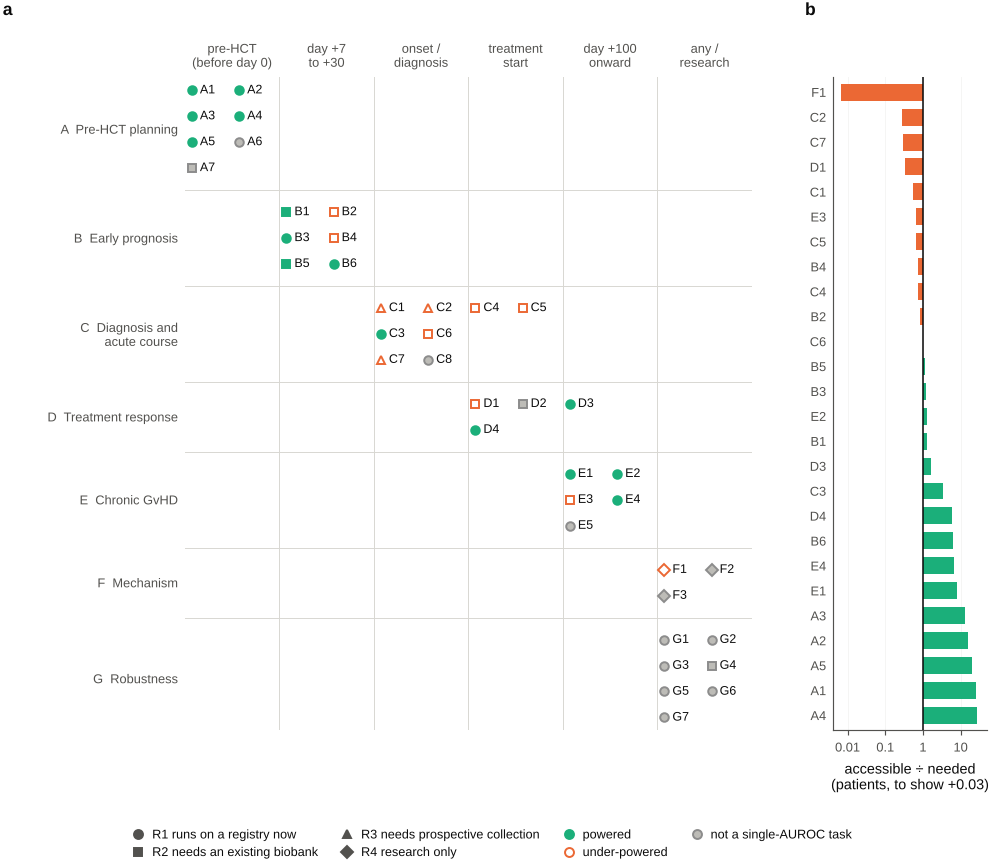

[saved] figures/Fig07_gvhd_bench_structure.pdf  +  figures/Fig07_gvhd_bench_structure.png


In [28]:
# ----------------------------------------------------------------------------- Figure 7: the shape of GvHD-Bench (a map of the tasks, and which ones the field can actually settle)
BINS = ['pre-HCT\n(before day 0)', 'day +7\nto +30', 'onset /\ndiagnosis', 'treatment\nstart', 'day +100\nonward', 'any /\nresearch']
FAMN = {'A': 'Pre-HCT planning', 'B': 'Early prognosis', 'C': 'Diagnosis and\nacute course', 'D': 'Treatment response',
        'E': 'Chronic GvHD', 'F': 'Mechanism', 'G': 'Robustness'}
def _bin(r):
    f = r.family[0]
    if f in 'FG': return 5
    if r.id in ('C4', 'C5', 'D1', 'D2', 'D4'): return 3
    if r.id in ('D3', 'E1', 'E2', 'E3', 'E4', 'E5'): return 4
    return {'A': 0, 'B': 1, 'C': 2}[f]
reg_full['bin'] = [_bin(r) for _, r in reg_full.iterrows()]
reg_full['fam'] = [r.family[0] for _, r in reg_full.iterrows()]
MARK = {'R1': 'o', 'R2': 's', 'R3': '^', 'R4': 'D'}
ROW, FPAD, SLOTS = .185, .13, 2                                             # inches per slot row; padding between families
fam_rows = {f: max(int(np.ceil(len(reg_full[(reg_full.fam == f) & (reg_full.bin == b)]) / SLOTS)) for b in range(6)) for f in FAMN}
Hin = sum(fam_rows.values()) * ROW + FPAD * (len(FAMN) - 1)
FWIN, FHIN = FULL, Hin + 1.50
fig = plt.figure(figsize=(FWIN, FHIN))
L1, W1, L2, W2 = 1.42, 4.05, 6.05, 1.10
axm = fig.add_axes([L1 / FWIN, .98 / FHIN, W1 / FWIN, Hin / FHIN]); axr = fig.add_axes([L2 / FWIN, .98 / FHIN, W2 / FWIN, Hin / FHIN])
axm.set_xlim(0, 6); axm.set_ylim(Hin, 0)
ymid, y0 = {}, 0.0
for f in FAMN:
    h = fam_rows[f] * ROW; ymid[f] = y0 + h / 2
    for b in range(6):
        sub = reg_full[(reg_full.fam == f) & (reg_full.bin == b)].sort_values('id')
        for k, (_, r) in enumerate(sub.iterrows()):
            x = b + .075 + (k % SLOTS) * .5; y = y0 + (k // SLOTS + .5) * ROW
            v = r.verdict
            kw = dict(mfc=PAL['aqua'], mec=PAL['aqua']) if v == 'POWERED' else (dict(mfc='none', mec=PAL['orange']) if v == 'UNDER-POWERED' else dict(mfc=PAL['grey2'], mec=PAL['grey']))
            axm.plot(x, y, MARK[r.readiness], ms=4.4, mew=1.0, **kw, zorder=3)
            axm.text(x + .085, y, r.id, fontsize=6.4, va='center', ha='left', color=PAL['ink'])
    y0 += h + FPAD
    if f != 'G': axm.axhline(y0 - FPAD / 2, color=PAL['grid'], lw=.5)
for b in range(1, 6): axm.axvline(b, color=PAL['grid'], lw=.5)
axm.set_yticks([ymid[f] for f in FAMN]); axm.set_yticklabels([f'{f}  {FAMN[f]}' for f in FAMN]); axm.tick_params(axis='y', length=0)
axm.xaxis.tick_top(); axm.set_xticks(np.arange(6) + .5); axm.set_xticklabels(BINS); axm.tick_params(axis='x', length=0)
for sp in ('left', 'bottom', 'right', 'top'): axm.spines[sp].set_visible(False)
axm.annotate('a', (0, 1), xycoords='axes fraction', xytext=(-1.3 * 72, 32), textcoords='offset points', fontsize=9, fontweight='bold')
# (b) accessible / needed, for the 26 tasks that have a numeric requirement
need = reg_full.dropna(subset=['n to show +0.03']).copy()
need['req'] = need[['n to develop (50-param)', 'n to show +0.03']].astype(float).max(axis=1)
need['ratio'] = need['n accessible (est.)'] / need['req']
need = need.sort_values('ratio').reset_index(drop=True)
axr.barh(np.arange(len(need)), need.ratio - 1, left=1, height=.68, zorder=3,
         color=[PAL['aqua'] if v == 'POWERED' else PAL['orange'] for v in need.verdict])
axr.set_xscale('log'); axr.set_xlim(max(need.ratio.min() * .6, 1e-3), need.ratio.max() * 1.8); axr.axvline(1, color=PAL['ink'], lw=.8, zorder=4)
axr.set_yticks(np.arange(len(need))); axr.set_yticklabels(need.id); axr.set_ylim(len(need) - .4, -.6)
_tk = [t for t in (.01, .1, 1, 10, 100) if axr.get_xlim()[0] <= t <= axr.get_xlim()[1]]
axr.set_xticks(_tk); axr.set_xticklabels([f'{t:g}' for t in _tk]); axr.minorticks_off()
axr.tick_params(axis='y', length=0); ygrid(axr, 'x')
axr.set_xlabel('accessible ÷ needed\n(patients, to show +0.03)')
axr.annotate('b', (0, 1), xycoords='axes fraction', xytext=(-.2 * 72, 32), textcoords='offset points', fontsize=9, fontweight='bold')
fig.legend([plt.Line2D([], [], marker=m, ls='none', ms=4.6, mfc=PAL['ink2'], mec=PAL['ink2']) for m in MARK.values()] +
           [plt.Line2D([], [], marker='o', ls='none', ms=4.6, mfc=PAL['aqua'], mec=PAL['aqua']),
            plt.Line2D([], [], marker='o', ls='none', ms=4.6, mfc='none', mec=PAL['orange'], mew=1.0),
            plt.Line2D([], [], marker='o', ls='none', ms=4.6, mfc=PAL['grey2'], mec=PAL['grey'])],
           ['R1 runs on a registry now', 'R2 needs an existing biobank', 'R3 needs prospective collection', 'R4 research only',
            'powered', 'under-powered', 'not a single-AUROC task'], ncol=4, loc='lower center', bbox_to_anchor=(.5, 0.0),
           columnspacing=1.5, handletextpad=.3, labelspacing=.45)
finish(fig, 7, 'gvhd_bench_structure',
       'GvHD-Bench v1.0. (a) The 40 tasks, grouped by family and by the landmark at which the prediction is made. Marker '
       'shape is data readiness and colour is the powered verdict; tasks that are not a single-AUROC comparison (donor ranking, '
       'counterfactual contrasts, representation and robustness audits) are grey. (b) For the 26 tasks with a numeric '
       'requirement: patients accessible divided by patients needed to demonstrate a +0.03 AUROC gain over the task '
       'baseline. Bars left of 1 are tasks the field cannot currently settle; they are labelled, not omitted.')

## 8.10 Claim ladder, with gates fixed in advance
| Level | What may be claimed | Requirements (all of them) |
|---|---|---|
| **0** | nothing | — |
| **1** | "more label-efficient than a tuned simple model" | equal or better at full labels, **and** better at k ≤ 100 labelled patients, paired across centres; beats its random-weight twin |
| **2** | "better discrimination out-of-centre" | ≥ 20 held-out centres; the **centre-level 95 % t-interval** of ΔIPCW-td-AUROC against the best simple model **and** against the clinical baseline has a **lower bound ≥ +0.01** (the design is powered for a true gain of +0.03; §8.12); improves in ≥ 70 % of held-out centres; survives BH correction across the task family; beats random-weight twin and no-pretraining |
| **3** | "clinically useful" | Level 2 **plus** calibration slope within 0.8–1.25 and positive net benefit across 10–40 % thresholds in leave-centre-out **and** temporal validation, at n ≥ the Riley minimum, with a prospective silent-mode evaluation and a decision-impact plan |
| **4** | "improves outcomes" | a prospective trial of the model-guided decision. Nothing short of this licenses the word *improves* |

**Pre-registration rule.** Gate thresholds, splits, seeds and the primary task are written to `spec/gate.json` before any model is run, and the file hash is reported with the results. The gate below is the one this specification proposes for the ALLO-FM v1 attempt. Its interval method, margin and minimum centre count are not arbitrary: §8.12 simulates the gate and shows that the obvious alternative (a point estimate of +0.03 and a percentile-bootstrap interval) passes a model whose true gain equals the threshold only about half the time and under-covers when centres are few.

In [29]:
# ----------------------------------------------------------------------------- the pre-stated gate for the ALLO-FM v1 attempt (written to spec/gate.json)
GATE = dict(
  version='ALLO-FM v1',
  primary_task='B1 — grade II–IV aGvHD by day +100 from the day +7 draw (issued day +9), leave-centre-out across >= 20 centres',
  primary_metric='IPCW time-dependent AUROC at day 100, competing risks = death and relapse',
  baselines_to_beat=['MAGIC MAP (ST2+REG3a day-7 algorithm) + clinical covariates',
                     'gradient-boosted trees on 20-40 registry variables (tuned, same splits)',
                     'random-weight twin of the backbone', 'no-pretraining (supervised only)'],
  level2_gate=dict(delta_auroc_designed_for=0.03, ci_method='centre-level t-interval, K-1 d.f. (not a percentile bootstrap)',
                   ci_lower_bound_min=0.01, fraction_centres_improved_min=0.70, min_centres=20,
                   beats_random_twin=True, beats_no_pretraining=True, bh_across_family=True,
                   rationale='interval method, margin and centre count are fixed by the operating characteristics computed in section 8.12'),
  level3_additional=dict(calibration_slope=[0.8, 1.25], net_benefit_positive_thresholds=[0.10, 0.40],
                         temporal_validation_required=True, min_n='computed per task by riley_n(P, target AUROC, prevalence) and validation_n (section 9.7)'),
  stopping_rule='if Level 1 is not reached on B1 at stage-1 scale, publish the negative result and do not proceed to stage 3',
  frozen=dict(seed=SEED, splits='spec/splits_*.json', label_functions='section 4.6 of this notebook'))
def level2_verdict(lo, frac, K):
    """Apply the Level-2 gate to a centre-level interval lower bound, fraction of centres improved, and centre count."""
    g = GATE['level2_gate']
    if K < g['min_centres']: return f'not evaluable (K={K} < {g["min_centres"]})'
    return 'PASS' if (lo >= g['ci_lower_bound_min'] and frac >= g['fraction_centres_improved_min']) else 'fail'
json.dump(GATE, open(os.path.join(SPEC_DIR, 'gate.json'), 'w'), indent=2)
import hashlib
h = hashlib.sha256(open(os.path.join(SPEC_DIR, 'gate.json'), 'rb').read()).hexdigest()[:16]
print(f'gate written to spec/gate.json  (sha256:{h})')
for k, v in GATE.items(): print(f'  {k:22s} {v if not isinstance(v, dict) else json.dumps(v)}'[:200])

gate written to spec/gate.json  (sha256:8daa2d82ea1fe044)
  version                ALLO-FM v1
  primary_task           B1 — grade II–IV aGvHD by day +100 from the day +7 draw (issued day +9), leave-centre-out across >= 20 centres
  primary_metric         IPCW time-dependent AUROC at day 100, competing risks = death and relapse
  baselines_to_beat      ['MAGIC MAP (ST2+REG3a day-7 algorithm) + clinical covariates', 'gradient-boosted trees on 20-40 registry variables (tuned, same splits)', 'random-weight twin of the backbone'
  level2_gate            {"delta_auroc_designed_for": 0.03, "ci_method": "centre-level t-interval, K-1 d.f. (not a percentile bootstrap)", "ci_lower_bound_min": 0.01, "fraction_centres_improved_min": 
  level3_additional      {"calibration_slope": [0.8, 1.25], "net_benefit_positive_thresholds": [0.1, 0.4], "temporal_validation_required": true, "min_n": "computed per task by riley_n(P, target AUROC,
  stopping_rule          if Level 1 is not reached on B1 at stage-1 

## 8.11 [SIM] The harness, executed end-to-end

To show the benchmark *runs*, we simulate a multi-centre cohort with the structure of a real registry extract: 24 centres, differing case mix and prophylaxis practice, competing risks (relapse and NRM), administrative censoring, a day-7 biomarker available in a subset, and — deliberately — **a planted leakage feature** (an early steroid order that follows the outcome). We then run task B1 through the harness: leave-centre-out, clinical baseline versus a timeline model, IPCW metrics, the leakage audit, calibration and net benefit.

This demonstrates the machinery and the audit. **It is not evidence about patients**: every effect size is one we chose.

In [30]:
# ----------------------------------------------------------------------------- [SIM] multi-centre registry-like cohort generator
def simulate_cohort(n=6000, n_centres=24, seed=3, leak=True, drift=0.0, presence_gamma=0.0):
    r = np.random.default_rng(seed)
    era = np.random.default_rng(seed + 1).integers(2014, 2024, n)       # own stream: adding drift leaves every other column unchanged
    centre = r.integers(0, n_centres, n)
    c_off = r.normal(0, .35, n_centres)                                  # centre-level risk offset (case mix + practice)
    c_ptcy = r.beta(2, 2, n_centres)                                     # centre-level PtCy adoption rate
    age = np.clip(r.normal(52, 14, n), 1, 78)
    donor_type = r.choice(['MSD', 'MUD 8/8', 'MMUD 7/8', 'haplo'], n, p=[.22, .42, .14, .22])
    hla_mm = np.select([donor_type == 'MSD', donor_type == 'MUD 8/8', donor_type == 'MMUD 7/8'], [0, 0, 1], default=2)
    source = np.where(r.random(n) < .78, 'PBSC', 'BM')
    fem_to_male = (r.random(n) < .18).astype(int)
    hctci = r.poisson(2.2, n); dri = r.choice([0, 1, 2, 3], n, p=[.18, .46, .26, .10])
    mac = (r.random(n) < .55).astype(int)
    ptcy = (r.random(n) < c_ptcy[centre]).astype(int)
    atg = ((1 - ptcy) * (r.random(n) < .25)).astype(int)
    cd34 = np.clip(r.normal(6.2, 2.1, n), 1, 15)
    # day-7 state (Tier B/C): CRP, ALC, tacrolimus trough, and the MAGIC-like biomarker (measured in 55%)
    base = (-1.15 + .55 * hla_mm + .30 * fem_to_male + .22 * mac + .10 * (source == 'PBSC')
            + .11 * dri * .3 + .018 * (age - 52) / 10 - .62 * ptcy - .25 * atg + c_off[centre] + drift * (era - 2014))
    lat = base + r.normal(0, .55, n)                                      # latent alloreactivity
    crp7 = np.exp(np.clip(1.9 + .55 * lat + r.normal(0, .55, n), -2, 6))
    alc7 = np.exp(np.clip(-1.4 - .25 * lat + r.normal(0, .5, n), -5, 3))
    tac7 = np.clip(r.normal(9.5 - .6 * lat, 2.6, n), 1, 22)
    st2 = np.exp(np.clip(3.3 + .62 * lat + r.normal(0, .5, n), 0, 9))
    reg3a = np.exp(np.clip(3.0 + .70 * lat + r.normal(0, .6, n), 0, 9))
    u_meas = r.random(n)
    zl = (lat - lat.mean()) / lat.std()          # presence_gamma > 0: clinicians order the biomarker more often when they suspect GvHD
    measured = u_meas < 1 / (1 + np.exp(-(math.log(.55 / .45) + presence_gamma * zl)))
    p_ag = 1 / (1 + np.exp(-(lat + .45 * np.log(st2 / 27) + .40 * np.log(reg3a / 20) - .15)))
    agvhd = (r.random(n) < p_ag).astype(int)
    t_ag = np.clip(r.gamma(3.2, 9, n) + 10, 8, 170)
    t_rel = np.exp(np.clip(5.6 - .35 * dri + r.normal(0, .8, n), 2, 9))
    t_nrm = np.exp(np.clip(6.1 - .20 * hctci - .5 * agvhd * p_ag + r.normal(0, .9, n), 2, 9))
    t_cens = np.clip(r.uniform(90, 1200, n), 30, 1200)
    T = np.vstack([np.where(agvhd == 1, t_ag, 1e6), t_rel, t_nrm, t_cens])
    which = T.argmin(0); time = T.min(0)
    cause = np.where(which == 0, 1, np.where(which == 1, 2, np.where(which == 2, 3, 0)))   # 1 aGvHD, 2 relapse, 3 NRM, 0 censored
    # the planted leak: an "early steroid order" recorded at day +5 that is really driven by the outcome
    steroid_d5 = ((cause == 1) & (time <= 100)).astype(int) * (r.random(n) < .8) + (r.random(n) < .03)
    df = pd.DataFrame(dict(pid=np.arange(n), centre=centre, era=era, age=age, donor_type=donor_type,
                           hla_mm=hla_mm, source=source, fem_to_male=fem_to_male, hctci=hctci, dri=dri, mac=mac,
                           ptcy=ptcy, atg=atg, cd34=cd34, crp7=crp7, alc7=alc7, tac7=tac7,
                           st2=np.where(measured, st2, np.nan), reg3a=np.where(measured, reg3a, np.nan),
                           biomarker_measured=measured.astype(int), time=time, cause=cause,
                           _latent_event=((agvhd == 1) & (t_ag <= 100)).astype(int)))   # oracle column for planted-effect tests; never a feature
    if leak: df['steroid_order_d5'] = steroid_d5.astype(int)
    return df

LANDMARK = 9                                            # task B1: day-7 draw, 48-hour turnaround, prediction issued on day +9
COH_ALL = simulate_cohort()
keep_ = (COH_ALL.time > LANDMARK).values
attr = pd.DataFrame([
    ('patients in the cohort (day 0 recorded)', len(COH_ALL)),
    (f'  died without relapse before day +{LANDMARK}', int(((COH_ALL.cause == 3) & ~keep_).sum())),
    (f'  relapsed before day +{LANDMARK}', int(((COH_ALL.cause == 2) & ~keep_).sum())),
    (f'  censored before day +{LANDMARK}', int(((COH_ALL.cause == 0) & ~keep_).sum())),
    (f'  already had grade II-IV aGvHD before day +{LANDMARK}', int(((COH_ALL.cause == 1) & ~keep_).sum())),
    ('meeting landmark eligibility (analysed)', int(keep_.sum())),
    ('  of whom with the day-7 biomarker panel', int(COH_ALL.loc[keep_, 'biomarker_measured'].sum()))], columns=['attrition step', 'patients'])
print('MANDATORY ATTRITION TABLE (§8.1):'); display(md_table(attr))
COH = COH_ALL[keep_].reset_index(drop=True)
inc100 = aalen_johansen(COH.time.values, COH.cause.values, 100, 1)
print(f'[SIM] cohort: {len(COH)} patients, {COH.centre.nunique()} centres | '
      f'Aalen-Johansen incidence of grade II-IV aGvHD by d+100, given alive and event-free at the landmark = {inc100:.3f}')
print('cause distribution (0 censored, 1 aGvHD, 2 relapse, 3 NRM):', dict(COH.cause.value_counts().sort_index()))
display(md_table(COH.groupby(COH.centre).agg(n=('pid', 'count'), ptcy_rate=('ptcy', 'mean'),
        aGvHD_by_d100=('cause', lambda s: float(((COH.loc[s.index, 'cause'] == 1) & (COH.loc[s.index, 'time'] <= 100)).mean()))).round(3).head(8), index=True))

MANDATORY ATTRITION TABLE (§8.1):


| attrition step | patients |
|---|---|
| patients in the cohort (day 0 recorded) | 6000 |
|   died without relapse before day +9 | 0 |
|   relapsed before day +9 | 3 |
|   censored before day +9 | 0 |
|   already had grade II-IV aGvHD before day +9 | 0 |
| meeting landmark eligibility (analysed) | 5997 |
|   of whom with the day-7 biomarker panel | 3295 |

[SIM] cohort: 5997 patients, 24 centres | Aalen-Johansen incidence of grade II-IV aGvHD by d+100, given alive and event-free at the landmark = 0.216
cause distribution (0 censored, 1 aGvHD, 2 relapse, 3 NRM): {0: np.int64(359), 1: np.int64(1299), 2: np.int64(2811), 3: np.int64(1528)}


| centre | n | ptcy_rate | aGvHD_by_d100 |
|---|---|---|---|
| 0 | 269 | 0.714 | 0.279 |
| 1 | 270 | 0.248 | 0.304 |
| 2 | 247 | 0.66 | 0.126 |
| 3 | 245 | 0.494 | 0.171 |
| 4 | 267 | 0.438 | 0.322 |
| 5 | 251 | 0.649 | 0.247 |
| 6 | 234 | 0.726 | 0.12 |
| 7 | 265 | 0.234 | 0.091 |

In [31]:
# ----------------------------------------------------------------------------- the leakage audit, as code (run on the [SIM] cohort for task B1, issued on day +9)
BANNED_PREFIXES = ('steroid', 'ruxolitinib', 'ecp_', 'budesonide', 'biopsy_order', 'infliximab')
PLAUSIBLE_SINGLE_FEATURE_AUROC = .80      # no single day-7 variable has been reported to discriminate aGvHD better than ~0.75; above 0.80 is a red flag
def leakage_audit(df, feature_cols, landmark, t_known_map, group_col='pid', centre_col='centre',
                  outcome=lambda d: ((d.cause == 1) & (d.time <= 100)).astype(int), folds=None):
    """Runs the §4.7 checks and returns a findings table. t_known_map: {feature: day the value becomes known}."""
    y = outcome(df).values; out = []
    banned = [c for c in feature_cols if c.lower().startswith(BANNED_PREFIXES)]
    out.append(dict(check='treatment-proxy features present in the input set', finding=', '.join(banned) or 'none', status='FAIL' if banned else 'pass'))
    late = [c for c in feature_cols if t_known_map.get(c, -np.inf) > landmark]
    out.append(dict(check=f't_known > landmark ({landmark:+g}d)', finding=', '.join(late) or 'none', status='FAIL' if late else 'pass'))
    dup = int(df[group_col].duplicated().sum())
    out.append(dict(check='duplicate patient records', finding=f'{dup} duplicated ids', status='FAIL' if dup else 'pass'))
    if folds is not None:
        bleed = sum(len(set(df[group_col].values[tr]) & set(df[group_col].values[te])) for tr, te in folds)
        cbleed = sum(len(set(df[centre_col].values[tr]) & set(df[centre_col].values[te])) for tr, te in folds)
        out.append(dict(check='patient overlap between train and test folds', finding=f'{bleed} patients', status='FAIL' if bleed else 'pass'))
        out.append(dict(check='centre appears on both sides (leave-centre-out claim)', finding=f'{cbleed} centres', status='FAIL' if cbleed else 'pass'))
    ce = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(pd.get_dummies(df[centre_col].astype(str)).values, y)
    a_centre = auroc(y, ce.decision_function(pd.get_dummies(df[centre_col].astype(str)).values))
    out.append(dict(check='centre-ID-only model AUROC (case-mix/practice confounding)', finding=f'{a_centre:.3f}',
                    status='WARN' if a_centre > .6 else 'pass'))
    for c in [c for c in feature_cols if c in df.columns and df[c].notna().sum() > 50 and np.issubdtype(df[c].dtype, np.number)]:
        a = auroc(y[df[c].notna().values], df[c].dropna().values)
        if a == a and (a > PLAUSIBLE_SINGLE_FEATURE_AUROC or a < 1 - PLAUSIBLE_SINGLE_FEATURE_AUROC):
            out.append(dict(check=f'single feature with implausible AUROC: {c}', finding=f'{a:.3f}', status='FAIL'))
    return pd.DataFrame(out)

CLIN = ['age', 'hla_mm', 'fem_to_male', 'hctci', 'dri', 'mac', 'ptcy', 'atg', 'cd34']
D7 = ['crp7', 'alc7', 'tac7']
BIO = ['st2', 'reg3a']
T_KNOWN = {**{c: -7 for c in CLIN}, **{c: 7 for c in D7}, 'st2': 9, 'reg3a': 9, 'steroid_order_d5': 5, 'biomarker_measured': 9}
audit_bad = leakage_audit(COH, CLIN + D7 + BIO + ['biomarker_measured', 'steroid_order_d5'], landmark=LANDMARK, t_known_map=T_KNOWN)
print('AUDIT — candidate input set that includes the planted leak:')
display(md_table(audit_bad))
audit_good = leakage_audit(COH, CLIN + D7 + BIO + ['biomarker_measured'], landmark=LANDMARK, t_known_map=T_KNOWN)
print('AUDIT — the cleaned input set actually used for B1 (prediction issued on day +9):')
display(md_table(audit_good))

AUDIT — candidate input set that includes the planted leak:


| check | finding | status |
|---|---|---|
| treatment-proxy features present in the input set | steroid_order_d5 | FAIL |
| t_known > landmark (+9d) | none | pass |
| duplicate patient records | 0 duplicated ids | pass |
| centre-ID-only model AUROC (case-mix/practice confounding) | 0.640 | WARN |
| single feature with implausible AUROC: steroid_order_d5 | 0.899 | FAIL |

AUDIT — the cleaned input set actually used for B1 (prediction issued on day +9):


| check | finding | status |
|---|---|---|
| treatment-proxy features present in the input set | none | pass |
| t_known > landmark (+9d) | none | pass |
| duplicate patient records | 0 duplicated ids | pass |
| centre-ID-only model AUROC (case-mix/practice confounding) | 0.640 | WARN |

In [32]:
# ----------------------------------------------------------------------------- [SIM] run task B1 through the harness: leave-centre-out, 6 arms, IPCW metrics
def prep(df, cols):
    X = df[cols].copy()
    for c in cols:
        if X[c].dtype == object: X[c] = pd.factorize(X[c])[0]
    med = X.median(); X = X.fillna(med)
    for c in ('st2', 'reg3a', 'crp7', 'alc7'):
        if c in X.columns: X[c] = np.log(np.clip(X[c], 1e-3, None))
    return X.values.astype(float)

def y_b1(df): return ((df.cause == 1) & (df.time <= 100)).astype(int).values

ARMS = {
 'clinical baseline (registry covariates)':      CLIN,
 'clinical + MAP-like biomarkers':               CLIN + BIO + ['biomarker_measured'],
 'timeline model (clinical + day-7 state)':      CLIN + D7,
 'full (clinical + day-7 + biomarkers)':         CLIN + D7 + BIO + ['biomarker_measured'],
 'confounder-only (centre + era)':               ['centre', 'era'],
 'LEAKING pipeline (adds steroid order d+5)':    CLIN + D7 + BIO + ['steroid_order_d5'],
}
centres = sorted(COH.centre.unique())
held = centres if not QUICK else centres[:8]
rows = []
for arm, cols in ARMS.items():
    X = prep(COH, cols); y = y_b1(COH)
    for c in held:
        tr, te = (COH.centre != c).values, (COH.centre == c).values
        if y[tr].sum() < 10 or te.sum() < 40: continue
        m = make_pipeline(StandardScaler(), LogisticRegression(C=.1, max_iter=3000, class_weight='balanced')).fit(X[tr], y[tr])
        s = m.decision_function(X[te]); p = m.predict_proba(X[te])[:, 1]
        rows.append(dict(arm=arm, centre=c, n=int(te.sum()),
                         ipcw_auroc=ipcw_td_auroc(COH.time.values[te], COH.cause.values[te], s, 100),
                         naive_auroc=auroc(y[te], s), brier=float(np.mean((p - y[te]) ** 2))))
LCO = pd.DataFrame(rows)
summ = LCO.groupby('arm').agg(centres=('centre', 'count'), mean_ipcw_auroc=('ipcw_auroc', 'mean'),
                              sd_across_centres=('ipcw_auroc', 'std'), min_centre=('ipcw_auroc', 'min'),
                              max_centre=('ipcw_auroc', 'max'), mean_brier=('brier', 'mean')).round(3)
summ = summ.reindex(list(ARMS)); display(md_table(summ, index=True))

from scipy.stats import t as student_t
def centre_interval(d, level=.95):
    """Centre-level t-interval for the mean paired difference across K held-out centres (K-1 d.f.): the gate's interval."""
    d = np.asarray(d, float); K = len(d); m = d.mean(); se = d.std(ddof=1) / math.sqrt(K); q = student_t.ppf(1 - (1 - level) / 2, K - 1)
    return float(m), float(m - q * se), float(m + q * se)
def boot_delta(a, b, n=4000, seed=0):
    """Percentile bootstrap over centres, kept for comparison: section 8.12 shows it under-covers when centres are few."""
    d = np.asarray(a) - np.asarray(b); r = np.random.default_rng(seed)
    bs = np.array([d[r.integers(0, len(d), len(d))].mean() for _ in range(n)])
    return float(np.quantile(bs, .025)), float(np.quantile(bs, .975))
piv = LCO.pivot_table(index='centre', columns='arm', values='ipcw_auroc')
base = 'clinical baseline (registry covariates)'
def _row(a):
    m, lo, hi = centre_interval(piv[a].values - piv[base].values); bl, bh = boot_delta(piv[a], piv[base]); frac = float((piv[a] > piv[base]).mean())
    return dict(arm=a, delta_vs_clinical=m, lo=lo, hi=hi, boot_lo=bl, boot_hi=bh, centres_improved=f"{int((piv[a] > piv[base]).sum())}/{len(piv)}",
                level2_gate='excluded: leakage audit FAIL' if 'LEAKING' in a else level2_verdict(lo, frac, len(piv)))
delta = pd.DataFrame([_row(a) for a in piv.columns if a != base]).round(3)
display(md_table(delta))

| arm | centres | mean_ipcw_auroc | sd_across_centres | min_centre | max_centre | mean_brier |
|---|---|---|---|---|---|---|
| clinical baseline (registry covariates) | 24 | 0.688 | 0.05 | 0.553 | 0.768 | 0.226 |
| clinical + MAP-like biomarkers | 24 | 0.728 | 0.049 | 0.618 | 0.832 | 0.21 |
| timeline model (clinical + day-7 state) | 24 | 0.717 | 0.045 | 0.626 | 0.793 | 0.209 |
| full (clinical + day-7 + biomarkers) | 24 | 0.743 | 0.051 | 0.639 | 0.835 | 0.2 |
| confounder-only (centre + era) | 24 | 0.505 | 0.043 | 0.411 | 0.61 | 0.25 |
| LEAKING pipeline (adds steroid order d+5) | 24 | 0.945 | 0.024 | 0.891 | 0.987 | 0.066 |

| arm | delta_vs_clinical | lo | hi | boot_lo | boot_hi | centres_improved | level2_gate |
|---|---|---|---|---|---|---|---|
| LEAKING pipeline (adds steroid order d+5) | 0.256 | 0.235 | 0.278 | 0.236 | 0.275 | 24/24 | excluded: leakage audit FAIL |
| clinical + MAP-like biomarkers | 0.039 | 0.025 | 0.053 | 0.026 | 0.052 | 21/24 | PASS |
| confounder-only (centre + era) | -0.183 | -0.214 | -0.152 | -0.212 | -0.154 | 0/24 | fail |
| full (clinical + day-7 + biomarkers) | 0.055 | 0.038 | 0.072 | 0.039 | 0.071 | 22/24 | PASS |
| timeline model (clinical + day-7 state) | 0.029 | 0.015 | 0.043 | 0.016 | 0.041 | 19/24 | PASS |

[layout PASS] Fig 8: 72 text items, 0 collisions, 0 below 6 pt (smallest 6.4 pt)


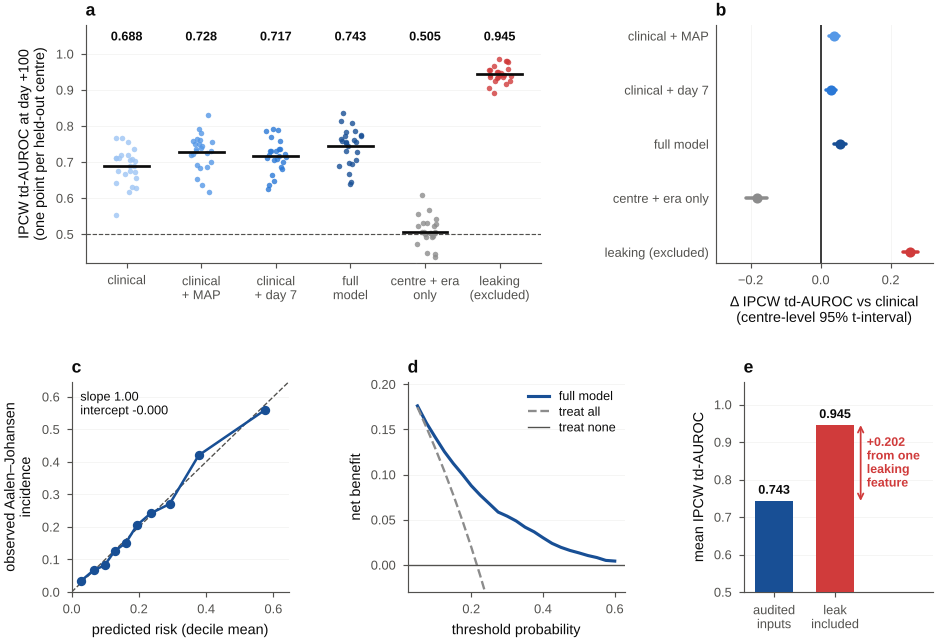

[saved] figures/Fig08_harness_task_B1.pdf  +  figures/Fig08_harness_task_B1.png


| decile | predicted | observed_AJ | n |
|---|---|---|---|
| 0 | 0.029 | 0.035 | 600 |
| 1 | 0.065 | 0.067 | 600 |
| 2 | 0.098 | 0.082 | 599 |
| 3 | 0.128 | 0.127 | 600 |
| 4 | 0.161 | 0.15 | 600 |
| 5 | 0.194 | 0.205 | 599 |
| 6 | 0.235 | 0.242 | 600 |
| 7 | 0.291 | 0.27 | 599 |
| 8 | 0.378 | 0.42 | 600 |
| 9 | 0.576 | 0.56 | 600 |

In [33]:
# ----------------------------------------------------------------------------- out-of-centre predictions of the full arm -> calibration and decision curve
X_full = prep(COH, ARMS['full (clinical + day-7 + biomarkers)']); y_full = y_b1(COH)
P = np.full(len(COH), np.nan)
for c in centres:
    tr, te = (COH.centre != c).values, (COH.centre == c).values
    m = make_pipeline(StandardScaler(), LogisticRegression(C=.1, max_iter=3000)).fit(X_full[tr], y_full[tr])
    P[te] = m.predict_proba(X_full[te])[:, 1]
dec = pd.qcut(P, 10, labels=False, duplicates='drop')
cal = pd.DataFrame([dict(decile=int(d), predicted=P[dec == d].mean(),
                         observed_AJ=aalen_johansen(COH.time.values[dec == d], COH.cause.values[dec == d], 100, 1),
                         n=int((dec == d).sum())) for d in sorted(set(dec[~pd.isna(dec)]))])
slope = np.polyfit(cal.predicted, cal.observed_AJ, 1)
nbc = net_benefit(y_full, P, np.linspace(.05, .6, 23))

# ----------------------------------------------------------------------------- Figure 8: the harness executing task B1 on the [SIM] cohort
ARM_STYLE = {   # key -> (colour, two-line axis label, one-line label)
 'clinical baseline (registry covariates)':   (PAL['seq'][0], 'clinical',            'clinical'),
 'clinical + MAP-like biomarkers':            (PAL['seq'][1], 'clinical\n+ MAP',      'clinical + MAP'),
 'timeline model (clinical + day-7 state)':   (PAL['seq'][2], 'clinical\n+ day 7',    'clinical + day 7'),
 'full (clinical + day-7 + biomarkers)':      (PAL['seq'][3], 'full\nmodel',          'full model'),
 'confounder-only (centre + era)':            (PAL['grey'],   'centre + era\nonly',   'centre + era only'),
 'LEAKING pipeline (adds steroid order d+5)': (PAL['bad'],    'leaking\n(excluded)',  'leaking (excluded)'),
}
order = [a for a in ARM_STYLE if a in piv.columns]
FWIN, FHIN = FULL, 5.0
fig = plt.figure(figsize=(FWIN, FHIN))
def A(l, b, w, h): return fig.add_axes([l / FWIN, b / FHIN, w / FWIN, h / FHIN])
axa = A(1.05, 2.95, 3.25, 1.70); axb = A(5.55, 2.95, 1.55, 1.70)
axc = A(0.95, 0.60, 1.55, 1.50); axd = A(3.35, 0.60, 1.55, 1.50); axe = A(5.75, 0.60, 1.35, 1.50)
ax = axa; ygrid(ax)                                                    # (a) per-centre spread
for i, a in enumerate(order):
    c = ARM_STYLE[a][0]; v = piv[a].dropna().values
    ax.scatter(np.full(len(v), i) + np.random.default_rng(i).uniform(-.15, .15, len(v)), v, s=8, color=c, alpha=.8, lw=0, zorder=3)
    ax.plot([i - .30, i + .30], [v.mean()] * 2, color=PAL['ink'], lw=1.4, zorder=4)
    ax.text(i, 1.03, f'{v.mean():.3f}', ha='center', va='bottom', fontsize=6.5, fontweight='bold')
ax.axhline(.5, color=PAL['ink2'], ls='--', lw=.6)
ax.set_xticks(range(len(order))); ax.set_xticklabels([ARM_STYLE[a][1] for a in order]); ax.set_xlim(-.55, len(order) - .45)
ax.set_ylim(.42, 1.08); ax.set_yticks([.5, .6, .7, .8, .9, 1.0]); ax.set_ylabel('IPCW td-AUROC at day +100\n(one point per held-out centre)'); panel(ax, 'a')
ax = axb; ygrid(ax, 'x')                                               # (b) difference from the clinical baseline
dd_ = delta.set_index('arm').reindex([a for a in order if a in delta.arm.values]); ypos = np.arange(len(dd_))
for y, (a, r) in zip(ypos, dd_.iterrows()):
    c = ARM_STYLE[a][0]; ax.plot([r.lo, r.hi], [y, y], color=c, lw=1.8, solid_capstyle='round'); ax.plot(r.delta_vs_clinical, y, 'o', color=c, ms=4.2, zorder=4)
ax.axvline(0, color=PAL['ink'], lw=.8)
ax.set_yticks(ypos); ax.set_yticklabels([ARM_STYLE[a][2] for a in dd_.index]); ax.invert_yaxis(); ax.tick_params(axis='y', length=0)
ax.set_xlim(-.30, .32); ax.set_xlabel('Δ IPCW td-AUROC vs clinical\n(centre-level 95% t-interval)'); panel(ax, 'b')
ax = axc; ygrid(ax)                                                    # (c) calibration against Aalen-Johansen
mx = float(max(cal.predicted.max(), cal.observed_AJ.max())) * 1.12
ax.plot([0, mx], [0, mx], color=PAL['ink2'], ls='--', lw=.7)
ax.plot(cal.predicted, cal.observed_AJ, 'o-', color=PAL['seq'][3], ms=3.8, lw=1.3, zorder=3)
ax.set_xlabel('predicted risk (decile mean)'); ax.set_ylabel('observed Aalen–Johansen\nincidence'); ax.set_xlim(0, mx); ax.set_ylim(0, mx)
ax.text(.04, .96, f'slope {slope[0]:.2f}\nintercept {slope[1]:+.3f}', transform=ax.transAxes, fontsize=6.5, va='top'); panel(ax, 'c')
ax = axd; ygrid(ax)                                                    # (d) decision curve
ax.plot(nbc.threshold, nbc.model, color=PAL['seq'][3], lw=1.6, label='full model')
ax.plot(nbc.threshold, nbc.treat_all, color=PAL['grey'], lw=1.2, ls='--', label='treat all')
ax.axhline(0, color=PAL['ink2'], lw=.7, label='treat none')
ax.set_xlabel('threshold probability'); ax.set_ylabel('net benefit')
ax.set_ylim(min(-.03, nbc.model.min() * 1.1), max(.02, nbc.model.max() * 1.15)); ax.legend(loc='upper right', labelspacing=.3); panel(ax, 'd')
ax = axe; ygrid(ax)                                                    # (e) the leakage canary
lk = ['full (clinical + day-7 + biomarkers)', 'LEAKING pipeline (adds steroid order d+5)']; vals = [summ.loc[a, 'mean_ipcw_auroc'] for a in lk]
ax.bar([0, 1], vals, color=[ARM_STYLE[a][0] for a in lk], width=.62, zorder=3)
for i, v in enumerate(vals): ax.text(i, v + .012, f'{v:.3f}', ha='center', va='bottom', fontsize=6.5, fontweight='bold')
ax.annotate('', xy=(1.42, vals[1]), xytext=(1.42, vals[0]), arrowprops=dict(arrowstyle='<->', color=PAL['bad'], lw=.9, shrinkA=0, shrinkB=0))
ax.text(1.52, (vals[0] + vals[1]) / 2, f'+{vals[1] - vals[0]:.3f}\nfrom one\nleaking\nfeature', fontsize=6.4, color=PAL['bad'], va='center', ha='left', fontweight='bold')
ax.set_xticks([0, 1]); ax.set_xticklabels(['audited\ninputs', 'leak\nincluded']); ax.set_xlim(-.5, 2.6)
ax.set_ylabel('mean IPCW td-AUROC'); ax.set_ylim(.5, 1.06); panel(ax, 'e')
finish(fig, 8, 'harness_task_B1',
       '[SIM] The GvHD-Bench harness executing task B1 (grade II-IV aGvHD by day +100 from the day +7 state) on a simulated '
       '24-centre cohort. (a) Leave-centre-out IPCW time-dependent AUROC, one point per held-out centre, with the mean '
       'printed above; the pooled mean alone would hide this spread. (b) Difference from the clinical baseline with a '
       'centre-level t-interval. (c) Calibration against the Aalen-Johansen cumulative incidence, the competing-risk '
       'analogue of a calibration plot. (d) Decision-curve net benefit. (e) The leakage canary: one planted treatment-proxy '
       'feature inflates the headline number, and the audit flags it before any model is fitted. Effect sizes belong to the simulation.')
display(md_table(cal.round(3)))

In [34]:
g = lambda a: summ.loc[a, 'mean_ipcw_auroc']
leak_gain = g('LEAKING pipeline (adds steroid order d+5)') - g('full (clinical + day-7 + biomarkers)')
d_full = delta.set_index('arm').loc['full (clinical + day-7 + biomarkers)']
fail_rows = audit_bad[audit_bad.status == 'FAIL']; n_fail = len(fail_rows)
fail_list = '; '.join(f"{r.check}: {r.finding}" for r in fail_rows.itertuples())
nb_pos = float(nbc.threshold[(nbc.model > nbc.treat_all) & (nbc.model > 0)].min()) if ((nbc.model > nbc.treat_all) & (nbc.model > 0)).any() else float('nan')
display(Markdown(f"""**Result [SIM].** The harness runs. Mean IPCW td-AUROC over held-out centres: clinical baseline **{g('clinical baseline (registry covariates)'):.3f}**, clinical + MAP-like biomarkers **{g('clinical + MAP-like biomarkers'):.3f}**, clinical + day-7 state **{g('timeline model (clinical + day-7 state)'):.3f}**, full **{g('full (clinical + day-7 + biomarkers)'):.3f}** (Δ vs clinical **{d_full.delta_vs_clinical:+.3f}**, centre-level 95 % t-interval [{d_full.lo:+.3f}, {d_full.hi:+.3f}], improved in {d_full.centres_improved} centres; Level-2 gate: **{d_full.level2_gate}**). Confounder-only (centre + era) reaches **{g('confounder-only (centre + era)'):.3f}**, which is the number any real result must be read against.

**The leakage canary worked.** Adding the planted day +5 steroid order lifts the mean to **{g('LEAKING pipeline (adds steroid order d+5)'):.3f}** ({leak_gain:+.3f}), and the audit failed that input set on **{n_fail} counts before any model was fitted** ({fail_list}). **A gain of this size is exactly what a leaking pipeline produces**, which is why the audit runs first and is reported alongside the result.

Calibration out-of-centre has slope {slope[0]:.2f} against the Aalen–Johansen incidence, and the decision curve is above both default strategies from a threshold of about {nb_pos:.2f}. All of these numbers are properties of a cohort we generated; their only purpose is to show that the metrics, splits, audit and gate logic execute and behave as specified."""))

**Result [SIM].** The harness runs. Mean IPCW td-AUROC over held-out centres: clinical baseline **0.688**, clinical + MAP-like biomarkers **0.728**, clinical + day-7 state **0.717**, full **0.743** (Δ vs clinical **+0.055**, centre-level 95 % t-interval [+0.038, +0.072], improved in 22/24 centres; Level-2 gate: **PASS**). Confounder-only (centre + era) reaches **0.505**, which is the number any real result must be read against.

**The leakage canary worked.** Adding the planted day +5 steroid order lifts the mean to **0.945** (+0.202), and the audit failed that input set on **2 counts before any model was fitted** (treatment-proxy features present in the input set: steroid_order_d5; single feature with implausible AUROC: steroid_order_d5: 0.899). **A gain of this size is exactly what a leaking pipeline produces**, which is why the audit runs first and is reported alongside the result.

Calibration out-of-centre has slope 1.00 against the Aalen–Johansen incidence, and the decision curve is above both default strategies from a threshold of about 0.05. All of these numbers are properties of a cohort we generated; their only purpose is to show that the metrics, splits, audit and gate logic execute and behave as specified.

## 8.12 [SIM] Does the benchmark itself work? Its own operating characteristics

A benchmark makes claims about models, and it should be validated with the rigour it demands of them. Four questions a sceptical reviewer will ask — each answered below by simulation or by running the real harness code of §8.11 on cohorts where the truth is planted:

1. **Coverage.** Does the interval the gate relies on contain the truth 95 % of the time? (A percentile bootstrap over centres is the common choice. With 8–20 centres it is not safe.)
2. **False passes and power.** What is the probability that a model with *no* gain, or a trivial gain, passes the gate, and that a model with the designed-for gain does?
3. **Recovery.** If we plant an effect of known size, does the harness recover it, and does it report nothing when the planted effect is zero? Does a permuted outcome produce a null result?
4. **Shortcuts that look like signal.** Can a model score above chance by exploiting *whether* a test was ordered rather than what it showed?

**Setup for the gate simulation.** Each of *K* centres contributes a paired AUROC difference between candidate and baseline. That difference has three sources of variation: the true gain Δ, a **between-centre SD τ** of the gain (centres differ in case mix and practice; τ = 0.02 is our planning value and §9.6 varies it), and the **sampling noise of a paired AUROC difference at that centre's sample size** (computed from the closed form of §9.1 at baseline AUROC 0.70, score correlation 0.85, prevalence 0.35; centre sizes vary log-normally around a median of 300). We compare two gates. The **obvious** one: point estimate ≥ +0.03, percentile-bootstrap lower bound > 0, ≥ 70 % of centres improved. The **adopted** one (`spec/gate.json`): centre-level *t*-interval lower bound ≥ +0.01, ≥ 70 % of centres improved, at least 20 centres.

In [35]:
# ----------------------------------------------------------------------------- [SIM] operating characteristics of the benchmark's own gate
def gate_oc(K, nc, d_true, tau=.02, reps=2000, B=300, seed=0, prev=.35, A1=.70, rho=.85, nc_cv=.5):
    """Simulate `reps` benchmark runs with K centres; return the interval coverage and the pass probability of both gates."""
    r = np.random.default_rng(seed); g = GATE['level2_gate']
    se_unit = se_delta(1, prev, A1, A1 + d_true, rho)                       # SE of a paired AUROC difference at n = 1 (scales as 1/sqrt(n))
    n_c = np.maximum((nc * np.exp(r.normal(0, nc_cv, (reps, K)) - nc_cv ** 2 / 2)).astype(int), 60)
    dh = d_true + r.normal(0, tau, (reps, K)) + r.standard_normal((reps, K)) * se_unit / np.sqrt(n_c)    # observed per-centre gains
    m = dh.mean(1); s = dh.std(1, ddof=1) / math.sqrt(K); tq = student_t.ppf(.975, K - 1)
    lo_t, hi_t = m - tq * s, m + tq * s; frac = (dh > 0).mean(1)
    lo_b = np.empty(reps); hi_b = np.empty(reps)
    for a in range(0, reps, 200):                                           # percentile bootstrap over centres, in chunks to bound memory
        sl = slice(a, min(a + 200, reps)); idx = r.integers(0, K, (sl.stop - sl.start, B, K))
        bm = np.take_along_axis(dh[sl][:, None, :], idx, axis=2).mean(2); lo_b[sl], hi_b[sl] = np.quantile(bm, [.025, .975], axis=1)
    return dict(K=K, nc=nc, tau=tau, d_true=d_true,
                cov_t=float(((lo_t <= d_true) & (d_true <= hi_t)).mean()), cov_boot=float(((lo_b <= d_true) & (d_true <= hi_b)).mean()),
                pass_obvious=float(((m >= .03) & (lo_b > 0) & (frac >= .70)).mean()),
                pass_adopted=float(((lo_t >= g['ci_lower_bound_min']) & (frac >= g['fraction_centres_improved_min'])).mean()))
OC_REPS = 2000 if not QUICK else 600
KS_OC, DS_OC = (8, 12, 20, 30, 50), (0., .01, .02, .03, .04, .05, .06)
oc = pd.DataFrame([gate_oc(K, 300, d, reps=OC_REPS, seed=11 * K + int(1000 * d)) for K in KS_OC for d in DS_OC])
cov = oc[oc.d_true == .03].set_index('K')[['cov_boot', 'cov_t']].round(3)
cov.columns = ['percentile bootstrap over centres', 'centre-level t-interval']
print('Coverage of the nominal 95 % interval for the true gain (Δ = 0.03, τ = 0.02, median 300 patients per centre):'); display(md_table(cov, index=True))
tab = lambda col: oc.pivot(index='K', columns='d_true', values=col).round(2).rename(columns=lambda d: f'Δ={d:g}')
print('Probability of passing the OBVIOUS gate (point estimate ≥ 0.03, bootstrap lower bound > 0, ≥ 70 % of centres improved):'); display(md_table(tab('pass_obvious'), index=True))
print('Probability of passing the ADOPTED gate (t-interval lower bound ≥ 0.01, ≥ 70 % of centres improved; evaluable only for K ≥ 20):'); display(md_table(tab('pass_adopted'), index=True))
# sensitivity of the adopted gate's power to how heterogeneous centres are and how large they are
sens_oc = pd.DataFrame([dict(tau=tau, **{f'median n per centre = {nc}': gate_oc(20, nc, .03, tau=tau, reps=OC_REPS // 2, seed=5)['pass_adopted'] for nc in (150, 300, 600)}) for tau in (.01, .02, .04)]).round(2)
print('Power of the adopted gate at K = 20 and true gain 0.03, against between-centre SD τ and centre size:'); display(md_table(sens_oc))
g20 = lambda d, col: float(oc[(oc.K == 20) & (oc.d_true == d)][col].iloc[0])
assert g20(.01, 'pass_adopted') <= .06 and g20(.03, 'pass_adopted') >= .78, 'the adopted gate does not meet its own design targets'
assert .35 <= g20(.03, 'pass_obvious') <= .65, 'the obvious gate was expected to pass a threshold-sized gain about half the time'
assert oc.cov_t.between(.92, .975).all(), 't-interval coverage is off nominal'

Coverage of the nominal 95 % interval for the true gain (Δ = 0.03, τ = 0.02, median 300 patients per centre):


| K | percentile bootstrap over centres | centre-level t-interval |
|---|---|---|
| 8 | 0.882 | 0.949 |
| 12 | 0.902 | 0.948 |
| 20 | 0.926 | 0.952 |
| 30 | 0.915 | 0.944 |
| 50 | 0.936 | 0.954 |

Probability of passing the OBVIOUS gate (point estimate ≥ 0.03, bootstrap lower bound > 0, ≥ 70 % of centres improved):


| K | Δ=0 | Δ=0.01 | Δ=0.02 | Δ=0.03 | Δ=0.04 | Δ=0.05 | Δ=0.06 |
|---|---|---|---|---|---|---|---|
| 8 | 0.0 | 0.02 | 0.16 | 0.48 | 0.85 | 0.98 | 1.0 |
| 12 | 0.0 | 0.01 | 0.1 | 0.49 | 0.89 | 0.99 | 1.0 |
| 20 | 0.0 | 0.0 | 0.05 | 0.51 | 0.94 | 1.0 | 1.0 |
| 30 | 0.0 | 0.0 | 0.03 | 0.5 | 0.98 | 1.0 | 1.0 |
| 50 | 0.0 | 0.0 | 0.0 | 0.52 | 0.99 | 1.0 | 1.0 |

Probability of passing the ADOPTED gate (t-interval lower bound ≥ 0.01, ≥ 70 % of centres improved; evaluable only for K ≥ 20):


| K | Δ=0 | Δ=0.01 | Δ=0.02 | Δ=0.03 | Δ=0.04 | Δ=0.05 | Δ=0.06 |
|---|---|---|---|---|---|---|---|
| 8 | 0.0 | 0.02 | 0.13 | 0.39 | 0.74 | 0.93 | 0.99 |
| 12 | 0.0 | 0.02 | 0.2 | 0.6 | 0.92 | 0.99 | 1.0 |
| 20 | 0.0 | 0.02 | 0.32 | 0.85 | 0.99 | 1.0 | 1.0 |
| 30 | 0.0 | 0.02 | 0.44 | 0.96 | 1.0 | 1.0 | 1.0 |
| 50 | 0.0 | 0.02 | 0.69 | 1.0 | 1.0 | 1.0 | 1.0 |

Power of the adopted gate at K = 20 and true gain 0.03, against between-centre SD τ and centre size:


| tau | median n per centre = 150 | median n per centre = 300 | median n per centre = 600 |
|---|---|---|---|
| 0.01 | 0.83 | 0.96 | 1.0 |
| 0.02 | 0.71 | 0.86 | 0.94 |
| 0.04 | 0.42 | 0.49 | 0.52 |

In [36]:
cb = lambda K, col: float(oc[(oc.K == K) & (oc.d_true == .03)][col].iloc[0]); pw_ = lambda K, d: float(oc[(oc.K == K) & (oc.d_true == d)].pass_adopted.iloc[0])
display(Markdown(f"""**What the simulation says about the gate.**

* **A percentile bootstrap over centres under-covers**, badly when centres are few: its nominal 95 % interval contains the true gain {cb(8, 'cov_boot'):.0%} of the time at K = 8, {cb(20, 'cov_boot'):.0%} at K = 20 and still only {cb(50, 'cov_boot'):.0%} at K = 50. Its interval is too narrow, so it declares gains that are not there. The centre-level *t*-interval, which spends the degrees of freedom the data actually have, stays within a point or two of nominal at every K ({cb(8, 'cov_t'):.1%}–{cb(50, 'cov_t'):.1%}). The adopted gate uses it.
* **The obvious gate is a coin flip at its own threshold.** Requiring a point estimate of at least +0.03 means a model whose true gain is exactly +0.03 passes about half the time at any number of centres ({g20(.03, 'pass_obvious'):.0%} at K = 20) — the gate has ~50 % power by construction. The adopted gate asks for a *lower bound* ≥ +0.01 instead, so it is powered for a true gain of +0.03 ({pw_(20, .03):.0%} at K = 20) and nearly blind to a true gain of +0.01 or less (false-pass {pw_(20, .01):.0%}; {pw_(20, .0):.0%} at zero gain).
* **Twenty centres is where the adopted gate becomes usable**, and it is a derived number, not a custom: at τ = 0.02 and centres of ~300 patients power for a +0.03 gain is {pw_(12, .03):.0%} at K = 12, {pw_(20, .03):.0%} at K = 20 and {pw_(30, .03):.0%} at K = 30. If centres are more heterogeneous the same design needs more centres: at τ = 0.04 and K = 20 the power is only {sens_oc.set_index('tau').loc[.04, 'median n per centre = 300']:.0%}, which is why §9.6 reports the required K against τ.
* **A gain of +0.02 is not reliably detectable at 20 centres** ({pw_(20, .02):.0%}) and still only {pw_(50, .02):.0%} at 50. The benchmark is designed to establish gains of +0.03 or more, and says so."""))

**What the simulation says about the gate.**

* **A percentile bootstrap over centres under-covers**, badly when centres are few: its nominal 95 % interval contains the true gain 88% of the time at K = 8, 93% at K = 20 and still only 94% at K = 50. Its interval is too narrow, so it declares gains that are not there. The centre-level *t*-interval, which spends the degrees of freedom the data actually have, stays within a point or two of nominal at every K (94.9%–95.3%). The adopted gate uses it.
* **The obvious gate is a coin flip at its own threshold.** Requiring a point estimate of at least +0.03 means a model whose true gain is exactly +0.03 passes about half the time at any number of centres (51% at K = 20) — the gate has ~50 % power by construction. The adopted gate asks for a *lower bound* ≥ +0.01 instead, so it is powered for a true gain of +0.03 (85% at K = 20) and nearly blind to a true gain of +0.01 or less (false-pass 2%; 0% at zero gain).
* **Twenty centres is where the adopted gate becomes usable**, and it is a derived number, not a custom: at τ = 0.02 and centres of ~300 patients power for a +0.03 gain is 60% at K = 12, 85% at K = 20 and 96% at K = 30. If centres are more heterogeneous the same design needs more centres: at τ = 0.04 and K = 20 the power is only 49%, which is why §9.6 reports the required K against τ.
* **A gain of +0.02 is not reliably detectable at 20 centres** (32%) and still only 69% at 50. The benchmark is designed to establish gains of +0.03 or more, and says so.

In [37]:
# ----------------------------------------------------------------------------- [SIM] recovery of planted effects and a permuted-outcome control, through the real harness code
def lco_ipcw(df, cols, held_, y_fn=y_b1):
    """Leave-centre-out IPCW td-AUROC at day 100 for one input set: exactly the procedure of the §8.11 harness."""
    X = prep(df, cols); y = y_fn(df); out = {}
    for c in held_:
        tr, te = (df.centre != c).values, (df.centre == c).values
        if y[tr].sum() < 10 or te.sum() < 40: continue
        m = make_pipeline(StandardScaler(), LogisticRegression(C=.1, max_iter=3000, class_weight='balanced')).fit(X[tr], y[tr])
        out[c] = ipcw_td_auroc(df.time.values[te], df.cause.values[te], m.decision_function(X[te]), 100)
    return pd.Series(out)

FULL_COLS = ARMS['full (clinical + day-7 + biomarkers)']
base_full = piv['full (clinical + day-7 + biomarkers)']
ladder = []
for am in (.50, .60, .70, .80, .90):
    rr = np.random.default_rng(int(am * 1000))
    coh2 = COH.assign(pc=rr.normal(0, 1, len(COH)) + math.sqrt(2) * norm.ppf(am) * COH['_latent_event'].values)    # planted marker with known univariate AUROC
    d = (lco_ipcw(coh2, FULL_COLS + ['pc'], held) - base_full).dropna().values
    m_, lo_, hi_ = centre_interval(d)
    ladder.append(dict(planted_marker_AUROC=am, recovered_delta=m_, lo=lo_, hi=hi_, centres_improved=f'{int((d > 0).sum())}/{len(d)}',
                       level2_gate=level2_verdict(lo_, float((d > 0).mean()), len(d))))
ladder = pd.DataFrame(ladder)
# negative control: outcomes permuted within centre (features and outcomes decoupled); every arm must fall to chance and no gain may appear
perm = COH.copy(); rp = np.random.default_rng(7)
for c in centres:
    idx = np.where(COH.centre.values == c)[0]; sh = rp.permutation(idx)
    perm.loc[idx, ['time', 'cause']] = COH.loc[sh, ['time', 'cause']].values
perm_clin, perm_full = lco_ipcw(perm, CLIN, held), lco_ipcw(perm, FULL_COLS, held)
dperm = (perm_full - perm_clin).dropna().values; mp_, lop_, hip_ = centre_interval(dperm)
negctl = dict(clinical_auroc=float(perm_clin.mean()), full_auroc=float(perm_full.mean()), delta=mp_, lo=lop_, hi=hip_,
              gate=level2_verdict(lop_, float((dperm > 0).mean()), len(dperm)))
print('PLANTED-EFFECT LADDER (a marker with known univariate AUROC added to the full model; recovered gain over the full model):')
display(md_table(ladder.round(3)))
print(f"NEGATIVE CONTROL (outcomes permuted within centre): clinical AUROC {negctl['clinical_auroc']:.3f}, full AUROC {negctl['full_auroc']:.3f}, "
      f"Δ {negctl['delta']:+.3f} [{negctl['lo']:+.3f}, {negctl['hi']:+.3f}], gate: {negctl['gate']}")
assert abs(negctl['clinical_auroc'] - .5) < .03 and abs(negctl['full_auroc'] - .5) < .03, 'a permuted outcome must give chance-level AUROC'
assert not negctl['gate'].startswith('PASS'), 'a permuted outcome must never pass the gate'
from scipy.stats import spearmanr
assert spearmanr(ladder.planted_marker_AUROC, ladder.recovered_delta)[0] >= .9 and ladder.recovered_delta.iloc[-1] > ladder.recovered_delta.iloc[0] + .05, 'recovered gain should rise with the planted effect'
assert ladder.lo.iloc[0] <= 0 <= ladder.hi.iloc[0], 'a planted null must be covered by its interval'

PLANTED-EFFECT LADDER (a marker with known univariate AUROC added to the full model; recovered gain over the full model):


| planted_marker_AUROC | recovered_delta | lo | hi | centres_improved | level2_gate |
|---|---|---|---|---|---|
| 0.5 | 0.0 | -0.002 | 0.002 | 12/24 | fail |
| 0.6 | 0.009 | 0.004 | 0.015 | 17/24 | fail |
| 0.7 | 0.038 | 0.027 | 0.05 | 23/24 | PASS |
| 0.8 | 0.112 | 0.099 | 0.126 | 24/24 | PASS |
| 0.9 | 0.176 | 0.156 | 0.196 | 24/24 | PASS |

NEGATIVE CONTROL (outcomes permuted within centre): clinical AUROC 0.496, full AUROC 0.496, Δ -0.000 [-0.021, +0.021], gate: fail


In [38]:
# ----------------------------------------------------------------------------- [SIM] informative presence: can a model score by what was ordered rather than what it showed?
def presence_audit(df, held_, thresh=.02):
    """Presence-only comparator: indicator that the biomarker panel was ordered, no values. WARN if it beats chance by > thresh."""
    a = float(lco_ipcw(df, ['biomarker_measured'], held_).mean()); return a, ('WARN' if a - .5 > thresh else 'pass')
GAMMAS = (0., .5, 1., 1.5, 2.) if not QUICK else (0., 1., 2.)
prow = []
for gm in GAMMAS:
    cg = simulate_cohort(presence_gamma=gm); cg = cg[cg.time > LANDMARK].reset_index(drop=True)
    a_pres, flag = presence_audit(cg, held)
    prow.append(dict(ordering_bias_gamma=gm, presence_only_auroc=a_pres, audit=flag,
                     full_model=float(lco_ipcw(cg, FULL_COLS, held).mean()),
                     full_without_presence_feature=float(lco_ipcw(cg, [c for c in FULL_COLS if c != 'biomarker_measured'], held).mean())))
pres = pd.DataFrame(prow)
print('INFORMATIVE-PRESENCE TEST (leave-centre-out IPCW td-AUROC; γ = how strongly clinicians order the biomarker panel when they suspect GvHD):')
display(md_table(pres.round(3)))
assert abs(pres.presence_only_auroc.iloc[0] - .5) < .02 and pres.presence_only_auroc.iloc[-1] > pres.presence_only_auroc.iloc[0] + .02, 'presence-only AUROC should track the ordering bias'

INFORMATIVE-PRESENCE TEST (leave-centre-out IPCW td-AUROC; γ = how strongly clinicians order the biomarker panel when they suspect GvHD):


| ordering_bias_gamma | presence_only_auroc | audit | full_model | full_without_presence_feature |
|---|---|---|---|---|
| 0.0 | 0.508 | pass | 0.743 | 0.741 |
| 0.5 | 0.547 | WARN | 0.744 | 0.745 |
| 1.0 | 0.594 | WARN | 0.748 | 0.744 |
| 1.5 | 0.626 | WARN | 0.752 | 0.74 |
| 2.0 | 0.639 | WARN | 0.752 | 0.737 |

[layout PASS] Fig 9: 76 text items, 0 collisions, 0 below 6 pt (smallest 6.5 pt)


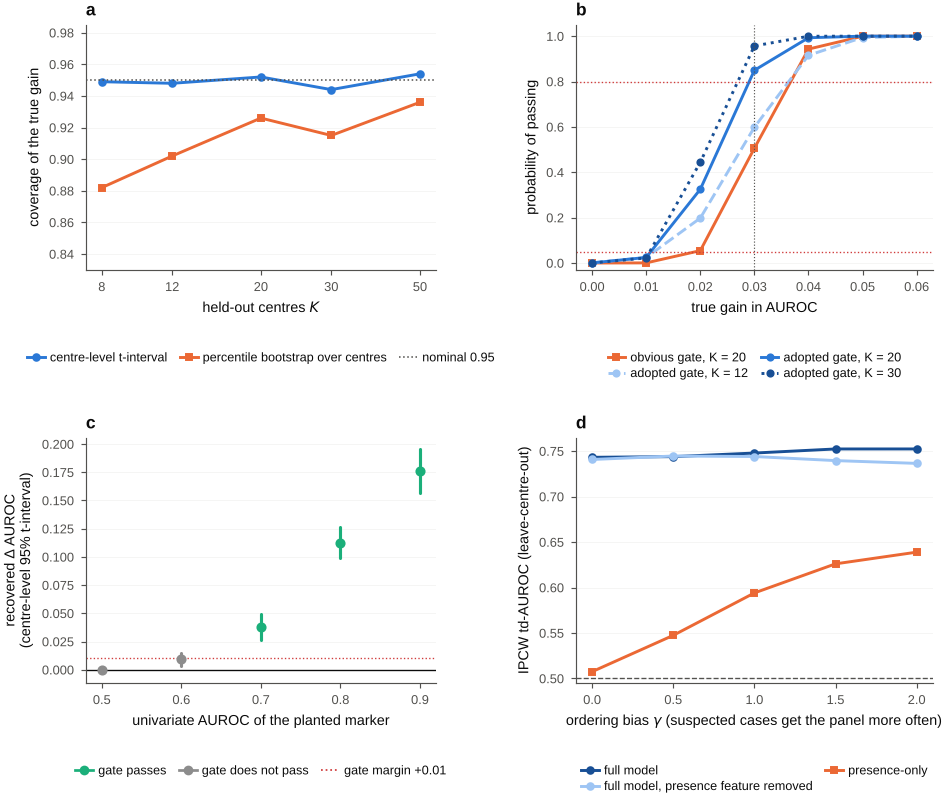

[saved] figures/Fig09_benchmark_self_validation.pdf  +  figures/Fig09_benchmark_self_validation.png


In [39]:
# ----------------------------------------------------------------------------- Figure 9: the benchmark's own operating characteristics
FWIN, FHIN = FULL, 6.0
fig = plt.figure(figsize=(FWIN, FHIN))
def A(l, b, w, h): return fig.add_axes([l / FWIN, b / FHIN, w / FWIN, h / FHIN])
axa, axb = A(.95, 3.75, 2.50, 1.75), A(4.45, 3.75, 2.55, 1.75)
axc, axd = A(.95, .80, 2.50, 1.75), A(4.45, .80, 2.55, 1.75)
CB, CT, CO = PAL['seq'][2], PAL['orange'], PAL['seq'][3]
ax = axa; ygrid(ax)                                                      # (a) coverage of the interval
ax.plot(cov.index, cov['centre-level t-interval'], 'o-', color=CB, ms=3.4, lw=1.5, label='centre-level t-interval')
ax.plot(cov.index, cov['percentile bootstrap over centres'], 's-', color=CT, ms=3.2, lw=1.5, label='percentile bootstrap over centres')
ax.axhline(.95, color=PAL['ink2'], ls=':', lw=.8, label='nominal 0.95')
ax.set_xscale('log'); ax.set_xticks(list(cov.index)); ax.set_xticklabels(list(cov.index)); ax.minorticks_off(); ax.set_ylim(.83, .985)
ax.set_xlabel('held-out centres $K$'); ax.set_ylabel('coverage of the true gain'); panel(ax, 'a')
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.30), ncol=3, columnspacing=1.0, handlelength=1.4, handletextpad=.4)
ax = axb; ygrid(ax)                                                      # (b) probability of passing the gate
pj = lambda K, col: [float(oc[(oc.K == K) & (oc.d_true == d)][col].iloc[0]) for d in DS_OC]
ax.plot(DS_OC, pj(20, 'pass_obvious'), 's-', color=CT, ms=3.2, lw=1.5, label='obvious gate, K = 20')
for K_, c_, ls_ in ((12, PAL['seq'][0], '--'), (20, CB, '-'), (30, CO, ':')):
    ax.plot(DS_OC, pj(K_, 'pass_adopted'), 'o', ls=ls_, color=c_, ms=3.2, lw=1.5, label=f'adopted gate, K = {K_}')
ax.axvline(.03, color=PAL['ink2'], lw=.6, ls=':'); ax.axhline(.8, color=PAL['bad'], lw=.7, ls=':'); ax.axhline(.05, color=PAL['bad'], lw=.7, ls=':')
ax.set_ylim(-.03, 1.05); ax.set_xlabel('true gain in AUROC'); ax.set_ylabel('probability of passing'); panel(ax, 'b')
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.30), ncol=2, columnspacing=1.0, handlelength=1.4, handletextpad=.4, labelspacing=.3)
ax = axc; ygrid(ax)                                                      # (c) planted effects recovered through the real harness
lc = {'PASS': PAL['aqua'], 'fail': PAL['grey'], 'not evaluable': PAL['grey']}
for _, r_ in ladder.iterrows():
    col = lc['PASS'] if r_.level2_gate == 'PASS' else lc['fail']
    ax.plot([r_.planted_marker_AUROC] * 2, [r_.lo, r_.hi], color=col, lw=1.6, solid_capstyle='round'); ax.plot(r_.planted_marker_AUROC, r_.recovered_delta, 'o', color=col, ms=4.2, zorder=4)
ax.axhline(0, color=PAL['ink'], lw=.7); ax.axhline(GATE['level2_gate']['ci_lower_bound_min'], color=PAL['bad'], lw=.7, ls=':')
ax.set_xlabel('univariate AUROC of the planted marker'); ax.set_ylabel('recovered Δ AUROC\n(centre-level 95% t-interval)'); ax.set_xticks(ladder.planted_marker_AUROC); panel(ax, 'c')
ax.legend([plt.Line2D([], [], color=PAL['aqua'], marker='o', ms=4, lw=1.4), plt.Line2D([], [], color=PAL['grey'], marker='o', ms=4, lw=1.4), plt.Line2D([], [], color=PAL['bad'], ls=':', lw=.9)],
          ['gate passes', 'gate does not pass', 'gate margin +0.01'], loc='upper center', bbox_to_anchor=(.5, -.30), ncol=3, columnspacing=1.0, handlelength=1.4, handletextpad=.4)
ax = axd; ygrid(ax)                                                      # (d) informative presence
ax.plot(pres.ordering_bias_gamma, pres.full_model, 'o-', color=CO, ms=3.4, lw=1.5, label='full model')
ax.plot(pres.ordering_bias_gamma, pres.full_without_presence_feature, 'o-', color=PAL['seq'][0], ms=3.4, lw=1.5, label='full model, presence feature removed')
ax.plot(pres.ordering_bias_gamma, pres.presence_only_auroc, 's-', color=CT, ms=3.2, lw=1.5, label='presence-only')
ax.axhline(.5, color=PAL['ink2'], ls='--', lw=.7)
ax.set_xticks([0, .5, 1, 1.5, 2]); ax.set_xlabel('ordering bias $\\gamma$ (suspected cases get the panel more often)'); ax.set_ylabel('IPCW td-AUROC (leave-centre-out)'); panel(ax, 'd')
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.30), ncol=2, columnspacing=1.0, handlelength=1.4, handletextpad=.4, labelspacing=.3)
finish(fig, 9, 'benchmark_self_validation',
       "[SIM] The benchmark tested like a model. (a) Coverage of the nominal 95% interval for the true gain: the centre-level t-interval holds its "
       "level at every number of centres; the percentile bootstrap over centres does not. (b) Probability of passing the gate against the true gain. "
       "The obvious gate (point estimate at least +0.03, bootstrap bound above 0) passes a threshold-sized gain about half the time; the adopted gate "
       "(t-interval lower bound at least +0.01) is powered for +0.03 at 20 centres and almost never passes +0.01 or less. Dotted lines mark 80% power, "
       "the 5% false-pass level and the designed-for gain. (c) Effects of known size planted into the simulated cohort and recovered through the "
       "real harness code; the planted null is covered by its interval and does not pass. (d) Informative presence: a model that sees only whether "
       "the biomarker panel was ordered scores above chance as soon as clinicians order it selectively, which is why presence-only is a mandatory baseline.")

**What the self-validation changes in the specification.** (i) The Level-2 interval is the centre-level *t*-interval, never a percentile bootstrap (for fewer than ~40 centres). (ii) The Level-2 rule is a *lower bound* of +0.01, which makes the design powered for +0.03; the point estimate alone is not a gate. (iii) **Presence-only** and **values-masked** comparators are mandatory, and the audit warns when the presence-only model beats chance by more than 0.02. (iv) Task **G7** runs every submission through permuted outcomes and a negative-control exposure and reports the pipeline's false-pass rate. (v) Task **G6** anchors the counterfactual claims to a randomised result.

## 8.13 [SIM] Clinical translation: drift, recalibration, enrichment and alert burden

An AUROC does not tell a transplant physician what to do. The benchmark therefore reports four translations of the same score, each computed here from first principles.

* **Drift and recalibration (task G1).** Practice changes — letermovir, PtCy for matched donors, ruxolitinib — so a model's *calibration* decays long before its *discrimination* does. We simulate a cohort whose baseline aGvHD risk falls by 0.10 on the logit scale per year, train on 2014–2018, and score each later year with and without a simple recalibration. The benchmark reports observed/expected incidence (O/E) per year, not just AUROC.
* **Prognostic enrichment.** The commonest clinical use of a risk score is to enrol the high-risk fraction into a pre-emptive-therapy trial. A trial of a treatment that cuts risk by 30 % needs fewer patients if enrolment is restricted to the top-scoring fraction *q*, but more patients must be screened to find them. We compute the **total number of patients screened** as a function of *q* and of the model's AUROC.
* **Alert burden (task B3).** For a rolling 7-day onset alarm the quantity that decides adoption is not AUROC but **alerts per 100 patient-days at a given sensitivity**, because every alert costs someone's time.
* **Net benefit** (computed in §8.11) completes the set: it is the only one of the four that depends on how the clinician values a missed case against a false alarm.

In [40]:
# ----------------------------------------------------------------------------- [SIM] temporal drift and recalibration (task G1)
DRIFT = -.10                                                       # logit change in baseline aGvHD risk per calendar year (planted)
CD_ALL = simulate_cohort(n=24000, seed=21, drift=DRIFT); CD = CD_ALL[CD_ALL.time > LANDMARK].reset_index(drop=True)
Xd = prep(CD, FULL_COLS); yd = y_b1(CD); tr_ = (CD.era <= 2018).values
mdl = make_pipeline(StandardScaler(), LogisticRegression(C=.1, max_iter=3000)).fit(Xd[tr_], yd[tr_])
pd_ = mdl.predict_proba(Xd)[:, 1]; lg = lambda p: np.log(p / (1 - p))
drift_rows = []; prev_obs = None
for yr in range(2019, 2024):
    te = (CD.era == yr).values; tprev = (CD.era == yr - 1).values
    obs = aalen_johansen(CD.time.values[te], CD.cause.values[te], 100, 1)
    obs_prev = aalen_johansen(CD.time.values[tprev], CD.cause.values[tprev], 100, 1)
    exp_static = float(pd_[te].mean())
    # recalibration-in-the-large using ONLY the previous year's outcomes: shift the logit so mean predicted risk = last year's observed incidence
    shift = 0.0
    for _ in range(30):
        f = float((1 / (1 + np.exp(-(lg(pd_[tprev]) + shift)))).mean()); shift += (lg(np.clip(obs_prev, 1e-4, .99)) - lg(f))
    exp_recal = float((1 / (1 + np.exp(-(lg(pd_[te]) + shift)))).mean())
    drift_rows.append(dict(year=yr, n=int(te.sum()), observed=obs, expected_static=exp_static, OE_static=obs / exp_static,
                           expected_recalibrated=exp_recal, OE_recalibrated=obs / exp_recal,
                           ipcw_auroc=ipcw_td_auroc(CD.time.values[te], CD.cause.values[te], mdl.decision_function(Xd[te]), 100)))
drift_df = pd.DataFrame(drift_rows)
print(f'[SIM] drift of {DRIFT:+.2f} logit/year; model trained on 2014-2018 (n = {int(tr_.sum()):,}), scored year by year:'); display(md_table(drift_df.round(3)))
oe_slope = float(np.polyfit(drift_df.year, np.log(drift_df.OE_static), 1)[0])
print(f'log O/E of the static model changes by {oe_slope:+.3f} per year; AUROC range across years {drift_df.ipcw_auroc.min():.3f}-{drift_df.ipcw_auroc.max():.3f}')
assert drift_df.OE_static.iloc[-1] < drift_df.OE_static.iloc[0] - .1, 'the planted drift must show up as miscalibration of the static model'
assert drift_df.OE_recalibrated.sub(1).abs().mean() < drift_df.OE_static.sub(1).abs().mean(), 'recalibration must reduce the O/E error'

[SIM] drift of -0.10 logit/year; model trained on 2014-2018 (n = 11,915), scored year by year:


| year | n | observed | expected_static | OE_static | expected_recalibrated | OE_recalibrated | ipcw_auroc |
|---|---|---|---|---|---|---|---|
| 2019 | 2490 | 0.14 | 0.157 | 0.893 | 0.134 | 1.048 | 0.759 |
| 2020 | 2389 | 0.122 | 0.157 | 0.777 | 0.141 | 0.869 | 0.776 |
| 2021 | 2380 | 0.122 | 0.144 | 0.851 | 0.111 | 1.106 | 0.807 |
| 2022 | 2393 | 0.093 | 0.135 | 0.689 | 0.115 | 0.811 | 0.769 |
| 2023 | 2423 | 0.086 | 0.125 | 0.687 | 0.086 | 1.0 | 0.779 |

log O/E of the static model changes by -0.064 per year; AUROC range across years 0.759-0.807


In [41]:
# ----------------------------------------------------------------------------- prognostic enrichment and alert burden from the binormal model (closed form)
def _cut(q, A, prev):
    """Score threshold c such that a fraction q of patients scores above it, for a binormal score with AUROC A and prevalence prev."""
    D = math.sqrt(2) * norm.ppf(A); lo, hi = -8., D + 8
    for _ in range(80):
        mid = (lo + hi) / 2
        if prev * norm.sf(mid - D) + (1 - prev) * norm.sf(mid) > q: lo = mid
        else: hi = mid
    return (lo + hi) / 2, D
def trial_for_top_fraction(q, A, prev, rrr=.30, alpha=.05, power=.8):
    """Two-arm trial of a therapy with relative risk reduction rrr, enrolling the top fraction q of the risk ranking.
    Returns (patients enrolled, pool that must be ranked to find them, event rate among those enrolled)."""
    c, D = _cut(q, A, prev); p_sel = prev * norm.sf(c - D) / q
    pc_, pt_ = p_sel, p_sel * (1 - rrr)
    n_arm = (norm.ppf(1 - alpha / 2) + norm.ppf(power)) ** 2 * (pc_ * (1 - pc_) + pt_ * (1 - pt_)) / (pc_ - pt_) ** 2
    return 2 * n_arm, 2 * n_arm / q, p_sel
def alerts_per_100_patient_days(sens, A, prev_window):
    """Alerts per 100 patient-days when the alarm is set to catch `sens` of upcoming onsets (binormal score, onset-within-7-days rate prev_window)."""
    D = math.sqrt(2) * norm.ppf(A); c = D + norm.isf(sens)                         # threshold at which P(score > c | event) = sens
    fpr = norm.sf(c); return 100 * (prev_window * sens + (1 - prev_window) * fpr)
QS = np.linspace(.05, 1.0, 40); PREV_ENR = .13                                  # grade III-IV aGvHD (task B2): where enrichment would actually be used
ENR = {A: [trial_for_top_fraction(q, A, PREV_ENR) for q in QS] for A in (.65, .72, .80)}
enr_rows = []
for A in (.65, .72, .80):
    n_un = trial_for_top_fraction(1.0, A, PREV_ENR)[0]
    for q in (.5, .3, .2):
        n_e, pool, ps = trial_for_top_fraction(q, A, PREV_ENR)
        enr_rows.append({'AUROC': A, 'fraction enrolled q': q, 'event rate among enrolled': f'{ps:.2f}', 'trial size, enriched': f'{n_e:,.0f}', 'trial size, unselected': f'{n_un:,.0f}',
                         'saving in trial size': f'{1 - n_e / n_un:.0%}', 'pool that must be ranked': f'{pool:,.0f}', 'pool / unselected trial': f'{pool / n_un:.1f}x'})
enr_tab = pd.DataFrame(enr_rows)
SS = np.linspace(.3, .95, 30)
ALERT = {A: [alerts_per_100_patient_days(s, A, .04) for s in SS] for A in (.70, .75, .80, .85)}
al_tab = pd.DataFrame([dict(AUROC=A, **{f'alerts / 100 patient-days at sens {s:.0%}': alerts_per_100_patient_days(s, A, .04) for s in (.5, .7)},
                            **{'PPV at sens 50%': (.04 * .5) / (.04 * .5 + .96 * norm.sf(math.sqrt(2) * norm.ppf(A) + norm.ppf(.5)))}) for A in (.70, .75, .80, .85)])
print(f'PROGNOSTIC ENRICHMENT for a therapy that cuts risk by 30 % (outcome prevalence {PREV_ENR}; α = 0.05, power 0.8):'); display(md_table(enr_tab))
print('ALERT BURDEN for a rolling 7-day onset alarm (event rate 0.04 per alarm-day):'); display(md_table(al_tab.round(2)))
# a random model (AUROC .5) must give no saving and an alert rate equal to the base rate
assert abs(trial_for_top_fraction(.5, .501, .35)[0] - trial_for_top_fraction(1.0, .501, .35)[0]) / trial_for_top_fraction(1.0, .501, .35)[0] < .02    # a random score cannot enrich

PROGNOSTIC ENRICHMENT for a therapy that cuts risk by 30 % (outcome prevalence 0.13; α = 0.05, power 0.8):


| AUROC | fraction enrolled q | event rate among enrolled | trial size, enriched | trial size, unselected | saving in trial size | pool that must be ranked | pool / unselected trial |
|---|---|---|---|---|---|---|---|
| 0.65 | 0.5 | 0.18 | 1,410 | 2,021 | 30% | 2,819 | 1.4x |
| 0.65 | 0.3 | 0.21 | 1,174 | 2,021 | 42% | 3,914 | 1.9x |
| 0.65 | 0.2 | 0.23 | 1,037 | 2,021 | 49% | 5,185 | 2.6x |
| 0.72 | 0.5 | 0.20 | 1,230 | 2,021 | 39% | 2,459 | 1.2x |
| 0.72 | 0.3 | 0.25 | 938 | 2,021 | 54% | 3,127 | 1.5x |
| 0.72 | 0.2 | 0.29 | 779 | 2,021 | 61% | 3,893 | 1.9x |
| 0.8 | 0.5 | 0.22 | 1,074 | 2,021 | 47% | 2,149 | 1.1x |
| 0.8 | 0.3 | 0.30 | 735 | 2,021 | 64% | 2,449 | 1.2x |
| 0.8 | 0.2 | 0.36 | 561 | 2,021 | 72% | 2,805 | 1.4x |

ALERT BURDEN for a rolling 7-day onset alarm (event rate 0.04 per alarm-day):


| AUROC | alerts / 100 patient-days at sens 50% | alerts / 100 patient-days at sens 70% | PPV at sens 50% |
|---|---|---|---|
| 0.7 | 24.0 | 42.55 | 0.08 |
| 0.75 | 18.33 | 34.84 | 0.11 |
| 0.8 | 13.23 | 27.06 | 0.15 |
| 0.85 | 8.85 | 19.43 | 0.23 |

[layout PASS] Fig 10: 47 text items, 0 collisions, 0 below 6 pt (smallest 6.5 pt)


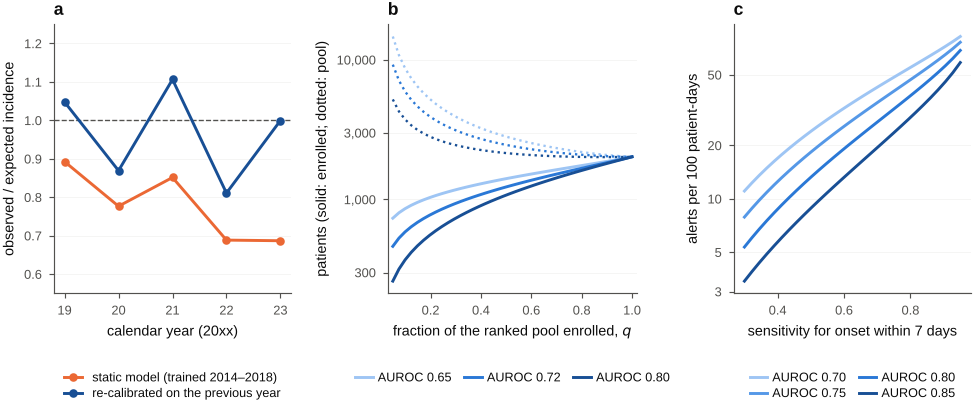

[saved] figures/Fig10_clinical_translation.pdf  +  figures/Fig10_clinical_translation.png


In [42]:
# ----------------------------------------------------------------------------- Figure 10: from AUROC to what a clinician would see
fig = plt.figure(figsize=(FULL, 3.1))
gs = fig.add_gridspec(1, 3, width_ratios=[1.0, 1.05, 1.0], left=.075, right=.985, bottom=.255, top=.875, wspace=.40)
ax = fig.add_subplot(gs[0, 0]); ygrid(ax)                                       # (a) drift and recalibration
ax.axhline(1, color=PAL['ink2'], lw=.7, ls='--')
ax.plot(drift_df.year, drift_df.OE_static, 'o-', color=PAL['orange'], ms=3.4, lw=1.5, label='static model (trained 2014–2018)')
ax.plot(drift_df.year, drift_df.OE_recalibrated, 'o-', color=PAL['seq'][3], ms=3.4, lw=1.5, label='re-calibrated on the previous year')
ax.set_xticks(drift_df.year); ax.set_xticklabels([str(y)[2:] for y in drift_df.year]); ax.set_xlabel('calendar year (20xx)'); ax.set_ylabel('observed / expected incidence'); ax.set_ylim(.55, 1.25)
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.26), ncol=1, handlelength=1.4, labelspacing=.3); panel(ax, 'a')
ax = fig.add_subplot(gs[0, 1]); ygrid(ax)                                       # (b) prognostic enrichment
for A, c in zip((.65, .72, .80), (PAL['seq'][0], PAL['seq'][2], PAL['seq'][3])):
    ax.plot(QS, [e[0] for e in ENR[A]], color=c, lw=1.5, label=f'AUROC {A:.2f}')
    ax.plot(QS, [e[1] for e in ENR[A]], color=c, lw=1.2, ls=':')
ax.set_yscale('log'); ax.set_yticks([300, 1000, 3000, 10000]); ax.set_yticklabels(['300', '1,000', '3,000', '10,000']); ax.minorticks_off()
ax.set_xlabel('fraction of the ranked pool enrolled, $q$'); ax.set_ylabel('patients (solid: enrolled; dotted: pool)'); ax.set_xlim(.03, 1.02)
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.26), ncol=3, columnspacing=1.0, handlelength=1.4, handletextpad=.4); panel(ax, 'b')
ax = fig.add_subplot(gs[0, 2]); ygrid(ax)                                       # (c) alert burden
for A, c in zip((.70, .75, .80, .85), (PAL['seq'][0], PAL['seq'][1], PAL['seq'][2], PAL['seq'][3])):
    ax.plot(SS, ALERT[A], color=c, lw=1.5, label=f'AUROC {A:.2f}')
ax.set_yscale('log'); ax.set_yticks([3, 5, 10, 20, 50]); ax.set_yticklabels(['3', '5', '10', '20', '50']); ax.minorticks_off()
ax.set_xlabel('sensitivity for onset within 7 days'); ax.set_ylabel('alerts per 100 patient-days')
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.26), ncol=2, columnspacing=1.0, handlelength=1.4, handletextpad=.4, labelspacing=.3); panel(ax, 'c')
finish(fig, 10, 'clinical_translation',
       '[SIM / closed form] Three translations of the same score. (a) Calibration decays under practice drift while discrimination barely moves: '
       'observed/expected incidence of a static model against calendar year, and after re-calibration on the previous year. (b) Prognostic enrichment: '
       'patients enrolled (solid) and pool that must be ranked to find them (dotted) for a two-arm trial of a therapy that cuts risk by 30% in a '
       'population with a 13% event rate, against the fraction enrolled from the top of the risk ranking. Even AUROC 0.65 shrinks the trial substantially, at the price of a pool about twice as large; the better the score, the smaller the pool needed. '
       '(c) Alert burden of a rolling 7-day onset alarm at an onset rate of 0.04 per alarm-day, which decides whether anyone will use it.')

In [43]:
gn = lambda A, q, col: enr_tab[(enr_tab.AUROC == A) & (enr_tab['fraction enrolled q'] == q)][col].iloc[0]; a80 = al_tab.set_index('AUROC').loc[.80]; a70 = al_tab.set_index('AUROC').loc[.70]
over_ = 1 / drift_df.OE_static.iloc[-1] - 1
display(Markdown(f"""**Result.** The three translations are more demanding than the AUROC suggests.

* **Drift** (panel a): with a planted decline in baseline risk the static model's discrimination barely moves (AUROC {drift_df.ipcw_auroc.min():.3f}–{drift_df.ipcw_auroc.max():.3f} across years) but its O/E falls from {drift_df.OE_static.iloc[0]:.2f} to **{drift_df.OE_static.iloc[-1]:.2f}** — by 2023 it **over-predicts risk by about {100 * over_:.0f} %** — while a one-line recalibration on the previous year keeps O/E within {100 * drift_df.OE_recalibrated.sub(1).abs().max():.0f} % of 1. Task G1 therefore reports O/E per year, and Level 3 requires a **recalibration plan**, not a one-off validation.
* **Enrichment** (panel b): at an event rate of 13 %, enrolling the top 30 % of the ranking shrinks a 30 %-risk-reduction trial by **{gn(.65, .3, 'saving in trial size')}** at AUROC 0.65, **{gn(.72, .3, 'saving in trial size')}** at 0.72 and **{gn(.80, .3, 'saving in trial size')}** at 0.80. Even a modest score therefore buys a much smaller trial; what a better score buys is a smaller *pool*: the ranking must cover {gn(.65, .3, 'pool / unselected trial')} the size of the unselected trial at AUROC 0.65, {gn(.72, .3, 'pool / unselected trial')} at 0.72 and {gn(.80, .3, 'pool / unselected trial')} at 0.80. Enrichment is attractive only where the pool is plentiful and the score is free to compute, which describes registry-scale pools and no single centre. This is the clinically meaningful reading of "is AUROC 0.72 good enough": it is enough to design a pre-emptive-therapy trial with roughly half the patients, provided a pool of about {gn(.72, .3, 'pool that must be ranked')} can be ranked.
* **Alerts** (panel c): a rolling alarm of AUROC 0.80 produces **{a80['alerts / 100 patient-days at sens 50%']:.0f} alerts per 100 patient-days** at 50 % sensitivity with a PPV of **{a80['PPV at sens 50%']:.0%}** — about {a80['alerts / 100 patient-days at sens 50%'] * .2:.1f} alerts a day on a 20-bed transplant unit; at AUROC 0.70 it is {a70['alerts / 100 patient-days at sens 50%']:.0f} per 100 patient-days at a PPV of {a70['PPV at sens 50%']:.0%}. B3 is therefore reported as alerts per 100 patient-days at fixed sensitivity, and its acceptance criterion is a **clinician-agreed alert budget**, not an AUROC."""))

**Result.** The three translations are more demanding than the AUROC suggests.

* **Drift** (panel a): with a planted decline in baseline risk the static model's discrimination barely moves (AUROC 0.759–0.807 across years) but its O/E falls from 0.89 to **0.69** — by 2023 it **over-predicts risk by about 46 %** — while a one-line recalibration on the previous year keeps O/E within 19 % of 1. Task G1 therefore reports O/E per year, and Level 3 requires a **recalibration plan**, not a one-off validation.
* **Enrichment** (panel b): at an event rate of 13 %, enrolling the top 30 % of the ranking shrinks a 30 %-risk-reduction trial by **42%** at AUROC 0.65, **54%** at 0.72 and **64%** at 0.80. Even a modest score therefore buys a much smaller trial; what a better score buys is a smaller *pool*: the ranking must cover 1.9x the size of the unselected trial at AUROC 0.65, 1.5x at 0.72 and 1.2x at 0.80. Enrichment is attractive only where the pool is plentiful and the score is free to compute, which describes registry-scale pools and no single centre. This is the clinically meaningful reading of "is AUROC 0.72 good enough": it is enough to design a pre-emptive-therapy trial with roughly half the patients, provided a pool of about 3,127 can be ranked.
* **Alerts** (panel c): a rolling alarm of AUROC 0.80 produces **13 alerts per 100 patient-days** at 50 % sensitivity with a PPV of **15%** — about 2.6 alerts a day on a 20-bed transplant unit; at AUROC 0.70 it is 24 per 100 patient-days at a PPV of 8%. B3 is therefore reported as alerts per 100 patient-days at fixed sensitivity, and its acceptance criterion is a **clinician-agreed alert budget**, not an AUROC.

## 8.14 Rules the self-validation adds to the benchmark

| Rule | Why | Where it is enforced |
|---|---|---|
| Level-2 interval = centre-level *t* (K−1 d.f.), lower bound ≥ +0.01, ≥ 20 centres | percentile bootstrap under-covers; point-estimate gates are coin flips at threshold (§8.12) | `spec/gate.json` |
| Presence-only and values-masked comparators; audit warns if presence-only beats chance by > 0.02 | informative ordering looks like signal (§8.12) | harness component 5–6 |
| Task G7: permuted-outcome and negative-exposure controls on every submission | measures the pipeline's false-pass rate | harness component 7 |
| Task G6: reproduce a published randomised effect (BMT CTN 1703, GRFS HR 0.64 ✓) from registry data | the only external anchor for counterfactual claims | task card G6 |
| Task G1 reports O/E per calendar year and the plan for recalibration | calibration, not discrimination, decays (§8.13) | task card G1 |
| Utility is reported as screened-patient saving (enrichment) and alerts per 100 patient-days, alongside AUROC | what a clinician or trial sponsor actually acts on (§8.13) | tasks B1/B3/C3 |
| Subgroup rule: a subgroup is **assessed** only if it has the events §9.7 requires, otherwise reported as *not assessable* | prevents false reassurance on small groups | task G3 |
| Label reliability: ≥ 10 % of outcomes double-read, κ ≥ 0.8, else the attenuation of §9.7 is applied to every n | label noise caps discrimination and inflates n | §8.1 cohort definition |

---
# 9 · How much data is needed?

This section answers the question in eight parts. Everything is computed in the notebook; every assumption is stated where it enters, and the closed-form calculators are validated against simulation before they are used.

| § | Question | Method |
|---|---|---|
| 9.1 | How precise is one AUROC? How many patients to *show* a gain? How many to *develop* a model? | Hanley–McNeil; closed-form paired DeLong power (validated by simulation); Riley et al. |
| 9.2 | What can each real data source support? | the above, against source sizes |
| 9.3 | How long would it take to accrue? | per-task accrual by route |
| 9.4 | **How many labelled transcriptomes at diagnosis?** | closed-form learning curve of a linear head, validated by simulation; effective dimension; cross-centre transfer |
| 9.5 | **What longitudinal sampling: how many draws, how often, how many specimens?** | reliability (Spearman–Brown), prodrome-window sampling, the §4.4 schedule evaluated against onset times |
| 9.6 | **How many centres?** | between-centre variance, design effect, centres needed for the gate |
| 9.7 | **How many patients to validate a claim, per subgroup, with imperfect labels?** | Fisher information for calibration; subgroup precision; label-noise attenuation |
| 9.8 | **The data bill of materials** | minimum-viable / credible / definitive packages, binding constraints, cost and time |

## 9.1 Precision, power and development size
Three different questions, three different answers.
1. **Precision** — how wide is the confidence interval of one AUROC at sample size n? (Hanley–McNeil standard error, checked against simulation.)
2. **Power for a comparison** — to claim "ALLO-FM beats MAP + clinical" we need a *paired* test. How many patients for ΔAUROC = 0.02 / 0.03 / 0.05? We use the **closed-form asymptotic DeLong variance** of the AUROC difference for two correlated scores (the toolkit above), and *validate it against a Monte-Carlo DeLong test* on simulated data before relying on it. The closed form gives a continuous answer; a simulation on a coarse grid of n can only say "the first grid point that reaches 80 %", which overstates the requirement.
3. **Development sample size** — Riley et al.'s criteria for a model with P candidate parameters.

Hanley–McNeil SE vs simulated SE: ['A=0.72, n1=35, n0=65: 0.056 vs 0.053', 'A=0.72, n1=140, n0=260: 0.028 vs 0.027']


closed-form paired power vs Monte-Carlo DeLong: 36 comparisons, mean |diff| 0.020, max 0.084 (Monte-Carlo noise at 120 replicates: SD <= 0.046)


[layout PASS] Fig 11: 56 text items, 0 collisions, 0 below 6 pt (smallest 6.4 pt)


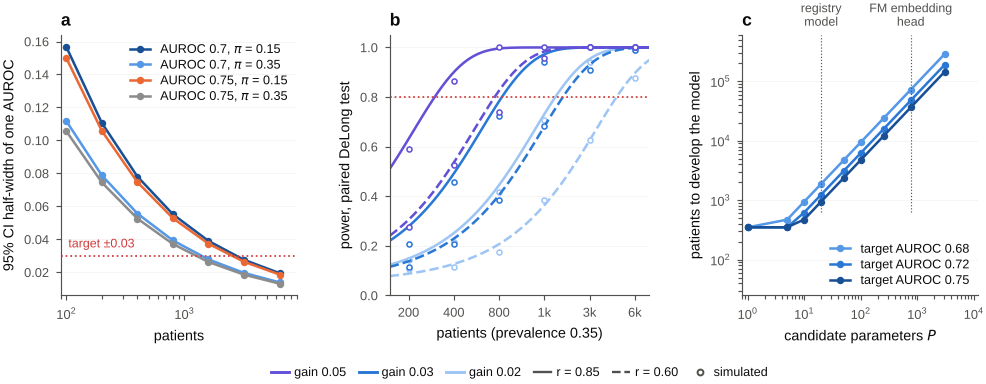

[saved] figures/Fig11_sample_size_and_power.pdf  +  figures/Fig11_sample_size_and_power.png


| patients | AUROC 0.7, prev 0.15 | AUROC 0.7, prev 0.35 | AUROC 0.75, prev 0.15 | AUROC 0.75, prev 0.35 |
|---|---|---|---|---|
| 100 | 0.157 | 0.112 | 0.15 | 0.106 |
| 200 | 0.111 | 0.079 | 0.106 | 0.074 |
| 400 | 0.078 | 0.056 | 0.075 | 0.053 |
| 800 | 0.055 | 0.039 | 0.053 | 0.037 |
| 1600 | 0.039 | 0.028 | 0.037 | 0.026 |
| 3200 | 0.028 | 0.02 | 0.026 | 0.019 |
| 6400 | 0.02 | 0.014 | 0.019 | 0.013 |

| delta_AUROC | score_corr | n=200 | n=400 | n=800 | n=1600 | n=3200 | n=6400 | n_for_80pct_power |
|---|---|---|---|---|---|---|---|---|
| 0.02 | 0.6 | 0.09 | 0.13 | 0.21 | 0.36 | 0.63 | 0.9 | 4835 |
| 0.02 | 0.85 | 0.15 | 0.25 | 0.44 | 0.73 | 0.95 | 1.0 | 1893 |
| 0.03 | 0.6 | 0.14 | 0.23 | 0.4 | 0.68 | 0.93 | 1.0 | 2125 |
| 0.03 | 0.85 | 0.28 | 0.49 | 0.78 | 0.97 | 1.0 | 1.0 | 836 |
| 0.05 | 0.6 | 0.3 | 0.54 | 0.83 | 0.98 | 1.0 | 1.0 | 748 |
| 0.05 | 0.85 | 0.63 | 0.9 | 1.0 | 1.0 | 1.0 | 1.0 | 299 |

| params | AUROC 0.68 | AUROC 0.72 | AUROC 0.75 |
|---|---|---|---|
| 1 | 350 | 350 | 350 |
| 5 | 471 | 350 | 350 |
| 10 | 942 | 621 | 474 |
| 20 | 1883 | 1242 | 948 |
| 50 | 4706 | 3103 | 2368 |
| 100 | 9411 | 6206 | 4736 |
| 256 | 24092 | 15888 | 12123 |
| 768 | 72274 | 47662 | 36367 |
| 3072 | 289093 | 190647 | 145467 |

In [44]:
# ----------------------------------------------------------------------------- (1) precision of one AUROC; (2) paired power: closed form, validated against a DeLong simulation
def sim_se(A, n1, n0, reps=900, seed=0):
    rng = np.random.default_rng(seed); d = math.sqrt(2) * norm.ppf(A)
    return float(np.std([roc_auc_score(np.r_[np.ones(n1), np.zeros(n0)], np.r_[rng.normal(d, 1, n1), rng.normal(0, 1, n0)]) for _ in range(reps)]))
print('Hanley–McNeil SE vs simulated SE:', [f'A={A}, n1={a}, n0={b}: {hm_se(A, a, b):.3f} vs {sim_se(A, a, b):.3f}'
                                            for A, a, b in [(.72, 35, 65), (.72, 140, 260)]])
ns = np.array([100, 200, 400, 800, 1600, 3200, 6400])
prec = pd.DataFrame({f'AUROC {A}, prev {pi}': [1.96 * hm_se(A, max(int(n * pi), 2), max(int(n * (1 - pi)), 2)) for n in ns]
                     for A in (.70, .75) for pi in (.15, .35)}, index=ns); prec.index.name = 'patients'

def delong_z(y, s1, s2):
    """DeLong z for the difference of two correlated AUROCs on the same patients (rank form)."""
    m, n = int((y == 1).sum()), int((y == 0).sum()); aucs, v01, v10 = [], [], []
    for s in (s1, s2):
        X, Y = s[y == 1], s[y == 0]; tx, ty, tz = rankdata(X), rankdata(Y), rankdata(np.r_[X, Y])
        aucs.append(tz[:m].sum() / (m * n) - (m + 1) / (2 * n)); v01.append((tz[:m] - tx) / n); v10.append(1 - (tz[m:] - ty) / m)
    S = np.cov(np.vstack(v01)) / m + np.cov(np.vstack(v10)) / n
    return (aucs[1] - aucs[0]) / math.sqrt(max(S[0, 0] + S[1, 1] - 2 * S[0, 1], 1e-12))
def delong_slow(y, s1, s2):
    pos = y == 1; m, n = pos.sum(), (~pos).sum()
    def comps(s):
        psi = (s[pos][:, None] > s[~pos][None, :]) + .5 * (s[pos][:, None] == s[~pos][None, :]); return psi.mean(), psi.mean(1), psi.mean(0)
    a1, x1, y1 = comps(s1); a2, x2, y2 = comps(s2)
    S = np.cov(np.vstack([x1, x2])) / m + np.cov(np.vstack([y1, y2])) / n
    return (a2 - a1) / math.sqrt(S[0, 0] + S[1, 1] - 2 * S[0, 1])
_r = np.random.default_rng(0); _y = (_r.random(150) < .35).astype(int)
_a, _b = _r.normal(size=150) + _y, _r.normal(size=150) + .6 * _y
assert abs(delong_z(_y, _a, _b) - delong_slow(_y, _a, _b)) < 1e-9, 'fast and textbook DeLong disagree'

SIM_REPS = 120 if not QUICK else 40
def paired_power(n, pi, A1, A2, rho, reps=SIM_REPS, seed=0):
    rng = np.random.default_rng(seed); n1 = max(int(round(n * pi)), 3); n0 = n - n1
    d1, d2 = math.sqrt(2) * norm.ppf(A1), math.sqrt(2) * norm.ppf(A2); cov = np.array([[1, rho], [rho, 1]]); hit = 0
    for _ in range(reps):
        sp = rng.multivariate_normal([d1, d2], cov, n1); sn = rng.multivariate_normal([0, 0], cov, n0)
        y = np.r_[np.ones(n1), np.zeros(n0)]
        hit += abs(delong_z(y, np.r_[sp[:, 0], sn[:, 0]], np.r_[sp[:, 1], sn[:, 1]])) > 1.96
    return hit / reps
grid = [200, 400, 800, 1600, 3200, 6400]
DELTAS, RHOS_ = (.02, .03, .05), (.6, .85)
pw_rows, sim_pts = [], {}
for d in DELTAS:
    for rho in RHOS_:
        sim_pts[(d, rho)] = {n: paired_power(n, .35, .70, .70 + d, rho) for n in grid}
        pw_rows.append(dict(delta_AUROC=d, score_corr=rho, **{f'n={n}': round(power_delta(n, .35, .70, .70 + d, rho), 2) for n in grid},
                            n_for_80pct_power=n_for_delta(.70, d, .35, rho)))
pw = pd.DataFrame(pw_rows)
# validation: closed form against the Monte-Carlo DeLong test at every (delta, rho, n)
dev = np.array([abs(power_delta(n, .35, .70, .70 + d, rho) - sim_pts[(d, rho)][n]) for d in DELTAS for rho in RHOS_ for n in grid])
MC_TOL = 3.5 * math.sqrt(.25 / SIM_REPS)
print(f'closed-form paired power vs Monte-Carlo DeLong: {len(dev)} comparisons, mean |diff| {dev.mean():.3f}, max {dev.max():.3f} '
      f'(Monte-Carlo noise at {SIM_REPS} replicates: SD <= {math.sqrt(.25 / SIM_REPS):.3f})')
assert dev.max() < MC_TOL, 'closed-form paired power disagrees with the simulation'
PARAMS = [1, 5, 10, 20, 50, 100, 256, 768, 3072]
riley = pd.DataFrame([dict(params=P, **{f'AUROC {A}': riley_n(P, A, .35)['n'] for A in (.68, .72, .75)})
                      for P in PARAMS]).set_index('params')
fig = plt.figure(figsize=(FULL, 3.0))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1.1, 1], left=.075, right=.985, bottom=.255, top=.875, wspace=.38)
ax = fig.add_subplot(gs[0, 0]); ygrid(ax)                                          # (a) precision of one AUROC
for c_, col in zip(prec.columns, (PAL['seq'][3], PAL['seq'][1], PAL['orange'], PAL['grey'])):
    ax.plot(prec.index, prec[c_], marker='o', ms=2.8, color=col, lw=1.3, label=c_.replace('AUROC ', 'AUROC ').replace('prev ', '$\\pi$ = '))
ax.axhline(.03, color=PAL['bad'], ls=':', lw=.9)
ax.annotate('target ±0.03', (prec.index[0] * 1.04, .03), xytext=(0, 3), textcoords='offset points', fontsize=6.4, color=PAL['bad'], va='bottom')
ax.set_xscale('log'); ax.set_xlabel('patients'); ax.set_ylabel('95% CI half-width of one AUROC'); ax.set_xlim(90, 9e3)
ax.legend(loc='upper right', labelspacing=.3); panel(ax, 'a')
ax = fig.add_subplot(gs[0, 1]); ygrid(ax)                                          # (b) power to show a gain over a correlated baseline
DCOL = {.02: PAL['seq'][0], .03: PAL['seq'][2], .05: PAL['violet']}
fine = np.geomspace(150, 8000, 60)
for d in DELTAS:
    for rho in RHOS_:
        ax.plot(fine, [power_delta(n, .35, .70, .70 + d, rho) for n in fine], color=DCOL[d], lw=1.3, ls='-' if rho == .85 else '--')
        ax.plot(grid, [sim_pts[(d, rho)][n] for n in grid], 'o', ms=2.6, mfc='white', mec=DCOL[d], mew=.8, ls='None')
ax.axhline(.8, color=PAL['bad'], ls=':', lw=.9)
ax.set_xscale('log'); ax.set_xticks(grid); ax.set_xticklabels([f'{g // 1000}k' if g >= 1000 else g for g in grid]); ax.minorticks_off()
ax.set_xlim(150, 8e3); ax.set_ylim(0, 1.05); ax.set_xlabel('patients (prevalence 0.35)'); ax.set_ylabel('power, paired DeLong test')
hs = [plt.Line2D([], [], color=DCOL[d], lw=1.5) for d in (.05, .03, .02)] + [plt.Line2D([], [], color=PAL['ink2'], lw=1.2), plt.Line2D([], [], color=PAL['ink2'], lw=1.2, ls='--'),
      plt.Line2D([], [], color=PAL['ink2'], marker='o', ms=3, mfc='white', ls='None')]
ax.legend(hs, ['gain 0.05', 'gain 0.03', 'gain 0.02', 'r = 0.85', 'r = 0.60', 'simulated'], loc='upper center',
          bbox_to_anchor=(.5, -.24), ncol=6, columnspacing=1.0, handlelength=1.4, labelspacing=.3, handletextpad=.4); panel(ax, 'b')
ax = fig.add_subplot(gs[0, 2]); ygrid(ax)                                          # (c) patients needed to develop a model
for c_, col in zip(riley.columns, (PAL['seq'][1], PAL['seq'][2], PAL['seq'][3])):
    ax.plot(riley.index, riley[c_], marker='o', ms=2.8, color=col, lw=1.3, label=c_.replace('AUROC ', 'target AUROC '))
for P_, lab in ((20, 'registry\nmodel'), (768, 'FM embedding\nhead')):                  # labelled above the axes, centred on their own line
    ax.axvline(P_, ymin=.32, color=PAL['ink2'], lw=.6, ls=':')
    ax.annotate(lab, (P_, 1.0), xycoords=('data', 'axes fraction'), xytext=(0, 3), textcoords='offset points',
                fontsize=6.4, color=PAL['ink2'], va='bottom', ha='center')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('candidate parameters $P$'); ax.set_ylabel('patients to develop the model')
ax.set_xlim(.8, 1.2e4); ax.set_ylim(25, 6e5); ax.legend(loc='lower right', labelspacing=.3); panel(ax, 'c')
finish(fig, 11, 'sample_size_and_power',
       'Three different sample-size questions. (a) Precision: the 95% confidence interval of a single AUROC against the number of '
       'patients. (b) Power: the paired DeLong test for an improvement of 0.02 to 0.05 AUROC over a correlated baseline, the regime '
       'any foundation-model claim lives in; lines are the closed form, circles are a Monte-Carlo DeLong test; solid lines are scores '
       'correlated at 0.85, dashed at 0.60. (c) Development: the Riley minimum sample size against the number of candidate '
       'parameters, which is why head size sets the data requirement.')
display(md_table(prec.round(3), index=True)); display(md_table(pw)); display(md_table(riley, index=True))

## 9.2 What can each real data source support?

In [45]:
# ----------------------------------------------------------------------------- what each data source can actually support
n80 = lambda d, rho: pw[(pw.delta_AUROC == d) & (pw.score_corr == rho)].n_for_80pct_power.iloc[0]
SOURCES = [('One large centre, 10 years (Tier A+B)', 2500), ('BMT CTN 1703 (randomised, Tier A+C)', 431),
           ('MAGIC day-7 biomarker cohort (Tier A+C)', 1287), ('MSK hospitalome (public, Tier A+B+microbiome)', 1000),
           ('CIBMTR extract, recent era, selected donor types (Tier A)', 25000), ('CIBMTR full (Tier A)', 470000),
           ('Typical public GEO GvHD series (Tier D)', 40)]
need = {'registry model (P=20)': riley_n(20, .72, .35)['n'], 'pathway/panel head (P=50)': riley_n(50, .72, .35)['n'],
        'FM embedding head (P=768)': riley_n(768, .72, .35)['n'],
        f'show Δ=0.03 vs baseline (corr .85)': n80(.03, .85), f'show Δ=0.05 vs baseline (corr .85)': n80(.05, .85)}
cap = pd.DataFrame([dict(source=s, patients=n, **{k: ('yes' if isinstance(v, (int, float, np.integer, np.floating)) and n >= v else 'NO') for k, v in need.items()}) for s, n in SOURCES])
print('requirements (patients):', {k: (f'{v:,}' if isinstance(v, (int, float)) else v) for k, v in need.items()})
display(md_table(cap))
display(Markdown(f"""**Reading.** (1) Even a *single* AUROC is imprecise below ~1,000 patients: at n = 400 and prevalence 0.35 the 95 % CI half-width is ±{prec.loc[400, 'AUROC 0.7, prev 0.35']:.3f}. (2) Showing that a foundation model beats MAP + clinical covariates by Δ = 0.03 — the realistic size of a genuine gain between correlated models — needs about **{n80(.03, .85):,}** patients at score correlation 0.85 (and **{n80(.03, .6):,}** at 0.60, when the two models disagree more); Δ = 0.02 needs **{n80(.02, .85):,}** even at correlation 0.85 (**{n80(.02, .6):,}** at 0.60), which only a registry or a large consortium can supply. (3) Developing a 768-parameter head at AUROC 0.72 and prevalence 0.35 needs **{riley_n(768, .72, .35)['n']:,}** patients unpenalised; ridge shrinkage and pretraining are precisely the arguments for needing fewer, which is the claim the benchmark exists to test.

**The conclusion that drives the whole roadmap.** No public transcriptomic resource and no single trial can answer the central question. **A registry-scale Tier A/B cohort, with Tier C biomarkers on a subset, is the minimum viable evaluation substrate.** This is why ALLO-FM is specified as a clinical-timeline model with optional omics adapters, and not the other way round."""))

requirements (patients): {'registry model (P=20)': '1,242', 'pathway/panel head (P=50)': '3,103', 'FM embedding head (P=768)': '47,662', 'show Δ=0.03 vs baseline (corr .85)': np.int64(836), 'show Δ=0.05 vs baseline (corr .85)': np.int64(299)}


| source | patients | registry model (P=20) | pathway/panel head (P=50) | FM embedding head (P=768) | show Δ=0.03 vs baseline (corr .85) | show Δ=0.05 vs baseline (corr .85) |
|---|---|---|---|---|---|---|
| One large centre, 10 years (Tier A+B) | 2500 | yes | NO | NO | yes | yes |
| BMT CTN 1703 (randomised, Tier A+C) | 431 | NO | NO | NO | NO | yes |
| MAGIC day-7 biomarker cohort (Tier A+C) | 1287 | yes | NO | NO | yes | yes |
| MSK hospitalome (public, Tier A+B+microbiome) | 1000 | NO | NO | NO | yes | yes |
| CIBMTR extract, recent era, selected donor types (Tier A) | 25000 | yes | yes | NO | yes | yes |
| CIBMTR full (Tier A) | 470000 | yes | yes | yes | yes | yes |
| Typical public GEO GvHD series (Tier D) | 40 | NO | NO | NO | NO | NO |

**Reading.** (1) Even a *single* AUROC is imprecise below ~1,000 patients: at n = 400 and prevalence 0.35 the 95 % CI half-width is ±0.056. (2) Showing that a foundation model beats MAP + clinical covariates by Δ = 0.03 — the realistic size of a genuine gain between correlated models — needs about **836** patients at score correlation 0.85 (and **2,125** at 0.60, when the two models disagree more); Δ = 0.02 needs **1,893** even at correlation 0.85 (**4,835** at 0.60), which only a registry or a large consortium can supply. (3) Developing a 768-parameter head at AUROC 0.72 and prevalence 0.35 needs **47,662** patients unpenalised; ridge shrinkage and pretraining are precisely the arguments for needing fewer, which is the claim the benchmark exists to test.

**The conclusion that drives the whole roadmap.** No public transcriptomic resource and no single trial can answer the central question. **A registry-scale Tier A/B cohort, with Tier C biomarkers on a subset, is the minimum viable evaluation substrate.** This is why ALLO-FM is specified as a clinical-timeline model with optional omics adapters, and not the other way round.

## 9.3 How long would it take? Accrual projections per task

Required n becomes a plan only when divided by a rate. The rates below are deliberately conservative and are stated as assumptions: a large transplant centre performs of the order of **150–250 allogeneic transplants a year** †; a committed **20-centre consortium** with protocolised biospecimen collection therefore accrues of the order of **2,000–4,000 a year**; a **registry extract is retrospective**, so its "accrual" is the historical back-catalogue plus roughly 10,000 new US allogeneic transplants a year †. Prospective collection also loses patients to consent and to specimen failure; we assume 70 % usable.

The projection below answers, for each task that has a numeric target: given the n it needs, how long would each route take to get there? This is what converts "we need more data" into a proposal.

| task | n required | single centre, prospective | 20-centre consortium, prospective | registry extract (CIBMTR/EBMT) | existing biobank (MAGIC/BMT CTN) |
|---|---|---|---|---|---|
| A1 | 4554 | 32.5 y | 2.2 y | now | never |
| A2 | 7733 | 55.2 y | 3.7 y | now | never |
| A3 | 6997 | 50.0 y | 3.3 y | now | never |
| A4 | 4315 | 30.8 y | 2.1 y | now | never |
| A5 | 5921 | 42.3 y | 2.8 y | now | never |
| B1 | 3103 | 22.2 y | 1.5 y | — | now |
| B2 | 4705 | 33.6 y | 2.2 y | — | never |
| B3 | 12076 | 86.3 y | 5.8 y | now | never |
| B4 | 4102 | 29.3 y | 2.0 y | — | never |
| B5 | 3632 | 25.9 y | 1.7 y | — | now |
| B6 | 3883 | 27.7 y | 1.8 y | now | now |
| C1 | 1475 | 10.5 y | 0.7 y | — | now |
| C2 | 2176 | 15.5 y | 1.0 y | now | now |
| C3 | 1717 | 12.3 y | 0.8 y | now | now |
| C4 | 3358 | 24.0 y | 1.6 y | — | now |
| C5 | 3786 | 27.0 y | 1.8 y | — | now |
| C6 | 2558 | 18.3 y | 1.2 y | — | now |
| C7 | 1715 | 12.2 y | 0.8 y | — | now |
| D1 | 3594 | 25.7 y | 1.7 y | now | now |
| D3 | 5450 | 38.9 y | 2.6 y | now | never |
| D4 | 3358 | 24.0 y | 1.6 y | now | now |
| E1 | 5105 | 36.5 y | 2.4 y | now | never |
| E2 | 9491 | 67.8 y | 4.5 y | now | never |
| E3 | 4706 | 33.6 y | 2.2 y | now | never |
| E4 | 4464 | 31.9 y | 2.1 y | now | never |
| F1 | 11675 | 83.4 y | 5.6 y | — | never |

[layout PASS] Fig 12: 186 text items, 0 collisions, 0 below 6 pt (smallest 6.3 pt)


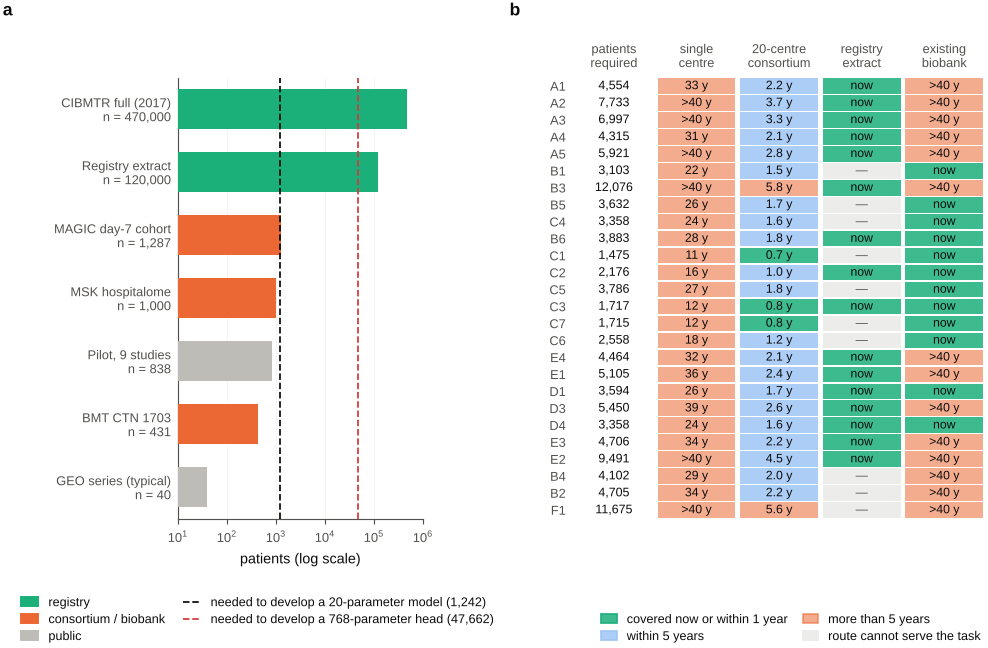

[saved] figures/Fig12_data_landscape_and_accrual.pdf  +  figures/Fig12_data_landscape_and_accrual.png


In [46]:
# ----------------------------------------------------------------------------- accrual projection: years to reach the required n, by route
ROUTES = [  # name, patients per year contributing to a Tier-C-grade task, tier reachable, retrospective back-catalogue
    ('single centre, prospective',        200 * .70,  'A+B+C', 0),
    ('20-centre consortium, prospective', 3000 * .70, 'A+B+C', 0),
    ('registry extract (CIBMTR/EBMT)',    10000.0,    'A+B',   120000),
    ('existing biobank (MAGIC/BMT CTN)',  0.0,        'A+B+C', 4000),
]
need_tbl = reg_full.dropna(subset=['n to show +0.03']).copy()
need_tbl['n required'] = need_tbl[['n to develop (50-param)', 'n to show +0.03']].max(axis=1)
rows = []
for _, r in need_tbl.iterrows():
    tier_need = str(r['tier needed'])
    for name, rate, tier_ok, backlog in ROUTES:
        deep_needed = ('C' in tier_need) or ('D' in tier_need)
        route_has_deep = 'C' in tier_ok
        if deep_needed and not route_has_deep:
            yrs = np.nan                                     # this route cannot serve this task at all
        else:
            remaining = max(r['n required'] - backlog, 0)
            yrs = 0.0 if remaining == 0 else (remaining / rate if rate > 0 else np.inf)
        rows.append(dict(task=r.id, route=name, **{'n required': int(r['n required']), 'years': yrs}))
acc = pd.DataFrame(rows)
piv_acc = acc.pivot(index='task', columns='route', values='years')
piv_acc = piv_acc.reindex([c[0] for c in ROUTES], axis=1)
fmt = piv_acc.copy()
for c in fmt.columns:
    fmt[c] = [('—' if not np.isfinite(v) and np.isnan(v) else ('never' if v == np.inf else ('now' if v == 0 else f'{v:.1f} y')))
              for v in piv_acc[c]]
fmt.insert(0, 'n required', need_tbl.set_index('id').loc[fmt.index, 'n required'].astype(int).values)
display(md_table(fmt.reset_index()))

# ------------------------------------------------- Figure 12: what exists against what is needed, and how long it would take
FWIN, FHIN = FULL, 4.6
fig = plt.figure(figsize=(FWIN, FHIN))
axa = fig.add_axes([1.33 / FWIN, .95 / FHIN, 1.75 / FWIN, 3.15 / FHIN])
axb = fig.add_axes([4.15 / FWIN, .95 / FHIN, 2.95 / FWIN, 3.15 / FHIN])
SRC = [('CIBMTR full (2017)', 470000, PAL['aqua']), ('Registry extract', 120000, PAL['aqua']), ('MAGIC day-7 cohort', 1287, PAL['orange']),
       ('MSK hospitalome', 1000, PAL['orange']), ('Pilot, 9 studies', 838, PAL['grey2']), ('BMT CTN 1703', 431, PAL['orange']),
       ('GEO series (typical)', 40, PAL['grey2'])]
ax = axa; ygrid(ax, 'x')
ax.barh(range(len(SRC)), [v for _, v, _ in SRC], color=[c for _, _, c in SRC], height=.62, zorder=3)
ax.set_yticks(range(len(SRC))); ax.set_yticklabels([f'{n}\nn = {v:,}' for n, v, _ in SRC]); ax.tick_params(axis='y', length=0)
ax.set_xscale('log'); ax.set_xlim(10, 1e6); ax.set_ylim(len(SRC) - .5, -.5); ax.minorticks_off()
n20, n768 = riley_n(20, .72, .35)['n'], riley_n(768, .72, .35)['n']
ax.axvline(n20, color=PAL['ink'], ls='--', lw=.9, zorder=4); ax.axvline(n768, color=PAL['bad'], ls='--', lw=.9, zorder=4)
ax.set_xlabel('patients (log scale)')
ax.annotate('a', (0, 1), xycoords='axes fraction', xytext=(-1.25 * 72, 32), textcoords='offset points', fontsize=9, fontweight='bold')
fig.legend([plt.Rectangle((0, 0), 1, 1, color=PAL['aqua']), plt.Rectangle((0, 0), 1, 1, color=PAL['orange']), plt.Rectangle((0, 0), 1, 1, color=PAL['grey2']),
            plt.Line2D([], [], color=PAL['ink'], ls='--', lw=.9), plt.Line2D([], [], color=PAL['bad'], ls='--', lw=.9)],
           ['registry', 'consortium / biobank', 'public', f'needed to develop a 20-parameter model ({n20:,})',
            f'needed to develop a 768-parameter head ({n768:,})'], ncol=2, loc='lower left', bbox_to_anchor=(.02, .0),
           columnspacing=1.4, handlelength=1.4, labelspacing=.4)
# (b) years to reach the required n, task by task and route, as a matrix
ROUTE_NAMES = ['single\ncentre', '20-centre\nconsortium', 'registry\nextract', 'existing\nbiobank']
RT = ['single centre, prospective', '20-centre consortium, prospective', 'registry extract (CIBMTR/EBMT)', 'existing biobank (MAGIC/BMT CTN)']
tbl = piv_acc[RT].copy(); tbl['best'] = tbl.min(axis=1, skipna=True); tbl = tbl.sort_values('best').drop(columns='best')
nreq = need_tbl.set_index('id')['n required']
def cls(v):
    if np.isnan(v): return 3
    if v == 0: return 0
    return 0 if v <= 1 else 1 if v <= 5 else 2
def txt(v):
    if np.isnan(v): return '—'
    if v == 0: return 'now'
    return '>40 y' if v > 40 else (f'{v:.1f} y' if v < 10 else f'{v:.0f} y')
ax = axb
CELLC = [PAL['aqua'], PAL['seq'][0], PAL['orange'], '#ececea']; CELLA = [.85, .85, .55, 1.0]
nr, nc = len(tbl), 5
for i, (tid, row) in enumerate(tbl.iterrows()):
    ax.text(0.5, i, f'{int(nreq[tid]):,}', ha='center', va='center', fontsize=6.4, color=PAL['ink'])
    for j, rt in enumerate(RT):
        v = row[rt]; ax.add_patch(plt.Rectangle((j + 1.03, i - .46), .94, .92, color=CELLC[cls(v)], alpha=CELLA[cls(v)], lw=0))
        _t = ax.text(j + 1.5, i, txt(v), ha='center', va='center', fontsize=6.3, color=PAL['ink'] if cls(v) != 3 else PAL['ink2'])
        _t._ok_overlap = True      # the label belongs to this cell
ax.set_xlim(0, nc); ax.set_ylim(nr - .5, -.5)
ax.set_yticks(range(nr)); ax.set_yticklabels(tbl.index); ax.tick_params(axis='y', length=0)
ax.xaxis.tick_top(); ax.set_xticks(np.arange(nc) + .5); ax.set_xticklabels(['patients\nrequired'] + ROUTE_NAMES); ax.tick_params(axis='x', length=0)
for sp in ax.spines.values(): sp.set_visible(False)
ax.annotate('b', (0, 1), xycoords='axes fraction', xytext=(-.45 * 72, 32), textcoords='offset points', fontsize=9, fontweight='bold')
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c, alpha=a) for c, a in zip(CELLC, CELLA)],
           ['covered now or within 1 year', 'within 5 years', 'more than 5 years', 'route cannot serve the task'],
           ncol=2, loc='lower right', bbox_to_anchor=(.99, .0), columnspacing=1.2, handlelength=1.2, labelspacing=.4)
finish(fig, 12, 'data_landscape_and_accrual',
       'What exists against what is needed, and how long it would take. (a) Patients available from each real source on a log scale, '
       'against the Riley minimum for two head sizes: public transcriptomic resources are orders of magnitude short, registry extracts are '
       'not. (b) Projected time to reach the patients required for each task, by route. Tasks that need protocolised biospecimens cannot '
       'be served by a registry extract at all, which is why the staged plan buys the registry tasks first and the biobank tasks second.')

In [47]:
reg_now = int((piv_acc['registry extract (CIBMTR/EBMT)'] == 0).sum())
cons_5y = int((piv_acc['20-centre consortium, prospective'] <= 5).sum())
sc_5y = int((piv_acc['single centre, prospective'] <= 5).sum())
display(Markdown(f"""**Result.** Of the {len(piv_acc)} tasks with a numeric target, **{reg_now} are already satisfied by the historical back-catalogue of a registry extract** — no waiting, no new collection, only a data-use agreement. A **20-centre consortium reaches {cons_5y} of them within five years**; a **single centre reaches {sc_5y}**, which is the quantitative case for a consortium rather than a local study.

**The strategic ordering falls out of the arithmetic.** Buy the registry tasks first (they are free in time and need only governance), use an existing biobank for the day-7 biomarker tasks (MAGIC-scale specimens already exist), and start prospective collection *now* for the tasks nothing can shortcut — the adjudicated differential-diagnosis set (C1, C2) and the treated-patient response cohorts (C4, C5) — because those are the ones whose clock has not started. That ordering is §11's staged plan, and this projection is its justification."""))

**Result.** Of the 26 tasks with a numeric target, **16 are already satisfied by the historical back-catalogue of a registry extract** — no waiting, no new collection, only a data-use agreement. A **20-centre consortium reaches 24 of them within five years**; a **single centre reaches 0**, which is the quantitative case for a consortium rather than a local study.

**The strategic ordering falls out of the arithmetic.** Buy the registry tasks first (they are free in time and need only governance), use an existing biobank for the day-7 biomarker tasks (MAGIC-scale specimens already exist), and start prospective collection *now* for the tasks nothing can shortcut — the adjudicated differential-diagnosis set (C1, C2) and the treated-patient response cohorts (C4, C5) — because those are the ones whose clock has not started. That ordering is §11's staged plan, and this projection is its justification.

## 9.4 The transcriptome at diagnosis: how many labelled profiles?

§3.3 said what a transcriptomic profile can support. This section says **how many labelled profiles it takes**, and the answer turns on one quantity: the number of free parameters the model has to estimate from those labels.

**The model.** Take a linear head trained on *n* labelled transcriptomes pooled over *K* centres and scored at a *new* centre. Let the signal it is trying to learn have squared separation $I$ (so that a head that knew it exactly would reach AUROC $=\Phi(\sqrt{I/2})$), let $D_0^2$ be the separation already carried by a baseline score it is added to (zero if there is none), let $\rho$ be the fraction of the signal shared across centres, and let $p_{\rm eff}$ be the **effective number of parameters the head must estimate**. Then, for prevalence $\pi$,

$$\mathrm{AUROC}(n)\;=\;\Phi\!\left(\frac{D_0^2+\rho I}{\sqrt2\,\sqrt{D_0^2+\rho I+(1-\rho)I/K+p_{\rm eff}/\big(\pi(1-\pi)\,n\big)}}\right).$$

This is the learning curve of a plug-in linear classifier (Raudys–Duin type): the numerator is the signal the head captures, and the last term in the denominator is the noise from estimating $p_{\rm eff}$ weights from *n* patients. Three things follow at once. **(i)** The required *n* is proportional to $p_{\rm eff}$ — the same proportionality as Riley's *P* in §9.1. **(ii)** With $\rho<1$ there is a **plateau** below the within-centre ceiling that no amount of data removes. **(iii)** What a foundation model offers is a way to shrink $p_{\rm eff}$ — a 64-dimensional embedding instead of 15,000 genes — at the price of keeping only a fraction $\kappa$ of the signal.

We check the formula against simulation before using it.

In [48]:
# ----------------------------------------------------------------------------- 9.4: learning curve of a linear head trained on n labelled transcriptomes
def sep2(A): return 2 * norm.ppf(A) ** 2                      # squared Mahalanobis separation of a binormal score with AUROC A
def auc_lc(n, D0sq, Isq, p_eff, prev=.30, rho=1.0, K=8):
    """AUROC at a NEW centre of [known baseline score] + [linear head learned from n labelled transcriptomes pooled over K centres]."""
    num = D0sq + rho * Isq
    den = math.sqrt(D0sq + rho * Isq + (1 - rho) * Isq / K + p_eff / (prev * (1 - prev) * n))
    return float(norm.cdf(num / (math.sqrt(2) * den)))
def n_for_target(target, A0, A1, p_eff, prev=.30, rho=1.0, K=8, kappa=1.0):
    """Smallest n with AUROC(n) >= target for a head whose signal is a fraction kappa of the ceiling gain A0 -> A1 (inf if the plateau is below target)."""
    D0, I = sep2(A0) if A0 > .5 else 0.0, kappa * (sep2(A1) - (sep2(A0) if A0 > .5 else 0.0))
    if auc_lc(1e15, D0, I, p_eff, prev, rho, K) < target - 1e-9: return float('inf')
    lo, hi = math.log(5), math.log(1e10)
    for _ in range(80):
        mid = (lo + hi) / 2
        if auc_lc(math.exp(mid), D0, I, p_eff, prev, rho, K) < target: lo = mid
        else: hi = mid
    return math.exp(hi)

# ---------- validation 1: the formula against simulated nearest-centroid heads (isotropic Gaussian data; the case where it is exact)
def sim_lc(n, A1, A0, p, rho, K, prev=.30, reps=6, seed=0):
    D0, I = (math.sqrt(sep2(A0)) if A0 > .5 else 0.0), sep2(A1) - (sep2(A0) if A0 > .5 else 0.0); D = math.sqrt(I); out = []
    for s in range(reps):
        r = np.random.default_rng(seed + 97 * s); unit = lambda: (lambda v: v * D / np.linalg.norm(v))(r.standard_normal(p))
        mu0 = unit(); mus = [math.sqrt(rho) * mu0 + math.sqrt(1 - rho) * unit() for _ in range(K)]; mus = [m * D / np.linalg.norm(m) for m in mus]
        per = n // K; X, Y, Z = [], [], []
        for m in mus:
            y = (r.random(per) < prev).astype(int); X.append(r.standard_normal((per, p)) + np.outer(y, m)); Y.append(y)
        X, Y = np.vstack(X), np.concatenate(Y)
        if min(np.bincount(Y, minlength=2)) < 2: continue
        w = X[Y == 1].mean(0) - X[Y == 0].mean(0)
        mt = math.sqrt(rho) * mu0 + math.sqrt(1 - rho) * unit(); mt *= D / np.linalg.norm(mt)
        yt = (r.random(4000) < prev).astype(int); xt = r.standard_normal((4000, p)) + np.outer(yt, mt); zt = D0 * (r.standard_normal(4000) + D0 * yt)
        out.append(roc_auc_score(yt, xt @ w + (D0 * (zt / max(D0, 1e-9)) if D0 > 0 else 0)))
    return float(np.mean(out))
VAL_LC = [(.80, .5, 400, 1.0), (.80, .5, 400, .6), (.85, .5, 1000, 1.0), (.85, .5, 1000, .3), (.75, .5, 200, 1.0), (.78, .72, 64, 1.0), (.78, .72, 64, .7)]
vrows = []
for A1_, A0_, p_, rho_ in VAL_LC:
    for n_ in (64, 256, 1024, 4096):
        f_ = auc_lc(n_, sep2(A0_) if A0_ > .5 else 0, sep2(A1_) - (sep2(A0_) if A0_ > .5 else 0), p_, .30, rho_, 8)
        s_ = sim_lc(n_, A1_, A0_, p_, rho_, 8, reps=6 if not QUICK else 3); vrows.append(dict(ceiling=A1_, baseline=A0_, p=p_, rho=rho_, n=n_, formula=f_, simulated=s_, diff=s_ - f_))
vlc = pd.DataFrame(vrows)
print(f'learning-curve formula vs simulation: {len(vlc)} comparisons, mean |diff| {vlc["diff"].abs().mean():.3f}, max {vlc["diff"].abs().max():.3f}')
assert vlc['diff'].abs().max() < (.025 if not QUICK else .04), 'learning-curve formula disagrees with its simulation'

# ---------- validation 2 (stress test): correlated nuisance structure (cell composition, batch) and a ridge head with its penalty chosen by closed-form leave-one-out
def ridge_loo(X, y):
    mu, sd = X.mean(0), X.std(0) + 1e-8; Z = (X - mu) / sd; t = 2. * y - 1; tc = t - t.mean()
    U, s, Vt = np.linalg.svd(Z, full_matrices=False); Uty = U.T @ tc; best = (1e18, None)
    for a in np.logspace(0, 5, 11):
        f = s ** 2 / (s ** 2 + a); loo = np.mean(((tc - U @ (f * Uty)) / (1 - (U ** 2) @ f)) ** 2)
        if loo < best[0]: best = (loo, a)
    w = Vt.T @ (s / (s ** 2 + best[1]) * Uty); return lambda Xn: ((Xn - mu) / sd) @ w
def stress_curve(A1, m_info, p=600, q=40, K=8, prev=.30, ns=(64, 128, 256, 512, 1024, 2048), reps=3, seed=0):
    D = math.sqrt(sep2(A1)); res = {n: [] for n in ns}
    for s in range(reps):
        r = np.random.default_rng(seed + 31 * s); Lam = r.standard_normal((p, q)) * 1.2 / math.sqrt(q); Sig = Lam @ Lam.T + np.eye(p); Sinv = np.linalg.inv(Sig); Lc = np.linalg.cholesky(Sig)
        supp = r.choice(p, m_info, replace=False); mu = np.zeros(p); mu[supp] = r.standard_normal(m_info); mu *= D / math.sqrt(mu @ Sinv @ mu)
        def draw(n, rr):
            y = (rr.random(n) < prev).astype(int); return rr.standard_normal((n, p)) @ Lc.T + np.outer(y, mu) + rr.normal(0, .3, p), y
        pool = [draw(max(ns) // K, np.random.default_rng(1000 * s + c)) for c in range(K)]; xt, yt = draw(1500, np.random.default_rng(10 ** 6 + s))
        for n in ns:
            X = np.vstack([a[0][:n // K] for a in pool]); Y = np.concatenate([a[1][:n // K] for a in pool])
            res[n].append(roc_auc_score(yt, ridge_loo(X, Y)(xt)))
    return {n: float(np.mean(v)) for n, v in res.items()}
from scipy.optimize import minimize_scalar
def fit_peff(curve, A1, prev=.30):
    ns_, vs_ = list(curve), list(curve.values()); f = lambda lp: sum((auc_lc(n, 0, sep2(A1), math.exp(lp), prev, 1.0, 8) - v) ** 2 for n, v in zip(ns_, vs_))
    r = minimize_scalar(f, bounds=(0, 14), method='bounded'); return math.exp(r.x), math.sqrt(r.fun / len(ns_))
srows = []
for m_ in (15, 60, 250):
    c_ = stress_curve(.80, m_, reps=3 if not QUICK else 2); pe_, rm_ = fit_peff(c_, .80)
    srows.append(dict(informative_genes=m_, genes=600, fitted_p_eff=pe_, p_eff_over_p=pe_ / 600, rmse_of_fit=rm_))
stress = pd.DataFrame(srows); MULT = float(stress.p_eff_over_p.mean())
print('stress test (correlated nuisance structure; ridge head with LOO-chosen penalty): the learning curve is still described by the same formula,\n'
      'with an effective dimension of about p x', f'{MULT:.1f}', '- regardless of how sparse the signal is, because a ridge penalty does not exploit sparsity:')
display(md_table(stress.round(3)))

learning-curve formula vs simulation: 28 comparisons, mean |diff| 0.005, max 0.010


stress test (correlated nuisance structure; ridge head with LOO-chosen penalty): the learning curve is still described by the same formula,
with an effective dimension of about p x 2.7 - regardless of how sparse the signal is, because a ridge penalty does not exploit sparsity:


| informative_genes | genes | fitted_p_eff | p_eff_over_p | rmse_of_fit |
|---|---|---|---|---|
| 15 | 600 | 1681.456 | 2.802 | 0.024 |
| 60 | 600 | 1416.765 | 2.361 | 0.03 |
| 250 | 600 | 1839.572 | 3.066 | 0.028 |

In [49]:
# ----------------------------------------------------------------------------- 9.4: what a foundation-model adapter buys, in labelled profiles
GENES = 15_000
HEADS = [  # name, p_eff, kappa (fraction of the signal retained), note
 ('pre-specified pathway scores (≈10)',            10,              .70, 'head sees a handful of fixed scores; keeps part of the signal'),
 ('foundation-model adapter embedding (64-d)',     64,              .90, 'head sees a learned 64-d embedding; kappa is an ASSUMPTION that task G4 / F2 measure'),
 ('selected gene panel (500 genes)',               500 * MULT,      .95, 'a ridge/logistic head on 500 genes; effective dimension inflated by nuisance structure'),
 ('whole transcriptome (15,000 genes)',            GENES * MULT,    1.0, 'a ridge/logistic head on every gene'),
]
def plan_row(name, p_eff, kappa, A1, prev=.30, eps=.02, rho=1.0, K=8):
    I = kappa * sep2(A1); plateau = auc_lc(1e15, 0, I, p_eff, prev, rho, K)
    return plateau, n_for_target(plateau - eps, .5, A1, p_eff, prev, rho, K, kappa)
plan = []
for name, pe, kap, note in HEADS:
    row = dict(head=name, p_eff=f'{pe:,.0f}', kappa=kap)
    for A1 in (.75, .88):
        pl, n_ = plan_row(name, pe, kap, A1); row[f'ceiling {A1:.2f}: plateau'] = f'{pl:.3f}'; row[f'ceiling {A1:.2f}: n within 0.02 of it'] = f'{n_:,.0f}'
    plan.append(row)
plan = pd.DataFrame(plan)
print('LABELLED TRANSCRIPTOMES NEEDED to come within 0.02 AUROC of what each head can reach (prevalence 0.30, single-centre ρ = 1, K = 8):'); display(md_table(plan))
n_whole = plan_row(*HEADS[3][:3], .88)[1]; n_adapt = plan_row(*HEADS[1][:3], .88)[1]; n_whole75 = plan_row(*HEADS[3][:3], .75)[1]; n_adapt75 = plan_row(*HEADS[1][:3], .75)[1]
print(f'at ceiling 0.88 the adapter head needs {n_adapt:,.0f} labelled profiles versus {n_whole:,.0f} for the whole-transcriptome head ({n_whole / n_adapt:,.0f}x fewer)')

# the incremental question: labelled profiles for a transcriptome adapter to ADD to a strong clinical baseline (ρ = 0.8 across K = 8 centres)
TXT = [  # task, what is added, baseline AUROC, ceiling AUROC with the transcriptome, prevalence
 ('C1/C2  GvHD vs infection / drug (tissue + clinical)', .75, .86, .45), ('C4  steroid refractoriness (onset sample)', .66, .74, .30),
 ('C5  day-28 response (onset sample)', .64, .72, .35), ('B1  + day-7 blood transcriptome on MAP + clinical', .72, .76, .35),
 ('E1  + day-100 blood transcriptome (cGvHD)', .65, .69, .30)]
trows = []
for name, A0, A1, pv in TXT:
    r_ = dict(task=name, baseline=A0, ceiling=A1, prevalence=pv)
    for lab, rho_, K_ in (('ρ = 1', 1.0, 8), ('ρ = 0.8, K = 8', .8, 8)):
        plat = auc_lc(1e15, sep2(A0), .9 * (sep2(A1) - sep2(A0)), 64, pv, rho_, K_)
        r_[f'n for +0.02 ({lab})'] = n_for_target(A0 + .02, A0, A1, 64, pv, rho_, K_, .9)
        r_[f'realisable gain ({lab})'] = plat - A0
        r_[f'n for 80% of it ({lab})'] = n_for_target(A0 + .80 * (plat - A0), A0, A1, 64, pv, rho_, K_, .9)
        r_[f'n for 95% of it ({lab})'] = n_for_target(A0 + .95 * (plat - A0), A0, A1, 64, pv, rho_, K_, .9)
    trows.append(r_)
txt_tab = pd.DataFrame(trows)
txt_disp = txt_tab.copy()
for c in txt_disp.columns[4:]: txt_disp[c] = txt_disp[c].map(lambda v: ('+' + f'{v:.3f}') if 'gain' in c else ('not reachable' if not np.isfinite(v) else f'{v:,.0f}'))
print('LABELLED PROFILES FOR AN ADAPTER (64-d, κ = 0.9) TO ADD TO A BASELINE ("realisable gain" = the plateau of the added AUROC at that ρ):'); display(md_table(txt_disp))
def min_ceiling_gain(A0, want=.03, rho=.8, K=8, kappa=.9, pv=.30):
    for g in np.arange(.02, .30, .0025):
        if np.isfinite(n_for_target(A0 + want, A0, A0 + g, 64, pv, rho, K, kappa)): return float(g)
G_STAR = min_ceiling_gain(.72)

LABELLED TRANSCRIPTOMES NEEDED to come within 0.02 AUROC of what each head can reach (prevalence 0.30, single-centre ρ = 1, K = 8):


| head | p_eff | kappa | ceiling 0.75: plateau | ceiling 0.75: n within 0.02 of it | ceiling 0.88: plateau | ceiling 0.88: n within 0.02 of it |
|---|---|---|---|---|---|---|
| pre-specified pathway scores (≈10) | 10 | 0.7 | 0.714 | 310 | 0.837 | 136 |
| foundation-model adapter embedding (64-d) | 64 | 0.9 | 0.739 | 1,698 | 0.868 | 678 |
| selected gene panel (500 genes) | 1,372 | 0.95 | 0.745 | 35,127 | 0.874 | 13,701 |
| whole transcriptome (15,000 genes) | 41,148 | 1.0 | 0.750 | 1,018,604 | 0.880 | 387,913 |

at ceiling 0.88 the adapter head needs 678 labelled profiles versus 387,913 for the whole-transcriptome head (572x fewer)
LABELLED PROFILES FOR AN ADAPTER (64-d, κ = 0.9) TO ADD TO A BASELINE ("realisable gain" = the plateau of the added AUROC at that ρ):


| task | baseline | ceiling | prevalence | n for +0.02 (ρ = 1) | realisable gain (ρ = 1) | n for 80% of it (ρ = 1) | n for 95% of it (ρ = 1) | n for +0.02 (ρ = 0.8, K = 8) | realisable gain (ρ = 0.8, K = 8) | n for 80% of it (ρ = 0.8, K = 8) | n for 95% of it (ρ = 0.8, K = 8) |
|---|---|---|---|---|---|---|---|---|---|---|---|
| C1/C2  GvHD vs infection / drug (tissue + clinical) | 0.75 | 0.86 | 0.45 | 117 | +0.102 | 639 | 2,725 | 177 | +0.085 | 863 | 3,655 |
| C4  steroid refractoriness (onset sample) | 0.66 | 0.74 | 0.3 | 501 | +0.074 | 2,466 | 10,619 | 781 | +0.060 | 3,254 | 13,874 |
| C5  day-28 response (onset sample) | 0.64 | 0.72 | 0.35 | 506 | +0.074 | 2,580 | 11,197 | 793 | +0.060 | 3,399 | 14,590 |
| B1  + day-7 blood transcriptome on MAP + clinical | 0.72 | 0.76 | 0.35 | 1,746 | +0.036 | 4,167 | 17,215 | 3,450 | +0.029 | 5,465 | 22,444 |
| E1  + day-100 blood transcriptome (cGvHD) | 0.65 | 0.69 | 0.3 | 2,931 | +0.036 | 7,173 | 30,020 | 5,832 | +0.029 | 9,394 | 39,007 |

In [50]:
# ----------------------------------------------------------------------------- 9.4: unlabelled pretraining corpora and the assay specification
CORP = [('public bulk RNA-seq, all tissues (ARCHS4 / recount3 scale) †', 1_000_000), ('public blood and immune-cell bulk RNA-seq †', 200_000), ('GvHD-specific public series (the pilot of §10)', 838)]
TOK_PER_SAMPLE = 2000                                  # one token per expressed gene, rank-encoded, top 2,000 per sample
crow = []
for name, ns_ in CORP:
    Dc = ns_ * TOK_PER_SAMPLE; Nc = Dc / 20; hrs = a100_hours(train_flops(Nc, Dc))
    crow.append({'unlabelled corpus': name, 'samples': f'{ns_:,}', 'tokens': fmt_n(Dc), 'compute-optimal adapter size': fmt_n(Nc), 'A100-hours': fmt_h(hrs)})
print('UNLABELLED PRETRAINING CORPUS FOR A TRANSCRIPTOME ADAPTER:'); display(md_table(pd.DataFrame(crow)))
# depth and detection: lognormal gene abundance, negative-binomial counts; reliability of a 50-gene score between technical replicates
rg = np.random.default_rng(3); frac_g = np.exp(rg.normal(math.log(1e-5), 1.8, 20000)); frac_g /= frac_g.sum() / 1.0
sig = rg.choice(np.where(5e6 * frac_g >= 1)[0], 50, replace=False)             # one fixed 50-gene signature, scored at every depth
drows = []
for R in (5e6, 10e6, 20e6, 40e6, 80e6):
    mu_g = R * frac_g; det = float((mu_g >= 10).mean())
    tech = float(np.mean(1 / mu_g[sig] + .02) / 50)                                                                    # technical variance of the mean log-score
    bio = .16 * (.3 + .7 / 50)                                                                                          # between-patient variance of a pathway score (gene SD .4, mean inter-gene correlation .3)
    drows.append({'reads per sample': f'{R / 1e6:.0f} M', 'genes with >= 10 counts': f'{det:.0%}', 'reliability of a 50-gene pathway score': f'{bio / (bio + tech):.3f}'})
print('DEPTH (assumed gene-abundance model †):'); display(md_table(pd.DataFrame(drows)))

UNLABELLED PRETRAINING CORPUS FOR A TRANSCRIPTOME ADAPTER:


| unlabelled corpus | samples | tokens | compute-optimal adapter size | A100-hours |
|---|---|---|---|---|
| public bulk RNA-seq, all tissues (ARCHS4 / recount3 scale) † | 1,000,000 | 2B | 100M | 21 h |
| public blood and immune-cell bulk RNA-seq † | 200,000 | 400M | 20M | 0.94 h |
| GvHD-specific public series (the pilot of §10) | 838 | 1.68M | 83.8k | <0.01 h |

DEPTH (assumed gene-abundance model †):


| reads per sample | genes with >= 10 counts | reliability of a 50-gene pathway score |
|---|---|---|
| 5 M | 82% | 0.961 |
| 10 M | 90% | 0.977 |
| 20 M | 95% | 0.984 |
| 40 M | 98% | 0.988 |
| 80 M | 99% | 0.990 |

[layout PASS] Fig 13: 55 text items, 0 collisions, 0 below 6 pt (smallest 6.3 pt)


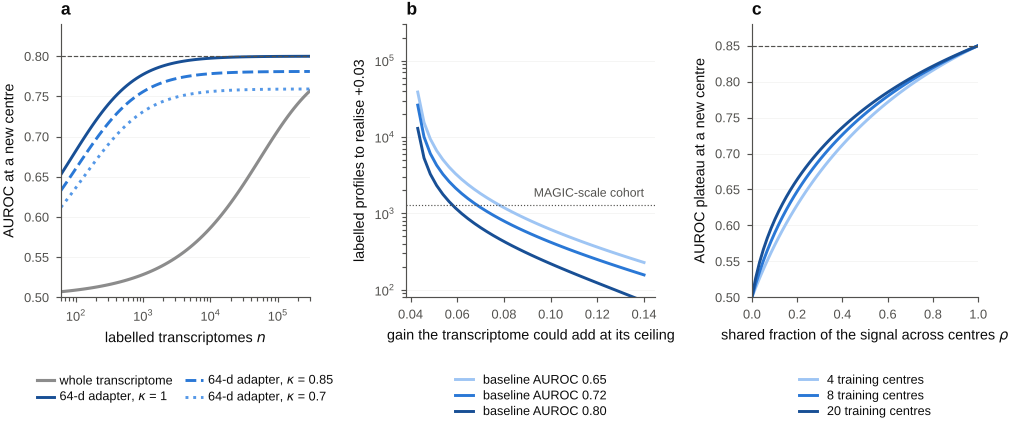

[saved] figures/Fig13_transcriptome_requirements.pdf  +  figures/Fig13_transcriptome_requirements.png


In [51]:
# ----------------------------------------------------------------------------- Figure 13: how many labelled transcriptomes?
fig = plt.figure(figsize=(FULL, 3.2))
gs = fig.add_gridspec(1, 3, width_ratios=[1.1, 1.1, 1.0], left=.075, right=.985, bottom=.265, top=.875, wspace=.40)
ax = fig.add_subplot(gs[0, 0]); ygrid(ax)                                       # (a) learning curves: raw genes vs adapter embeddings
nn = np.geomspace(60, 3e5, 80); A1_ = .80
raw_p = GENES * MULT; I_ = sep2(A1_)
ax.plot(nn, [auc_lc(n, 0, I_, raw_p) for n in nn], color=PAL['grey'], lw=1.6, label='whole transcriptome')
for kap, c, ls_ in ((1.0, PAL['seq'][3], '-'), (.85, PAL['seq'][2], '--'), (.7, PAL['seq'][1], ':')):
    ax.plot(nn, [auc_lc(n, 0, kap * I_, 64) for n in nn], color=c, lw=1.5, ls=ls_, label=f'64-d adapter, $\\kappa$ = {kap:g}')
ax.axhline(A1_, color=PAL['ink2'], lw=.6, ls='--'); ax.set_xscale('log'); ax.set_xlim(60, 3e5); ax.set_ylim(.5, .84)
ax.set_xlabel('labelled transcriptomes $n$'); ax.set_ylabel('AUROC at a new centre'); panel(ax, 'a')
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.25), ncol=2, columnspacing=1.0, handlelength=1.4, handletextpad=.4, labelspacing=.3)
ax = fig.add_subplot(gs[0, 1]); ygrid(ax)                                       # (b) labelled profiles needed to add a gain to a baseline
gains = np.linspace(.035, .14, 40)
for A0, c in ((.65, PAL['seq'][0]), (.72, PAL['seq'][2]), (.80, PAL['seq'][3])):
    ys = [n_for_target(A0 + .03, A0, A0 + g, 64, .30, .8, 8, .9) for g in gains]; ys = [y if np.isfinite(y) else np.nan for y in ys]
    ax.plot(gains, ys, color=c, lw=1.5, label=f'baseline AUROC {A0:.2f}')
ax.axhline(1287, color=PAL['ink2'], lw=.6, ls=':'); ax.set_yscale('log'); ax.set_ylim(80, 3e5)
ax.set_xlabel('gain the transcriptome could add at its ceiling'); ax.set_ylabel('labelled profiles to realise +0.03'); panel(ax, 'b')
ax.annotate('MAGIC-scale cohort', (.14, 1287), xytext=(0, 3), textcoords='offset points', fontsize=6.3, color=PAL['ink2'], ha='right', va='bottom')
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.25), ncol=1, handlelength=1.4, labelspacing=.3)
ax = fig.add_subplot(gs[0, 2]); ygrid(ax)                                       # (c) the plateau set by cross-centre sharing
rr_ = np.linspace(0, 1, 60); D_ = math.sqrt(sep2(.85))
for K_, c in ((4, PAL['seq'][0]), (8, PAL['seq'][2]), (20, PAL['seq'][3])):
    ax.plot(rr_, [norm.cdf((D_ / math.sqrt(2)) * r / math.sqrt(r + (1 - r) / K_)) if r > 0 else .5 for r in rr_], color=c, lw=1.5)
    ax.annotate(f'K = {K_}', (1.0, norm.cdf((D_ / math.sqrt(2)) * (.30) / math.sqrt(.30 + .70 / K_))), xytext=(0, 0), textcoords='offset points', fontsize=6.3, color=c, ha='left', va='center', annotation_clip=False) if False else None
ax.axhline(.85, color=PAL['ink2'], lw=.6, ls='--'); ax.set_xlabel('shared fraction of the signal across centres $\\rho$'); ax.set_ylabel('AUROC plateau at a new centre'); ax.set_ylim(.5, .88); ax.set_xlim(0, 1)
ax.legend([plt.Line2D([], [], color=c, lw=1.5) for c in (PAL['seq'][0], PAL['seq'][2], PAL['seq'][3])], ['4 training centres', '8 training centres', '20 training centres'],
          loc='upper center', bbox_to_anchor=(.5, -.25), ncol=1, handlelength=1.4, labelspacing=.3); panel(ax, 'c')
finish(fig, 13, 'transcriptome_requirements',
       "Labelled transcriptomes needed at diagnosis (closed form, validated against simulation in §9.4). (a) Learning curve of a head on the whole transcriptome "
       "against heads on a 64-dimensional adapter embedding that retains a fraction kappa of the signal: the embedding wins at the label counts a consortium can "
       "reach, and the whole-transcriptome head approaches its ceiling only at several hundred thousand profiles. Dashed: the within-centre ceiling. (b) Labelled "
       "profiles an adapter needs to add +0.03 AUROC to a baseline, against the gain the transcriptome could add at its ceiling; a weak ceiling gain cannot be "
       "realised at any n once centres only partly share the signal. (c) The plateau at a new centre falls as the shared fraction rho falls, and more training "
       "centres push it toward its limit.")

In [52]:
b1 = txt_tab[txt_tab.task.str.startswith('B1')].iloc[0]; c4_ = txt_tab[txt_tab.task.str.startswith('C4')].iloc[0]
display(Markdown(f"""**Reading §9.4.** Three results, each computed above.

1. **The transcriptome is label-hungry unless something shrinks the dimension.** A head on the whole transcriptome needs **{min(n_whole, n_whole75):,.0f}–{max(n_whole, n_whole75):,.0f}** labelled profiles (ceiling 0.88 and 0.75) to come within 0.02 AUROC of its ceiling, and the stress test shows the real requirement exceeds the isotropic formula because cell composition and batch inflate the effective dimension by a factor of **{stress.p_eff_over_p.min():.1f}–{stress.p_eff_over_p.max():.1f}**. No public GvHD resource and no single consortium can supply that. This is the quantitative reason for the pilot's negative result on blood (§10), and it is independent of the architecture.
2. **A good adapter changes the arithmetic.** If a pretrained 64-dimensional embedding retains 90 % of the signal, the same target needs **{min(n_adapt, n_adapt75):,.0f}–{max(n_adapt, n_adapt75):,.0f}** labelled profiles, **{n_whole / n_adapt:,.0f}×** fewer at ceiling 0.88. That *is* the label-efficiency claim of a foundation model, now with a number on it. Its price is the retained fraction κ: panel (a) shows an embedding that keeps only 70 % of the signal still wins at every label count a consortium can reach but plateaus lower, and tasks F2 and G4 measure κ directly.
3. **A transcriptome adds a *small* increment to a *strong* baseline, and small increments are expensive.** For a day-7 blood transcriptome to add +0.02 to MAP plus clinical covariates (baseline 0.72, ceiling 0.76) an adapter needs **{b1['n for +0.02 (ρ = 1)']:,.0f}** labelled profiles from one centre and **{b1['n for +0.02 (ρ = 0.8, K = 8)']:,.0f}** across eight centres sharing 80 % of the signal, and the gain it can ever realise there is only **+{b1['realisable gain (ρ = 0.8, K = 8)']:.3f}**. To add +0.03 to a 0.72 baseline at all, the transcriptome must carry a ceiling gain of at least **+{G_STAR:.3f}**. By contrast, in tissue the same machinery needs only **{txt_tab.iloc[0]['n for +0.02 (ρ = 0.8, K = 8)']:,.0f}** profiles for +0.02 (C1/C2) and **{c4_['n for +0.02 (ρ = 0.8, K = 8)']:,.0f}** for steroid refractoriness (C4). This is why the paper claims the transcriptome adds value at diagnosis (tissue in hand, high ceiling) and does not claim it for pre-onset blood prognosis."""))

**Reading §9.4.** Three results, each computed above.

1. **The transcriptome is label-hungry unless something shrinks the dimension.** A head on the whole transcriptome needs **387,913–1,018,604** labelled profiles (ceiling 0.88 and 0.75) to come within 0.02 AUROC of its ceiling, and the stress test shows the real requirement exceeds the isotropic formula because cell composition and batch inflate the effective dimension by a factor of **2.4–3.1**. No public GvHD resource and no single consortium can supply that. This is the quantitative reason for the pilot's negative result on blood (§10), and it is independent of the architecture.
2. **A good adapter changes the arithmetic.** If a pretrained 64-dimensional embedding retains 90 % of the signal, the same target needs **678–1,698** labelled profiles, **572×** fewer at ceiling 0.88. That *is* the label-efficiency claim of a foundation model, now with a number on it. Its price is the retained fraction κ: panel (a) shows an embedding that keeps only 70 % of the signal still wins at every label count a consortium can reach but plateaus lower, and tasks F2 and G4 measure κ directly.
3. **A transcriptome adds a *small* increment to a *strong* baseline, and small increments are expensive.** For a day-7 blood transcriptome to add +0.02 to MAP plus clinical covariates (baseline 0.72, ceiling 0.76) an adapter needs **1,746** labelled profiles from one centre and **3,450** across eight centres sharing 80 % of the signal, and the gain it can ever realise there is only **+0.029**. To add +0.03 to a 0.72 baseline at all, the transcriptome must carry a ceiling gain of at least **+0.042**. By contrast, in tissue the same machinery needs only **177** profiles for +0.02 (C1/C2) and **781** for steroid refractoriness (C4). This is why the paper claims the transcriptome adds value at diagnosis (tissue in hand, high ceiling) and does not claim it for pre-onset blood prognosis.

## 9.5 Longitudinal design: how many draws, how often, how many specimens?

The sampling schedule of §4.4 is a minimum. This section asks what is needed for the *trajectory*, which is what a foundation model on a timeline can exploit and a single draw cannot. Three questions, three calculations.

1. **How many draws in a window?** If one draw measures a patient's state with single-draw reliability λ (the fraction of between-patient variance that is signal), the mean of *k* draws has reliability $\lambda_k=k\lambda/(1+(k-1)\lambda)$ (Spearman–Brown), and a predictor whose oracle AUROC is $A^*$ reaches $\Phi\!\big(\Phi^{-1}(A^*)\sqrt{\lambda_k}\big)$. We validate that against simulation.
2. **How often?** Many biomarkers rise only in the days before clinical onset (a *prodrome* of length τ). If draws are Δ days apart, the number that land in the prodrome is $\lfloor\tau/\Delta\rfloor$ or one more, so the expected AUROC of a pre-onset alarm depends on Δ through the draws it gets.
3. **How many specimens?** The protocol of §4.4 is evaluated against a realistic distribution of onset days: of the cases, what fraction have at least one, and at least two, specimens in the 14 days before onset? And how many patients must be enrolled to have 300 such cases?

In [53]:
# ----------------------------------------------------------------------------- 9.5: draws per window (Spearman-Brown), validated by simulation
def auc_k(A_star, lam1, k):
    lamk = k * lam1 / (1 + (k - 1) * lam1); return float(norm.cdf(norm.ppf(A_star) * math.sqrt(lamk)))
def sim_auc_k(A_star, lam1, k, n=40000, prev=.35, seed=0):
    r = np.random.default_rng(seed); D = math.sqrt(2) * norm.ppf(A_star); y = (r.random(n) < prev).astype(int)
    b = r.standard_normal(n) + D * y; se = math.sqrt((1 - lam1) / lam1)
    return float(roc_auc_score(y, (b[:, None] + se * r.standard_normal((n, k))).mean(1)))
LAMS, KDR = (.3, .5, .7, .9), (1, 2, 3, 5, 8)
dchk = max(abs(auc_k(.80, l, k) - sim_auc_k(.80, l, k, n=40000 if not QUICK else 15000)) for l in LAMS for k in KDR)
print(f'Spearman-Brown AUROC vs simulation over {len(LAMS) * len(KDR)} (reliability, draws) pairs: max |diff| = {dchk:.4f}')
assert dchk < (.012 if not QUICK else .02)
def k_needed(A_star, lam1, tol):
    for k in range(1, 400):
        if auc_k(A_star, lam1, k) >= A_star - tol: return k
    return None
kn = pd.DataFrame([dict(single_draw_reliability=l, **{'AUROC with 1 draw': round(auc_k(.80, l, 1), 3), 'draws for within 0.02 of the oracle': k_needed(.80, l, .02),
                                                      'draws for within 0.01': k_needed(.80, l, .01)}) for l in (.2, .3, .5, .7, .9)])
display(md_table(kn))

# ----------------------------------------------------------------------------- expected AUROC of a pre-onset alarm against draw interval and prodrome length
def expected_prodrome_auc(tau, dt, A_star=.80, lam1=.5, A_none=.60):
    f = tau / dt; fl = math.floor(f); frac = f - fl
    one = lambda n: A_none if n == 0 else auc_k(A_star, lam1, n)
    return (1 - frac) * one(fl) + frac * one(fl + 1)
def p_draws_ge(tau, dt, m):
    f = tau / dt; fl = math.floor(f); frac = f - fl
    return 1.0 if fl >= m else (frac if fl == m - 1 else 0.0)
DTS, TAUS = (1, 2, 3.5, 7, 14), (5, 10, 21)
prod = pd.DataFrame([dict(prodrome_days=tau, **{f'every {dt:g} d': round(expected_prodrome_auc(tau, dt), 3) for dt in DTS}) for tau in TAUS])
prod2 = pd.DataFrame([dict(prodrome_days=tau, **{f'every {dt:g} d': round(p_draws_ge(tau, dt, 2), 2) for dt in DTS}) for tau in TAUS])
print('EXPECTED AUROC of a pre-onset alarm (oracle 0.80, single-draw reliability 0.5, 0.60 when no draw lands in the prodrome):'); display(md_table(prod))
print('FRACTION OF CASES WITH >= 2 DRAWS INSIDE THE PRODROME:'); display(md_table(prod2))

Spearman-Brown AUROC vs simulation over 20 (reliability, draws) pairs: max |diff| = 0.0031


| single_draw_reliability | AUROC with 1 draw | draws for within 0.02 of the oracle | draws for within 0.01 |
|---|---|---|---|
| 0.2 | 0.647 | 22 | 45 |
| 0.3 | 0.678 | 13 | 27 |
| 0.5 | 0.724 | 6 | 12 |
| 0.7 | 0.759 | 3 | 5 |
| 0.9 | 0.788 | 1 | 2 |

EXPECTED AUROC of a pre-onset alarm (oracle 0.80, single-draw reliability 0.5, 0.60 when no draw lands in the prodrome):


| prodrome_days | every 1 d | every 2 d | every 3.5 d | every 7 d | every 14 d |
|---|---|---|---|---|---|
| 5 | 0.779 | 0.76 | 0.737 | 0.689 | 0.644 |
| 10 | 0.789 | 0.779 | 0.765 | 0.737 | 0.689 |
| 21 | 0.795 | 0.789 | 0.782 | 0.767 | 0.739 |

FRACTION OF CASES WITH >= 2 DRAWS INSIDE THE PRODROME:


| prodrome_days | every 1 d | every 2 d | every 3.5 d | every 7 d | every 14 d |
|---|---|---|---|---|---|
| 5 | 1.0 | 1.0 | 0.43 | 0.0 | 0.0 |
| 10 | 1.0 | 1.0 | 1.0 | 0.43 | 0.0 |
| 21 | 1.0 | 1.0 | 1.0 | 1.0 | 0.5 |

In [54]:
# ----------------------------------------------------------------------------- 9.5: the §4.4 schedule evaluated against onset times
VISIT_DAY = {'d-30/pre': -30, 'd0 graft': 0, 'd+7': 7, 'd+14': 14, 'd+21': 21, 'd+28': 28, 'd+60': 60, 'd+100': 100, 'd+180': 180, 'd+365': 365}
rng_on = np.random.default_rng(5); ONSET = np.clip(np.exp(rng_on.normal(math.log(28), .45, 200_000)), 8, 100)   # grade II-IV onset day: median 28, IQR ~ 21-38 †
WIN = 14
def pre_counts(days):
    d = np.asarray(days, float); return ((d[None, :] >= ONSET[:, None] - WIN) & (d[None, :] < ONSET[:, None])).sum(1)
DENSE = [-30, 0, 7, 14, 21, 28, 35, 42, 49, 56, 100, 180, 365]                        # weekly to day +56 for the nested trajectory cohort
SPEC_TYPES = [('Whole blood PAXgene RNA', 'Whole blood PAXgene RNA (2.5 mL)'), ('Plasma / serum', 'Plasma / serum (EDTA + serum, 2×1 mL aliquots)'),
              ('Stool', 'Stool (−80 °C, no preservative or OMNIgene)'), ('Flow phenotyping', 'Flow immune phenotyping (fresh, harmonised panel)'),
              ('Sorted T-cell RNA', 'Sorted T-cell subsets → RNA (CD4 Tconv/CD8/Treg)')]
srow = []
for short, full in SPEC_TYPES:
    row_ = sched[sched.specimen == full].iloc[0]; prot = [VISIT_DAY[c] for c in SCHED_DAYS if c in VISIT_DAY and row_[c] == 'X']
    for sch, days in (('protocol §4.4', prot), ('weekly to day +56', DENSE if short in ('Whole blood PAXgene RNA', 'Plasma / serum', 'Stool', 'Flow phenotyping') else prot)):
        c_ = pre_counts(days); srow.append(dict(specimen=short, schedule=sch, draws_per_patient_to_d100=int(sum(d_ <= 100 for d_ in days)),
                                                 P_at_least_1=float((c_ >= 1).mean()), P_at_least_2=float((c_ >= 2).mean())))
sdf = pd.DataFrame(srow)
USABLE, PREV_AG, N_CASES_TARGET = .70, .35, 300
sdf['patients to enrol for 300 cases with >= 2 pre-onset draws'] = [int(np.ceil(N_CASES_TARGET / (PREV_AG * USABLE * p))) if p > 0 else np.nan for p in sdf.P_at_least_2]
disp_sched = sdf.copy()
for c in ('P_at_least_1', 'P_at_least_2'): disp_sched[c] = disp_sched[c].map(lambda v: f'{v:.0%}')
disp_sched['patients to enrol for 300 cases with >= 2 pre-onset draws'] = disp_sched['patients to enrol for 300 cases with >= 2 pre-onset draws'].map(lambda v: 'not reachable' if pd.isna(v) else f'{v:,.0f}')
print(f'PRE-ONSET SPECIMENS (onset = day {np.median(ONSET):.0f} median, window = the {WIN} days before onset, 70 % usable, grade II-IV prevalence {PREV_AG}):'); display(md_table(disp_sched))
# B3 evaluation precision
b3_events = int(np.ceil((1.96 / .07) ** 2 * .25)); b3_alerts = int(np.ceil((1.96 / .2) ** 2))
print(f'B3 precision: sensitivity at a fixed alert budget to within ±0.07 needs {b3_events} onset events; an alert rate to within ±20 % needs {b3_alerts} alerts '
      f'= {100 * b3_alerts / alerts_per_100_patient_days(.5, .80, .04):,.0f} patient-days at an AUROC-0.80 alarm.')

PRE-ONSET SPECIMENS (onset = day 28 median, window = the 14 days before onset, 70 % usable, grade II-IV prevalence 0.35):


| specimen | schedule | draws_per_patient_to_d100 | P_at_least_1 | P_at_least_2 | patients to enrol for 300 cases with >= 2 pre-onset draws |
|---|---|---|---|---|---|
| Whole blood PAXgene RNA | protocol §4.4 | 6 | 82% | 26% | 4,678 |
| Whole blood PAXgene RNA | weekly to day +56 | 11 | 98% | 96% | 1,271 |
| Plasma / serum | protocol §4.4 | 8 | 85% | 69% | 1,777 |
| Plasma / serum | weekly to day +56 | 11 | 98% | 96% | 1,271 |
| Stool | protocol §4.4 | 8 | 85% | 69% | 1,777 |
| Stool | weekly to day +56 | 11 | 98% | 96% | 1,271 |
| Flow phenotyping | protocol §4.4 | 8 | 85% | 69% | 1,777 |
| Flow phenotyping | weekly to day +56 | 11 | 98% | 96% | 1,271 |
| Sorted T-cell RNA | protocol §4.4 | 3 | 75% | 0% | not reachable |
| Sorted T-cell RNA | weekly to day +56 | 3 | 75% | 0% | not reachable |

B3 precision: sensitivity at a fixed alert budget to within ±0.07 needs 196 onset events; an alert rate to within ±20 % needs 97 alerts = 733 patient-days at an AUROC-0.80 alarm.


[layout PASS] Fig 14: 55 text items, 0 collisions, 0 below 6 pt (smallest 6.5 pt)


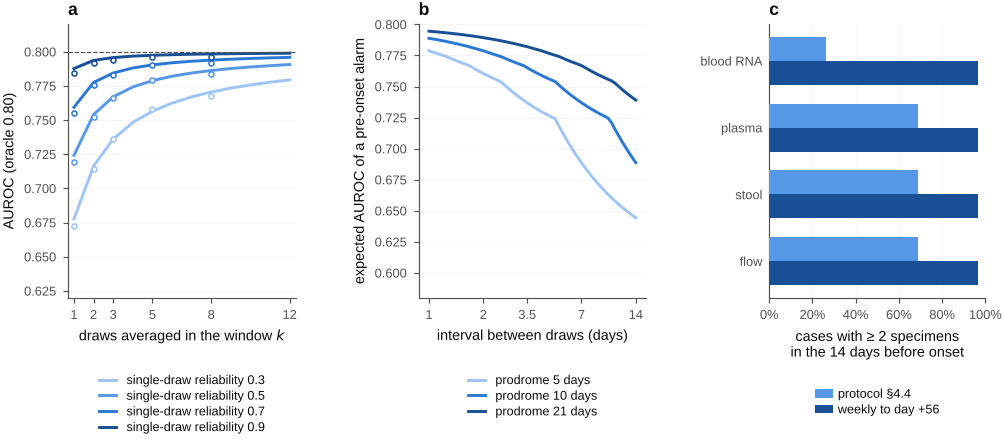

[saved] figures/Fig14_longitudinal_design.pdf  +  figures/Fig14_longitudinal_design.png


In [55]:
# ----------------------------------------------------------------------------- Figure 14: longitudinal design
fig = plt.figure(figsize=(FULL, 3.2))
gs = fig.add_gridspec(1, 3, width_ratios=[1.0, 1.0, .95], left=.075, right=.985, bottom=.265, top=.875, wspace=.55)
ax = fig.add_subplot(gs[0, 0]); ygrid(ax)                                       # (a) draws per window
kk = np.arange(1, 13)
for lam, c in zip((.3, .5, .7, .9), (PAL['seq'][0], PAL['seq'][1], PAL['seq'][2], PAL['seq'][3])):
    ax.plot(kk, [auc_k(.80, lam, k) for k in kk], color=c, lw=1.5, label=f'single-draw reliability {lam:g}')
    ax.plot(KDR, [sim_auc_k(.80, lam, k, n=60000) for k in KDR], 'o', ms=2.6, mfc='white', mec=c, mew=.8, ls='None')
ax.axhline(.80, color=PAL['ink2'], ls='--', lw=.6); ax.set_xlabel('draws averaged in the window $k$'); ax.set_ylabel('AUROC (oracle 0.80)'); ax.set_ylim(.62, .82); ax.set_xlim(.7, 12.3); ax.set_xticks([1, 2, 3, 5, 8, 12])
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.25), ncol=1, handlelength=1.4, labelspacing=.3); panel(ax, 'a')
ax = fig.add_subplot(gs[0, 1]); ygrid(ax)                                       # (b) how often
dts = np.geomspace(1, 14, 60)
for tau, c in zip(TAUS, (PAL['seq'][0], PAL['seq'][2], PAL['seq'][3])):
    ax.plot(dts, [expected_prodrome_auc(tau, d) for d in dts], color=c, lw=1.5, label=f'prodrome {tau} days')
ax.set_xscale('log'); ax.set_xticks([1, 2, 3.5, 7, 14]); ax.set_xticklabels(['1', '2', '3.5', '7', '14']); ax.minorticks_off()
ax.set_xlabel('interval between draws (days)'); ax.set_ylabel('expected AUROC of a pre-onset alarm'); ax.set_ylim(.58, .80)
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.25), ncol=1, handlelength=1.4, labelspacing=.3); panel(ax, 'b')
ax = fig.add_subplot(gs[0, 2]); ygrid(ax, 'x')                                  # (c) specimens: cases with >= 2 pre-onset draws under two schedules
types = ['Whole blood PAXgene RNA', 'Plasma / serum', 'Stool', 'Flow phenotyping']; short_lab = ['blood RNA', 'plasma', 'stool', 'flow']; yy = np.arange(len(types)); hh = .36
for j, (sch, c) in enumerate((('protocol §4.4', PAL['seq'][1]), ('weekly to day +56', PAL['seq'][3]))):
    v = [float(sdf[(sdf.specimen == t) & (sdf.schedule == sch)].P_at_least_2.iloc[0]) for t in types]
    ax.barh(yy + (j - .5) * hh, v, height=hh, color=c, zorder=3, label=sch)
ax.set_yticks(yy); ax.set_yticklabels(short_lab); ax.invert_yaxis(); ax.tick_params(axis='y', length=0); ax.set_xlim(0, 1); ax.set_xlabel('cases with ≥ 2 specimens\nin the 14 days before onset')
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.30), ncol=1, handlelength=1.4, handletextpad=.4, labelspacing=.3); panel(ax, 'c')
finish(fig, 14, 'longitudinal_design',
       "Longitudinal sampling design. (a) AUROC against the number of draws averaged in a window, for four single-draw reliabilities (oracle AUROC 0.80); lines are "
       "the Spearman-Brown closed form, circles are simulation. (b) Expected AUROC of a pre-onset alarm against the interval between draws, for prodromes of 5, 10 "
       "and 21 days: sampling less often than the prodrome is long loses the trajectory. (c) The fraction of cases that have at least two specimens in the 14 days "
       "before onset under the minimum protocol of section 4.4 and under a weekly schedule to day +56, for each specimen type, against a realistic onset distribution.")

**Reading §9.5.** (1) **Draws:** when a single draw is a noisy measurement (λ ≈ 0.3–0.5, typical of a dynamic blood signature), three to five draws in the window recover most of the oracle AUROC, and eight recover essentially all of it; when a draw is already reliable (λ ≥ 0.9), one suffices. Replicate draws are therefore worth buying exactly where the single-draw reliability is low — which is a *measurable* property of each assay (bridging and replicate samples, §4.4), not a guess. (2) **Interval:** the alarm degrades as the draw interval approaches the prodrome length; for a 10-day prodrome, draws every 7 or 14 days miss it in a large share of cases, while every 2–3.5 days keeps at least two draws inside it. (3) **Specimens:** the minimum protocol of §4.4 is designed for diagnosis and prognosis at fixed landmarks; it yields **few cases with two or more pre-onset specimens**, so it cannot by itself support trajectory tasks. A **nested trajectory cohort** (weekly to day +56 for blood RNA, plasma, stool and flow) is what makes B3 and the longitudinal objectives testable, and the table above gives the enrolment it needs for 300 evaluable cases. Its cost is in §9.8.

## 9.6 How many centres?

Patients are not the only unit. A benchmark that claims *out-of-centre* generalisation has an effective sample size that is partly a **number of centres**, because centres differ in case mix, prophylaxis practice, grading habits and assay handling in ways a model cannot see. The paired gain of a candidate over a baseline therefore varies from centre to centre with some **between-centre standard deviation τ**, on top of the sampling noise within each centre. The gate of §8.12 averages over *K* held-out centres with a *t*-interval, so its power is

$$\Pr\big[\text{pass}\big]=\Pr\!\Big[t_{K-1}\!\big(\text{ncp}=\tfrac{\Delta-m}{\sqrt{(\tau^2+\mathrm{se}_c^2)/K}}\big)\ge t_{0.975,K-1}\Big],$$

with $m=+0.01$ the margin and $\mathrm{se}_c$ the standard error of a paired AUROC difference at the centre's sample size. This is closed-form; we check it against the §8.12 simulation, then solve for the number of centres.

In [56]:
# ----------------------------------------------------------------------------- 9.6: centres needed for the gate (closed form, validated against the 8.12 simulation)
from scipy.stats import nct
def gate_power(K, n_c, d_true, tau, prev=.35, A1=.70, rho=.85):
    """Power of the adopted gate (t-interval lower bound >= margin) with K centres of n_c patients each."""
    m = GATE['level2_gate']['ci_lower_bound_min']; se_c = se_delta(n_c, prev, A1, A1 + d_true, rho); se = math.sqrt((tau ** 2 + se_c ** 2) / K)
    return float(nct.sf(student_t.ppf(.975, K - 1), K - 1, (d_true - m) / se))
def K_required(d_true, tau, n_c, power=.8, prev=.35, A1=.70, rho=.85, Kmax=400):
    for K in range(3, Kmax):
        if gate_power(K, n_c, d_true, tau, prev, A1, rho) >= power: return K
    return None
chk = pd.DataFrame([dict(K=K, closed_form=gate_power(K, 300, .03, .02), simulated=float(oc[(oc.K == K) & (oc.d_true == .03)].pass_adopted.iloc[0])) for K in (12, 20, 30, 50)])
chk['diff'] = chk.simulated - chk.closed_form
print('closed-form power of the adopted gate vs the §8.12 simulation (Δ = 0.03, τ = 0.02, 300 patients per centre; the simulation also requires 70 % of centres improved):'); display(md_table(chk.round(3)))
assert chk['diff'].abs().max() < .09, 'closed-form gate power disagrees with the simulation'
krow = []
for d in (.03, .04, .05):
    for nc in (150, 300, 600):
        krow.append({'true gain': d, 'patients per centre': nc, **{f'τ = {tau}': K_required(d, tau, nc) for tau in (.01, .02, .03, .04)}})
ktab = pd.DataFrame(krow)
print('CENTRES REQUIRED for 80 % power of the adopted gate:'); display(md_table(ktab))
# what the simulated harness cohort of 8.11 implies for tau (it is a planted property of the simulation, not a measurement of the real world)
dvec = (piv['full (clinical + day-7 + biomarkers)'] - piv['clinical baseline (registry covariates)']).dropna().values
se_c_sim = float(np.mean([se_delta(int(n_), .35, .70, .75, .85) for n_ in COH.groupby('centre').size().values]))
tau_sim = math.sqrt(max(dvec.var(ddof=1) - se_c_sim ** 2, 0.0))
print(f'[SIM] the 8.11 cohort: SD of the per-centre gain {dvec.std(ddof=1):.3f}, expected sampling SD {se_c_sim:.3f} -> implied between-centre tau ≈ {tau_sim:.3f}')
# design effect for centre-level exposures (practice, policy): patients are clustered in centres
dex = pd.DataFrame([{'intra-centre correlation': icc, **{f'{m} patients per centre': f'{1 + (m - 1) * icc:.1f}' for m in (100, 300, 1000)}} for icc in (.01, .03, .05)])
print('DESIGN EFFECT 1 + (m - 1) × ICC for any effect that varies BETWEEN centres (prophylaxis policy, biopsy habit); effective n = n / DE:'); display(md_table(dex))
print(f'with 6,000 patients in 20 centres of 300 and an ICC of 0.03 the effective sample for a centre-level effect is {6000 / (1 + 299 * .03):.0f} patients.')

closed-form power of the adopted gate vs the §8.12 simulation (Δ = 0.03, τ = 0.02, 300 patients per centre; the simulation also requires 70 % of centres improved):


| K | closed_form | simulated | diff |
|---|---|---|---|
| 12 | 0.653 | 0.598 | -0.055 |
| 20 | 0.885 | 0.85 | -0.036 |
| 30 | 0.976 | 0.957 | -0.019 |
| 50 | 0.999 | 0.999 | -0.0 |

CENTRES REQUIRED for 80 % power of the adopted gate:


| true gain | patients per centre | τ = 0.01 | τ = 0.02 | τ = 0.03 | τ = 0.04 |
|---|---|---|---|---|---|
| 0.03 | 150 | 17 | 23 | 33 | 46 |
| 0.03 | 300 | 11 | 17 | 26 | 40 |
| 0.03 | 600 | 8 | 14 | 23 | 37 |
| 0.04 | 150 | 9 | 12 | 16 | 22 |
| 0.04 | 300 | 6 | 9 | 13 | 19 |
| 0.04 | 600 | 5 | 8 | 12 | 18 |
| 0.05 | 150 | 6 | 8 | 10 | 14 |
| 0.05 | 300 | 5 | 6 | 9 | 12 |
| 0.05 | 600 | 4 | 5 | 8 | 11 |

[SIM] the 8.11 cohort: SD of the per-centre gain 0.040, expected sampling SD 0.020 -> implied between-centre tau ≈ 0.035
DESIGN EFFECT 1 + (m - 1) × ICC for any effect that varies BETWEEN centres (prophylaxis policy, biopsy habit); effective n = n / DE:


| intra-centre correlation | 100 patients per centre | 300 patients per centre | 1000 patients per centre |
|---|---|---|---|
| 0.01 | 2.0 | 4.0 | 11.0 |
| 0.03 | 4.0 | 10.0 | 31.0 |
| 0.05 | 6.0 | 16.0 | 51.0 |

with 6,000 patients in 20 centres of 300 and an ICC of 0.03 the effective sample for a centre-level effect is 602 patients.


In [57]:
k_tab = lambda d, nc, tau: int(ktab[(ktab['true gain'] == d) & (ktab['patients per centre'] == nc)][f'τ = {tau}'].iloc[0])
display(Markdown(f"""**Reading §9.6.** With the planning value τ = 0.02 and centres of ~300 patients, the closed form says **{k_tab(.03, 300, .02)} centres** give the adopted gate 80 % power for a +0.03 gain, and the full simulation of §8.12 — which also requires 70 % of centres to improve and lets centre sizes vary — says **20** (power {g20(.03, 'pass_adopted'):.2f}); the gate's minimum is set to the more conservative 20. The table shows how fast the requirement moves: at τ = 0.04 the same gain needs **{k_tab(.03, 300, .04)}** centres, and **adding patients within existing centres barely helps** once the between-centre term dominates (at τ = 0.04, going from 150 to 600 patients per centre lowers the requirement only from {k_tab(.03, 150, .04)} to {k_tab(.03, 600, .04)} centres). τ is a property of the real world that no simulation can supply (the simulated cohort of §8.11 happens to imply about {tau_sim:.2f}); **stage 1 of the roadmap measures it**, and the required number of centres is then read from this table. The design effect makes the same point for any *centre-level* explanatory variable — prophylaxis platform, biopsy policy, grading habit: their effective sample size is closer to the number of centres than to the number of patients."""))

**Reading §9.6.** With the planning value τ = 0.02 and centres of ~300 patients, the closed form says **17 centres** give the adopted gate 80 % power for a +0.03 gain, and the full simulation of §8.12 — which also requires 70 % of centres to improve and lets centre sizes vary — says **20** (power 0.85); the gate's minimum is set to the more conservative 20. The table shows how fast the requirement moves: at τ = 0.04 the same gain needs **40** centres, and **adding patients within existing centres barely helps** once the between-centre term dominates (at τ = 0.04, going from 150 to 600 patients per centre lowers the requirement only from 46 to 37 centres). τ is a property of the real world that no simulation can supply (the simulated cohort of §8.11 happens to imply about 0.03); **stage 1 of the roadmap measures it**, and the required number of centres is then read from this table. The design effect makes the same point for any *centre-level* explanatory variable — prophylaxis platform, biopsy policy, grading habit: their effective sample size is closer to the number of centres than to the number of patients.

## 9.7 How many patients to validate a claim, to audit a subgroup, and when the labels are imperfect

Three further requirements that decide whether a "Level 3" claim is believable.

**Validation sample size (Level 3).** Discrimination is the easy part. For a calibrated model the *calibration slope* is the quantity that needs the most patients, because its information comes from the spread of predicted risks. For a logistic recalibration $y\sim a+b\,\mathrm{lp}$ at $(a,b)=(0,1)$, the large-sample variance of $\hat b$ is the corresponding element of the inverse Fisher information, which we integrate over the distribution of predicted risks implied by a binormal score. We ask for SE(slope) ≤ 0.10 (so the 95 % interval is ±0.2), SE(ln O/E) ≤ 0.10, and an AUROC half-width ≤ 0.05.

**Subgroups (task G3).** A subgroup of share *s* of the cohort has *s·N* patients. We ask how large *N* must be for the subgroup to support (i) an AUROC half-width ≤ 0.07, (ii) SE(calibration slope) ≤ 0.15, and (iii) detection of an equal-opportunity gap of 0.10 (or 0.05) in sensitivity at fixed specificity (80 % power, sensitivities around 0.7).

**Label noise.** If the recorded label has sensitivity *se* and specificity *sp* against the truth (inter-centre grading differences, missed biopsies), a score with true AUROC *A* has observed AUROC
$$A_{\rm obs}=\frac{w_{p1}w_{n0}\,A+w_{p0}w_{n1}\,(1-A)+\tfrac12\,(w_{p1}w_{n1}+w_{p0}w_{n0})}{W_pW_n},$$
with $w_{p1}=\pi\,se,\;w_{p0}=(1-\pi)(1-sp),\;w_{n1}=\pi(1-se),\;w_{n0}=(1-\pi)\,sp$. Both models in a comparison are attenuated, so the observable gain shrinks and the required *n* grows.

In [58]:
# ----------------------------------------------------------------------------- 9.7: validation n, subgroup precision, label-noise attenuation
@functools.lru_cache(maxsize=None)
def _val_parts(A, prev, N=800_000, seed=1):
    r = np.random.default_rng(seed); D = math.sqrt(2) * norm.ppf(A); y = r.random(N) < prev
    x = np.where(y, r.normal(D, 1, N), r.normal(0, 1, N)); lp = math.log(prev / (1 - prev)) + D * x - D * D / 2
    p = 1 / (1 + np.exp(-lp)); w = p * (1 - p)
    I = np.array([[w.mean(), (w * lp).mean()], [(w * lp).mean(), (w * lp * lp).mean()]]); return float(np.linalg.inv(I)[1, 1]), float(w.mean())
def validation_n(A, prev, se_slope=.10, se_oe=.10, hw_auc=.05):
    """Patients so that SE(calibration slope) <= se_slope, SE(ln O/E) <= se_oe and the AUROC half-width <= hw_auc (large-sample)."""
    ib, ew = _val_parts(round(A, 3), round(prev, 3))
    n_slope, n_citl, n_oe, n_auc = ib / se_slope ** 2, 1 / (ew * se_oe ** 2), (1 - prev) / (prev * se_oe ** 2), n_for_ci(A, prev, hw_auc)
    comp = dict(slope=n_slope, intercept=n_citl, oe=n_oe, auroc=n_auc); k = max(comp, key=comp.get)
    return dict(n=int(math.ceil(comp[k])), events=int(math.ceil(comp[k] * prev)), binding=k)
# check the Fisher computation against a direct simulation of the calibration-slope SE
def sim_slope_se(A, prev, n, reps=300, seed=2):
    r = np.random.default_rng(seed); D = math.sqrt(2) * norm.ppf(A); out = []
    for _ in range(reps):
        y = (r.random(n) < prev).astype(int); x = np.where(y == 1, r.normal(D, 1, n), r.normal(0, 1, n)); lp = math.log(prev / (1 - prev)) + D * x - D * D / 2
        m = LogisticRegression(C=1e6, max_iter=500).fit(lp[:, None], y); out.append(m.coef_[0, 0])
    return float(np.std(out))
fi_se = math.sqrt(_val_parts(.75, .15)[0] / 1500); sm_se = sim_slope_se(.75, .15, 1500, reps=150 if QUICK else 300)
print(f'calibration-slope SE at n = 1500 (AUROC 0.75, prevalence 0.15): Fisher {fi_se:.3f} vs simulated {sm_se:.3f}')
assert abs(fi_se - sm_se) / fi_se < (.25 if QUICK else .15)
vtab = pd.DataFrame([dict(AUROC=A, prevalence=pv, **validation_n(A, pv)) for A in (.70, .75, .80) for pv in (.05, .15, .35)])
vtab = vtab.rename(columns={'n': 'patients', 'binding': 'binding criterion'})
print('PATIENTS (AND EVENTS) FOR A LEVEL-3 VALIDATION:'); display(md_table(vtab))
rate1, rateC = 200 * USABLE, 3000 * USABLE
vtab['months at one centre'] = (vtab.patients / rate1 * 12).round(0).astype(int); vtab['months, 20-centre consortium'] = (vtab.patients / rateC * 12).round(0).astype(int)
print('TIME TO COLLECT A PROSPECTIVE VALIDATION COHORT (70 % usable; one centre 200 transplants a year, a 20-centre consortium 3,000):')
display(md_table(vtab[['AUROC', 'prevalence', 'patients', 'months at one centre', 'months, 20-centre consortium']]))

# ---------- subgroups (shares are planning assumptions †)
SUBGROUPS = [('cord-blood graft', .05), ('Black / African ancestry (US registry)', .06), ('Asian / Pacific Islander (US registry)', .07), ('lowest-volume centre tertile', .08),
             ('Hispanic / Latino (US registry)', .10), ('paediatric (< 18 y)', .15), ('haploidentical donor', .20)]
A_sg, pv_sg = .72, .35
n_gap_events = {g: int(np.ceil((norm.ppf(.975) + norm.ppf(.8)) ** 2 * (.70 * .30 + (.70 - g) * (.30 + g)) / g ** 2)) for g in (.10, .05)}
n_gap_pat = {g: int(np.ceil(e / pv_sg)) for g, e in n_gap_events.items()}
sgrow = []
for name, s in SUBGROUPS:
    n_auc_ = n_for_ci(A_sg, pv_sg, .07); n_slope_ = int(np.ceil(_val_parts(A_sg, pv_sg)[0] / .15 ** 2)); base_need = max(n_auc_, n_slope_)
    row_ = {'subgroup': name, 'share †': f'{s:.0%}'}
    for g in (.10, .05):
        need_sub = max(base_need, n_gap_pat[g]); row_[f'patients in subgroup for a {g:.2f} gap'] = f'{need_sub:,}'; row_[f'total cohort for a {g:.2f} gap'] = int(np.ceil(need_sub / s))
    row_['assessable at 25,000 (gap 0.10 / 0.05)'] = ' / '.join('yes' if 25000 * s >= max(base_need, n_gap_pat[g]) else 'NO' for g in (.10, .05))
    row_['assessable at 100,000 (gap 0.10 / 0.05)'] = ' / '.join('yes' if 100000 * s >= max(base_need, n_gap_pat[g]) else 'NO' for g in (.10, .05))
    sgrow.append(row_)
sg = pd.DataFrame(sgrow); sg_disp = sg.copy()
for c in ('total cohort for a 0.10 gap', 'total cohort for a 0.05 gap'): sg_disp[c] = sg_disp[c].map(lambda v: f'{v:,}')
print(f'SUBGROUP AUDIT (AUROC {A_sg}, prevalence {pv_sg}; an equal-opportunity gap of 0.10 in sensitivity needs {n_gap_events[.10]} events per group = {n_gap_pat[.10]:,} patients, a gap of 0.05 needs {n_gap_events[.05]:,} = {n_gap_pat[.05]:,}):'); display(md_table(sg_disp))

# ---------- label noise
def auc_obs(A, prev, se, sp):
    wp1, wp0, wn1, wn0 = prev * se, (1 - prev) * (1 - sp), prev * (1 - se), (1 - prev) * sp
    return (wp1 * wn0 * A + wp0 * wn1 * (1 - A) + .5 * (wp1 * wn1 + wp0 * wn0)) / ((wp1 + wp0) * (wn1 + wn0))
def sim_auc_obs(A, prev, se, sp, n=400000, seed=4):
    r = np.random.default_rng(seed); D = math.sqrt(2) * norm.ppf(A); y = (r.random(n) < prev).astype(int); s_ = np.where(y == 1, r.normal(D, 1, n), r.normal(0, 1, n))
    yo = np.where(y == 1, r.random(n) < se, r.random(n) < 1 - sp).astype(int); return float(roc_auc_score(yo, s_))
assert abs(auc_obs(.75, .35, .9, .9) - sim_auc_obs(.75, .35, .9, .9)) < .004, 'label-noise attenuation formula disagrees with simulation'
lrow = []
for se_, sp_ in ((1.0, 1.0), (.95, .95), (.90, .90), (.85, .85), (.80, .95)):
    po = .35 * se_ + .65 * sp_; pexp = (.35 * se_ + .65 * (1 - sp_)) * .35 + (.35 * (1 - se_) + .65 * sp_) * .65; kappa = (po - pexp) / (1 - pexp)
    a0, a1 = auc_obs(.72, .35, se_, sp_), auc_obs(.75, .35, se_, sp_)
    lrow.append({'label sensitivity': se_, 'label specificity': sp_, 'kappa vs truth': round(kappa, 2), 'observed AUROC of a true 0.72': round(a0, 3), 'observed AUROC of a true 0.75': round(a1, 3),
                 'observed gain of a true +0.03': round(a1 - a0, 3), 'n to show it vs noise-free n': round(n_for_delta(a0, a1 - a0, .35) / n_for_delta(.72, .03, .35), 2)})
ltab = pd.DataFrame(lrow); print('LABEL NOISE (prevalence 0.35):'); display(md_table(ltab))

calibration-slope SE at n = 1500 (AUROC 0.75, prevalence 0.15): Fisher 0.086 vs simulated 0.093


PATIENTS (AND EVENTS) FOR A LEVEL-3 VALIDATION:


| AUROC | prevalence | patients | events | binding criterion |
|---|---|---|---|---|
| 0.7 | 0.05 | 4102 | 206 | slope |
| 0.7 | 0.15 | 1664 | 250 | slope |
| 0.7 | 0.35 | 1009 | 354 | slope |
| 0.75 | 0.05 | 2630 | 132 | slope |
| 0.75 | 0.15 | 1117 | 168 | slope |
| 0.75 | 0.35 | 699 | 245 | slope |
| 0.8 | 0.05 | 2328 | 117 | intercept |
| 0.8 | 0.15 | 964 | 145 | intercept |
| 0.8 | 0.35 | 592 | 208 | intercept |

TIME TO COLLECT A PROSPECTIVE VALIDATION COHORT (70 % usable; one centre 200 transplants a year, a 20-centre consortium 3,000):


| AUROC | prevalence | patients | months at one centre | months, 20-centre consortium |
|---|---|---|---|---|
| 0.7 | 0.05 | 4102 | 352 | 23 |
| 0.7 | 0.15 | 1664 | 143 | 10 |
| 0.7 | 0.35 | 1009 | 86 | 6 |
| 0.75 | 0.05 | 2630 | 225 | 15 |
| 0.75 | 0.15 | 1117 | 96 | 6 |
| 0.75 | 0.35 | 699 | 60 | 4 |
| 0.8 | 0.05 | 2328 | 200 | 13 |
| 0.8 | 0.15 | 964 | 83 | 6 |
| 0.8 | 0.35 | 592 | 51 | 3 |

SUBGROUP AUDIT (AUROC 0.72, prevalence 0.35; an equal-opportunity gap of 0.10 in sensitivity needs 354 events per group = 1,012 patients, a gap of 0.05 needs 1,374 = 3,926):


| subgroup | share † | patients in subgroup for a 0.10 gap | total cohort for a 0.10 gap | patients in subgroup for a 0.05 gap | total cohort for a 0.05 gap | assessable at 25,000 (gap 0.10 / 0.05) | assessable at 100,000 (gap 0.10 / 0.05) |
|---|---|---|---|---|---|---|---|
| cord-blood graft | 5% | 1,012 | 20,240 | 3,926 | 78,520 | yes / NO | yes / yes |
| Black / African ancestry (US registry) | 6% | 1,012 | 16,867 | 3,926 | 65,434 | yes / NO | yes / yes |
| Asian / Pacific Islander (US registry) | 7% | 1,012 | 14,458 | 3,926 | 56,086 | yes / NO | yes / yes |
| lowest-volume centre tertile | 8% | 1,012 | 12,650 | 3,926 | 49,075 | yes / NO | yes / yes |
| Hispanic / Latino (US registry) | 10% | 1,012 | 10,120 | 3,926 | 39,260 | yes / NO | yes / yes |
| paediatric (< 18 y) | 15% | 1,012 | 6,747 | 3,926 | 26,174 | yes / NO | yes / yes |
| haploidentical donor | 20% | 1,012 | 5,060 | 3,926 | 19,630 | yes / yes | yes / yes |

LABEL NOISE (prevalence 0.35):


| label sensitivity | label specificity | kappa vs truth | observed AUROC of a true 0.72 | observed AUROC of a true 0.75 | observed gain of a true +0.03 | n to show it vs noise-free n |
|---|---|---|---|---|---|---|
| 1.0 | 1.0 | 1.0 | 0.72 | 0.75 | 0.03 | 1.0 |
| 0.95 | 0.95 | 0.89 | 0.694 | 0.721 | 0.027 | 1.36 |
| 0.9 | 0.9 | 0.78 | 0.67 | 0.693 | 0.023 | 1.87 |
| 0.85 | 0.85 | 0.68 | 0.647 | 0.667 | 0.02 | 2.62 |
| 0.8 | 0.95 | 0.77 | 0.675 | 0.699 | 0.024 | 1.76 |

[layout PASS] Fig 15: 49 text items, 0 collisions, 0 below 6 pt (smallest 6.5 pt)


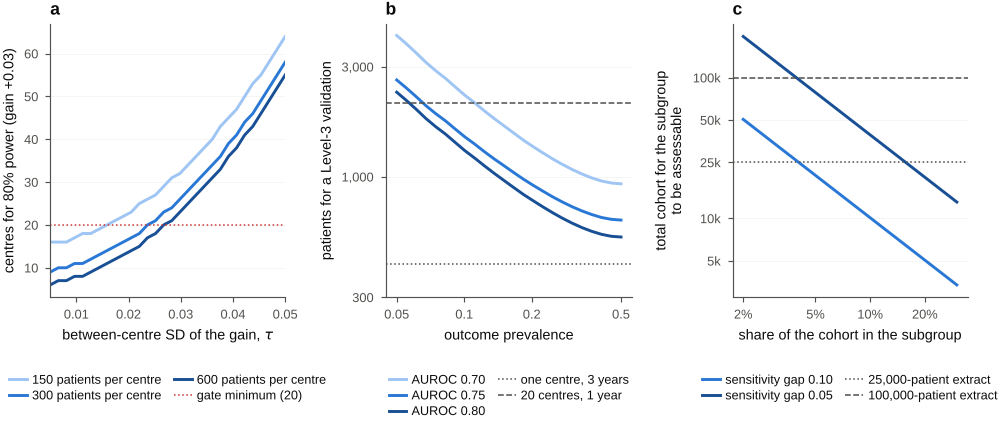

[saved] figures/Fig15_centres_validation_subgroups.pdf  +  figures/Fig15_centres_validation_subgroups.png


In [59]:
# ----------------------------------------------------------------------------- Figure 15: centres, validation size and subgroup precision
fig = plt.figure(figsize=(FULL, 3.2))
gs = fig.add_gridspec(1, 3, width_ratios=[1.0, 1.05, 1.0], left=.075, right=.985, bottom=.265, top=.875, wspace=.42)
ax = fig.add_subplot(gs[0, 0]); ygrid(ax)                                       # (a) centres needed for the gate
taus = np.linspace(.005, .05, 30)
for nc, c in zip((150, 300, 600), (PAL['seq'][0], PAL['seq'][2], PAL['seq'][3])):
    ax.plot(taus, [K_required(.03, t, nc) for t in taus], color=c, lw=1.5, label=f'{nc} patients per centre')
ax.axhline(GATE['level2_gate']['min_centres'], color=PAL['bad'], lw=.8, ls=':', label='gate minimum (20)')
ax.set_xlabel('between-centre SD of the gain, $\\tau$'); ax.set_ylabel('centres for 80% power (gain +0.03)'); ax.set_xlim(.005, .05)
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.25), ncol=2, columnspacing=1.0, handlelength=1.4, handletextpad=.4, labelspacing=.3); panel(ax, 'a')
ax = fig.add_subplot(gs[0, 1]); ygrid(ax)                                       # (b) Level-3 validation size
prevs = np.geomspace(.05, .5, 24)
for A, c in zip((.70, .75, .80), (PAL['seq'][0], PAL['seq'][2], PAL['seq'][3])):
    ax.plot(prevs, [validation_n(A, pv)['n'] for pv in prevs], color=c, lw=1.5, label=f'AUROC {A:.2f}')
ax.axhline(200 * USABLE * 3, color=PAL['ink2'], lw=.8, ls=':', label='one centre, 3 years'); ax.axhline(3000 * USABLE, color=PAL['ink2'], lw=.8, ls='--', label='20 centres, 1 year')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xticks([.05, .1, .2, .5]); ax.set_xticklabels(['0.05', '0.1', '0.2', '0.5']); ax.minorticks_off()
ax.set_yticks([300, 1000, 3000]); ax.set_yticklabels(['300', '1,000', '3,000'])
ax.set_xlabel('outcome prevalence'); ax.set_ylabel('patients for a Level-3 validation')
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.25), ncol=2, columnspacing=1.0, handlelength=1.4, handletextpad=.4, labelspacing=.3); panel(ax, 'b')
ax = fig.add_subplot(gs[0, 2]); ygrid(ax)                                       # (c) subgroup assessability
shares = np.geomspace(.02, .30, 30)
for g, c in ((.10, PAL['seq'][2]), (.05, PAL['seq'][3])):
    need_g = max(n_for_ci(A_sg, pv_sg, .07), int(np.ceil(_val_parts(A_sg, pv_sg)[0] / .15 ** 2)), n_gap_pat[g])
    ax.plot(shares, need_g / shares, color=c, lw=1.5, label=f'sensitivity gap {g:.2f}')
ax.axhline(25000, color=PAL['ink2'], lw=.8, ls=':', label='25,000-patient extract'); ax.axhline(100000, color=PAL['ink2'], lw=.8, ls='--', label='100,000-patient extract')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xticks([.02, .05, .1, .2]); ax.set_xticklabels(['2%', '5%', '10%', '20%']); ax.minorticks_off()
ax.set_yticks([5000, 10000, 25000, 50000, 100000]); ax.set_yticklabels(['5k', '10k', '25k', '50k', '100k']); ax.set_xlabel('share of the cohort in the subgroup'); ax.set_ylabel('total cohort for the subgroup\nto be assessable')
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.25), ncol=2, columnspacing=1.0, handlelength=1.4, handletextpad=.4, labelspacing=.3); panel(ax, 'c')
finish(fig, 15, 'centres_validation_subgroups',
       "How many centres, how many validation patients, how large a subgroup. (a) Centres needed for the adopted gate to have 80% power for a true gain of +0.03, against the "
       "between-centre SD of the gain, for three centre sizes: once heterogeneity dominates, more centres help and more patients per centre do not. The dotted line is the gate's minimum. "
       "(b) Patients for a Level-3 validation (calibration slope SE 0.10, O/E SE 0.10, AUROC half-width 0.05) against prevalence, set against what one centre collects in three years "
       "and what a 20-centre consortium collects in one. (c) Total cohort at which a subgroup of a given share has enough patients to detect an equal-opportunity gap in sensitivity of "
       "0.10 or 0.05, against two registry-extract sizes.")

## 9.8 The data bill of materials: minimum viable, credible, definitive

Everything above is a requirement on one quantity. This subsection puts them together into **what to collect**, in three packages, with the constraint that binds each number stated. The packages are cumulative in what they must demonstrate:

* **Minimum viable (MVD)** — enough to *test the primary claim* once, honestly: for each data layer, the largest of the registry's per-task requirement (Riley development size for a 50-parameter head, and the paired-power size to show +0.03; §8.4) and the transcriptome learning-curve size of §9.4, spread over the number of centres at which the gate of §8.12 has 80 % power for a +0.03 gain with between-centre SD **τ = 0.02**.
* **Credible** — enough to support *several claims and an equity audit*: MVD plus the total cohort at which the smallest subgroup with a 10 % share becomes assessable (§9.7), plus, for the registry layers, the Riley size for a 768-parameter embedding head; centres planned at **τ = 0.03**.
* **Definitive** — enough for a *Level-3* claim: credible plus a prospective validation cohort sized by §9.7, planned at **τ = 0.04**.

For each layer the table reports patients, centres, specimens and what it costs. **Unit costs are planning figures †, not quotes**; they are in one dictionary in the cell below so a reader can change them, and the totals are shown with a ×0.5 / ×2 range.

In [60]:
# ----------------------------------------------------------------------------- 9.8: the data bill of materials
UNIT = dict(collect_per_specimen=60, plasma_panel=100, bulk_rnaseq=250, tissue_rna_wsi=450, flow_panel=200, stool_16s=120, scrna_vdj=3000,
            coordination_per_patient=1500, centre_setup=50_000, registry_access=150_000, ehr_etl_per_centre=25_000, harmonisation_central=200_000)   # USD †
nreq = need_tbl.set_index('id')['n required']                                  # per-task requirement of §8.4 / §9.1 (max of Riley-50 and paired power for +0.03)
MIN_NC, K_MIN = 60, GATE['level2_gate']['min_centres']
def N_for_gate(N_task, tau, d=.03):
    """Smallest total N >= N_task, and the fewest centres K (>= the gate's minimum), at which the adopted gate has 80 % power with n_c = N/K per centre."""
    N = max(N_task, K_MIN * MIN_NC)
    for _ in range(200):
        for K in range(K_MIN, 250):
            if N / K < MIN_NC: break
            if gate_power(K, N / K, d, tau) >= .8: return int(math.ceil(N)), K
        N *= 1.08
    return None, None
sub_need = lambda gap=.10: max(n_for_ci(A_sg, pv_sg, .07), int(np.ceil(_val_parts(A_sg, pv_sg)[0] / .15 ** 2)), n_gap_pat[gap])
DENSE_N = int(sdf[(sdf.specimen == 'Whole blood PAXgene RNA') & (sdf.schedule == 'weekly to day +56')]['patients to enrol for 300 cases with >= 2 pre-onset draws'].iloc[0])
c4 = txt_tab.set_index('task')
def _tx(prefix, col):
    return [v for k, v in c4[col].items() if k.startswith(prefix)][0]
LAYERS = [  # key, name, n_task (MVD), primary task for FM-head and validation, smallest subgroup that must be assessable (share), draws per patient (landmark-only for the MVD, the §4.4 protocol, the weekly trajectory schedule), nested trajectory sub-cohort?, assay USD, GB per specimen
 dict(key='A',  name='registry core + outcomes (Tier A)',  n_task=max(nreq[t] for t in ('A1', 'A2', 'A3', 'A4', 'A5')), prim=(.68, .38), fm_head=True, share=.05, draws=(0, 0, 0), dense=False, assay=0, gb=0),
 dict(key='B',  name='EHR timeline (Tier B)',               n_task=max(nreq[t] for t in ('B3', 'B6', 'C3', 'D3', 'D4', 'E1', 'E2', 'E4')), prim=(.68, .30), fm_head=True, share=.05, draws=(0, 0, 0), dense=False, assay=0, gb=0),
 dict(key='C1', name='plasma biomarkers, scheduled draws (Tier C)', n_task=max(nreq[t] for t in ('B1', 'B2', 'B4', 'B5', 'C4', 'C5', 'C6', 'E3')), prim=(.74, .35), fm_head=False, share=.10, draws=(3, 8, 11), dense=True, assay=UNIT['plasma_panel'], gb=.001),
 dict(key='C2', name='blood transcriptome at diagnosis and prodrome (Tier C)', n_task=None, tx=('C4', .72, .30), prim=(.72, .30), fm_head=False, share=.20, draws=(3, 6, 11), dense=True, assay=UNIT['bulk_rnaseq'], gb=6),
 dict(key='C3', name='tissue transcriptome + whole-slide image at diagnosis (Tier C/D)', n_task=None, tx=('C1/C2', .86, .45), prim=(.86, .45), fm_head=False, share=.20, draws=(1.3, 1.3, 1.3), dense=False, assay=UNIT['tissue_rna_wsi'], gb=8),
 dict(key='D',  name='TCR repertoire / single-cell / spatial (Tier D)', n_task=None, prim=None, fm_head=False, share=None, draws=(6, 6, 6), dense=False, assay=UNIT['scrna_vdj'], gb=120),
]
TIER_D = {'minimum viable': 80, 'credible': 300, 'definitive': 1000}               # F1 / F2 accessible-n scale of §8.4: nested research cohort
PKG = (('minimum viable', .02), ('credible', .03), ('definitive', .04))
TXCOL = {'minimum viable': 'n for +0.02', 'credible': 'n for 80% of it', 'definitive': 'n for 95% of it'}
bom = []
for L in LAYERS:
    for pkg, tau in PKG:
        if L['key'] == 'D':
            N, K = TIER_D[pkg], max(1, int(round(TIER_D[pkg] / 100))); binding = 'research cohort size (F1/F2)'; spec_n = N * L['draws'][1]
        else:
            if L['n_task']: N_task, binding = L['n_task'], 'per-task n (Riley-50 / paired power)'
            else:
                N_task = _tx(L['tx'][0], f"{TXCOL[pkg]} (ρ = 0.8, K = 8)"); binding = {'minimum viable': 'transcriptome learning curve: +0.02 (§9.4)', 'credible': 'transcriptome learning curve: 80% of realisable gain (§9.4)',
                                                                                        'definitive': 'transcriptome learning curve: 95% of realisable gain (§9.4)'}[pkg]
            if not np.isfinite(N_task): N_task = _tx(L['tx'][0], 'n for +0.02 (ρ = 0.8, K = 8)')
            if pkg in ('credible', 'definitive'):
                cands = {binding: N_task, f'subgroup audit ({L["share"]:.0%} subgroup, §9.7)': int(np.ceil(sub_need(.10) / L['share']))}
                if L['fm_head']: cands['768-parameter embedding head (Riley)'] = riley_n(768, *L['prim'])['n']
                binding = max(cands, key=cands.get); N_task = cands[binding]
            if pkg == 'definitive' and L['prim'] is not None:
                N_task += validation_n(*L['prim'])['n']; binding += ' + prospective validation (§9.7)'
            N, K = N_for_gate(N_task, tau)
            if N != N_task: binding += ' + centres for the gate'
            draws = L['draws'][0] if pkg == 'minimum viable' else L['draws'][1]
            spec_n = N * draws + (DENSE_N * (L['draws'][2] - L['draws'][1]) if (L['dense'] and pkg != 'minimum viable') else 0)      # weekly trajectory draws on a nested sub-cohort
        bom.append(dict(layer=L['name'], key=L['key'], package=pkg, patients=N, centres=K, binding=binding, specimens=spec_n,
                        specimens_per_patient=spec_n / N, assay_usd=spec_n * L['assay'], collect_usd=spec_n * UNIT['collect_per_specimen'] if L['key'] not in ('A', 'B') else 0.0,
                        storage_TB=spec_n * L['gb'] / 1000))
bom = pd.DataFrame(bom)
# shared prospective infrastructure and retrospective data work, once per package
shared = []
for pkg, tau in PKG:
    q = bom[bom.package == pkg]; pro = q[q.key.isin(['C1', 'C2', 'C3'])]
    n_pro = int(pro.patients.max()); k_pro = int(pro.centres.max())
    shared.append(dict(package=pkg, prospective_patients=n_pro, centres=k_pro,
        coordination=n_pro * UNIT['coordination_per_patient'], centre_setup=k_pro * UNIT['centre_setup'],
        registry_and_etl=UNIT['registry_access'] + UNIT['harmonisation_central'] + int(q[q.key == 'B'].centres.iloc[0]) * UNIT['ehr_etl_per_centre'],
        years_consortium=1 + n_pro / (3000 * USABLE)))
shared = pd.DataFrame(shared).set_index('package')
cost = pd.DataFrame({pkg: dict(collection=bom[(bom.package == pkg)].collect_usd.sum() + shared.loc[pkg, 'coordination'],
                               assays=bom[(bom.package == pkg)].assay_usd.sum(), centres_and_data=shared.loc[pkg, 'centre_setup'] + shared.loc[pkg, 'registry_and_etl'],
                               compute=PROG_H * USD_PER_H) for pkg, _ in PKG}).T
cost['total'] = cost.sum(axis=1)
show = bom.copy()
show['patients'] = show.patients.map(lambda v: f'{v:,}'); show['specimens'] = show.specimens.map(lambda v: f'{v:,.0f}'); show['storage_TB'] = show.storage_TB.map(lambda v: f'{v:,.1f}')
show['specimens per patient'] = show.specimens_per_patient.map(lambda v: f'{v:.1f}')
show['assays + collection (USD)'] = [fmt_usd(a + c) for a, c in zip(bom.assay_usd, bom.collect_usd)]
display(md_table(show[['layer', 'package', 'patients', 'centres', 'specimens per patient', 'specimens', 'storage_TB', 'assays + collection (USD)', 'binding']], max_w=90))
cd = cost.copy()
for c in cd.columns: cd[c] = cd[c].map(fmt_usd)
cd['years to accrue (20-centre consortium, prospective layers)'] = shared.years_consortium.map(lambda v: f'{v:.1f}')
cd['range (x0.5 / x2)'] = [f'{fmt_usd(.5 * t)} – {fmt_usd(2 * t)}' for t in cost.total]
print('PROGRAMME COST BY PACKAGE (all unit costs are planning figures †):'); display(md_table(cd, index=True))

| layer | package | patients | centres | specimens per patient | specimens | storage_TB | assays + collection (USD) | binding |
|---|---|---|---|---|---|---|---|---|
| registry core + outcomes (Tier A) | minimum viable | 7,733 | 20 | 0.0 | 0 | 0.0 | <$1 | per-task n (Riley-50 / paired power) |
| registry core + outcomes (Tier A) | credible | 69,945 | 21 | 0.0 | 0 | 0.0 | <$1 | 768-parameter embedding head (Riley) |
| registry core + outcomes (Tier A) | definitive | 71,122 | 35 | 0.0 | 0 | 0.0 | <$1 | 768-parameter embedding head (Riley) + prospective validation (§9.7) |
| EHR timeline (Tier B) | minimum viable | 12,076 | 20 | 0.0 | 0 | 0.0 | <$1 | per-task n (Riley-50 / paired power) |
| EHR timeline (Tier B) | credible | 78,399 | 21 | 0.0 | 0 | 0.0 | <$1 | 768-parameter embedding head (Riley) |
| EHR timeline (Tier B) | definitive | 79,700 | 35 | 0.0 | 0 | 0.0 | <$1 | 768-parameter embedding head (Riley) + prospective validation (§9.7) |
| plasma biomarkers, scheduled draws (Tier C) | minimum viable | 4,706 | 20 | 3.0 | 14,118 | 0.0 | $2.3M | per-task n (Riley-50 / paired power) |
| plasma biomarkers, scheduled draws (Tier C) | credible | 10,120 | 25 | 8.4 | 84,773 | 0.1 | $14M | subgroup audit (10% subgroup, §9.7) |
| plasma biomarkers, scheduled draws (Tier C) | definitive | 10,865 | 41 | 8.4 | 90,733 | 0.1 | $15M | subgroup audit (10% subgroup, §9.7) + prospective validation (§9.7) |
| blood transcriptome at diagnosis and prodrome (Tier C) | minimum viable | 2,591 | 36 | 3.0 | 7,773 | 46.6 | $2.4M | transcriptome learning curve: +0.02 (§9.4) + centres for the gate |
| blood transcriptome at diagnosis and prodrome (Tier C) | credible | 5,060 | 32 | 7.3 | 36,715 | 220.3 | $11M | subgroup audit (20% subgroup, §9.7) |
| blood transcriptome at diagnosis and prodrome (Tier C) | definitive | 14,793 | 39 | 6.4 | 95,113 | 570.7 | $29M | transcriptome learning curve: 95% of realisable gain (§9.4) + prospective validation (§9.… |
| tissue transcriptome + whole-slide image at diagnosis (Tier C/D) | minimum viable | 2,591 | 36 | 1.3 | 3,368 | 26.9 | $1.7M | transcriptome learning curve: +0.02 (§9.4) + centres for the gate |
| tissue transcriptome + whole-slide image at diagnosis (Tier C/D) | credible | 5,060 | 32 | 1.3 | 6,578 | 52.6 | $3.4M | subgroup audit (20% subgroup, §9.7) |
| tissue transcriptome + whole-slide image at diagnosis (Tier C/D) | definitive | 5,721 | 50 | 1.3 | 7,437 | 59.5 | $3.8M | subgroup audit (20% subgroup, §9.7) + prospective validation (§9.7) |
| TCR repertoire / single-cell / spatial (Tier D) | minimum viable | 80 | 1 | 6.0 | 480 | 57.6 | $1.5M | research cohort size (F1/F2) |
| TCR repertoire / single-cell / spatial (Tier D) | credible | 300 | 3 | 6.0 | 1,800 | 216.0 | $5.5M | research cohort size (F1/F2) |
| TCR repertoire / single-cell / spatial (Tier D) | definitive | 1,000 | 10 | 6.0 | 6,000 | 720.0 | $18M | research cohort size (F1/F2) |

PROGRAMME COST BY PACKAGE (all unit costs are planning figures †):


| index | collection | assays | centres_and_data | compute | total | years to accrue (20-centre consortium, prospective layers) | range (x0.5 / x2) |
|---|---|---|---|---|---|---|---|
| minimum viable | $8.6M | $6.3M | $2.6M | $191 | $18M | 3.2 | $8.8M – $35M |
| credible | $23M | $26M | $2.5M | $191 | $51M | 5.8 | $26M – $103M |
| definitive | $34M | $54M | $3.7M | $191 | $92M | 8.0 | $46M – $184M |

In [61]:
BANKED = 1287 + 431                                                         # MAGIC day-7 cohort + BMT CTN 1703 (§9.2)
save_banked = BANKED * (3 * UNIT['collect_per_specimen'] + UNIT['coordination_per_patient']) + BANKED * UNIT['plasma_panel']
bg = lambda k, pkg, col: bom[(bom.key == k) & (bom.package == pkg)][col].iloc[0]
c_ = lambda pkg: cost.loc[pkg, 'total']
display(Markdown(f"""**Reading §9.8 — the answer to "how much, of what, how often".**

* **Minimum viable ({fmt_usd(c_('minimum viable'))}, ≈ {shared.loc['minimum viable', 'years_consortium']:.1f} years of consortium accrual).** Registry core on **{bg('A', 'minimum viable', 'patients'):,}** patients; an EHR timeline on **{bg('B', 'minimum viable', 'patients'):,}**; day-7/day-14/onset plasma biomarkers on **{bg('C1', 'minimum viable', 'patients'):,}** patients ({bg('C1', 'minimum viable', 'specimens'):,.0f} specimens); a blood transcriptome (landmark draws only) on **{bg('C2', 'minimum viable', 'patients'):,}** patients ({bg('C2', 'minimum viable', 'specimens'):,.0f} libraries, {bg('C2', 'minimum viable', 'storage_TB'):,.0f} TB); tissue transcriptome plus whole-slide image on **{bg('C3', 'minimum viable', 'patients'):,}** biopsy-adjudicated patients; and **{bg('D', 'minimum viable', 'patients'):,}** deeply phenotyped patients. It tests the primary claim once and has **no trajectory cohort**, so task B3 and the longitudinal objectives are not testable at this size.
* **Credible ({fmt_usd(c_('credible'))}).** Adds the **nested weekly trajectory cohort** of **{DENSE_N:,}** patients (§9.5), an equity audit that makes a {sub_need(.10):,}-patient subgroup assessable, and the registry/EHR scale ({bg('A', 'credible', 'patients'):,} and {bg('B', 'credible', 'patients'):,} patients) at which a 768-parameter embedding head can be developed. Blood transcriptome: **{bg('C2', 'credible', 'patients'):,}** patients, {bg('C2', 'credible', 'specimens'):,.0f} libraries.
* **Definitive ({fmt_usd(c_('definitive'))}).** Adds a prospective Level-3 validation cohort and the heterogeneity (τ = 0.04) that needs **{bg('C1', 'definitive', 'centres')}** centres.
* **Where the money goes.** Collection and assays are ≈ {100 * (cost.loc['credible', 'collection'] + cost.loc['credible', 'assays']) / c_('credible'):.0f} % of the credible package; compute is **{fmt_usd(PROG_H * USD_PER_H)}**, about {math.log10(c_('credible') / (PROG_H * USD_PER_H)):.0f} orders of magnitude less. Reusing the {BANKED:,} banked MAGIC and BMT CTN 1703 specimens would save about **{fmt_usd(save_banked)}** of collection and day-7 assay cost.
* **Ranges, not budgets.** Every figure moves with the unit costs (†); the ×0.5/×2 range is in the table, and the *patient* numbers do not depend on the costs at all."""))

**Reading §9.8 — the answer to "how much, of what, how often".**

* **Minimum viable ($18M, ≈ 3.2 years of consortium accrual).** Registry core on **7,733** patients; an EHR timeline on **12,076**; day-7/day-14/onset plasma biomarkers on **4,706** patients (14,118 specimens); a blood transcriptome (landmark draws only) on **2,591** patients (7,773 libraries, 47 TB); tissue transcriptome plus whole-slide image on **2,591** biopsy-adjudicated patients; and **80** deeply phenotyped patients. It tests the primary claim once and has **no trajectory cohort**, so task B3 and the longitudinal objectives are not testable at this size.
* **Credible ($51M).** Adds the **nested weekly trajectory cohort** of **1,271** patients (§9.5), an equity audit that makes a 1,012-patient subgroup assessable, and the registry/EHR scale (69,945 and 78,399 patients) at which a 768-parameter embedding head can be developed. Blood transcriptome: **5,060** patients, 36,715 libraries.
* **Definitive ($92M).** Adds a prospective Level-3 validation cohort and the heterogeneity (τ = 0.04) that needs **41** centres.
* **Where the money goes.** Collection and assays are ≈ 95 % of the credible package; compute is **$191**, about 5 orders of magnitude less. Reusing the 1,718 banked MAGIC and BMT CTN 1703 specimens would save about **$3.1M** of collection and day-7 assay cost.
* **Ranges, not budgets.** Every figure moves with the unit costs (†); the ×0.5/×2 range is in the table, and the *patient* numbers do not depend on the costs at all.

[layout PASS] Fig 16: 61 text items, 0 collisions, 0 below 6 pt (smallest 6.0 pt)


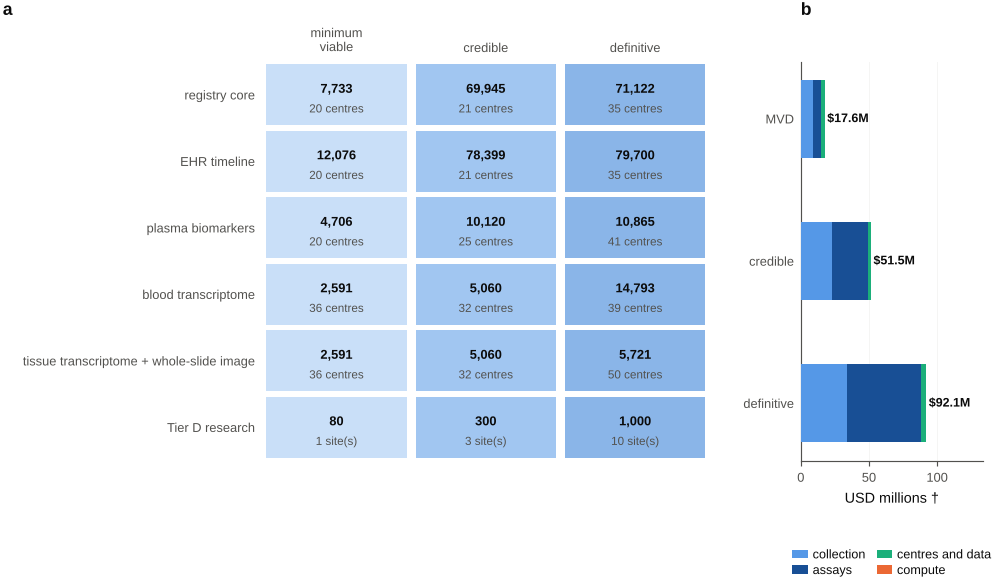

[saved] figures/Fig16_data_bill_of_materials.pdf  +  figures/Fig16_data_bill_of_materials.png


In [62]:
# ----------------------------------------------------------------------------- Figure 16: the data bill of materials
fig = plt.figure(figsize=(FULL, 3.9))
FW_, FH_ = FULL, 3.9
axa = fig.add_axes([1.95 / FW_, .50 / FH_, 3.20 / FW_, 2.85 / FH_]); axb = fig.add_axes([5.80 / FW_, .50 / FH_, 1.30 / FW_, 2.85 / FH_])
ax = axa                                                                        # (a) patients by layer and package
pk = [p for p, _ in PKG]; keys = [L['key'] for L in LAYERS]
CELLC = [PAL['seq'][0], PAL['seq'][1], PAL['seq'][2]]
for i, L in enumerate(LAYERS):
    for j, p_ in enumerate(pk):
        r_ = bom[(bom.key == L['key']) & (bom.package == p_)].iloc[0]
        ax.add_patch(plt.Rectangle((j + .03, i - .46), .94, .92, color=CELLC[j], alpha=.55, lw=0))
        t_ = ax.text(j + .5, i - .08, f'{r_.patients:,}', ha='center', va='center', fontsize=6.6, fontweight='bold', color=PAL['ink']); t_._ok_overlap = True
        t2 = ax.text(j + .5, i + .22, f'{int(r_.centres)} centres' if L['key'] != 'D' else f'{int(r_.centres)} site(s)', ha='center', va='center', fontsize=6.0, color=PAL['ink2']); t2._ok_overlap = True
ax.set_xlim(0, 3); ax.set_ylim(len(LAYERS) - .5, -.5); ax.set_yticks(range(len(LAYERS)))
ax.set_yticklabels([L['name'].split(' (')[0].replace(' at diagnosis and prodrome', '').replace(' at diagnosis', '').replace('registry core + outcomes', 'registry core').replace('plasma biomarkers, scheduled draws', 'plasma biomarkers').replace('TCR repertoire / single-cell / spatial', 'Tier D research') for L in LAYERS])
ax.tick_params(axis='y', length=0); ax.xaxis.tick_top(); ax.set_xticks([.5, 1.5, 2.5]); ax.set_xticklabels(['minimum\nviable', 'credible', 'definitive']); ax.tick_params(axis='x', length=0)
for sp in ax.spines.values(): sp.set_visible(False)
ax.annotate('a', (0, 1), xycoords='axes fraction', xytext=(-1.85 * 72, 24), textcoords='offset points', fontsize=9, fontweight='bold')
ax = axb; ygrid(ax, 'x')                                                         # (b) cost
parts = [('collection', PAL['seq'][1]), ('assays', PAL['seq'][3]), ('centres_and_data', PAL['aqua']), ('compute', PAL['orange'])]
left = np.zeros(3)
for nm, c in parts:
    v = np.array([cost.loc[p, nm] / 1e6 for p in pk]); ax.barh(range(3), v, left=left, color=c, height=.55, zorder=3, label=nm.replace('_', ' ')); left += v
for i, p_ in enumerate(pk): ax.text(left[i] + .02 * left.max(), i, f'${cost.loc[p_, "total"] / 1e6:.1f}M', va='center', fontsize=6.4, fontweight='bold')
ax.set_yticks(range(3)); ax.set_yticklabels(['MVD', 'credible', 'definitive']); ax.invert_yaxis(); ax.tick_params(axis='y', length=0); ax.set_xlim(0, left.max() * 1.45)
ax.set_xlabel('USD millions †'); ax.legend(loc='upper center', bbox_to_anchor=(.5, -.20), ncol=2, columnspacing=.9, handlelength=1.2, handletextpad=.4, labelspacing=.3)
ax.annotate('b', (0, 1), xycoords='axes fraction', xytext=(0, 24), textcoords='offset points', fontsize=9, fontweight='bold')
finish(fig, 16, 'data_bill_of_materials',
       "The data bill of materials. (a) Patients required in each data layer for three packages, with the number of centres at which the gate of section 8.12 has "
       "80% power; the packages differ in what they must demonstrate (a single honest test of the primary claim; several claims with a subgroup audit; a Level-3 claim "
       "with prospective validation) and in the between-centre heterogeneity planned for (tau = 0.02, 0.03, 0.04). (b) Programme cost by package, split into specimen "
       "collection and coordination, assays, centre set-up and data engineering, and compute; unit costs are planning figures. Compute is the smallest bar by orders of magnitude.")

---
# 10 · Pilot evidence: what the transcriptome-first attempt established

Before this specification we built and ran the opposite design: expression as the backbone, GvHD as the label, public data only. The full notebook is `GvHD_FM_benchmark_blueprint.ipynb` in this repository; its numbers are reproduced here as the empirical starting point of the present paper. Nine public studies, 838 samples after QC, three platforms, blood and tissue, patient-grouped splits throughout, with random-weight twins and confounder-only comparators.

| Finding (executed on public data) | Number | What it implies for ALLO-FM |
|---|---|---|
| Normalised genes + ridge head, leave-one-study-out over 7 studies | mean AUROC **0.684** | the baseline that any representation must beat |
| Split by sample type | tissue biopsy **0.804**, blood/sorted T cells **0.594** | ρ (shared structure) is high for tissue, low for blood → tissue adapters first (C7), blood transcriptome adapters later |
| Hallmark-50 pathway prior, under a gate fixed before the run | **0.589**, below genes (0.684) and below the shuffled-membership control (0.623 ± 0.033); all four gate criteria failed | a curated prior is not automatically a better small-n representation; the earlier 4-study advantage (0.695 vs 0.615) did not replicate |
| Frozen Geneformer 10M / 104M / 316M, 4 RNA-seq studies, LOSO | **0.498 / 0.678 / 0.615** vs genes **0.756**; 104M beat its random-weight twin by **+0.064** [+0.035, +0.104], 316M and 10M did not | pretraining contributed something at one scale, but **nothing beat the simple baseline**; scale did not help |
| Within-study, pretrained vs random-weight twin | better in **10 of 21** task × model pairs | at n ≈ 20–90 a high-dimensional random embedding is a lottery ticket; single-task comparisons are uninformative |
| Input compatibility | **5 of 9** studies (microarray or gene-restricted release) could not be embedded at all | a single-cell-counts foundation model cannot read most public GvHD data |
| Zero-parameter IFN-γ / allograft-rejection score, no fitting | skin and colon **0.80–0.88**; sorted PtCy T cells **below 0.5** | the model-free biology baseline is strong *in inflamed tissue*; it is the baseline for C7 |
| cfRNA, the only large public longitudinal set (92 patients) | pre-GvHD samples AUROC **0.32** [0.14, 0.48]; forecasting month 1 → month 2 barely beat the population mean | **no reproducible pre-onset signal** in public blood; prognosis needs protocolised collection (§4.4) |
| Label efficiency | tissue curve still rising at k = 256; blood flat at 0.52–0.59 whatever k | blood's problem was **domain shift, not sample count** — the ρ = 0 regime of Figure 2 (and, quantitatively, the plateau of Figure 13c) |
| Data quality | 4 of 54 skin libraries were empty, including 2 of 9 controls | QC audits belong in the harness, not in the appendix |

**Three design decisions follow directly.**
1. **Change the backbone.** The modality with high ρ and registry-scale n is the clinical timeline. Omics becomes an adapter with modality dropout, so a Tier A patient still gets a prediction (§5.1).
2. **Stop relying on retrospective public specimens for prognosis.** The sampling-time confound and the absence of onset dates make pre-onset tasks unanswerable on GEO. Hence the protocolised schedule (§4.4) and `t_known` discipline (§4.7).
3. **Keep the controls.** Random-weight twins, confounder-only models, shuffled-prior controls and pre-stated gates did their job: they turned an exciting four-study result into a correctly-reported replication failure. They are mandatory in GvHD-Bench (§8.3, §8.6).

**What the pilot does not show.** It does not show that transcriptomes are useless for GvHD — tissue biopsies transferred well, and the IFN-γ programme is real. It shows that *blood transcriptome alone, from heterogeneous public studies, at n ≈ 10²* cannot support a foundation-model claim.

[layout PASS] Fig 17: 65 text items, 0 collisions, 0 below 6 pt (smallest 6.4 pt)


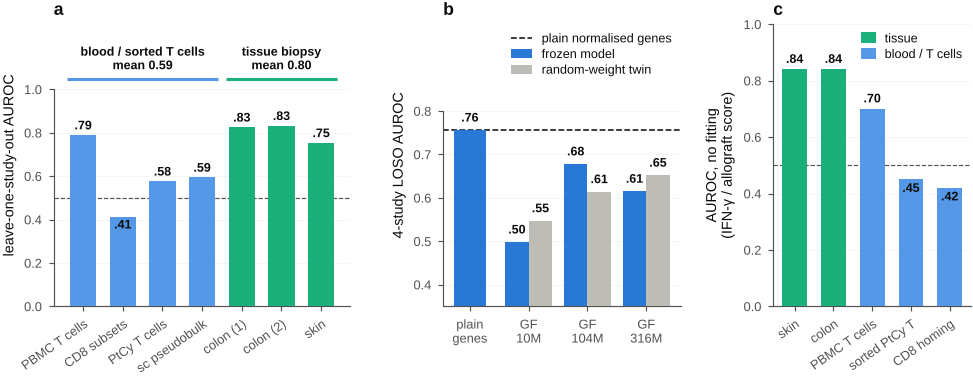

[saved] figures/Fig17_pilot_results.pdf  +  figures/Fig17_pilot_results.png


In [63]:
# ----------------------------------------------------------------------------- Figure 17: the pilot results that this paper is built on (numbers from the earlier notebook)
PILOT_LOSO = [('PBMC T cells', .790, 'blood'), ('CD8 subsets', .413, 'blood'), ('PtCy T cells', .577, 'blood'), ('sc pseudobulk', .595, 'blood'),
              ('colon (1)', .826, 'tissue'), ('colon (2)', .833, 'tissue'), ('skin', .754, 'tissue')]
FM_ARMS = [('plain\ngenes', .756, None), ('GF\n10M', .498, .547), ('GF\n104M', .678, .614), ('GF\n316M', .615, .652)]
ZP = [('skin', .84, 'tissue'), ('colon', .84, 'tissue'), ('PBMC T cells', .70, 'blood'), ('sorted PtCy T', .45, 'blood'), ('CD8 homing', .42, 'blood')]
TC, BC = PAL['aqua'], PAL['seq'][1]
fig = plt.figure(figsize=(FULL, 3.1))
gs = fig.add_gridspec(1, 3, width_ratios=[1.5, 1.2, 1.0], left=.075, right=.985, bottom=.235, top=.885, wspace=.38)
def vlab(ax, i, v, ref=.5, x=None, dx=0):
    """Value label above its bar; inside the bar if it would otherwise cross the chance line."""
    inside = ref - .09 <= v < ref
    t = ax.text((i if x is None else x) + dx, v - .012 if inside else v + .014, f'{v:.2f}'[1:] if v < 1 else f'{v:.2f}', ha='center',
                va='top' if inside else 'bottom', fontsize=6.4, fontweight='bold')
    if inside: t._ok_overlap = True
ax = fig.add_subplot(gs[0, 0]); ygrid(ax)                                           # (a) leave-one-study-out transfer
ax.bar(range(7), [v for _, v, _ in PILOT_LOSO], color=[TC if g == 'tissue' else BC for _, _, g in PILOT_LOSO], width=.66, zorder=3)
for i, (_, v, _) in enumerate(PILOT_LOSO): vlab(ax, i, v)
ax.axhline(.5, color=PAL['ink2'], ls='--', lw=.6)
m_b = np.mean([v for _, v, g in PILOT_LOSO if g == 'blood']); m_t = np.mean([v for _, v, g in PILOT_LOSO if g == 'tissue'])
for x0, x1, m, g, c in ((-.4, 3.4, m_b, 'blood / sorted T cells', BC), (3.6, 6.4, m_t, 'tissue biopsy', TC)):
    ax.plot([x0, x1], [1.05, 1.05], color=c, lw=1.6, solid_capstyle='butt')
    ax.annotate(f'{g}\nmean {m:.2f}', ((x0 + x1) / 2, 1.05), xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=6.4, fontweight='bold')
ax.set_xticks(range(7)); ax.set_xticklabels([n for n, _, _ in PILOT_LOSO], rotation=35, ha='right', rotation_mode='anchor')
ax.set_ylim(0, 1.0 + .30); ax.set_yticks([0, .2, .4, .6, .8, 1.0]); ax.spines['left'].set_bounds(0, 1.0)
ax.set_ylabel('leave-one-study-out AUROC'); panel(ax, 'a')
ax = fig.add_subplot(gs[0, 1]); ygrid(ax)                                           # (b) frozen foundation models against their random twins
x = np.arange(len(FM_ARMS)); w = .40
ax.bar([0], [FM_ARMS[0][1]], w * 1.35, color=PAL['seq'][2], zorder=3, label='frozen model')
ax.bar(x[1:] - w / 2, [a[1] for a in FM_ARMS[1:]], w, color=PAL['seq'][2], zorder=3)
ax.bar(x[1:] + w / 2, [a[2] for a in FM_ARMS[1:]], w, color=PAL['grey2'], zorder=3, label='random-weight twin')
ax.axhline(FM_ARMS[0][1], color=PAL['ink'], ls='--', lw=.8, label='plain normalised genes')
vlab(ax, 0, FM_ARMS[0][1], ref=9, x=0)
for xi, a in zip(x[1:], FM_ARMS[1:]):
    vlab(ax, 0, a[1], ref=9, x=xi - w / 2); vlab(ax, 0, a[2], ref=9, x=xi + w / 2)
ax.set_xticks(x); ax.set_xticklabels([a[0] for a in FM_ARMS]); ax.set_ylim(.35, 1.0); ax.set_yticks([.4, .5, .6, .7, .8])
ax.spines['left'].set_bounds(.35, .8); ax.set_ylabel('4-study LOSO AUROC'); ax.legend(loc='upper right', labelspacing=.3); panel(ax, 'b')
ax = fig.add_subplot(gs[0, 2]); ygrid(ax)                                           # (c) the zero-parameter score
ax.bar(range(5), [v for _, v, _ in ZP], color=[TC if g == 'tissue' else BC for _, _, g in ZP], width=.64, zorder=3)
for i, (_, v, _) in enumerate(ZP): vlab(ax, i, v)
ax.axhline(.5, color=PAL['ink2'], ls='--', lw=.6)
ax.set_xticks(range(5)); ax.set_xticklabels([n for n, _, _ in ZP], rotation=35, ha='right', rotation_mode='anchor')
ax.set_ylim(0, 1.0); ax.set_ylabel('AUROC, no fitting\n(IFN-γ / allograft score)'); panel(ax, 'c')
ax.legend([plt.Rectangle((0, 0), 1, 1, color=TC), plt.Rectangle((0, 0), 1, 1, color=BC)], ['tissue', 'blood / T cells'],
          loc='upper right', handlelength=1.0, labelspacing=.3)
finish(fig, 17, 'pilot_results',
       'The pilot this paper is built on (9 public studies, 838 samples; numbers from the earlier notebook in this repository). '
       '(a) Leave-one-study-out transfer with plain normalised genes: tissue biopsies transfer across laboratories and organs, blood '
       'and sorted T cells do not. (b) Frozen Geneformer (GF) at three sizes against its own random-weight twins and against plain '
       'genes: one size beats its twin, none beats the simple baseline, and the largest model is not the best. (c) A zero-parameter '
       'score written down in advance, the mean expression of the interferon-gamma and allograft-rejection gene sets, matches '
       'fitted models in inflamed tissue and fails in sorted blood T cells.')

---
# 11 · Roadmap, governance and ethics

## 11.0 Do we need a harness? Yes — and this is what it is

A benchmark is a claim about reproducibility, so it has to ship as software. Without a harness, every one of the leakage modes in §4.7 is re-litigated by every group, and no two results are comparable. The harness is small — this is tabular and sequence data, not a distributed training problem — and its job is to make the dangerous things impossible rather than merely discouraged.

**Seven components, in dependency order.**

| Component | Responsibility | Why it must be code, not a document |
|---|---|---|
| **1 · Ingest & schema** | map a site's OMOP + HCT-extension tables to the one event schema of §4.1, with units, coding systems, and both `t_valid` and `t_known` | the knowledge-time distinction is the single highest-yield leakage control, and it is lost the moment a human is asked to remember it |
| **2 · Label library** | the executable functions of §4.6 (MAGIC grade, steroid-refractory phenotype, NIH cGvHD, GRFS) with their unit tests | two centres implementing "grade II–IV by day 100" from prose will not agree |
| **3 · Cohort & landmark builder** | apply inclusion/exclusion, landmark eligibility, competing-event handling; emit the mandatory attrition table | attrition is where silent selection enters |
| **4 · Split manager** | construct, freeze, hash and verify the leave-centre-out / temporal / leave-registry-out assignments | a split that can be regenerated differently is not a split |
| **5 · Feature gate** | per-task admissibility: `t_known ≤ L`, banned treatment proxies, declared tier; refuses to emit an inadmissible matrix | the gate must be upstream of the model, so that leaking requires editing the harness rather than forgetting a rule |
| **6 · Metric & audit library** | IPCW time-dependent AUROC, Aalen–Johansen calibration, net benefit, patient-cluster bootstrap, BH adjustment, the leakage audit, the leakage canary | all implemented and validated in §8.6/§8.7 of this notebook |
| **7 · Baseline zoo & runner** | reference implementations of every mandatory comparator; runs submissions in a container; records version, hashes, seeds, ablations | "we compared to a logistic regression" is not a baseline; a pinned implementation is |

**Federated by construction.** Because the event schema is identical across sites, the harness runs in two modes: *pooled*, on a central extract under one data-use agreement, and *federated*, where each site runs ingest, labels, cohort, splits and metrics locally and only gradients or summary statistics leave. The federated mode is not an afterthought for v2 — it is how a 20-centre consortium becomes possible without a central patient-level repository, and the only component that changes is the runner.

**Engineering estimate.** Components 1–7 are of the order of **15–25k lines of Python** over a conventional stack: Polars or DuckDB for the event store, PyTorch for the model, a tokeniser of a few hundred lines, scikit-learn and XGBoost for the baseline zoo, and lifelines or scikit-survival cross-checked against the implementations here. The model is the small part. The metric, audit and split machinery of this notebook is already the seed of components 4 and 6.

## 11.1 Architecture decisions, stated once

| Decision | Choice | Why, and what would change it |
|---|---|---|
| Backbone input | **the day-0-anchored clinical event timeline** | it is the only modality with registry-scale n and high cross-centre shared structure (§2.1, §10); if a prospective study showed blood transcriptomes transferring across centres at ρ ≳ 0.8, an omics-first backbone would become defensible |
| Sequence model | decoder-style transformer with explicit continuous-time encoding; **not** a fixed-grid RNN | visit times are irregular and clinically meaningful; a fixed grid discards exactly the information that distinguishes day +7 from day +14 |
| Size | **50–150 M parameters** | compute-optimal at the realistic corpus (§7.2); larger is data-limited and unfalsifiable at this n |
| Pretraining objectives | next-event + time-to-event + masked-value (O-T1/T2/T3) | the time-to-event objective is the closest to every downstream question, and is the one with published label-efficiency gains ✓ |
| Omics | **adapters with modality dropout**, one summary token each, optional at inference | a model that requires single-cell data for every patient is untrainable and undeployable this decade |
| Heads | one **multi-state** head over cause-specific hazards | keeps the tasks mutually consistent; prevents a model claiming 40 % aGvHD risk and 90 % GvHD-free survival at once |
| Centre invariance | gradient-reversal / CORAL penalty, tuned against the two-axis score, **not** against downstream AUROC | tuning invariance on the test question is circular; the two-axis score (biology kept, centre discarded) is measurable without labels |
| Calibration | isotonic or Platt recalibration **per deployment site**, re-fit on local data | calibration, not discrimination, is what transfers worst between centres, and it is the part that changes clinical decisions |

## 11.2 Staged plan with go / no-go gates
| Stage | Work | Data needed | Go / no-go |
|---|---|---|---|
| **0 · Specification** | This document: data dictionary, label functions, task registry, metrics, gate, harness (all exported to `spec/`) | none | Done when the notebook runs end-to-end and the exported files validate |
| **1 · One-centre Tier A+B** | Build the OMOP + HCT-extension extract for one large centre (10³–10⁴ transplants); implement O-T1/O-T2/O-T3; run tasks A1–A5, B1–B6, C1–C5 with leave-era-out | single-centre IRB | Proceed only if the timeline model reaches **Level 1** against tuned trees on registry variables. **Also measure the three quantities the plan rests on**: the between-centre SD τ of the gain (sets the centre count, §9.6), the shared fraction ρ of the signal (sets the plateau, §9.4) and label reliability κ (§9.7) |
| **2 · Multi-centre Tier A** | CIBMTR (and/or EBMT) extract; pretrain at scale; leave-centre-out and leave-registry-out; run the scaling ablation | registry study proposal + DUA | Proceed only if **Level 2** is reached on the primary task B1, with the random-weight twin and no-pretraining arms both beaten |
| **3 · Tier C adapters** | MAGIC / BMT CTN biorepository: biomarker, flow and microbiome adapters; tier-ablation task G4 | consortium collaboration | Proceed if an adapter adds ≥ 0.02 AUROC over Tier A+B at the same n, out of centre. Package size: the **minimum-viable** row of the data bill (§9.8) |
| **4 · Tier D and mechanism** | Repertoire, single-cell, pathology adapters on nested sub-cohorts; tasks C7, F1–F3 | prospective protocol (§4.4), with the nested weekly trajectory cohort of §9.5 | Research output regardless; no deployment claim |
| **5 · Prospective silent mode** | Model runs without influencing care; calibration drift monitored; subgroup audit | prospective approval | Level 3 only if calibration and net benefit hold prospectively |
| **6 · Interventional trial** | Randomise the *decision* (e.g. model-guided pre-emptive therapy vs standard) | trial | Only this licenses "improves outcomes" |

**Publish the negative.** If stage 1 or 2 fails its gate, the result is a paper: *"a clinical foundation model does not beat tuned registry baselines for GvHD prediction, at this scale, under these splits."* That is the output our pilot produced in the transcriptomic setting, and it was worth reporting.

## 11.3 What makes this fail (pre-mortem)
1. **Registry labels are too coarse.** If only maximum aGvHD grade is recorded, landmark tasks B1–B4 collapse. *Mitigation*: the daily-staging requirement in D13/D23; use centres with day-level data for the early-warning task.
2. **Centre practice is the real signal.** Prophylaxis platform, biopsy habits and steroid thresholds differ, so a model can learn the centre. *Mitigation*: confounder-only comparator, leave-centre-out as default, centre-adversarial objective, and the equity audit G3.
3. **Pretraining adds nothing over gradient-boosted trees.** Tabular registry data is where trees are strongest. *Mitigation*: the gate measures exactly this; Level 1 is about *label efficiency*, which is where sequence pretraining has the best published case.
4. **Omics adapters never become available at scale.** *Mitigation*: Tier A/B must stand alone; adapters are optional by construction.
5. **Temporal drift.** Practice changed (letermovir, PtCy for matched donors, ruxolitinib, belumosudil, axatilimab). A model trained on the old era may be useless. *Mitigation*: temporal split is mandatory (G1), era is an explicit feature, and recalibration is part of the deployment plan.

## 11.4 Governance, ethics and reporting
* **Consent and access.** Registry and repository use runs through study proposals, DUAs and GA4GH DUO-coded consent. Nothing in this specification requires re-identifiable data to leave its custodian: the model can be trained federated-first, since the event schema is identical across sites.
* **Equity.** Donor availability differs by genetic ancestry, which means both the exposure (donor type) and the outcome distribution differ by group. A model that is accurate on average and poorly calibrated for under-served groups would worsen the existing disparity. Task G3 is therefore mandatory, not optional, and worst-subgroup calibration is a reported primary quantity.
* **Paediatrics.** Thresholds (stool volume per kg), scores (Lansky) and biology (thymic output) differ. Paediatric patients are a reported subgroup, never a pooled afterthought.
* **Reporting standards.** TRIPOD+AI for the prediction model, with a data card per source, a model card stating the pretraining corpus and required preprocessing, frozen split files, seeds, and a published negative-results table. CONSORT-AI / SPIRIT-AI apply at stage 6.
* **Clinical framing.** The model's outputs are risks, not diagnoses. GvHD diagnosis remains clinical and histological; the intended use of a Level-3 model is to *prioritise* investigation, pre-emptive therapy trials and monitoring intensity.

---
# 12 · Limitations

1. **Nothing here is trained.** This is a specification with executed statistics and simulations, not a model. Figures 2, 8, 9 and 10 and the learning-curve, longitudinal and gate calculations of §9 rest on **[SIM]** or on stated closed-form models: their effect sizes and assumptions are ours, chosen to exercise the machinery, and they say nothing about patients.
2. **The clinical-timeline premise is itself untested for GvHD.** Label efficiency from EHR foundation models is published for other endpoints (✓ for MOTOR's reported numbers), not for GvHD. Stage 1 exists to test it, and may refute it.
3. **The data dictionary is a target, not an inventory.** No single existing cohort holds all 25 domains. The tier structure is the honest statement of what is available where.
4. **Some definitions are from domain knowledge (†)** and must be checked line-by-line against the primary consensus documents before submission: the MAGIC grade table, the 2018 steroid-refractoriness criteria, NIH 2014 organ scoring, refined DRI, HCT-CI weights, the DPB1 TCE algorithm, and the EBMT SOS criteria. The *code* in §4.6 is the authoritative version of what this benchmark means by each label, and it is testable; if it disagrees with the consensus table, the consensus table wins and the code must change.
5. **Prevalences in the registry are planning assumptions**, so every "minimum n" moves with the real prevalence of the cohort.
6. **Competing-risk discrimination is still contested.** IPCW time-dependent AUROC depends on a correct censoring model; informative censoring (transfer of care, which correlates with outcome) will bias it. We report Brier/IBS and calibration alongside, and the censoring model is part of the audit.
7. **Simulation cannot validate the premises.** Figure 2 shows *that* pretraining depends on shared structure; only real multi-centre data can show *whether* GvHD data has it.
8. **The sample-size calculators are models, with stated assumptions.** The learning curve of §9.4 assumes a linear head, an equal-covariance binormal signal and a retained-signal fraction κ that is an assumption until tasks F2/G4 measure it; the paired-power and validation sizes assume equal-variance binormal scores; the longitudinal results assume a prodrome length and a single-draw reliability that are properties of each assay, to be measured with bridging and replicate samples. Each was checked against simulation where the model is exact and stress-tested where it is not, but none was checked against real GvHD data, because that data does not yet exist.
9. **The three quantities that set the plan are unmeasured**: the between-centre SD τ of the gain, the cross-centre shared fraction ρ, and label reliability. We plan at τ = 0.02/0.03/0.04 and ρ = 0.8, and stage 1 measures them; if they are worse, §9.4, §9.6 and §9.8 give the revised requirement.
10. **Unit costs, subgroup shares and onset-time distribution are planning assumptions (†).** The cost of the data bill is an order of magnitude, shown with a ×0.5/×2 range, not a budget.

---
# 13 · Conclusion

A foundation model for GvHD is plausible, but not in the form we first tried. The transcriptome-first attempt failed on public data for understandable reasons: too few labelled patients per study, no shared structure across studies for blood, no onset dates, and input formats the model could not read. The clinical timeline of allo-HCT is the opposite: anchored at day 0, densely sampled, protocolised, recorded with the same forms in every centre, and available for hundreds of thousands of patients. That is where a foundation model has something to learn from.

What such a model needs is not a new architecture. It needs a **data specification** precise enough that two centres produce the same variable (§4), **objectives** that each come with a control (§6), and a **benchmark** whose tasks are the real decisions, whose baselines are what clinicians use today, whose splits are leave-centre-out and temporal, and whose gates were written before the run (§8). The sample-size calculus (§9) says plainly that only consortium-scale data can settle the question, and the pilot (§10) says plainly what happens when you try to settle it with less.

If the gates are passed, the result is a model that can be taken to a prospective evaluation. If they are not, the result is a negative finding reported at a useful level of detail. Both outcomes are publishable; only one of them is currently assumed.

In [64]:
# ----------------------------------------------------------------------------- export GvHD-Bench as a standalone specification document
def _bench_md():
    """Assemble spec/GVHD_BENCH_v1.0.md from the same objects the notebook computed (never hand-typed)."""
    L = ['# GvHD-Bench v1.0 — benchmark specification', '',
         f'Generated by `ALLO_FM_GvHD_foundation_model.ipynb` on {time.strftime("%Y-%m-%d", time.gmtime())}. '
         'This file is self-contained: it is the normative definition of the benchmark. '
         'Section numbers refer to the notebook.', '',
         '## 1 Scope and governance', '',
         '- Unit of analysis: the patient (donor-recipient pair where both contribute data).',
         '- Clock: days relative to first graft infusion (day 0).',
         '- Admissibility: an event is readable at landmark L only if `t_known <= L`.',
         '- Label authority: the executable functions in notebook 4.6; a consensus document always wins over the code.',
         '- Versioning: patch = label/metric bug fix; minor = new task or baseline; major = changed split, cohort or gate.',
         '  Results are comparable only within a major version.', '',
         '## 2 Cohort', '',
         '**Included**: first allogeneic HCT, any indication, donor type, graft source or conditioning intensity;',
         'recorded day 0; at least one contact after day +7.', '',
         '**Excluded**: autologous/syngeneic; second and later transplants (new pair_id, analysed separately);',
         'consent withdrawn; records with missing or inconsistent day 0 or outcome dates (counted, never silently dropped).', '',
         '**Landmark eligibility (per task)**: alive, in follow-up, and outcome-free at L. Patients who died, relapsed',
         'or were censored before L are excluded from that task and appear in its attrition table.', '',
         '**Competing events**: death and relapse are events, not censoring, for every GvHD endpoint.', '',
         '## 3 Tasks', '',
         f'{len(reg_full)} tasks in {reg_full.family.nunique()} families. '
         f"Powered at accessible n: {(reg_full.verdict == 'POWERED').sum()}; "
         f"under-powered: {(reg_full.verdict == 'UNDER-POWERED').sum()}; "
         f"not single-AUROC tasks: {(reg_full.verdict == '-').sum()}.", '',
         'Full machine-readable definitions: `task_registry.csv` (all fields) and `task_cards.csv`',
         '(readiness, accessible n, requirements, verdict). Columns are documented in notebook 8.3-8.4.', '']
    for fam in reg_full.family.unique():
        L.append(f'### Family {fam}'); L.append('')
        for _, r in reg_full[reg_full.family == fam].iterrows():
            L += [f'**{r.id} — {r.task}**', '',
                  f'- landmark: {r.landmark} · horizon: {r.horizon}',
                  f'- inputs allowed: tiers {r["inputs allowed (tiers)"]} · outcome: {r["outcome (label fn)"]}',
                  f'- competing events: {r["competing events"]}',
                  f'- primary metric: {r["primary metric"]}',
                  f'- must beat: {r["clinical baseline to beat"]}',
                  f'- split protocol: {r["split protocol"]}',
                  f'- readiness: {r.readiness} · tier needed: {r["tier needed"]}',
                  f'- assumed prevalence: {r["assumed prevalence"]} · target AUROC: {r["target AUROC"]}'
                  f' · achievable (notebook 3.2): {r["achievable AUROC"] or "n/a"}',
                  f'- n accessible (est.): {r["n accessible (est.)"]:,} · n to develop (50-param): '
                  f'{r["n to develop (50-param)"]} · n to show +0.03: {r["n to show +0.03"]}',
                  f'- **verdict: {r.verdict}**', '']
    L += ['## 4 Metrics', '',
          '- Discrimination: IPCW cumulative/dynamic time-dependent AUROC at the horizon, competing events excluded',
          '  from the control set. Implementation and validation: notebook 8.6.',
          '- Calibration: observed Aalen-Johansen cumulative incidence by predicted-risk decile; slope and intercept.',
          '- Utility: decision-curve net benefit over thresholds 0.10-0.40.',
          '- Uncertainty: patient-cluster bootstrap; paired DeLong for model-vs-baseline; Benjamini-Hochberg within a family.',
          '- Reported per held-out centre, never as a pooled number alone.', '',
          '## 5 Required baselines (every task, same table as the model)', '']
    for b in GATE['baselines_to_beat']: L.append(f'- {b}')
    L += ['- confounder-only model (centre, era, assay batch, pre-analytics, sampling day)',
          '- treatment-proxy-only model, run deliberately as a leakage canary',
          '- presence-only model (whether and when each lab/drug/assay was recorded, no values); the audit warns if it beats chance by > 0.02',
          '- permuted-outcome and negative-exposure controls (task G7): the false-pass rate of the whole pipeline', '',
          '## 6 Splits', '',
          '- leave-centre-out (default), temporal (mandatory for deployment claims), leave-registry-out (hardest).',
          '- Patients never span folds; donors never span folds; centres are never split.',
          '- Assignments frozen, hashed and published; the harness refuses a run whose split hash does not match.',
          '- Three-way data split: development / validation / evaluation, with evaluation labels withheld.', '',
          '## 7 Submission rules', '',
          '- At most five scored submissions per team per major version, each with a written changelog.',
          '- Every submission declares data tier, pretraining corpus, parameter count, frozen vs fine-tuned.',
          '- Fine-tuned entries report >= 5 seeds and the spread.',
          '- The mandatory ablations (random-weight twin, no-pretraining, objective removal, modality knockout,',
          '  tier ablation, corpus scaling) are submitted with the model; an entry without them cannot make a Level 2 claim.',
          '- Code and a model card are deposited; the model card states the preprocessing a deployment site must reproduce.', '',
          '## 8 Claim ladder', '']
    for lvl, txt in (('0', 'nothing'),
                     ('1', 'more label-efficient than a tuned simple model (equal at full labels, better at k <= 100, beats its random-weight twin)'),
                     ('2', 'better out-of-centre discrimination (>= 20 held-out centres; centre-level 95% t-interval of the paired AUROC difference has a lower bound >= +0.01 against the best simple model AND the clinical baseline; improves in >= 70% of held-out centres; survives BH; beats random-weight twin and no-pretraining)'),
                     ('3', 'clinically useful (Level 2 plus calibration slope 0.8-1.25, positive net benefit 10-40%, leave-centre-out AND temporal validation, n >= the Riley minimum, prospective silent-mode evaluation)'),
                     ('4', 'improves outcomes — requires a prospective trial of the model-guided decision; nothing less licenses the word')):
        L.append(f'- **Level {lvl}**: {txt}')
    L += ['', '## 9 Pre-registered gate for the v1 attempt', '', '```json', json.dumps(GATE, indent=2), '```', '',
          'Operating characteristics of this gate (notebook 8.12): the centre-level t-interval keeps its 95% coverage at every number of centres, whereas a percentile bootstrap over centres does not;',
          f'at 20 centres of ~300 patients and a between-centre SD of 0.02 the gate passes a true gain of +0.03 with probability {g20(.03, "pass_adopted"):.2f} and a true gain of +0.01 with probability {g20(.01, "pass_adopted"):.2f}.', '',
          '## 10 Benchmark-validity requirements', '',
          '- **Issue day**: a prediction is issued on the landmark day and may use a specimen only once its result exists (draw day + assay turnaround).',
          '- **Label reliability**: at least 10% of outcomes double-read; kappa >= 0.8, else the attenuation of notebook 9.7 is applied to every required n.',
          '- **Subgroups (G3)**: a subgroup is assessed only with the events notebook 9.7 requires (about 1,000 patients for an equal-opportunity gap of 0.10); otherwise it is reported as not assessable.',
          '- **Drift (G1)**: report observed/expected incidence per calendar year and the recalibration plan.',
          '- **Utility**: report trial-size saving under enrichment and alerts per 100 patient-days alongside AUROC (notebook 8.13).',
          '- **Target-trial emulation (G6)**: reproduce the BMT CTN 1703 GRFS effect (HR 0.64, 95% CI 0.49-0.83) from registry data.', '',
          '## 11 Required artefacts for a published result', '',
          '- benchmark version and artefact hashes; attrition table; per-task primary metric with CI; per-centre values;',
          '- calibration slope and intercept; net benefit 10-40%; all mandatory baselines; the ablation suite;',
          '- the leakage audit output; the seed list; and the negative-results table of what did not beat its baseline.', '']
    return '\n'.join(L)

bench_path = os.path.join(SPEC_DIR, 'GVHD_BENCH_v1.0.md')
open(bench_path, 'w').write(_bench_md())
print(f'wrote {bench_path}  ({os.path.getsize(bench_path)/1024:.0f} kB, {len(open(bench_path).read().splitlines())} lines)')
print(open(bench_path).read()[:700] + '\n   [...]')

wrote spec/GVHD_BENCH_v1.0.md  (32 kB, 673 lines)
# GvHD-Bench v1.0 — benchmark specification

Generated by `ALLO_FM_GvHD_foundation_model.ipynb` on 2026-10-26. This file is self-contained: it is the normative definition of the benchmark. Section numbers refer to the notebook.

## 1 Scope and governance

- Unit of analysis: the patient (donor-recipient pair where both contribute data).
- Clock: days relative to first graft infusion (day 0).
- Admissibility: an event is readable at landmark L only if `t_known <= L`.
- Label authority: the executable functions in notebook 4.6; a consensus document always wins over the code.
- Versioning: patch = label/metric bug fix; minor = new task or baseline; major = changed split, cohort or gate.
  Resul
   [...]


In [65]:
# ----------------------------------------------------------------------------- figure manifest (every figure, its caption and its files)
figman = pd.DataFrame([dict(figure=k, slug=v['slug'],
                            files=' · '.join(os.path.basename(f) for f in v['files']),
                            caption=v['caption']) for k, v in FIGS.items()])
figman.to_csv(os.path.join(FIGDIR, 'FIGURES.csv'), index=False)
with open(os.path.join(FIGDIR, 'FIGURES.md'), 'w') as fh:
    fh.write('# Figures\n\nVector PDF and 600-dpi PNG of each figure in the paper.\n\n')
    for k, v in FIGS.items():
        fh.write(f"## {k} — {v['slug']}\n\n{v['caption']}\n\nFiles: " +
                 ', '.join(f'`{os.path.basename(f)}`' for f in v['files']) + '\n\n')
sizes = {k: sum(os.path.getsize(f) for f in v['files']) // 1024 for k, v in FIGS.items()}
print(f'{len(FIGS)} figures written to {os.path.abspath(FIGDIR)} (PDF + PNG each)')
display(md_table(figman[['figure', 'slug', 'files']]))

17 figures written to /home/user/benchmark-paper/figures (PDF + PNG each)


| figure | slug | files |
|---|---|---|
| Fig 1 | decision_timeline | Fig01_decision_timeline.pdf · Fig01_decision_timeline.png |
| Fig 2 | pretraining_vs_shared_structure | Fig02_pretraining_vs_shared_structure.pdf · Fig02_pretraining_vs_shared_structure.png |
| Fig 3 | predictability_ceiling | Fig03_predictability_ceiling.pdf · Fig03_predictability_ceiling.png |
| Fig 4 | architecture | Fig04_architecture.pdf · Fig04_architecture.png |
| Fig 5 | knowledge_time_and_time_encoding | Fig05_knowledge_time_and_time_encoding.pdf · Fig05_knowledge_time_and_time_encoding.png |
| Fig 6 | training_requirements | Fig06_training_requirements.pdf · Fig06_training_requirements.png |
| Fig 7 | gvhd_bench_structure | Fig07_gvhd_bench_structure.pdf · Fig07_gvhd_bench_structure.png |
| Fig 8 | harness_task_B1 | Fig08_harness_task_B1.pdf · Fig08_harness_task_B1.png |
| Fig 9 | benchmark_self_validation | Fig09_benchmark_self_validation.pdf · Fig09_benchmark_self_validation.png |
| Fig 10 | clinical_translation | Fig10_clinical_translation.pdf · Fig10_clinical_translation.png |
| Fig 11 | sample_size_and_power | Fig11_sample_size_and_power.pdf · Fig11_sample_size_and_power.png |
| Fig 12 | data_landscape_and_accrual | Fig12_data_landscape_and_accrual.pdf · Fig12_data_landscape_and_accrual.png |
| Fig 13 | transcriptome_requirements | Fig13_transcriptome_requirements.pdf · Fig13_transcriptome_requirements.png |
| Fig 14 | longitudinal_design | Fig14_longitudinal_design.pdf · Fig14_longitudinal_design.png |
| Fig 15 | centres_validation_subgroups | Fig15_centres_validation_subgroups.pdf · Fig15_centres_validation_subgroups.png |
| Fig 16 | data_bill_of_materials | Fig16_data_bill_of_materials.pdf · Fig16_data_bill_of_materials.png |
| Fig 17 | pilot_results | Fig17_pilot_results.pdf · Fig17_pilot_results.png |

In [66]:
# ----------------------------------------------------------------------------- export the data requirements as a standalone document + CSVs
T = lambda df, **kw: md_table(df, **kw).data
def _req_md():
    q = bom[bom.package == 'minimum viable']
    L = ['# Data requirements for ALLO-FM and GvHD-Bench v1.0', '',
         f'Generated by `ALLO_FM_GvHD_foundation_model.ipynb` on {time.strftime("%Y-%m-%d", time.gmtime())}. Every number below is computed in the notebook (section 9); '
         'items marked † are planning assumptions (unit costs, subgroup shares, onset-time distribution, retained-signal fraction kappa).', '',
         '## 1 Headline requirements', '',
         f'- **Paired comparison**: showing a gain of +0.03 AUROC over a correlated baseline needs about {n80(.03, .85):,} patients (score correlation 0.85; {n80(.03, .6):,} at 0.60).',
         f'- **Development**: a 768-parameter head at AUROC 0.72 and prevalence 0.35 needs {riley_n(768, .72, .35)["n"]:,} patients (Riley); a 50-parameter head {riley_n(50, .72, .35)["n"]:,}.',
         f'- **Transcriptome at diagnosis**: a whole-transcriptome head needs {min(n_whole, n_whole75):,.0f}-{max(n_whole, n_whole75):,.0f} labelled profiles to come within 0.02 AUROC of its ceiling; a 64-d adapter embedding retaining 90% of the signal needs {min(n_adapt, n_adapt75):,.0f}-{max(n_adapt, n_adapt75):,.0f}.',
         f'- **Centres**: {K_required(.03, .02, 300)} centres of ~300 patients give the gate 80% power for a +0.03 gain at between-centre SD 0.02; {K_required(.03, .04, 300)} at 0.04.',
         f'- **Longitudinal**: with single-draw reliability 0.5, {k_needed(.80, .5, .02)} draws per window recover the oracle AUROC to within 0.02; sampling interval must be well under the prodrome length (every 2-3.5 days for a 10-day prodrome).',
         f'- **Validation (Level 3)**: {vtab[(vtab.AUROC == .75) & (vtab.prevalence == .15)].patients.iloc[0]:,} patients ({vtab[(vtab.AUROC == .75) & (vtab.prevalence == .15)].events.iloc[0]:,} events) at AUROC 0.75 and prevalence 0.15.',
         f'- **Compute**: the whole training programme is about {fmt_h(PROG_H)} on one A100 ({fmt_usd(PROG_H * USD_PER_H)}); data collection and assays cost orders of magnitude more.', '',
         '## 2 The transcriptome at diagnosis', '', T(plan), '', T(txt_disp), '',
         '## 3 Longitudinal design', '', T(kn), '', T(prod), '', T(disp_sched), '',
         '## 4 Centres', '', T(ktab), '', T(dex), '',
         '## 5 Validation, subgroups and label noise', '', T(vtab[['AUROC', 'prevalence', 'patients', 'events', 'binding criterion']]), '', T(sg_disp), '', T(ltab), '',
         '## 6 The data bill of materials', '', T(show[['layer', 'package', 'patients', 'centres', 'specimens per patient', 'specimens', 'storage_TB', 'assays + collection (USD)', 'binding']]), '', T(cd, index=True), '',
         '## 7 Assumptions (†)', '',
         '- Unit costs (USD): ' + ', '.join(f'{k} {v:,}' for k, v in UNIT.items()) + '.',
         '- Usable fraction of prospective patients: 70%; large-centre volume 200 transplants a year; 20-centre consortium 3,000 a year.',
         '- Onset of grade II-IV aGvHD: log-normal, median day 28; pre-onset window 14 days; subgroup shares as listed in section 5.',
         '- Retained-signal fraction of an adapter embedding kappa = 0.9 (to be measured by tasks F2 and G4); nuisance-structure multiplier on the effective dimension of a raw-gene head measured by the stress test of section 9.4.']
    return '\n'.join(L)
bench_req_path = os.path.join(SPEC_DIR, 'DATA_REQUIREMENTS_v1.0.md')
open(bench_req_path, 'w').write(_req_md())
bom.to_csv(os.path.join(SPEC_DIR, 'data_requirements.csv'), index=False)
cost.to_csv(os.path.join(SPEC_DIR, 'programme_cost.csv'))
print(f'wrote {bench_req_path} ({os.path.getsize(bench_req_path) / 1024:.0f} kB) and data_requirements.csv, programme_cost.csv')

wrote spec/DATA_REQUIREMENTS_v1.0.md (11 kB) and data_requirements.csv, programme_cost.csv


In [67]:
# ----------------------------------------------------------------------------- export the specification bundle and verify it
manifest = {}
for f, desc in [('data_dictionary.csv', f'{len(dd)} data elements in {dd.domain.nunique()} domains'),
                ('sampling_schedule.csv', f'{len(sched)} specimen types x {len(SCHED_DAYS)} visits'),
                ('task_registry.csv', f'{len(reg_full)} benchmark tasks, full fields'),
                ('task_cards.csv', 'readiness, accessible n, requirements, powered verdict'),
                ('GVHD_BENCH_v1.0.md', 'standalone benchmark specification'),
                ('gate.json', 'pre-stated gate for the ALLO-FM v1 attempt'),
                ('DATA_REQUIREMENTS_v1.0.md', 'standalone data-requirement specification: what to collect, how much, how often'),
                ('data_requirements.csv', f'{len(bom)} rows: layer x package, patients, centres, specimens, cost'),
                ('programme_cost.csv', 'programme cost by package')]:
    p = os.path.join(SPEC_DIR, f); manifest[f] = dict(description=desc, bytes=os.path.getsize(p),
        sha256=hashlib.sha256(open(p, 'rb').read()).hexdigest()[:16])
json.dump(manifest, open(os.path.join(SPEC_DIR, 'MANIFEST.json'), 'w'), indent=2)
display(md_table(pd.DataFrame(manifest).T.reset_index().rename(columns={'index': 'file'})))

# ----------------------------------------------------------------------------- consistency check: every number quoted in the abstract/summary must match what was computed
checks = [
 ('data elements in the dictionary', len(dd), 129, 0),
 ('domains in the dictionary', dd.domain.nunique(), 25, 0),
 ('elements required for ALLO-FM v1', int((dd.priority == 'R').sum()), 74, 0),
 ('benchmark tasks', len(reg_full), 40, 0),
 ('figures written (PDF + PNG each)', len(FIGS), 17, 0),
 ('tokens per patient, Tier A+B', tok_by_tier['B'], 7580, 100),
 ('task families', reg.family.nunique(), 7, 0),
 ('Riley n, P=768, AUROC .72, prev .35', riley_n(768, .72, .35)['n'], 47662, 2000),
 ('tasks: powered', int((cards_df.verdict == 'POWERED').sum()), 15, 0), ('tasks: under-powered', int((cards_df.verdict == 'UNDER-POWERED').sum()), 11, 0),
 ('tasks: not a single-AUROC task', int((cards_df.verdict == '-').sum()), 14, 0),
 ('compute-optimal parameters, 100k patients Tier A+B (M)', N_opt / 1e6, 38, 2),
 ('one pretraining run (A100-hours)', gpu_opt, 3.2, .8), ('whole programme (A100-hours)', PROG_H, 95, 20),
 ('orders of magnitude below a 7B language model', OOM_VS_LLM, 3.4, .4),
 ('patients to show +0.03, score correlation 0.85', n80(.03, .85), 840, 80), ('patients to show +0.03, score correlation 0.60', n80(.03, .6), 2100, 250),
 ('whole-transcriptome head, ceiling 0.88 (thousands of profiles)', n_whole / 1e3, 390, 60), ('whole-transcriptome head, ceiling 0.75 (millions)', n_whole75 / 1e6, 1.0, .15),
 ('64-d adapter head, ceiling 0.88 (profiles)', n_adapt, 680, 60), ('64-d adapter head, ceiling 0.75 (profiles)', n_adapt75, 1700, 150),
 ('day-7 blood transcriptome +0.02, 8 centres (profiles)', b1['n for +0.02 (ρ = 0.8, K = 8)'], 3450, 400), ('... realisable gain at rho 0.8', b1['realisable gain (ρ = 0.8, K = 8)'], .029, .005),
 ('draws per window to come within 0.02 (reliability 0.5)', k_needed(.80, .5, .02), 6, 0), ('nested weekly cohort for 300 evaluable cases (patients)', DENSE_N, 1271, 150),
 ('centres for 80 % power, tau 0.02 (closed form)', K_required(.03, .02, 300), 17, 2), ('centres for 80 % power, tau 0.04 (closed form)', K_required(.03, .04, 300), 40, 6),
 ('adopted gate: power at +0.03, K = 20', g20(.03, 'pass_adopted'), .85, .08), ('adopted gate: false pass at +0.01, K = 20', g20(.01, 'pass_adopted'), .02, .04),
 ('obvious gate: pass probability at its own threshold', g20(.03, 'pass_obvious'), .5, .1),
 ('percentile-bootstrap coverage at K = 20', cb(20, 'cov_boot'), .926, .03), ('t-interval coverage, worst over K', oc.cov_t.min(), .945, .03),
 ('static-model observed/expected in the last drift year', drift_df.OE_static.iloc[-1], .69, .12),
 ('Level-3 validation patients, AUROC 0.75, prevalence 0.15', vtab[(vtab.AUROC == .75) & (vtab.prevalence == .15)].patients.iloc[0], 1117, 120),
 ('patients per subgroup for a 0.10 sensitivity gap', n_gap_pat[.10], 1012, 100), ('label noise (kappa 0.78): n inflation', ltab[ltab['kappa vs truth'] == .78]['n to show it vs noise-free n'].iloc[0], 1.87, .25),
 ('data bill, minimum viable (USD millions)', cost.loc['minimum viable', 'total'] / 1e6, 18, 5), ('data bill, credible (USD millions)', cost.loc['credible', 'total'] / 1e6, 51, 12),
 ('data bill, definitive (USD millions)', cost.loc['definitive', 'total'] / 1e6, 92, 20),
]
directional = [
 ('[SIM] S1: pretraining does NOT help when nothing is shared (rho=0, k=25)',
  s1.loc[(0.0, 'pretrained'), 25] - s1.loc[(0.0, 'raw'), 25], 'gain <= +0.02',
  s1.loc[(0.0, 'pretrained'), 25] - s1.loc[(0.0, 'raw'), 25] <= .02),
 ('[SIM] S1: pretraining helps at few labels when structure is shared (rho=1, k=25)',
  s1.loc[(1.0, 'pretrained'), 25] - s1.loc[(1.0, 'raw'), 25], 'gain >= +0.03',
  s1.loc[(1.0, 'pretrained'), 25] - s1.loc[(1.0, 'raw'), 25] >= .03),
 ('[SIM] S1: the advantage shrinks as labels accumulate (rho=1, k=400)',
  s1.loc[(1.0, 'pretrained'), 400] - s1.loc[(1.0, 'raw'), 400], 'gain at k=400 < gain at k=25',
  (s1.loc[(1.0, 'pretrained'), 400] - s1.loc[(1.0, 'raw'), 400]) < (s1.loc[(1.0, 'pretrained'), 25] - s1.loc[(1.0, 'raw'), 25])),
 ('[SIM] harness: the planted leak is clearly visible',
  summ.loc['LEAKING pipeline (adds steroid order d+5)', 'mean_ipcw_auroc'] - summ.loc['full (clinical + day-7 + biomarkers)', 'mean_ipcw_auroc'],
  'inflation >= +0.05', (summ.loc['LEAKING pipeline (adds steroid order d+5)', 'mean_ipcw_auroc']
                         - summ.loc['full (clinical + day-7 + biomarkers)', 'mean_ipcw_auroc']) >= .05),
 ('[SIM] harness: confounder-only model is near chance',
  summ.loc['confounder-only (centre + era)', 'mean_ipcw_auroc'], 'within 0.10 of 0.5',
  abs(summ.loc['confounder-only (centre + era)', 'mean_ipcw_auroc'] - .5) <= .10),
]
cc = pd.DataFrame([dict(quantity=q, computed=round(float(v), 3), expected=e, ok=abs(float(v) - e) <= tol) for q, v, e, tol in checks]
                  + [dict(quantity=q, computed=round(float(v), 3), expected=e, ok=bool(o)) for q, v, e, o in directional])
display(md_table(cc))
assert cc.ok.all(), cc[~cc.ok]
print(f'all {len(cc)} consistency checks passed')
print(f"MAGIC label vignettes: {len(tt)} passed | steroid/GRFS vignettes: {len(lt)} passed | metric validations: {len(val)} passed")

| file | description | bytes | sha256 |
|---|---|---|---|
| data_dictionary.csv | 129 data elements in 25 domains | 28567 | 12b357578143bc6a |
| sampling_schedule.csv | 11 specimen types x 13 visits | 838 | 395de56cb863cc2a |
| task_registry.csv | 40 benchmark tasks, full fields | 12541 | da0daaffe58e5d94 |
| task_cards.csv | readiness, accessible n, requirements, powered verdict | 2805 | 95b48100b11735e3 |
| GVHD_BENCH_v1.0.md | standalone benchmark specification | 32501 | 6d01f2450fc04479 |
| gate.json | pre-stated gate for the ALLO-FM v1 attempt | 1552 | 8daa2d82ea1fe044 |
| DATA_REQUIREMENTS_v1.0.md | standalone data-requirement specification: what to collect, how much, how often | 10991 | b9ef6e6282722b24 |
| data_requirements.csv | 18 rows: layer x package, patients, centres, specimens, cost | 2901 | fe4f343ce665c10e |
| programme_cost.csv | programme cost by package | 291 | 1a93c2d45952cd57 |

| quantity | computed | expected | ok |
|---|---|---|---|
| data elements in the dictionary | 129.0 | 129 | True |
| domains in the dictionary | 25.0 | 25 | True |
| elements required for ALLO-FM v1 | 74.0 | 74 | True |
| benchmark tasks | 40.0 | 40 | True |
| figures written (PDF + PNG each) | 17.0 | 17 | True |
| tokens per patient, Tier A+B | 7580.0 | 7580 | True |
| task families | 7.0 | 7 | True |
| Riley n, P=768, AUROC .72, prev .35 | 47662.0 | 47662 | True |
| tasks: powered | 15.0 | 15 | True |
| tasks: under-powered | 11.0 | 11 | True |
| tasks: not a single-AUROC task | 14.0 | 14 | True |
| compute-optimal parameters, 100k patients Tier A+B (M) | 37.9 | 38 | True |
| one pretraining run (A100-hours) | 3.193 | 3.2 | True |
| whole programme (A100-hours) | 95.315 | 95 | True |
| orders of magnitude below a 7B language model | 3.418 | 3.4 | True |
| patients to show +0.03, score correlation 0.85 | 836.0 | 840 | True |
| patients to show +0.03, score correlation 0.60 | 2125.0 | 2100 | True |
| whole-transcriptome head, ceiling 0.88 (thousands of profiles) | 387.913 | 390 | True |
| whole-transcriptome head, ceiling 0.75 (millions) | 1.019 | 1.0 | True |
| 64-d adapter head, ceiling 0.88 (profiles) | 678.284 | 680 | True |
| 64-d adapter head, ceiling 0.75 (profiles) | 1697.563 | 1700 | True |
| day-7 blood transcriptome +0.02, 8 centres (profiles) | 3450.165 | 3450 | True |
| ... realisable gain at rho 0.8 | 0.029 | 0.029 | True |
| draws per window to come within 0.02 (reliability 0.5) | 6.0 | 6 | True |
| nested weekly cohort for 300 evaluable cases (patients) | 1271.0 | 1271 | True |
| centres for 80 % power, tau 0.02 (closed form) | 17.0 | 17 | True |
| centres for 80 % power, tau 0.04 (closed form) | 40.0 | 40 | True |
| adopted gate: power at +0.03, K = 20 | 0.85 | 0.85 | True |
| adopted gate: false pass at +0.01, K = 20 | 0.025 | 0.02 | True |
| obvious gate: pass probability at its own threshold | 0.506 | 0.5 | True |
| percentile-bootstrap coverage at K = 20 | 0.926 | 0.926 | True |
| t-interval coverage, worst over K | 0.942 | 0.945 | True |
| static-model observed/expected in the last drift year | 0.687 | 0.69 | True |
| Level-3 validation patients, AUROC 0.75, prevalence 0.15 | 1117.0 | 1117 | True |
| patients per subgroup for a 0.10 sensitivity gap | 1012.0 | 1012 | True |
| label noise (kappa 0.78): n inflation | 1.87 | 1.87 | True |
| data bill, minimum viable (USD millions) | 17.564 | 18 | True |
| data bill, credible (USD millions) | 51.463 | 51 | True |
| data bill, definitive (USD millions) | 92.07 | 92 | True |
| [SIM] S1: pretraining does NOT help when nothing is shared (rho=0, k=25) | -0.076 | gain <= +0.02 | True |
| [SIM] S1: pretraining helps at few labels when structure is shared (rho=1, k=25) | 0.064 | gain >= +0.03 | True |
| [SIM] S1: the advantage shrinks as labels accumulate (rho=1, k=400) | -0.004 | gain at k=400 < gain at k=25 | True |
| [SIM] harness: the planted leak is clearly visible | 0.202 | inflation >= +0.05 | True |
| [SIM] harness: confounder-only model is near chance | 0.505 | within 0.10 of 0.5 | True |

all 44 consistency checks passed
MAGIC label vignettes: 14 passed | steroid/GRFS vignettes: 8 passed | metric validations: 5 passed


---
## References

✓ = checked against a source during this project. † = from domain knowledge; verify against the primary document before submission.

**Clinical foundation models and sequence models over health records**
1. Steinberg E, Fries J, Wornow M, Shah N, et al. **MOTOR: a time-to-event foundation model for structured medical records.** ICLR 2024; arXiv:2301.03150. Pretrained on up to 55 M patient records / 9 B events; 19 tasks across 3 databases; reported +4.6 % time-dependent C and up to 95 % better label efficiency; 143 M-parameter model released. ✓
2. Steinberg E, et al. **Language models are an effective representation learning technique for electronic health record data** (CLMBR). *J Biomed Inform* 2021. †
3. Wornow M, et al. **EHRSHOT: an EHR benchmark for few-shot evaluation of foundation models.** NeurIPS Datasets & Benchmarks 2023; arXiv:2307.02028. ✓
4. Shmatko A, et al. **Delphi-2M: generative modelling of disease trajectories.** *Nature* 2025. †
5. Kraljevic Z, et al. **Foresight — generative pretrained transformer for modelling of patient timelines.** *Lancet Digit Health* 2024. †
6. Harutyunyan H, et al. **Multitask learning and benchmarking with clinical time series data.** *Sci Data* 6:96 (2019). ✓

**Audits of omics foundation models (the reason for this paper's control structure)**
7. Kedzierska KZ, Crawford L, Amini AP, Lu AX. **Zero-shot evaluation reveals limitations of single-cell foundation models.** *Genome Biol* 2025. doi:10.1186/s13059-025-03574-x ✓
8. Boiarsky R, et al. **Deeper evaluation of a single-cell foundation model.** *Nat Mach Intell* 2024. ✓
9. Ahlmann-Eltze C, Huber W, Anders S. **Deep-learning-based gene perturbation effect prediction does not yet outperform simple linear baselines.** *Nat Methods* 22:1657–1661 (2025). ✓
10. **Evaluating the role of pretraining dataset size and diversity on single-cell foundation model performance.** bioRxiv 2024.12.13.628448; *Nat Methods* 2026. ✓
11. Theodoris CV, et al. **Transfer learning enables predictions in network biology** (Geneformer). *Nature* 618:616–624 (2023). ✓
12. Cui H, et al. **scGPT.** *Nat Methods* 2024. ✓ · Hao M, et al. **scFoundation.** *Nat Methods* 2024. ✓ · Rosen Y, et al. **Universal Cell Embeddings.** bioRxiv 2023. ✓ · Gélard A, et al. **BulkRNABert.** PMLR 259 (ML4H 2025). ✓
13. Luecken MD, et al. **Benchmarking atlas-level data integration in single-cell genomics** (scIB). *Nat Methods* 19:41–50 (2022). ✓

**GvHD: grading, biomarkers, prophylaxis and biology**
14. Harris AC, Young R, Devine S, et al. **International, multicenter standardization of acute graft-versus-host disease clinical data collection** (MAGIC criteria). *Biol Blood Marrow Transplant* 22:4–10 (2016). ✓ (criteria exist; the staging table in §4.6 is implemented from the standard formulation †)
15. Levine JE, et al. **A prognostic score for acute GvHD based on biomarkers** (Ann Arbor). *Lancet Haematol* 2:e21–e29 (2015). ✓
16. **Day-7 two-biomarker (ST2 + REG3α) MAGIC algorithm, 1,287 patients.** *JCI Insight* 2017; article 89798. ✓
17. Bolaños-Meade J, et al. **Post-transplantation cyclophosphamide-based GvHD prophylaxis** (BMT CTN 1703; n = 431; 1-y GRFS 52.7 % vs 34.9 %). *N Engl J Med* 388:2338–2348 (2023). ✓
18. Jagasia MH, et al. **NIH consensus development project on criteria for clinical trials in chronic GvHD: I. Diagnosis and staging** (NIH 2014). *Biol Blood Marrow Transplant* 21:389–401 (2015). †
19. Schoemans HM, et al. **EBMT–NIH–CIBMTR task force position statement on standardized terminology and guidance for GvHD assessment.** *Bone Marrow Transplant* 53:1401–1415 (2018). †
20. Holtan SG, et al. **Composite end point of graft-versus-host disease-free, relapse-free survival** (GRFS). *Blood* 125:1333–1338 (2015). †
21. Sorror ML, et al. **Hematopoietic cell transplantation (HCT)-specific comorbidity index.** *Blood* 106:2912–2919 (2005). † · Armand P, et al. **Validation and refinement of the Disease Risk Index.** *Blood* 123:3664–3671 (2014). †
22. Fleischhauer K, et al. **Effect of T-cell-epitope matching at HLA-DPB1.** *Lancet Oncol* 13:366–374 (2012). † · Petersdorf EW, et al. **HLA-B leader and outcome.** *Blood* / *NEJM* series. † · Petersdorf EW, et al. **HLA-C expression level.** † 
23. Peled JU, et al. **Microbiota as predictor of mortality in allogeneic hematopoietic-cell transplantation.** *N Engl J Med* 382:822–834 (2020). 1,362 patients, 8,767 stool samples, 4 centres. ✓
24. Liao C, et al. **Compilation of longitudinal microbiota data and hospitalome from hematopoietic cell transplantation patients.** *Sci Data* 8:71 (2021). >10,000 stool samples from >1,000 patients; public. ✓
25. Zeiser R, Blazar BR. **Acute graft-versus-host disease — biologic process, prevention, and therapy.** *N Engl J Med* 377:2167–2179 (2017). † (the three-step model used in §4.3)
26. Frick M, et al. **Role of donor clonal hematopoiesis in allogeneic HCT.** *J Clin Oncol* 2019. † · Gibson CJ, et al. † 
27. Admiraal R, et al. **Population pharmacokinetic modeling of anti-thymocyte globulin.** *Lancet Haematol* 2015. †

**Registries, repositories and methods**
28. **CIBMTR Research Database.** >470,000 HSC transplant recipients from >500 centres in 48 countries (2017 NIH funding notice); 2025 annual report: 18,000+ collected and derived variables, 148 downloadable final datasets. ✓
29. **EBMT Registry** and Transplant Complications Working Party. †
30. Collins GS, et al. **TRIPOD+AI statement.** *BMJ* 385:e078378 (2024). ✓ · Wolff RF, et al. **PROBAST.** *Ann Intern Med* 2019. †
31. Riley RD, et al. **Calculating the sample size required for developing a clinical prediction model.** *BMJ* 368:m441 (2020); `pmsampsize`. ✓ (criteria 2–3 as implemented here: †)
32. Hanley JA, McNeil BJ. *Radiology* 143:29–36 (1982). † · DeLong ER, et al. *Biometrics* 44:837–845 (1988). † · Sun X, Xu W. *IEEE Signal Process Lett* 21:1389–1393 (2014). †
33. Blanche P, Dartigues J-F, Jacqmin-Gadda H. **Estimating and comparing time-dependent areas under ROC curves for censored event times with competing risks.** *Stat Med* 32:5381–5397 (2013). †
34. Vickers AJ, Elkin EB. **Decision curve analysis.** *Med Decis Making* 26:565–574 (2006). †
35. Austin PC, Fine JP. **Practical recommendations for reporting Fine-Gray model analyses for competing risk data.** *Stat Med* 2017. †
36. **AIRR Community (MiAIRR) standards** for repertoire data. † · **OMOP CDM** and the Oncology extension (OHDSI). † · **GA4GH Data Use Ontology.** †
37. Raudys S, Duin RPW. **Expected classification error of the Fisher linear classifier with pseudo-inverse covariance matrix.** *Pattern Recognit Lett* 19:385–392 (1998). † (the finite-sample learning curve of a plug-in linear classifier used in §9.4)
38. Riley RD, Debray TPA, Collins GS, et al. **Minimum sample size for external validation of a clinical prediction model with a binary outcome.** *Stat Med* 40:4230–4251 (2021). † (the calibration-slope and O/E precision targets of §9.7)
39. Hoffmann J, et al. **Training compute-optimal large language models.** arXiv:2203.15556 (2022). † (≈ 20 tokens per parameter) · Muennighoff N, et al. **Scaling data-constrained language models.** *NeurIPS* 2023. † (repeating data up to ≈ 4 epochs)
40. Spearman C. *Br J Psychol* 3:271–295 (1910) and Brown W. *Br J Psychol* 3:296–322 (1910). † (reliability of an average of *k* measurements, §9.5)
41. Hernán MA, Robins JM. **Using big data to emulate a target trial when a randomized trial is not available.** *Am J Epidemiol* 183:758–764 (2016). † (task G6)
42. Agniel D, Kohane IS, Weber GM. **Biases in electronic health record data due to processes within the healthcare system: retrospective observational study.** *BMJ* 361:k1479 (2018). † (when and whether a test is ordered carries information about the patient; the mechanism behind the presence-only comparator of §8.12)

---
## Appendix A — Reproducibility

* **Runtime.** CPU only. Dependencies: numpy, pandas, scipy, scikit-learn, matplotlib. End-to-end run ≈ 6–10 minutes on a laptop CPU; set the environment variable `ALLOFM_QUICK=1` to cut simulation replicates (numbers get noisier, the harness uses 8 held-out centres so the Level-2 gate reports *not evaluable*, and the consistency tolerances still apply).
* **Seeds.** Global seed in the setup cell; every simulation takes an explicit seed. The [SIM] cohort generator is `simulate_cohort(...)` and is deterministic given its seed.
* **Exported specification** (written to `spec/`, hashes in `spec/MANIFEST.json`): `data_dictionary.csv`, `sampling_schedule.csv`, `task_registry.csv`, `task_cards.csv`, `GVHD_BENCH_v1.0.md`, `gate.json`, and the data-requirement bundle `DATA_REQUIREMENTS_v1.0.md`, `data_requirements.csv`, `programme_cost.csv`.
* **Figure layout gate.** Every figure is measured before it is saved: the build fails if any two pieces of rendered text overlap, if text sits on a data marker, line or bar, or if any font is below 6 pt (set `ALLOFM_STRICT_FIGS=1` to make a failure stop the run; otherwise it is printed as a warning). The whole suite passes under both Liberation Sans and the wider DejaVu Sans that Colab falls back to (`ALLOFM_FONT="DejaVu Sans"`).
* **Tests executed in-notebook.** MAGIC grading vignettes; steroid-response and GRFS vignettes; fast-vs-textbook DeLong agreement; Hanley–McNeil versus simulated standard error; IPCW td-AUROC against the uncensored AUROC; IPCW recovery under censoring; Aalen–Johansen against empirical incidence; net-benefit bounds for perfect and random models; Riley criterion-1 arithmetic; the leakage audit on a cohort with a planted leak; closed-form paired power against a Monte-Carlo DeLong test; the transcriptome learning-curve formula against simulated heads, with a stress test; Spearman–Brown against simulation; closed-form gate power against the gate simulation; calibration-slope Fisher information against simulation; the label-noise attenuation formula against simulation; interval coverage and gate operating characteristics; planted-effect recovery, a permuted-outcome control and an informative-presence test through the real harness; and a final consistency check of every number quoted in the narrative.
* **What is *not* in this notebook.** Any trained foundation model, any real patient data, and any claim about clinical performance. The pilot results in §10 come from the executed notebook `GvHD_FM_benchmark_blueprint.ipynb` in this repository.

## Appendix B — How to use this specification
1. **To build a cohort:** take `spec/data_dictionary.csv` as the extraction checklist; implement `t_valid` / `t_known` for every element; implement the §4.6 label functions; run the §8.7 audit before any modelling.
2. **To run the benchmark:** take `spec/task_registry.csv`; for each task fix the landmark (the *issue* day), horizon and competing events as given; use the §8.6 metrics; report every mandatory baseline from §8.5 in the same table, including the presence-only and permuted-outcome controls.
3. **To make a claim:** check it against the ladder in §8.10 and against `spec/gate.json`, whose hash should be reported with the results.
4. **To plan a data collection:** read `spec/DATA_REQUIREMENTS_v1.0.md` for the package that matches the claim (minimum viable, credible, definitive), replace the planning values (τ, ρ, κ, unit costs) with measured ones as stage 1 produces them, and re-run §9.